# 1. Band power across all sessions (all channels, all bands)
Per session (CMR, kept trials, all channels): Morlet power for 6 bands (delta, theta, alpha, beta, low γ, high γ).
Saved per session: (a) log10 mean power per trial × channel in 5 windows (pre-press, early hold, hold, pre-release,
post-release); (b) time courses per condition (0.5 blocks) relative to each trial's own pre-press, only while on the lever.
From these files: M1 = band during the hold vs pre-press and vs post-release (correct long);
M2 = correct long vs early long (hold > 0.3 s) before the release and in the early hold. Session = unit;
sign-flip test across sessions, per rat and all rats. Windows and bands fixed from the pilot/lab hypothesis.

In [39]:
# ── 1.0 setup ──
import os, sys, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spikeinterface.full as si
import spikeinterface.preprocessing as spre

MAIN    = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
TABLES  = os.path.join(MAIN, "tables")
PROJECT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC"
BP_DIR  = os.path.join(PROJECT, "data", "analysis_main", "band_power_v1")      # one file per session
os.makedirs(BP_DIR, exist_ok=True)
sys.path.insert(0, MAIN)
import importlib, lfp_main as lfm; importlib.reload(lfm)

AT = pd.read_csv(os.path.join(TABLES, "all_trials.csv"))
for c in ("session", "keep", "long_prob", "outcome", "type", "press_neural_s", "release_neural_s"):
    assert c in AT.columns, f"all_trials.csv has no column '{c}'"
AT = AT[AT["keep"].astype(bool)].copy()
SESSIONS = sorted(AT["session"].unique())
XB = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
print(f"{len(SESSIONS)} sessions, {len(AT)} kept trials | extra bad channels listed for: "
      f"{sorted(XB['session'].unique()) if len(XB) else 'none'}")

def find_rec(session):
    hits = (glob.glob(os.path.join(PROJECT, "*", session)) + glob.glob(os.path.join(PROJECT, "*", "*", session)))
    hits = [os.path.join(h, "amir_data", "down_sampled", "1000_Hz") for h in hits]
    hits = [h for h in hits if os.path.isdir(h)]
    assert len(hits) == 1, f"{session}: {len(hits)} recording folders found {hits}"
    return hits[0]

def load_cmr(session):
    rec = si.load(find_rec(session))
    bad = XB.loc[XB["session"] == session, "channel_id"].tolist() if len(XB) else []
    if bad:
        rec = rec.remove_channels(bad)
    return spre.common_reference(rec, reference="global", operator="median"), bad

def session_trials(session):
    t = AT[AT["session"] == session]
    return pd.DataFrame({"trial": t["trial"].values if "trial" in t else np.arange(len(t)),
                         "outcome": t["outcome"].values, "type": t["type"].values,
                         "long_prob": t["long_prob"].values,
                         "press_s": t["press_neural_s"].values, "release_s": t["release_neural_s"].values})

62 sessions, 8360 kept trials | extra bad channels listed for: ['20260520_r0000135_wt_1357', '20260521_r0000135_wt_1309', '20260522_r0000135_wt_1716', '20260523_r0000135_wt_1320', '20260524_r0000135_wt_1944', '20260525_r0000135_wt_1426', '20260526_r0000135_wt_1411', '20260527_r0000135_wt_1217', '20260528_r0000135_wt_1825', '20260529_r0000135_wt_1411', '20260602_r0000135_wt_1715', '20260603_r0000135_wt_1641', '20260609_r0000134_wt_1622', '20260609_r0000135_wt_1644', '20260610_r0000134_wt_1923', '20260610_r0000135_wt_2313', '20260611_r0000134_wt_1309', '20260611_r0000135_wt_1415', '20260612_r0000134_wt_1447', '20260612_r0000135_wt_1444', '20260615_r0000134_wt_1825', '20260615_r0000135_wt_1902', '20260616_r0000134_wt_1653', '20260616_r0000135_wt_1742', '20260617_r0000134_wt_1914', '20260617_r0000135_wt_1944', '20260620_r0000134_wt_1512', '20260620_r0000134_wt_1554', '20260620_r0000135_wt_1627', '20260621_r0000135_wt_1618', '20260622_r0000134_wt_1513', '20260622_r0000135_wt_1426', '2026062

## 1.1 TEST ON ONE SESSION FIRST (timing + sanity) ──


In [ ]:
TEST_SESSION = "20260529_r0000136_wt_1318"
rec, bad = load_cmr(TEST_SESSION)
trs = session_trials(TEST_SESSION)
print(f"{TEST_SESSION}: {rec.get_num_channels()} channels (extra bad removed: {bad}) | {len(trs)} kept trials")
t0 = time.time()
r = lfm.process_session(rec, trs, os.path.join(BP_DIR, TEST_SESSION + ".pkl"), mem_bytes=2e9)
print(f"done in {(time.time() - t0) / 60:.1f} min | trials used {r['meta']['n_trials']}")
# sanity vs pilot 5b: theta hold vs pre, correct long, 0.5 blocks (pilot CMR: median +31 % for theta 4-7)
T = r["trials"]; cl = ((T.outcome == "correct") & (T.type == "long") & (T.long_prob == 0.5)).values
for b in lfm.MAIN_BANDS:
    lp = r["logpow"][b]
    d = (lp["hold"][cl] - lp["pre"][cl]).mean(axis=0)                 # per channel, mean over trials
    print(f"  {b:13s} hold vs pre: median over channels {100 * (10 ** np.median(d) - 1):+.1f} %")

20260529_r0000136_wt_1318: 383 channels (extra bad removed: []) | 142 kept trials
    channels 0-62 of 383 done (43 s)
    channels 63-125 of 383 done (77 s)
    channels 126-188 of 383 done (111 s)
    channels 189-251 of 383 done (145 s)
    channels 252-314 of 383 done (179 s)
    channels 315-377 of 383 done (213 s)
    channels 378-382 of 383 done (216 s)
done in 3.6 min | trials used 142
  delta 1-3     hold vs pre: median over channels +5.1 %
  theta 4-7     hold vs pre: median over channels +30.7 %
  alpha 8-12    hold vs pre: median over channels +18.5 %
  beta 13-29    hold vs pre: median over channels +4.3 %
  lowG 30-60    hold vs pre: median over channels +3.9 %
  highG 61-100  hold vs pre: median over channels -3.7 %


## 1.2 ALL SESSIONS (leave it running; finished sessions are skipped, errors are logged) ──


In [ ]:
log = []
for k, s in enumerate(SESSIONS, 1):
    out = os.path.join(BP_DIR, s + ".pkl")
    if os.path.exists(out):
        continue
    t0 = time.time()
    try:
        rec, bad = load_cmr(s)
        lfm.process_session(rec, session_trials(s), out, mem_bytes=2e9, verbose=False)
        log.append({"session": s, "status": "ok", "minutes": round((time.time() - t0) / 60, 1)})
    except Exception as e:
        log.append({"session": s, "status": f"ERROR: {e!r}", "minutes": round((time.time() - t0) / 60, 1)})
    print(f"{k}/{len(SESSIONS)} {s}: {log[-1]['status']} ({log[-1]['minutes']} min)", flush=True)
    pd.DataFrame(log).to_csv(os.path.join(BP_DIR, "_run_log.csv"), index=False)
print("all done:", len(glob.glob(os.path.join(BP_DIR, "*.pkl"))), "session files")

1/62 20260510_r0000135_wt_1625: ok (1.8 min)
2/62 20260510_r0000136_wt_1926: ok (3.9 min)
3/62 20260511_r0000136_wt_0909: ok (0.8 min)
4/62 20260511_r0000136_wt_0930: ok (2.0 min)
5/62 20260511_r0000136_wt_1832: ok (2.2 min)
6/62 20260512_r0000136_wt_1054: ok (0.3 min)
7/62 20260513_r0000136_wt_1729: ok (1.0 min)
8/62 20260514_r0000136_wt_1317: ok (0.8 min)
9/62 20260515_r0000135_wt_1953: ok (5.5 min)
10/62 20260515_r0000135_wt_1957: ok (1.8 min)
11/62 20260515_r0000136_wt_1817: ok (3.1 min)
12/62 20260517_r0000135_wt_1846: ok (1.1 min)
13/62 20260517_r0000136_wt_1557: ok (4.4 min)
14/62 20260519_r0000136_wt_2031: ok (3.5 min)
15/62 20260520_r0000135_wt_1357: ok (3.0 min)
16/62 20260520_r0000136_wt_1443: ok (3.0 min)
17/62 20260521_r0000135_wt_1309: ok (4.5 min)
18/62 20260522_r0000135_wt_1716: ok (6.8 min)
19/62 20260522_r0000136_wt_1750: ok (4.7 min)
20/62 20260523_r0000135_wt_1320: ok (2.5 min)
21/62 20260523_r0000136_wt_1320: ok (3.3 min)
22/62 20260524_r0000135_wt_1944: ok (6.7 mi

## 1.3 load all session files (WT-manipulation sessions of rat 134 excluded) ──


In [40]:
import pickle
BP = {}
for f in sorted(glob.glob(os.path.join(BP_DIR, "*.pkl"))):
    with open(f, "rb") as fh:
        BP[os.path.basename(f)[:-4]] = pickle.load(fh)
rat_of = lambda s: s.split("_")[1][-3:]                                  # "r0000136" -> "136"

AT_all = pd.read_csv(os.path.join(TABLES, "all_trials.csv"))
WTM = set(AT_all.loc[AT_all["wt_manip_session"].astype(bool), "session"])
BP = {s: r for s, r in BP.items() if s not in WTM}
print("excluded WT-manipulation sessions:", sorted(WTM))
print(len(BP), "sessions loaded | per rat:", pd.Series([rat_of(s) for s in BP]).value_counts().to_dict())

excluded WT-manipulation sessions: ['20260623_r0000134_wt_1232', '20260624_r0000134_wt_1323', '20260625_r0000134_wt_1820']
59 sessions loaded | per rat: {'135': 29, '136': 19, '134': 11}


## 1.4 statistics: M1 (hold vs pre / post, correct long) and M2 (correct long vs early long) ──


In [44]:
MIN_CL, MIN_EL = 10, 5
rows = []
for s, r in BP.items():
    T, lp = r["trials"], r["logpow"]
    b05 = T["long_prob"] == 0.5
    cl = (b05 & (T.outcome == "correct") & (T.type == "long")).values
    el = (b05 & (T.outcome == "early") & (T.type == "long") & (T.hold_s > 0.3)).values
    for b in lfm.MAIN_BANDS:
        L = lp[b]
        row = {"session": s, "rat": rat_of(s), "band": b, "n_cl": int(cl.sum()), "n_el": int(el.sum())}
        if cl.sum() >= MIN_CL:
            row["M1 hold-pre"] = float(np.median((L["hold"][cl] - L["pre"][cl]).mean(0)))
            row["M1 hold-post"] = float(np.median((L["hold"][cl] - L["post"][cl]).mean(0)))
        if cl.sum() >= MIN_CL and el.sum() >= MIN_EL:
            for w in ("pre_release", "hold_early"):
                dC = (L[w][cl] - L["pre"][cl]).mean(0)
                dE = (L[w][el] - L["pre"][el]).mean(0)
                row[f"M2 {w} correct-early"] = float(np.median(dC - dE))
        rows.append(row)
S = pd.DataFrame(rows)
S.to_csv(os.path.join(BP_DIR, "_session_values.csv"), index=False)

stat = []
for meas in [c for c in S.columns if c.startswith("M")]:
    for b in lfm.MAIN_BANDS:
        for rat in ["all"] + sorted(S["rat"].unique()):
            v = S[(S.band == b) & ((S.rat == rat) if rat != "all" else True)][meas].dropna()
            m, p, n = lfm.sign_flip_p(v.values)
            stat.append({"measure": meas, "band": b, "rat": rat, "n_sessions": n,
                         "sessions > 0": int((v > 0).sum()), "mean %": round(100 * (10 ** m - 1), 1) if n else np.nan,
                         "p (sign-flip)": round(p, 4) if n >= 2 else np.nan})
ST = pd.DataFrame(stat)
ST.to_csv(os.path.join(BP_DIR, "_stats.csv"), index=False)
pd.set_option("display.width", 250)
for meas, d in ST.groupby("measure", sort=False):
    print(f"\n===== {meas} =====")
    print(d.pivot(index="band", columns="rat", values=["mean %", "p (sign-flip)", "n_sessions"]).to_string())


===== M1 hold-pre =====
             mean %                   p (sign-flip)                         n_sessions                 
rat             134   135   136   all           134     135     136     all        134   135  136   all
band                                                                                                   
alpha 8-12     17.7  14.3  15.0  15.1        0.0652  0.0012  0.0048  0.0001        5.0  14.0  9.0  28.0
beta 13-29      9.8  19.4   6.8  13.5        0.0652  0.0002  0.0048  0.0001        5.0  14.0  9.0  28.0
delta 1-3      47.0  10.8   0.1  12.8        0.0652  0.0474  0.9963  0.0059        5.0  14.0  9.0  28.0
highG 61-100   -3.6 -10.1  -0.6  -6.0        0.2479  0.0005  0.5743  0.0003        5.0  14.0  9.0  28.0
lowG 30-60      3.9   4.1   0.9   3.0        0.1910  0.0012  0.2485  0.0003        5.0  14.0  9.0  28.0
theta 4-7      33.9  34.5  18.8  29.1        0.0652  0.0002  0.0048  0.0001        5.0  14.0  9.0  28.0

===== M1 hold-post =====
             

In [47]:
print(S.shape, S["band"].unique(), S["rat"].unique())

(354, 9) <StringArray>
['delta 1-3', 'theta 4-7', 'alpha 8-12', 'beta 13-29', 'lowG 30-60', 'highG 61-100']
Length: 6, dtype: str <StringArray>
['135', '136', '134']
Length: 3, dtype: str


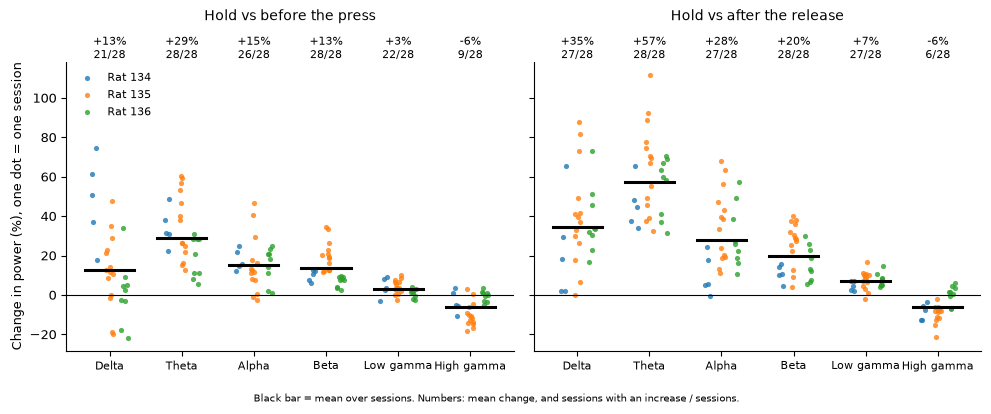

saved on C:\Users\ar687\Desktop
     measure         band  sessions  sessions_up  mean_pct
 M1 hold-pre    delta 1-3        28           21     12.81
 M1 hold-pre    theta 4-7        28           28     29.14
 M1 hold-pre   alpha 8-12        28           26     15.10
 M1 hold-pre   beta 13-29        28           28     13.49
 M1 hold-pre   lowG 30-60        28           22      3.01
 M1 hold-pre highG 61-100        28            9     -5.97
M1 hold-post    delta 1-3        28           27     34.54
M1 hold-post    theta 4-7        28           28     57.34
M1 hold-post   alpha 8-12        28           27     27.86
M1 hold-post   beta 13-29        28           28     19.82
M1 hold-post   lowG 30-60        28           27      6.99
M1 hold-post highG 61-100        28            6     -6.36


In [50]:
# ── Slide: which bands change while the rat holds the lever? (M1, correct long) — one dot = one session, no tests ──
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
BANDS_M1 = list(lfm.MAIN_BANDS)
LAB = {"delta 1-3": "Delta", "theta 4-7": "Theta", "alpha 8-12": "Alpha",
       "beta 13-29": "Beta", "lowG 30-60": "Low gamma", "highG 61-100": "High gamma"}
RCOL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
PAN = [("M1 hold-pre", "Hold vs before the press"), ("M1 hold-post", "Hold vs after the release")]
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
rng = np.random.default_rng(0); out = []
for ax, (col, title) in zip(axes, PAN):
    for i, b in enumerate(BANDS_M1):
        d = S[(S.band == b)].dropna(subset=[col])
        for k, rat in enumerate(sorted(RCOL)):
            dr = d[d.rat == rat]
            ax.scatter(i + (k - 1) * 0.2 + rng.uniform(-0.05, 0.05, len(dr)), 100 * (10 ** dr[col] - 1), s=14, color=RCOL[rat], alpha=0.8, linewidths=0,
                       label=f"Rat {rat}" if (i == 0 and col == "M1 hold-pre") else None)
        n = len(d); m = float(d[col].mean()); up = int((d[col] > 0).sum())      # mean over sessions of the log values
        ax.plot([i - 0.34, i + 0.34], [100 * (10 ** m - 1)] * 2, color="k", lw=2.2, zorder=4)
        ax.text(i, 1.0, f"{100 * (10 ** m - 1):+.0f}%\n{up}/{n}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
        out.append(dict(measure=col, band=b, sessions=n, sessions_up=up, mean_pct=100 * (10 ** m - 1)))
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(BANDS_M1))); ax.set_xticklabels([LAB.get(b, b) for b in BANDS_M1], fontsize=8)
    ax.set_title(title, fontsize=10, pad=30); ax.set_xlim(-0.6, len(BANDS_M1) - 0.4)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylabel("Change in power (%), one dot = one session")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.text(0.5, -0.02, "Black bar = mean over sessions. Numbers: mean change, and sessions with an increase / sessions.",
         ha="center", va="top", fontsize=7.5)
fig.tight_layout()
pd.DataFrame(out).to_csv(os.path.join(TABLES, "M1_bands_slide_values.csv"), index=False)
desk = os.path.join(os.path.expanduser("~"), "Desktop")
if not os.path.isdir(desk): desk = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop")
os.makedirs(desk, exist_ok=True)
for ext, kw in ((".pdf", {}), ("_white.png", dict(dpi=600, facecolor="white")), ("_transparent.png", dict(dpi=600, transparent=True))):
    fig.savefig(os.path.join(desk, "M1_bands_hold" + ext), bbox_inches="tight", **kw)
plt.show(); print("saved on", desk)
print(pd.DataFrame(out).round(2).to_string(index=False))

In [52]:
# region of those channels (all sessions together)
print(CH_REG["region"].value_counts())

NameError: name 'CH_REG' is not defined

## 1.5 figures: time course per band (rows) x Press / Release (columns); median across sessions ──

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over

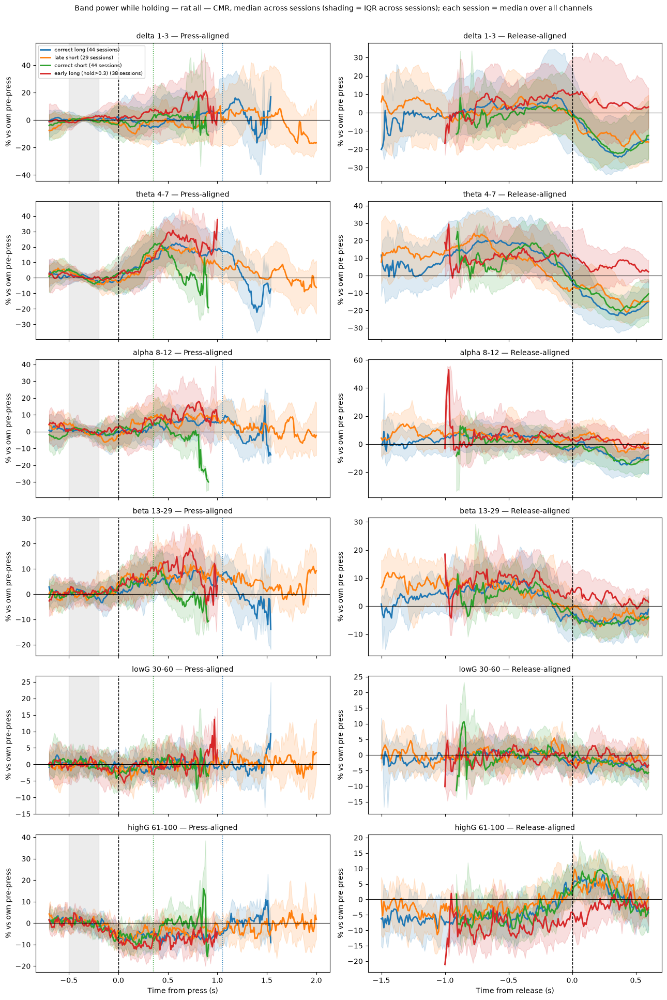

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over

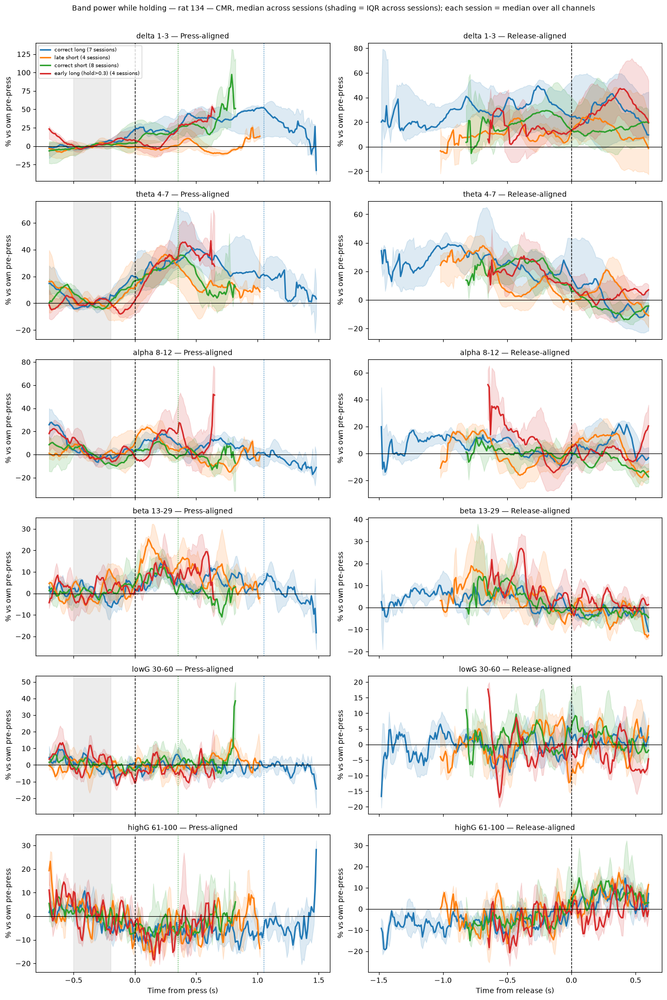

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over

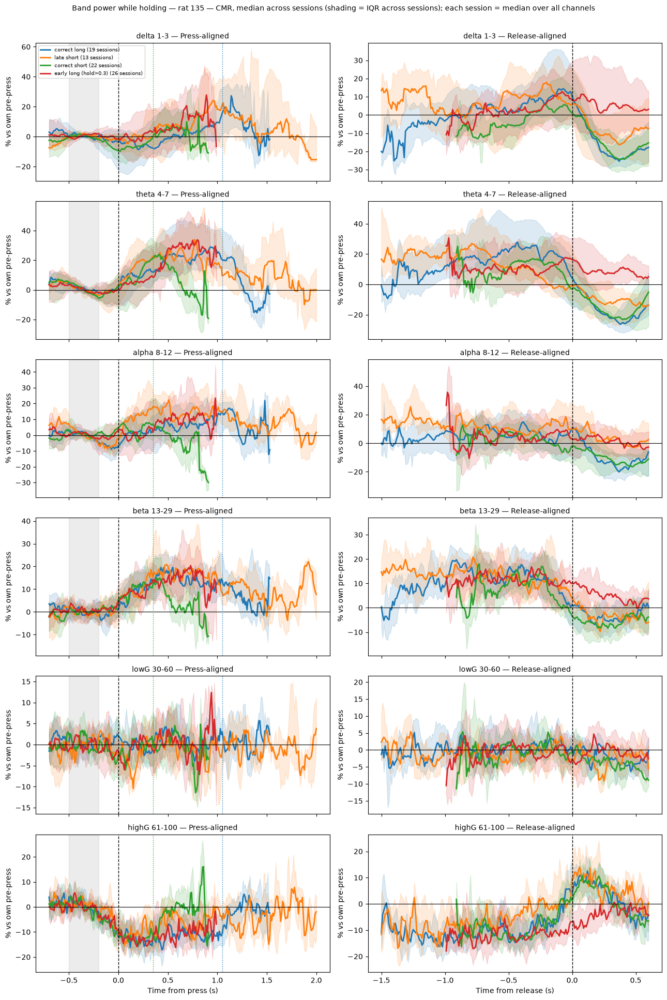

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2018505892.py:9: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over

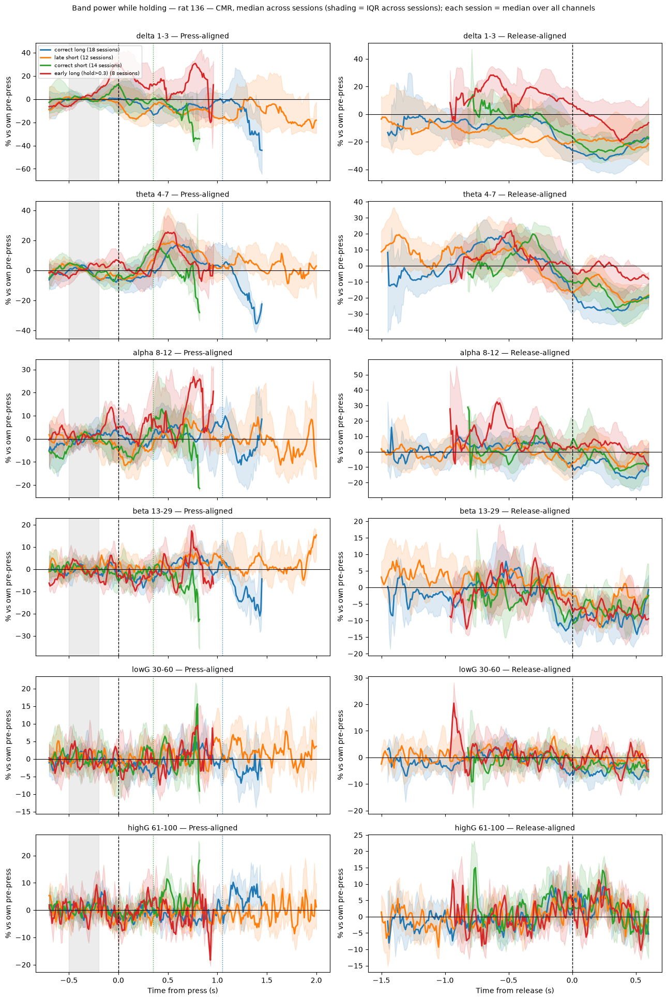

In [ ]:

FIG_CONDS = {"correct long": "tab:blue", "late short": "tab:orange",
             "correct short": "tab:green", "early long (hold>0.3)": "tab:red"}
MIN_COND_TRIALS, MIN_ON = 5, 3
def session_curve(r, al, b, c):
    T = r["trials"]; mk = lfm.main_conditions(T)[c]
    if mk.sum() < MIN_COND_TRIALS:
        return None
    cur = np.nanmedian(r["curves"][al][b][c], axis=0)                   # median over channels
    return np.where(r["counts"][al][c] >= MIN_ON, cur, np.nan)

for rat in ["all"] + sorted({rat_of(s) for s in BP}):
    ss = [s for s in BP if rat == "all" or rat_of(s) == rat]
    fig, axes = plt.subplots(len(lfm.MAIN_BANDS), 2, figsize=(13, 3.2 * len(lfm.MAIN_BANDS)), sharex="col")
    for i, b in enumerate(lfm.MAIN_BANDS):
        for j, al in enumerate(["Press", "Release"]):
            ax = axes[i, j]; t = BP[ss[0]]["times"][al]
            for c, col in FIG_CONDS.items():
                M = [x for x in (session_curve(BP[s], al, b, c) for s in ss) if x is not None]
                if len(M) < 3:
                    continue
                M = np.array(M)
                n_ok = np.isfinite(M).sum(0)
                with lfm.warnings_off():
                    med = 100 * (10 ** np.nanmedian(M, 0) - 1)
                    q1, q3 = 100 * (10 ** np.nanpercentile(M, 25, 0) - 1), 100 * (10 ** np.nanpercentile(M, 75, 0) - 1)
                show = n_ok >= 3
                ax.plot(t[show], med[show], color=col, lw=2, label=f"{c} ({len(M)} sessions)")
                ax.fill_between(t[show], q1[show], q3[show], color=col, alpha=0.15)
            ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=1)
            if al == "Press":
                ax.axvspan(*lfm.MAIN_PRE, color="grey", alpha=0.15)
                ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
            ax.set_title(f"{b} — {al}-aligned", fontsize=10)
            ax.set_ylabel("% vs own pre-press")
            if i == 0 and j == 0:
                ax.legend(fontsize=7, loc="upper left")
            if i == len(lfm.MAIN_BANDS) - 1:
                ax.set_xlabel(f"Time from {al.lower()} (s)")
    fig.suptitle(f"Band power while holding — rat {rat} — CMR, median across sessions (shading = IQR across sessions); "
                 f"each session = median over all channels", fontsize=10, y=1.005)
    fig.tight_layout()
    fig.savefig(os.path.join(BP_DIR, f"_timecourse_rat_{rat}.png"), dpi=150, bbox_inches="tight")
    plt.show()

## 1.6 Is theta (and every band) tied to HOLDING? — fixed windows, every condition (+ checks)
Q1  pre_release (−0.3..0, still holding) vs own pre-press — per condition. Holding effect -> up in ALL conditions.
Q2  post (+0.2..+0.5) vs pre_release — per condition. Drop in all -> release; drop only in correct -> reward/licking.
Checks: M1b hold vs hold_early (correct long); M2raw correct − early on raw log power (no baseline);
        Q3 correct − early in the pre-press window itself.
One value per session (mean over trials, median over channels) -> sign-flip across sessions, per rat + all.

In [10]:
# ── 1.6 compute ──
MIN_TR = 5
CONDS6 = ["correct long", "correct short", "late long", "late short", "early long (hold>0.3)", "early short"]
BANDS = list(lfm.MAIN_BANDS)

def sf_rows(vals, measure, cond):
    """vals: list of (session, band, value) -> sign-flip rows per band x rat (+ all)."""
    d = pd.DataFrame(vals, columns=["session", "band", "v"]); d["rat"] = d["session"].map(rat_of)
    out = []
    for b in BANDS:
        for rat in ["all"] + sorted(d["rat"].unique()):
            v = d[(d.band == b) & ((d.rat == rat) if rat != "all" else True)]["v"].dropna()
            m, p, n = lfm.sign_flip_p(v.values)
            out.append({"measure": measure, "condition": cond, "band": b, "rat": rat, "n_sessions": n,
                        "sessions > 0": int((v > 0).sum()), "mean %": round(100 * (10 ** m - 1), 1) if n else np.nan,
                        "p": round(p, 4) if n >= 2 else np.nan})
    return out

def chan_med(x):                                    # (trials, channels) -> mean over trials, median over channels
    return float(np.median(np.nanmean(x, axis=0)))

rows6 = []
for cond in CONDS6:
    q1, q2 = [], []
    for s, r in BP.items():
        mk = lfm.main_conditions(r["trials"])[cond].values
        if mk.sum() < MIN_TR:
            continue
        for b in BANDS:
            L = r["logpow"][b]
            q1.append((s, b, chan_med(L["pre_release"][mk] - L["pre"][mk])))
            q2.append((s, b, chan_med(L["post"][mk] - L["pre_release"][mk])))
    rows6 += sf_rows(q1, "Q1 pre_release − pre", cond) + sf_rows(q2, "Q2 post − pre_release", cond)

m1b, m2raw_pr, m2raw_he, q3 = [], [], [], []
for s, r in BP.items():
    C = lfm.main_conditions(r["trials"]); cl, el = C["correct long"].values, C["early long (hold>0.3)"].values
    for b in BANDS:
        L = r["logpow"][b]
        if cl.sum() >= 10:
            m1b.append((s, b, chan_med(L["hold"][cl] - L["hold_early"][cl])))
        if cl.sum() >= 10 and el.sum() >= 5:
            dif = lambda w: float(np.median(np.nanmean(L[w][cl], 0) - np.nanmean(L[w][el], 0)))
            m2raw_pr.append((s, b, dif("pre_release"))); m2raw_he.append((s, b, dif("hold_early")))
            q3.append((s, b, dif("pre")))
rows6 += sf_rows(m1b, "M1b hold − hold_early", "correct long")
rows6 += sf_rows(m2raw_pr, "M2raw pre_release correct − early (no baseline)", "CL vs EL")
rows6 += sf_rows(m2raw_he, "M2raw hold_early correct − early (no baseline)", "CL vs EL")
rows6 += sf_rows(q3, "Q3 pre-press correct − early", "CL vs EL")
S6 = pd.DataFrame(rows6)
S6.to_csv(os.path.join(BP_DIR, "_stats_1_6.csv"), index=False)

pd.set_option("display.width", 250)
for meas in S6["measure"].unique():
    d = S6[S6.measure == meas]
    print(f"\n===== {meas} — mean % [p] (n sessions) =====")
    d = d.assign(cell=d.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})"
                              if x["n_sessions"] >= 2 else "—", axis=1))
    for cond in d["condition"].unique():
        print(f"-- {cond}")
        print(d[d.condition == cond].pivot(index="band", columns="rat", values="cell").reindex(BANDS).to_string())


===== Q1 pre_release − pre — mean % [p] (n sessions) =====
-- correct long
rat                         134                 135                136                all
band                                                                                     
delta 1-3     +31.8 [0.048] (7)  +11.4 [0.036] (19)  -9.6 [0.068] (18)  +5.1 [0.196] (44)
theta 4-7     +18.7 [0.016] (7)  +11.5 [0.031] (19)  -4.2 [0.190] (18)  +5.9 [0.049] (44)
alpha 8-12     -4.0 [0.302] (7)   +4.0 [0.202] (19)  -1.3 [0.569] (18)  +0.5 [0.766] (44)
beta 13-29     +1.8 [0.545] (7)   +8.2 [0.001] (19)  -6.9 [0.004] (18)  +0.8 [0.649] (44)
lowG 30-60     +0.1 [0.984] (7)   +1.2 [0.307] (19)  -1.8 [0.161] (18)  -0.2 [0.799] (44)
highG 61-100   -4.1 [0.180] (7)   -3.2 [0.029] (19)  +3.9 [0.004] (18)  -0.5 [0.612] (44)
-- correct short
rat                         134                135                136                all
band                                                                                    
delta 1-3

## 1.7 Time courses: when, and do conditions differ at the SAME time while holding? (cluster sign-flip)
Each session gives a curve (median over channels of the condition's mean log ratio vs own pre-press).
Cluster test across sessions: one-sample t over sessions at each time point, |t| above the p<0.05 threshold
defines clusters (neighbouring time points, same sign), cluster mass = sum |t|; null = largest cluster mass
after random sign flips of whole session curves. Only time points where every included session has data.
Q4a time-matched: early long last 0.3 s before release vs correct long at the SAME times after the press.

In [11]:
# ── 1.7 compute ──
from scipy import stats as _st

def cluster_sign_flip(D, n_perm=5000, seed=0, alpha=0.05):
    """D: (sessions, times). Returns t, list of clusters (start, stop, sign, mass, p)."""
    n = D.shape[0]
    tcrit = _st.t.ppf(1 - alpha / 2, n - 1)
    def tval(X):
        return X.mean(0) / (X.std(0, ddof=1) / np.sqrt(n))
    def clusters(t):
        out, i = [], 0
        while i < len(t):
            if abs(t[i]) > tcrit:
                j, sg = i, np.sign(t[i])
                while j + 1 < len(t) and abs(t[j + 1]) > tcrit and np.sign(t[j + 1]) == sg:
                    j += 1
                out.append((i, j, sg, float(np.abs(t[i:j + 1]).sum()))); i = j + 1
            else:
                i += 1
        return out
    t = tval(D); obs = clusters(t)
    rng = np.random.default_rng(seed)
    null = np.zeros(n_perm)
    for k in range(n_perm):
        c = clusters(tval(D * rng.choice([-1.0, 1.0], size=(n, 1))))
        null[k] = max([m for *_, m in c], default=0.0)
    return t, [(a, b, sg, m, (1 + np.sum(null >= m)) / (n_perm + 1)) for a, b, sg, m in obs]

def sess_curve(r, al, b, c, min_tr=MIN_TR, min_on=3):
    mk = lfm.main_conditions(r["trials"])[c]
    if mk.sum() < min_tr:
        return None
    cur = np.nanmedian(r["curves"][al][b][c], axis=0)
    return np.where(r["counts"][al][c] >= min_on, cur, np.nan)

def run_cluster(get_curve, al, trange, label, rows, curves_out):
    for b in BANDS:
        for rat in ["all"] + sorted({rat_of(s) for s in BP}):
            ss = [s for s in BP if rat == "all" or rat_of(s) == rat]
            t = BP[ss[0]]["times"][al]; m = (t >= trange[0] - 1e-9) & (t <= trange[1] + 1e-9)
            C = [x[m] for x in (get_curve(BP[s], b) for s in ss) if x is not None and np.isfinite(x[m]).all()]
            if len(C) < 4:
                rows.append({"test": label, "band": b, "rat": rat, "n_sessions": len(C), "clusters": "too few sessions"})
                continue
            D = np.array(C); tt, cl = cluster_sign_flip(D)
            txt = "; ".join(f"{t[m][a]:+.2f}..{t[m][z]:+.2f}s {'+' if sg > 0 else '−'} p={p:.3f}" for a, z, sg, _, p in cl if p < 0.05)
            rows.append({"test": label, "band": b, "rat": rat, "n_sessions": len(C), "clusters": txt or "none"})
            curves_out[(label, b, rat)] = (t[m], D)

rows7, curves7 = [], {}
TESTS_VS0 = [("Press", "correct long", (0.0, 1.0)), ("Press", "late short", (0.0, 0.85)),
             ("Press", "correct short", (0.0, 0.5)), ("Press", "early long (hold>0.3)", (0.0, 0.3)),
             ("Release", "correct long", (-0.5, 0.5)), ("Release", "late short", (-0.5, 0.5)),
             ("Release", "correct short", (-0.3, 0.5)), ("Release", "early long (hold>0.3)", (-0.3, 0.5))]
for al, c, tr in TESTS_VS0:
    run_cluster(lambda r, b, al=al, c=c: sess_curve(r, al, b, c), al, tr, f"{c} vs 0 ({al})", rows7, curves7)

def diff_curve(r, b, al, c1, c2):
    a, z = sess_curve(r, al, b, c1), sess_curve(r, al, b, c2)
    return None if a is None or z is None else a - z
run_cluster(lambda r, b: diff_curve(r, b, "Press", "correct long", "early long (hold>0.3)"), "Press", (0.0, 0.3),
            "correct long − early long (Press, both holding)", rows7, curves7)
run_cluster(lambda r, b: diff_curve(r, b, "Press", "late short", "correct short"), "Press", (0.35, 0.5),
            "late short − correct short after tone (Press, both holding)", rows7, curves7)
S7 = pd.DataFrame(rows7); S7.to_csv(os.path.join(BP_DIR, "_stats_1_7_clusters.csv"), index=False)
print(S7.pivot_table(index=["test", "band"], columns="rat", values="clusters", aggfunc="first").to_string())

# Q4a time-matched: early long last window before release vs correct long at the same times after the press
q4a = {w: [] for w in [(-0.3, 0.0), (-0.45, -0.15)]}
for s, r in BP.items():
    T = r["trials"]; C = lfm.main_conditions(T)
    cl, el = C["correct long"].values, C["early long (hold>0.3)"].values
    if cl.sum() < 10 or el.sum() < MIN_TR:
        continue
    tP, tR = r["times"]["Press"], r["times"]["Release"]
    holds = T.loc[el, "hold_s"].values
    for b in BANDS:
        cP = np.nanmedian(r["curves"]["Press"][b]["correct long"], axis=0)          # correct long, Press-aligned
        cP = np.where(r["counts"]["Press"]["correct long"] >= 3, cP, np.nan)
        eR = np.nanmedian(r["curves"]["Release"][b]["early long (hold>0.3)"], axis=0)  # early long, Release-aligned
        for w in q4a:
            e_val = np.nanmean(eR[(tR >= w[0]) & (tR <= w[1])])
            c_val = np.nanmean([np.nanmean(cP[(tP >= h + w[0]) & (tP <= h + w[1])]) for h in holds])
            q4a[w].append((s, b, e_val - c_val))
rows4a = []
for w, v in q4a.items():
    rows4a += sf_rows(v, f"Q4a early − correct at matched time, window {w}", "EL vs CL (time-matched)")
S4a = pd.DataFrame(rows4a); S4a.to_csv(os.path.join(BP_DIR, "_stats_1_7_q4a.csv"), index=False)
for meas, d in S4a.groupby("measure", sort=False):
    print(f"\n===== {meas} — mean % [p] (n) =====")
    d = d.assign(cell=d.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})" if x["n_sessions"] >= 2 else "—", axis=1))
    print(d.pivot(index="band", columns="rat", values="cell").reindex(BANDS).to_string())

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:33: RuntimeWarning: All-NaN slice encountered
  cur = np.nanmedian(r["curves"][al][b][c], axis=0)
C:\Users\ar687\AppData\Local

rat                                                                                           134                                                                        135                                                                        136                                                                        all
test                                                        band                                                                                                                                                                                                                                                                  
correct long vs 0 (Press)                                   alpha 8-12    +0.61..+0.85s + p=0.046                                                                       none                                                                       none                                                                       none
                               

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:78: RuntimeWarning: All-NaN slice encountered
  cP = np.nanmedian(r["curves"]["Press"][b]["correct long"], axis=0)          # correct long, Press-aligned
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:80: RuntimeWarning: All-NaN slice encountered
  eR = np.nanmedian(r["curves"]["Release"][b]["early long (hold>0.3)"], axis=0)  # early long, Release-aligned
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:78: RuntimeWarning: All-NaN slice encountered
  cP = np.nanmedian(r["curves"]["Press"][b]["correct long"], axis=0)          # correct long, Press-aligned
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:80: RuntimeWarning: All-NaN slice encountered
  eR = np.nanmedian(r["curves"]["Release"][b]["early long (hold>0.3)"], axis=0)  # early long, Release-aligned
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\2560350251.py:78: RuntimeWarning: All-NaN slice encountered
  cP = np.na


===== Q4a early − correct at matched time, window (-0.3, 0.0) — mean % [p] (n) =====
rat                         134                135                136                all
band                                                                                    
delta 1-3     -11.5 [0.504] (4)  +6.0 [0.155] (16)  +15.5 [0.275] (6)  +5.2 [0.210] (26)
theta 4-7      -2.9 [0.875] (4)  -0.1 [0.984] (16)  -18.0 [0.166] (6)  -4.9 [0.210] (26)
alpha 8-12    -11.8 [0.491] (4)  +1.1 [0.737] (16)   +2.3 [0.747] (6)  -0.7 [0.808] (26)
beta 13-29     -2.1 [0.369] (4)  -1.9 [0.443] (16)   -3.6 [0.159] (6)  -2.3 [0.141] (26)
lowG 30-60     -3.7 [0.369] (4)  -1.5 [0.282] (16)   -0.1 [0.905] (6)  -1.5 [0.150] (26)
highG 61-100   +4.4 [0.124] (4)  +2.3 [0.084] (16)   +4.0 [0.154] (6)  +3.0 [0.004] (26)

===== Q4a early − correct at matched time, window (-0.45, -0.15) — mean % [p] (n) =====
rat                         134                135                136                all
band                    

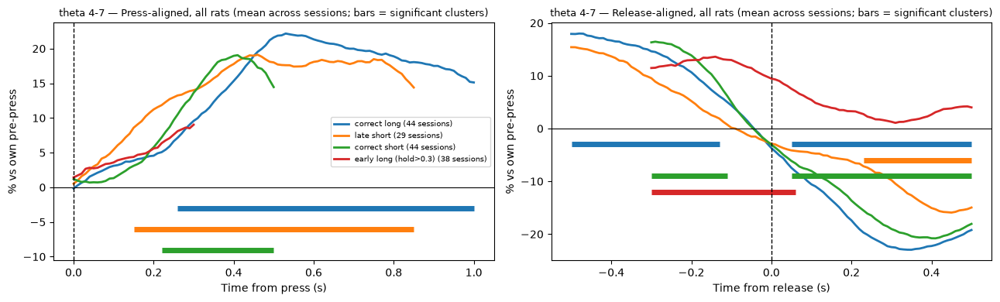

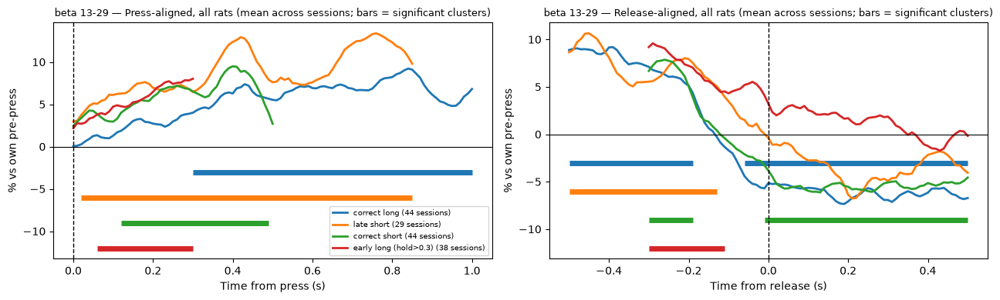

In [12]:
# ── 1.7b figure: theta and beta curves vs 0 per condition, with significant clusters (all rats) ──
for b in ["theta 4-7", "beta 13-29"]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, al in zip(axes, ["Press", "Release"]):
        for i, ((al_, c, tr), col) in enumerate(zip([x for x in TESTS_VS0 if x[0] == al],
                                                    ["tab:blue", "tab:orange", "tab:green", "tab:red"])):
            key = (f"{c} vs 0 ({al})", b, "all")
            if key not in curves7:
                continue
            t, D = curves7[key]
            ax.plot(t, 100 * (10 ** D.mean(0) - 1), color=col, lw=2, label=f"{c} ({D.shape[0]} sessions)")
            row = S7[(S7.test == key[0]) & (S7.band == b) & (S7.rat == "all")]["clusters"].iloc[0]
            for part in [p for p in row.split("; ") if "p=" in p]:
                a, z = [float(x) for x in part.split("s ")[0].split("..")]
                ax.plot([a, z], [-3 - 3 * i] * 2, color=col, lw=5, solid_capstyle="butt")   # cluster bar
        ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=1)
        ax.set_title(f"{b} — {al}-aligned, all rats (mean across sessions; bars = significant clusters)", fontsize=9)
        ax.set_xlabel(f"Time from {al.lower()} (s)"); ax.set_ylabel("% vs own pre-press")
    axes[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(os.path.join(BP_DIR, f"_clusters_{b.split()[0]}.png"), dpi=150, bbox_inches="tight")
    plt.show()

## 1.8 Q4b — does theta in a single trial predict the outcome? (correct long vs early long)
Per trial: value = median over channels of (log hold_early − log pre). Per session: AUC = probability that a random
correct-long trial has a higher value than a random early-long trial (0.5 = no prediction). Session = unit:
sign-flip on (AUC − 0.5) across sessions. Also for raw hold_early (no baseline) and pre-press alone.

In [13]:
# ── 1.8 compute ──
def auc(a, b):
    a, b = np.asarray(a), np.asarray(b)
    r = _st.rankdata(np.r_[a, b])[:len(a)]
    return (r.sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b))

rows8 = []
for feat, f in [("hold_early − pre", lambda L: L["hold_early"] - L["pre"]),
                ("hold_early raw", lambda L: L["hold_early"]),
                ("pre raw", lambda L: L["pre"])]:
    vals = []
    for s, r in BP.items():
        C = lfm.main_conditions(r["trials"]); cl, el = C["correct long"].values, C["early long (hold>0.3)"].values
        if cl.sum() < 10 or el.sum() < MIN_TR:
            continue
        for b in BANDS:
            x = np.median(f(r["logpow"][b]), axis=1)            # per trial: median over channels
            vals.append((s, b, auc(x[cl], x[el]) - 0.5))
    d = pd.DataFrame(vals, columns=["session", "band", "v"]); d["rat"] = d["session"].map(rat_of)
    for b in BANDS:
        for rat in ["all"] + sorted(d["rat"].unique()):
            v = d[(d.band == b) & ((d.rat == rat) if rat != "all" else True)]["v"]
            m, p, n = lfm.sign_flip_p(v.values)
            rows8.append({"feature": feat, "band": b, "rat": rat, "n_sessions": n,
                          "mean AUC": round(0.5 + m, 3), "sessions AUC>0.5": int((v > 0).sum()), "p": round(p, 4)})
S8 = pd.DataFrame(rows8); S8.to_csv(os.path.join(BP_DIR, "_stats_1_8_auc.csv"), index=False)
for feat, d in S8.groupby("feature", sort=False):
    print(f"\n===== Q4b AUC correct vs early — {feat}: mean AUC [p] (n) =====")
    d = d.assign(cell=d.apply(lambda x: f"{x['mean AUC']:.3f} [{x['p']:.3f}] ({x['n_sessions']})", axis=1))
    print(d.pivot(index="band", columns="rat", values="cell").reindex(BANDS).to_string())


===== Q4b AUC correct vs early — hold_early − pre: mean AUC [p] (n) =====
rat                         134                 135                136                 all
band                                                                                      
delta 1-3     0.628 [0.124] (4)  0.475 [0.189] (16)  0.449 [0.124] (6)  0.493 [0.690] (26)
theta 4-7     0.437 [0.504] (4)  0.529 [0.251] (16)  0.533 [0.410] (6)  0.516 [0.408] (26)
alpha 8-12    0.494 [1.000] (4)  0.522 [0.495] (16)  0.470 [0.562] (6)  0.506 [0.812] (26)
beta 13-29    0.462 [0.873] (4)  0.514 [0.687] (16)  0.520 [0.750] (6)  0.507 [0.768] (26)
lowG 30-60    0.451 [0.386] (4)  0.491 [0.680] (16)  0.459 [0.515] (6)  0.478 [0.194] (26)
highG 61-100  0.622 [0.124] (4)  0.476 [0.430] (16)  0.459 [0.387] (6)  0.495 [0.823] (26)

===== Q4b AUC correct vs early — hold_early raw: mean AUC [p] (n) =====
rat                         134                 135                136                 all
band                             

## 1.9 Step A (Karvat 2021 idea, band power): more power before the TONE in late than in correct trials?
Late = released > 0.5 s after the tone (slow / "missed"). Same trial type -> same tone time -> time-matched.
Windows (Press-aligned, last 0.3 s before the tone): short 0.05–0.35 s, long 0.75–1.05 s.
Per session: mean over the window of the condition curve (median over channels; log power vs own pre-press),
late − correct; ≥5 trials per condition; sign-flip across sessions, per rat + all.
Note: the curves are relative to each trial's own pre-press, so this is "change before the tone" late vs correct.

CMR done
LOCAL done
late − correct, last 0.3 s before the tone; + = more before late (paper direction)
  ref       band   typ region  n_sessions pct_channels_late_higher    region_median
  CMR alpha 8-12  long    Cg1           8              61% [54–68] +10.7% [p 0.250]
  CMR alpha 8-12  long     IL          11             64% [42–100] +16.7% [p 0.081]
  CMR alpha 8-12  long     PL          10              70% [41–84] +18.4% [p 0.113]
  CMR alpha 8-12 short    Cg1          21              39% [30–70]  -1.1% [p 0.858]
  CMR alpha 8-12 short     IL          27              66% [45–78] +16.7% [p 0.033]
  CMR alpha 8-12 short     PL          25              49% [33–58]  -0.8% [p 0.814]
  CMR beta 13-29  long    Cg1           8              52% [33–71]  +1.0% [p 0.827]
  CMR beta 13-29  long     IL          11               40% [7–56]  -3.6% [p 0.528]
  CMR beta 13-29  long     PL          10              43% [22–58]  -3.9% [p 0.328]
  CMR beta 13-29 short    Cg1          21              50

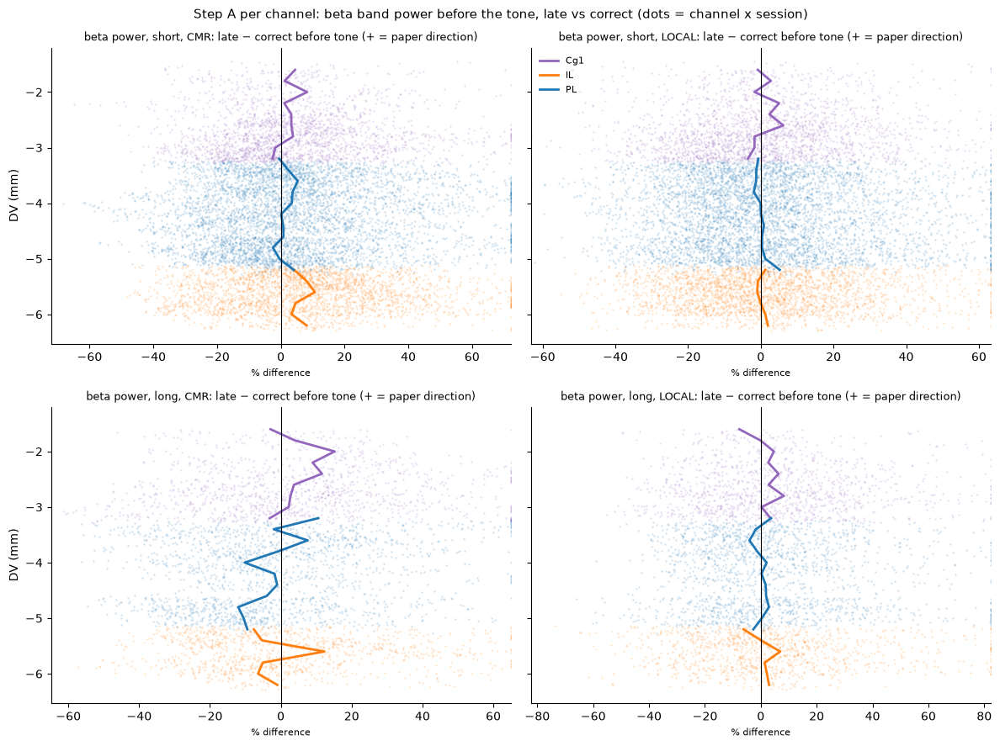

In [121]:
# ── 1.9c STEP A PER CHANNEL: band power, late − correct in the last 0.3 s before the tone (as 1.9, but each channel alone) ──
# needs 1.0 (lfm, rat_of, SESSIONS_V2) and 1.19 (DIRS, regions_of). Positive = MORE power before LATE = paper direction.
import pickle, warnings
PRE_TONE_A = {"short": (0.05, 0.35), "long": (0.75, 1.05)}
BANDS_A = ("beta 13-29", "theta 4-7", "alpha 8-12")
RN = {"Prelimbic area": "PL", "Infralimbic area": "IL", "Cingulate area 1": "Cg1"}
REG_COL = {"PL": "#1f77b4", "IL": "#ff7f0e", "Cg1": "#9467bd"}
rowsA = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for ref, d in DIRS.items():
        for s in SESSIONS_V2:
            with open(os.path.join(d, s + ".pkl"), "rb") as f:
                r = pickle.load(f)
            C = lfm.main_conditions(r["trials"]); tP = r["times"]["Press"]
            R, D = regions_of(s, r["meta"]); reg = np.array([RN.get(x, "") for x in R])
            for typ, (a, z) in PRE_TONE_A.items():
                cC, cL = f"correct {typ}", f"late {typ}"
                if C[cC].sum() < 5 or C[cL].sum() < 5: continue
                mt = (tP >= a - 1e-9) & (tP <= z + 1e-9)
                if not ((r["counts"]["Press"][cC][mt] >= 3).all() and (r["counts"]["Press"][cL][mt] >= 3).all()): continue
                for b in BANDS_A:
                    v = np.nanmean(r["curves"]["Press"][b][cL][:, mt], 1) - np.nanmean(r["curves"]["Press"][b][cC][:, mt], 1)
                    rowsA.append(pd.DataFrame(dict(ref=ref, session=s, rat=str(rat_of(s)), typ=typ, band=b, region=reg,
                                                   dv_mm=D, ch=r["meta"]["channel_ids"], value=100 * (10 ** v - 1))))
            del r
        print(ref, "done")
CHA = pd.concat(rowsA, ignore_index=True); CHA = CHA[CHA["region"] != ""]
CHA.to_csv(os.path.join(DIRS["CMR"], "_channel_values_1_9c.csv"), index=False)

# summary: per session the % of a region's channels with late > correct, and the region median (as 1.12) + sign-flip
SA = (CHA.groupby(["ref", "band", "typ", "region", "session", "rat"])["value"]
         .agg(pct_up=lambda v: 100 * np.mean(v > 0), med="median").reset_index())
out = []
for (ref, b, typ, reg), g in SA.groupby(["ref", "band", "typ", "region"], sort=False):
    mn, p, n = lfm.sign_flip_p(g["med"].values)
    out.append(dict(ref=ref, band=b, typ=typ, region=reg, n_sessions=n,
                    pct_channels_late_higher=f"{g['pct_up'].median():.0f}% [{g['pct_up'].quantile(.25):.0f}–{g['pct_up'].quantile(.75):.0f}]",
                    region_median=f"{mn:+.1f}% [p {p:.3f}]"))
pd.set_option("display.width", 220)
print("late − correct, last 0.3 s before the tone; + = more before late (paper direction)")
print(pd.DataFrame(out).to_string(index=False))

# figure: beta, every channel x session vs depth; lines = median per region per 0.2 mm
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True, squeeze=False)
for i, typ in enumerate(("short", "long")):
    for j, ref in enumerate(DIRS):
        ax = axes[i, j]; d = CHA[(CHA.band == "beta 13-29") & (CHA.typ == typ) & (CHA.ref == ref)]
        lim = np.nanpercentile(np.abs(d["value"]), 98) if len(d) else 1
        for reg, g in d.groupby("region"):
            ax.scatter(g["value"].clip(-lim, lim), g["dv_mm"], s=3, alpha=0.2, color=REG_COL[reg], lw=0)
            bb = (g["dv_mm"] / 0.2).round() * 0.2; m = g.groupby(bb)["value"].median()[g.groupby(bb).size() >= 20]
            ax.plot(m.values, m.index, color=REG_COL[reg], lw=2, label=reg)
        ax.axvline(0, color="k", lw=0.8); ax.set_xlim(-lim, lim)
        ax.set_title(f"beta power, {typ}, {ref}: late − correct before tone (+ = paper direction)", fontsize=9)
        ax.set_xlabel("% difference", fontsize=8)
        if j == 0: ax.set_ylabel("DV (mm)")
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 1].legend(fontsize=8, frameon=False)
fig.suptitle("Step A per channel: beta band power before the tone, late vs correct (dots = channel x session)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(DIRS["CMR"], "1_9c_stepA_channels.png"), dpi=140, bbox_inches="tight"); plt.show()

 ## 1.10 Depth profile — where along the probe does power change during the hold? (M1, correct long)
 The probe stays in the same place within a rat, so the same shank + depth (y = distance from the tip) is the same
 tissue in every session of that rat. Per rat, shank and 100 µm depth bin: session value = median over the channels
 in that bin of the trial-mean log ratio (hold − pre, and hold − post). Bins with ≥ 5 sessions are tested with the
 sign-flip across sessions (raw p, as for the pilot). "Hold-specific" = p < 0.05 vs pre AND vs post, same sign.

             bins tested             hold-specific UP             hold-specific DOWN            median hold-pre %            
rat                  134   135   136              134   135   136                134   135  136               134   135   136
band                                                                                                                         
delta 1-3           22.0  93.0  62.0              0.0  17.0   0.0                0.0   0.0  0.0              39.3  13.0   2.0
theta 4-7           22.0  93.0  62.0              0.0  61.0  20.0                0.0   0.0  0.0              30.3  31.8  25.4
alpha 8-12          22.0  93.0  62.0              0.0  25.0  12.0                0.0   0.0  0.0              17.6  15.0  17.9
beta 13-29          22.0  93.0  62.0              0.0  52.0   3.0                0.0   0.0  0.0               7.3  18.4   4.8
lowG 30-60          22.0  93.0  62.0              0.0  12.0   0.0                0.0   0.0  0.0               1.8   3.

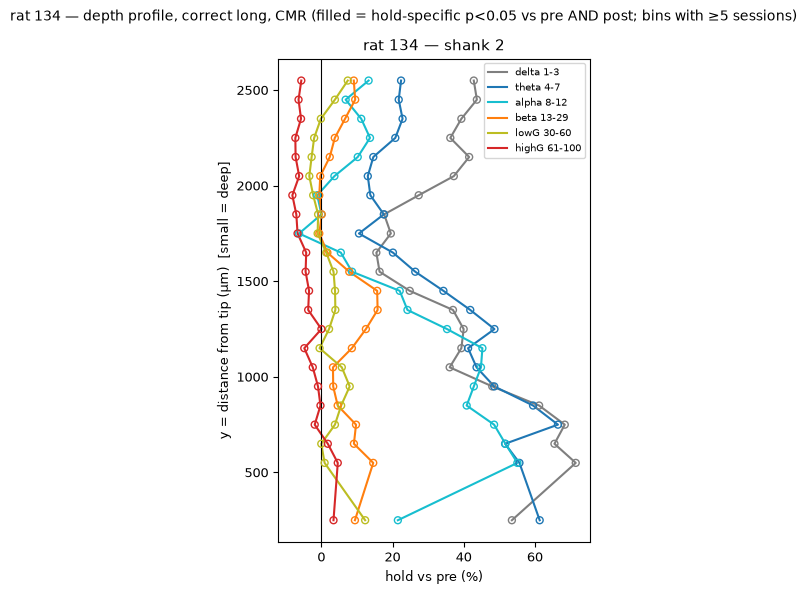

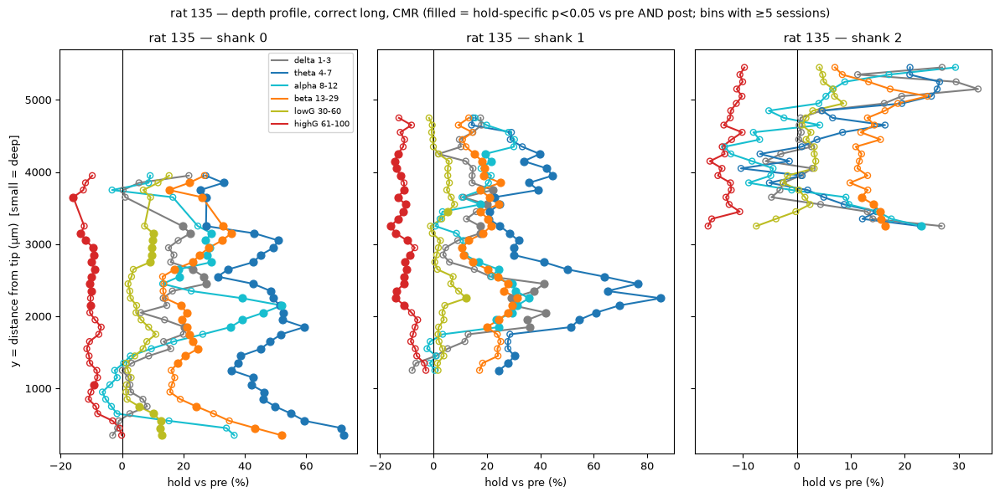

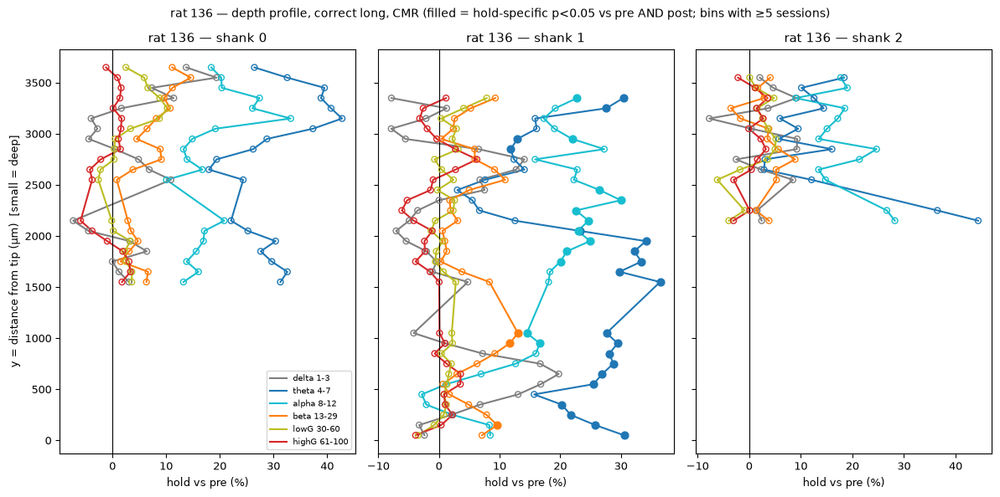

In [56]:
# ── 1.10 compute ──
BIN_UM, MIN_SESS = 100, 5
rows10 = []
for s, r in BP.items():
    T = r["trials"]
    cl = ((T.long_prob == 0.5) & (T.outcome == "correct") & (T.type == "long")).values
    if cl.sum() < 10:
        continue
    x, y = np.asarray(r["meta"]["x"]), np.asarray(r["meta"]["y"])
    shank = (x // 250).astype(int); dbin = (y // BIN_UM * BIN_UM).astype(int)
    for b in BANDS:
        L = r["logpow"][b]
        d_pre = np.nanmean(L["hold"][cl] - L["pre"][cl], axis=0)      # per channel
        d_post = np.nanmean(L["hold"][cl] - L["post"][cl], axis=0)
        for sh in np.unique(shank):
            for yb in np.unique(dbin[shank == sh]):
                m = (shank == sh) & (dbin == yb)
                rows10.append({"session": s, "rat": rat_of(s), "band": b, "shank": int(sh), "depth_bin": int(yb),
                               "n_ch": int(m.sum()), "hold-pre": float(np.median(d_pre[m])),
                               "hold-post": float(np.median(d_post[m]))})
DV = pd.DataFrame(rows10)

res10 = []
for (rat, b, sh, yb), d in DV.groupby(["rat", "band", "shank", "depth_bin"]):
    if len(d) < MIN_SESS:
        continue
    m1, p1, n = lfm.sign_flip_p(d["hold-pre"].values)
    m2, p2, _ = lfm.sign_flip_p(d["hold-post"].values)
    res10.append({"rat": rat, "band": b, "shank": sh, "depth_bin": yb, "n_sessions": n,
                  "hold-pre %": 100 * (10 ** m1 - 1), "p pre": p1, "hold-post %": 100 * (10 ** m2 - 1), "p post": p2,
                  "hold-specific": (p1 < 0.05) and (p2 < 0.05) and (np.sign(m1) == np.sign(m2))})
R10 = pd.DataFrame(res10)
R10.to_csv(os.path.join(BP_DIR, "_depth_profile_M1.csv"), index=False)

pd.set_option("display.width", 250)
summ10 = (R10.groupby(["rat", "band"])
             .apply(lambda d: pd.Series({"bins tested": len(d),
                                         "hold-specific UP": int((d["hold-specific"] & (d["hold-pre %"] > 0)).sum()),
                                         "hold-specific DOWN": int((d["hold-specific"] & (d["hold-pre %"] < 0)).sum()),
                                         "median hold-pre %": round(d["hold-pre %"].median(), 1)}))
             .reset_index())
print(summ10.pivot(index="band", columns="rat",
                   values=["bins tested", "hold-specific UP", "hold-specific DOWN", "median hold-pre %"])
            .reindex(BANDS).to_string())

# ── 1.10 figure: per rat, one panel per shank; x = % change hold vs pre, y = depth; filled = hold-specific ──
BCOL = {"delta 1-3": "tab:gray", "theta 4-7": "tab:blue", "alpha 8-12": "tab:cyan",
        "beta 13-29": "tab:orange", "lowG 30-60": "tab:olive", "highG 61-100": "tab:red"}
for rat in sorted(R10["rat"].unique()):
    d_r = R10[R10.rat == rat]; shanks = sorted(d_r["shank"].unique())
    fig, axes = plt.subplots(1, len(shanks), figsize=(4 * len(shanks), 6), sharey=True, squeeze=False)
    for ax, sh in zip(axes[0], shanks):
        for b, col in BCOL.items():
            d = d_r[(d_r.shank == sh) & (d_r.band == b)].sort_values("depth_bin")
            if d.empty:
                continue
            yc = d["depth_bin"] + BIN_UM / 2
            ax.plot(d["hold-pre %"], yc, "-", color=col, lw=1.5, label=b)
            hs = d["hold-specific"].values
            ax.scatter(d["hold-pre %"][hs], yc[hs], color=col, s=40, zorder=3)
            ax.scatter(d["hold-pre %"][~hs], yc[~hs], facecolors="none", edgecolors=col, s=25, zorder=3)
        ax.axvline(0, color="k", lw=0.8); ax.set_title(f"rat {rat} — shank {sh}")
        ax.set_xlabel("hold vs pre (%)")
    axes[0, 0].set_ylabel("y = distance from tip (µm)  [small = deep]"); axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"rat {rat} — depth profile, correct long, CMR (filled = hold-specific p<0.05 vs pre AND post; "
                 f"bins with ≥{MIN_SESS} sessions)", fontsize=10)
    fig.tight_layout(); fig.savefig(os.path.join(BP_DIR, f"_depth_profile_rat_{rat}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [57]:
for s, r in BP.items():
    if rat_of(s) == "134":
        sh = (np.asarray(r["meta"]["x"]) // 250).astype(int)
        print(s, pd.Series(sh).value_counts().sort_index().to_dict())
print(DV[DV.rat == "134"].groupby("shank")["session"].nunique())

20260609_r0000134_wt_1622 {2: 376}
20260610_r0000134_wt_1923 {1: 190, 2: 187}
20260611_r0000134_wt_1309 {1: 190, 2: 187}
20260612_r0000134_wt_1447 {1: 190, 2: 187}
20260615_r0000134_wt_1825 {1: 190, 2: 187}
20260616_r0000134_wt_1653 {1: 190, 2: 187}
20260617_r0000134_wt_1914 {0: 1, 1: 179, 2: 144, 3: 53}
20260620_r0000134_wt_1512 {0: 1, 1: 178, 2: 144, 3: 53}
20260620_r0000134_wt_1554 {0: 1, 1: 178, 2: 144, 3: 53}
20260621_r0000134_wt_1533 {0: 1, 1: 178, 2: 143, 3: 53}
20260622_r0000134_wt_1513 {1: 140, 2: 189, 3: 47}
shank
0    2
1    4
2    5
3    3
Name: session, dtype: int64


## 1.11 Per-session dot plot — the main figure
One dot = one session (colour = rat), per band. Panels: M1 hold vs pre, M1 hold vs post (correct long),
Q4a early − correct at matched time (−0.45..−0.15 s, release leakage excluded), Step A late − correct before the
tone (short trials). Black bar = mean across sessions (all rats); text = sessions > 0 / n and sign-flip p (all rats).
Needs: S (cell 1.4), q4a (cell 1.7), BANDS (1.6)

C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encountered
  C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encountered
  C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encountered
  C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encountered
  C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encountered
  C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
C:\Users\ar687\AppData\Local\Temp\ipykernel_31924\1197940211.py:18: RuntimeWarning: All-NaN slice encount

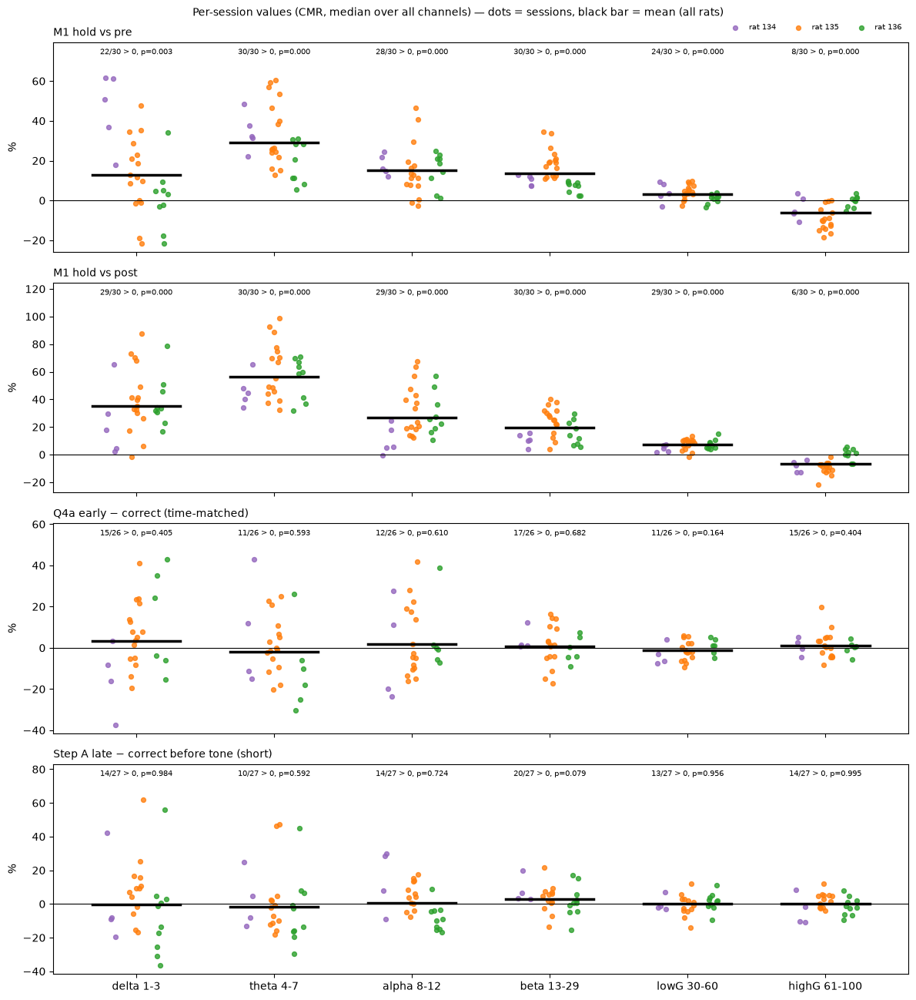

In [17]:
# ── 1.11 collect session values ──
DOT = []
for _, x in S.iterrows():
    for meas, col in [("M1 hold vs pre", "M1 hold-pre"), ("M1 hold vs post", "M1 hold-post")]:
        if pd.notna(x[col]):
            DOT.append({"panel": meas, "session": x["session"], "rat": x["rat"], "band": x["band"], "v": x[col]})
for s, b, v in q4a[(-0.45, -0.15)]:
    DOT.append({"panel": "Q4a early − correct (time-matched)", "session": s, "rat": rat_of(s), "band": b, "v": v})
a, z = PRE_TONE["short"] if "PRE_TONE" in globals() else (0.05, 0.35)
for s, r in BP.items():                                  # Step A, short trials (same rule as cell 1.9)
    mk = lfm.main_conditions(r["trials"])
    if mk["correct short"].sum() < 5 or mk["late short"].sum() < 5:
        continue
    t = r["times"]["Press"]; m = (t >= a - 1e-9) & (t <= z + 1e-9)
    if not ((r["counts"]["Press"]["correct short"][m] >= 3).all() and (r["counts"]["Press"]["late short"][m] >= 3).all()):
        continue
    for b in BANDS:
        C = np.nanmedian(r["curves"]["Press"][b]["correct short"], axis=0)
        L = np.nanmedian(r["curves"]["Press"][b]["late short"], axis=0)
        DOT.append({"panel": "Step A late − correct before tone (short)", "session": s, "rat": rat_of(s),
                    "band": b, "v": float(np.nanmean(L[m]) - np.nanmean(C[m]))})
DOT = pd.DataFrame(DOT); DOT["pct"] = 100 * (10 ** DOT["v"] - 1)
DOT.to_csv(os.path.join(BP_DIR, "_dotplot_session_values.csv"), index=False)

# ── 1.11 figure ──
RCOL = {"134": "tab:purple", "135": "tab:orange", "136": "tab:green"}
panels = list(DOT["panel"].unique())
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 3.3 * len(panels)), sharex=True)
rng_j = np.random.default_rng(0)
for ax, pnl in zip(np.atleast_1d(axes), panels):
    d = DOT[DOT.panel == pnl]
    for i, b in enumerate(BANDS):
        db = d[d.band == b]
        for k, rat in enumerate(sorted(RCOL)):
            dr = db[db.rat == rat]
            xs = i + (k - 1) * 0.18 + rng_j.uniform(-0.05, 0.05, len(dr))
            ax.scatter(xs, dr["pct"], s=18, color=RCOL[rat], alpha=0.8, label=f"rat {rat}" if i == 0 else None)
        if len(db):
            mean_pct = 100 * (10 ** db["v"].mean() - 1)
            ax.plot([i - 0.32, i + 0.32], [mean_pct] * 2, color="k", lw=2.5)
            _, p, n = lfm.sign_flip_p(db["v"].values)
            ax.text(i, 0.97, f"{int((db['v'] > 0).sum())}/{n} > 0, p={p:.3f}", ha="center", va="top", fontsize=7,
                    transform=ax.get_xaxis_transform())
    ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("%"); ax.set_title(pnl, fontsize=10, loc="left")
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.15 * (hi - lo))          # room for the text
np.atleast_1d(axes)[0].legend(fontsize=7, ncol=3, loc="lower right", bbox_to_anchor=(1.0, 1.02), frameon=False)
np.atleast_1d(axes)[-1].set_xticks(range(len(BANDS))); np.atleast_1d(axes)[-1].set_xticklabels(BANDS)
fig.suptitle("Per-session values (CMR, median over all channels) — dots = sessions, black bar = mean (all rats)",
             fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(BP_DIR, "_dotplot_main.png"), dpi=150, bbox_inches="tight")
plt.show()


## 1.12 Main results PER REGION (PL, IL, Cg1)
Same session values as 1.4 / 1.6 / 1.7 (Q4a) / 1.9 (step A), but the median is over the channels of ONE region instead of all channels.
Region per channel from <code>tables/channel_regions_all.csv</code> (session-info notebook), matched by position (x, y).
Basal forebrain, M2 and "Not found" left out. A region enters a session only with ≥ MIN_CH channels. Session = unit; sign-flip, per rat + all; raw p.
</div>

In [76]:
# ── 1.12 compute ──  (needs only cells 1.0 and 1.3; settings below are the same as in 1.4 / 1.6 / 1.9)
MIN_CL, MIN_EL, MIN_TR = 10, 5, 5
BANDS = list(lfm.MAIN_BANDS)
PRE_TONE = {"short": (0.05, 0.35), "long": (0.75, 1.05)}

def sf_rows(vals, measure, cond):
    """vals: list of (session, band, value) -> sign-flip rows per band x rat (+ all)."""
    d = pd.DataFrame(vals, columns=["session", "band", "v"]); d["rat"] = d["session"].map(rat_of)
    out = []
    for b in BANDS:
        for rat in ["all"] + sorted(d["rat"].unique()):
            v = d[(d.band == b) & ((d.rat == rat) if rat != "all" else True)]["v"].dropna()
            m, p, n = lfm.sign_flip_p(v.values)
            out.append({"measure": measure, "condition": cond, "band": b, "rat": rat, "n_sessions": n,
                        "sessions > 0": int((v > 0).sum()), "mean %": round(100 * (10 ** m - 1), 1) if n else np.nan,
                        "p": round(p, 4) if n >= 2 else np.nan})
    return out

REGIONS = {"PL": "Prelimbic area", "IL": "Infralimbic area", "Cg1": "Cingulate area 1"}
MIN_CH = 10
CH_REG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))

def region_masks(s, r):
    """{region: bool mask over the channels saved in this session's band_power file}; bad channels (XB) excluded"""
    c = CH_REG[CH_REG["session"] == s]
    key = dict(zip(zip(c["x"].round().astype(int), c["y"].round().astype(int)), c["region"]))
    reg = np.array([key.get((int(round(x)), int(round(y))), "NOT IN TABLE")
                    for x, y in zip(r["meta"]["x"], r["meta"]["y"])], dtype=object)
    bad = np.isin(r["meta"]["channel_ids"], XB.loc[XB.session == s, "channel_id"].tolist())   # NEW
    reg[bad] = "BAD CHANNEL"                                                                   # NEW
    return {k: reg == v for k, v in REGIONS.items()}, reg

RM, nch = {}, []
for s, r in BP.items():
    RM[s], reg = region_masks(s, r)
    nch.append({"session": s, "rat": rat_of(s), **{k: int(m.sum()) for k, m in RM[s].items()},
                "not in table": int((reg == "NOT IN TABLE").sum()), "all": len(reg)})
NCH = pd.DataFrame(nch)
print("channels per region per session (median [min–max]):")
print(NCH.groupby("rat")[list(REGIONS)].agg(lambda v: f"{int(v.median())} [{v.min()}–{v.max()}]").to_string())
print("channels of the band_power files not found in channel_regions_all.csv:", int(NCH["not in table"].sum()))

def med(x, m):                                   # (trials, channels) -> mean over trials, median over region channels
    return float(np.median(np.nanmean(x[:, m], axis=0)))

V = {}                                           # (measure, region) -> list of (session, band, value)
def add(meas, reg, s, b, v):
    V.setdefault((meas, reg), []).append((s, b, v))

with lfm.warnings_off():                         # empty time points (no trial still holding) -> NaN, no warning
    for s, r in BP.items():
        T, C = r["trials"], lfm.main_conditions(r["trials"])
        cl, el = C["correct long"].values, C["early long (hold>0.3)"].values
        tP, tR = r["times"]["Press"], r["times"]["Release"]
        for reg, m in RM[s].items():
            if m.sum() < MIN_CH:
                continue
            for b in BANDS:
                L = r["logpow"][b]
                if cl.sum() >= MIN_CL:                                            # M1, M1b (1.4 / 1.6)
                    add("M1 hold − pre (CL)", reg, s, b, med(L["hold"][cl] - L["pre"][cl], m))
                    add("M1 hold − post (CL)", reg, s, b, med(L["hold"][cl] - L["post"][cl], m))
                    add("M1b hold − hold_early (CL)", reg, s, b, med(L["hold"][cl] - L["hold_early"][cl], m))
                for cname, mk in (("CL", cl), ("EL", el)):                       # Q1 (1.6)
                    if mk.sum() >= MIN_TR:
                        add(f"Q1 pre_release − pre ({cname})", reg, s, b, med(L["pre_release"][mk] - L["pre"][mk], m))
                if cl.sum() >= MIN_CL and el.sum() >= MIN_EL:                     # M2 (1.4)
                    for w in ("pre_release", "hold_early"):
                        dC = np.nanmean(L[w][cl] - L["pre"][cl], axis=0)
                        dE = np.nanmean(L[w][el] - L["pre"][el], axis=0)
                        add(f"M2 {w} correct − early", reg, s, b, float(np.median((dC - dE)[m])))
                if cl.sum() >= 10 and el.sum() >= MIN_TR:                         # Q4a (1.7), time-matched
                    cP = np.nanmedian(r["curves"]["Press"][b]["correct long"][m], axis=0)
                    cP = np.where(r["counts"]["Press"]["correct long"] >= 3, cP, np.nan)
                    eR = np.nanmedian(r["curves"]["Release"][b]["early long (hold>0.3)"][m], axis=0)
                    for w in [(-0.3, 0.0), (-0.45, -0.15)]:
                        e_val = np.nanmean(eR[(tR >= w[0]) & (tR <= w[1])])
                        c_val = np.nanmean([np.nanmean(cP[(tP >= h + w[0]) & (tP <= h + w[1])])
                                            for h in T.loc[el, "hold_s"].values])
                        add(f"Q4a early − correct, matched {w}", reg, s, b, float(e_val - c_val))
                for typ, (a, z) in PRE_TONE.items():                              # step A (1.9)
                    cC, cLt = f"correct {typ}", f"late {typ}"
                    if C[cC].sum() < 5 or C[cLt].sum() < 5:
                        continue
                    mt = (tP >= a - 1e-9) & (tP <= z + 1e-9)
                    if not ((r["counts"]["Press"][cC][mt] >= 3).all() and (r["counts"]["Press"][cLt][mt] >= 3).all()):
                        continue
                    Cc = np.nanmedian(r["curves"]["Press"][b][cC][m], axis=0)
                    Lc = np.nanmedian(r["curves"]["Press"][b][cLt][m], axis=0)
                    add(f"stepA late − correct before tone ({typ})", reg, s, b,
                        float(np.nanmean(Lc[mt]) - np.nanmean(Cc[mt])))

rows12 = []
for (meas, reg), v in V.items():
    for x in sf_rows(v, meas, ""):
        x["region"] = reg; rows12.append(x)
S12 = pd.DataFrame(rows12).drop(columns="condition")
S12.to_csv(os.path.join(BP_DIR, "_stats_1_12_regions.csv"), index=False)
VAL12 = pd.DataFrame([(meas, reg, s, b, v) for (meas, reg), lst in V.items() for s, b, v in lst],
                     columns=["measure", "region", "session", "band", "value_log10"])
VAL12.to_csv(os.path.join(BP_DIR, "_session_values_1_12_regions.csv"), index=False)

pd.set_option("display.width", 250)
S12["cell"] = S12.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})"
                        if x["n_sessions"] >= 2 else "—", axis=1)
for meas, d in S12.groupby("measure", sort=False):
    print(f"\n===== {meas} — mean % [raw p] (n sessions) =====")
    tab = d.pivot_table(index="band", columns=["region", "rat"], values="cell", aggfunc="first").reindex(BANDS)
    order = [(g, r) for g in REGIONS for r in ["all", "134", "135", "136"] if (g, r) in tab.columns]
    print(tab[order].to_string())

channels per region per session (median [min–max]):
                PL           IL          Cg1
rat                                         
134  284 [261–293]  82 [67–114]     9 [0–15]
135    142 [0–309]  53 [21–247]   64 [0–196]
136  180 [140–180]  54 [48–243]  149 [0–149]
channels of the band_power files not found in channel_regions_all.csv: 0

===== Q1 pre_release − pre (EL) — mean % [raw p] (n sessions) =====
region                        PL                                                                            IL                                                                           Cg1                                                         
rat                          all                134                 135                136                 all                134                 135                136                 all                134                 135               136
band                                                                                     

## 1.13 a: how different are the channels?

PER-CHANNEL SPREAD of M1 hold − pre (correct long): median over sessions of each column
                          n_ch  median %  IQR %  % ch > 0  % ch sig up  % ch sig down
band         region rat                                                              
alpha 8-12   Cg1    134   15.0      12.9   12.9     100.0          6.7            0.0
                    135   64.0      11.7   32.9      64.3          7.1            0.0
                    136  149.0      21.5   26.2      92.6         19.1            0.0
             IL     134   82.0      29.6   32.2      98.5         29.9            0.0
                    135   62.5       6.7   13.6      80.8          0.0            0.0
                    136   54.0       8.9   16.5      62.1          3.7            0.0
             PL     134  284.0      16.6   31.1      80.5         19.5            0.0
                    135  227.0      16.5   30.8      74.9          9.9            0.0
                    136  180.0      15.0   18.1     

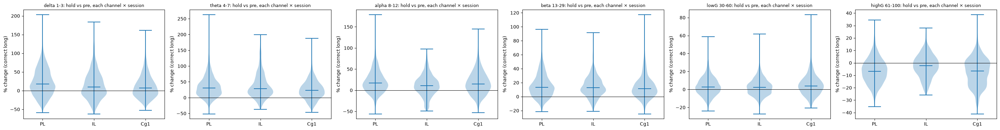

In [77]:
# needs 1.0, 1.3 (BP), 1.12 (REGIONS, RM, MIN_CH, MIN_CL, BANDS, rat_of)
from scipy import stats as _st
HB = list(lfm.MAIN_BANDS)                    # bands shown
DIST_BINS = [0, 50, 150, 300, 600, 1200, 1e9]                       # µm, same shank
het, simrows = [], []
for s, r in BP.items():
    cl = lfm.main_conditions(r["trials"])["correct long"].values
    if cl.sum() < MIN_CL:
        continue
    x, y = np.asarray(r["meta"]["x"]), np.asarray(r["meta"]["y"]); sh = (x // 250).astype(int)
    for b in HB:
        D = r["logpow"][b]["hold"][cl] - r["logpow"][b]["pre"][cl]          # (trials, channels), log10
        eff = np.nanmean(D, axis=0)                                          # per-channel effect
        t, p = _st.ttest_1samp(D, 0, axis=0, nan_policy="omit")              # per channel, across trials (descriptive)
        for reg, m in RM[s].items():
            if m.sum() < MIN_CH:
                continue
            e = 100 * (10 ** eff[m] - 1)
            het.append({"session": s, "rat": rat_of(s), "region": reg, "band": b, "n_ch": int(m.sum()),
                        "median %": float(np.median(e)), "IQR %": float(np.subtract(*np.percentile(e, [75, 25]))),
                        "% ch > 0": 100 * np.mean(e > 0),
                        "% ch sig up": 100 * np.mean((np.asarray(p)[m] < 0.05) & (eff[m] > 0)),
                        "% ch sig down": 100 * np.mean((np.asarray(p)[m] < 0.05) & (eff[m] < 0))})
        # similarity: correlation across trials of the per-trial effect, for channel pairs by distance
        if b in ("theta 4-7", "beta 13-29"):
            ok = np.isfinite(D).all(axis=0)
            C = np.corrcoef(D[:, ok].T); xx, yy, ss = x[ok], y[ok], sh[ok]
            iu = np.triu_indices(len(xx), 1)
            same = ss[iu[0]] == ss[iu[1]]; dy = np.abs(yy[iu[0]] - yy[iu[1]]); cc = C[iu]
            for lo, hi in zip(DIST_BINS[:-1], DIST_BINS[1:]):
                k = same & (dy >= lo) & (dy < hi)
                if k.any():
                    simrows.append({"session": s, "rat": rat_of(s), "band": b, "pair": f"same shank {lo:g}–{hi:g} µm" if hi < 1e8 else f"same shank > {lo:g} µm",
                                    "median r": float(np.median(cc[k]))})
            if (~same).any():
                simrows.append({"session": s, "rat": rat_of(s), "band": b, "pair": "different shanks", "median r": float(np.median(cc[~same]))})
HET, SIM = pd.DataFrame(het), pd.DataFrame(simrows)
HET.to_csv(os.path.join(BP_DIR, "_channel_heterogeneity_M1.csv"), index=False)
SIM.to_csv(os.path.join(BP_DIR, "_channel_similarity_M1.csv"), index=False)
pd.set_option("display.width", 250)
print("PER-CHANNEL SPREAD of M1 hold − pre (correct long): median over sessions of each column")
print(HET.groupby(["band", "region", "rat"])[["n_ch", "median %", "IQR %", "% ch > 0", "% ch sig up", "% ch sig down"]]
         .median().round(1).to_string())
print("\nSIMILARITY of channels (correlation across trials of hold − pre), median over sessions:")
order = [p for p in SIM["pair"].unique()]
print(SIM.pivot_table(index=["band", "pair"], columns="rat", values="median r", aggfunc="median").reindex(order, level=1).round(2).to_string())

# figure: distribution of per-channel effects (all sessions × channels) per region, theta / beta / high gamma
fig, axes = plt.subplots(1, len(HB), figsize=(5 * len(HB), 4), squeeze=False)
for ax, b in zip(axes[0], HB):
    vals = []
    for reg in REGIONS:
        e = []
        for s, r in BP.items():
            cl = lfm.main_conditions(r["trials"])["correct long"].values
            m = RM[s][reg]
            if cl.sum() < MIN_CL or m.sum() < MIN_CH:
                continue
            e.append(100 * (10 ** np.nanmean(r["logpow"][b]["hold"][cl][:, m] - r["logpow"][b]["pre"][cl][:, m], axis=0) - 1))
        vals.append(np.concatenate(e) if e else np.array([np.nan]))
    ax.violinplot([v[np.isfinite(v)] for v in vals], showmedians=True)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(1, len(REGIONS) + 1)); ax.set_xticklabels(list(REGIONS))
    ax.set_title(f"{b}: hold vs pre, each channel × session", fontsize=9); ax.set_ylabel("% change (correct long)")
fig.tight_layout(); fig.savefig(os.path.join(BP_DIR, "_channel_heterogeneity_M1.png"), dpi=150, bbox_inches="tight"); plt.show()

## 1.13b REPRESENTATIVE CHANNELS: chosen by a fixed rule (not by results), then same numbers + plots ──

SELECTED channels (rule fixed before looking at results):
 rat region   x    y  shank  dv_mm  n_sessions  dist_border_um
134    Cg1 750 3105      3  -3.04           2           315.0
134     IL 250  375      1  -5.73           3           465.0
134     PL 532 1845      2  -4.28           4           975.0
135    Cg1 250 4020      1  -2.79          13           465.0
135     IL   0 1065      0  -5.70           8           555.0
135     PL 282 2145      1  -4.63          13           540.0
136    Cg1  32 3255      0  -2.81           5           480.0
136     IL 250  585      1  -5.44           8           330.0
136     PL 250 2430      1  -3.62           6           360.0

M1 (correct long), single channel vs region median — mean % across sessions [raw sign-flip p] (n sessions):
rat region channel (x,y)         band     measure  single channel %   p ch  n ch  region median %  p region  n region
134    Cg1    (750,3105)    delta 1-3  hold − pre              10.8 0.4882     2             2

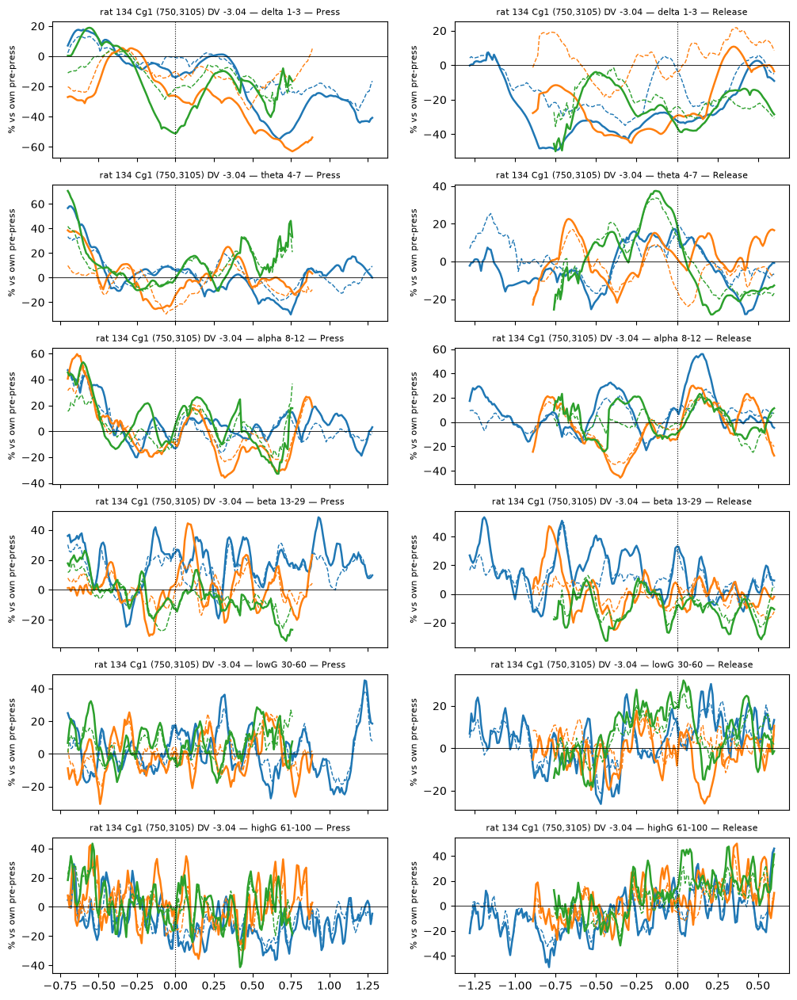

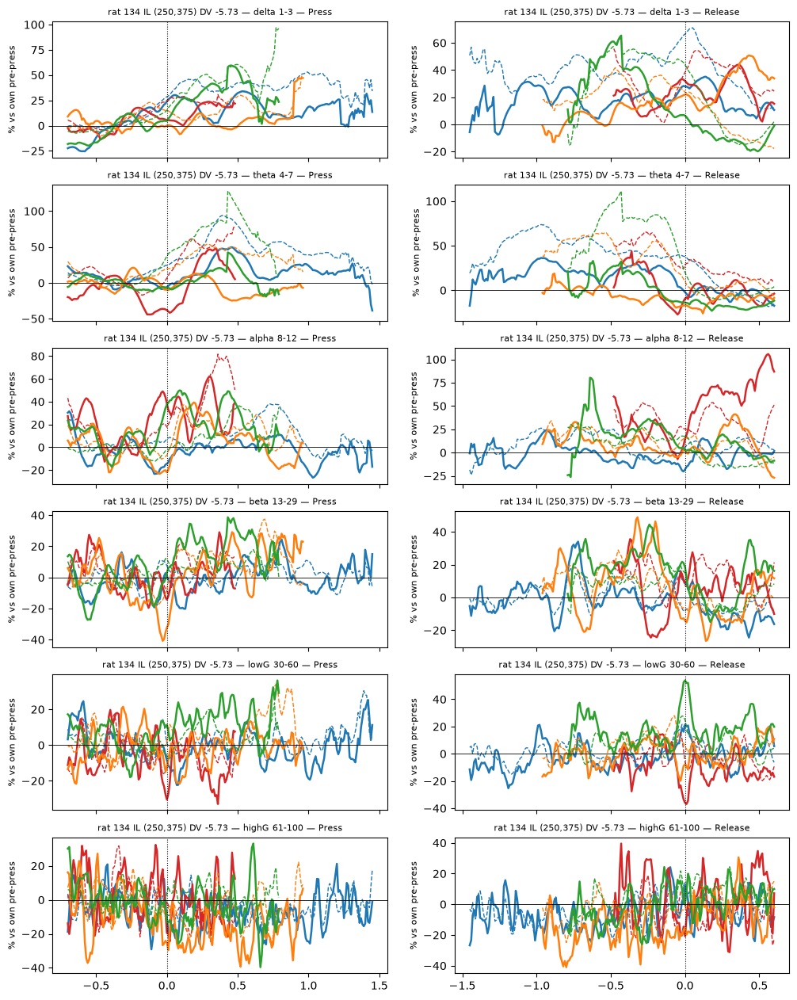

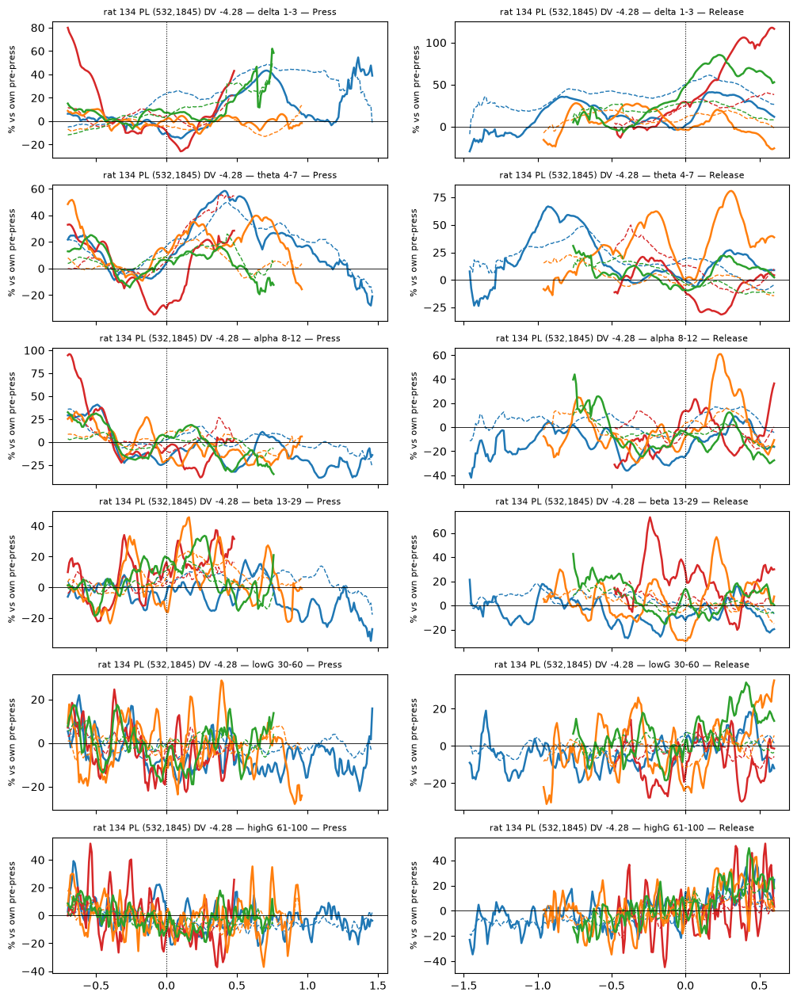

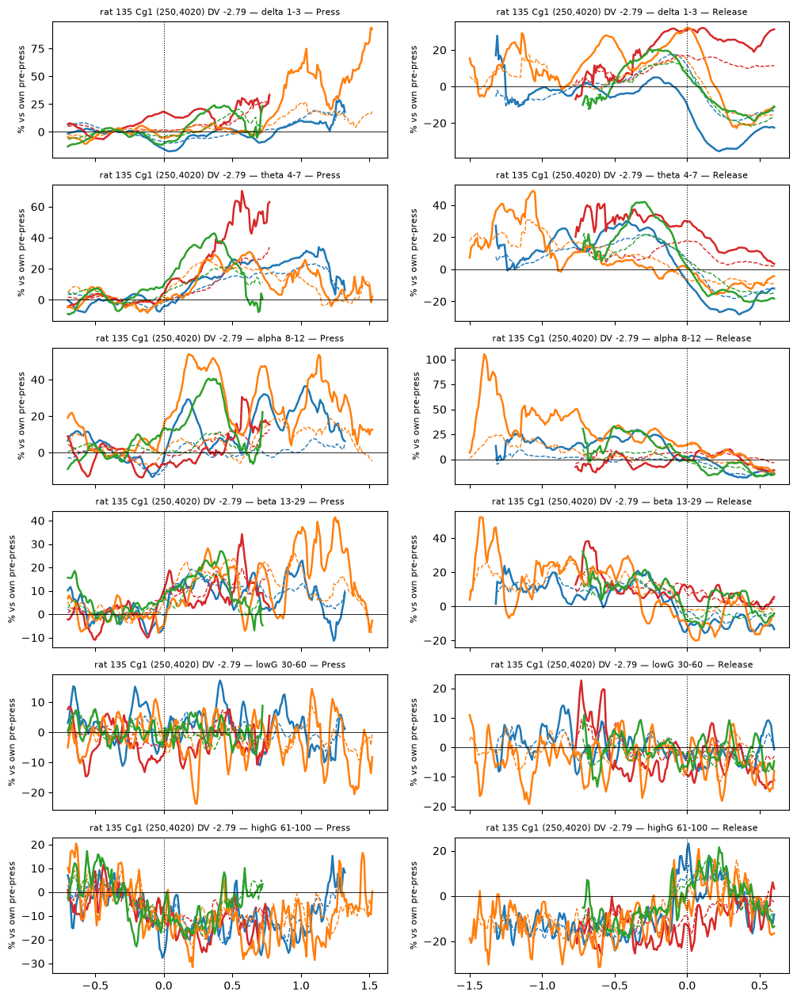

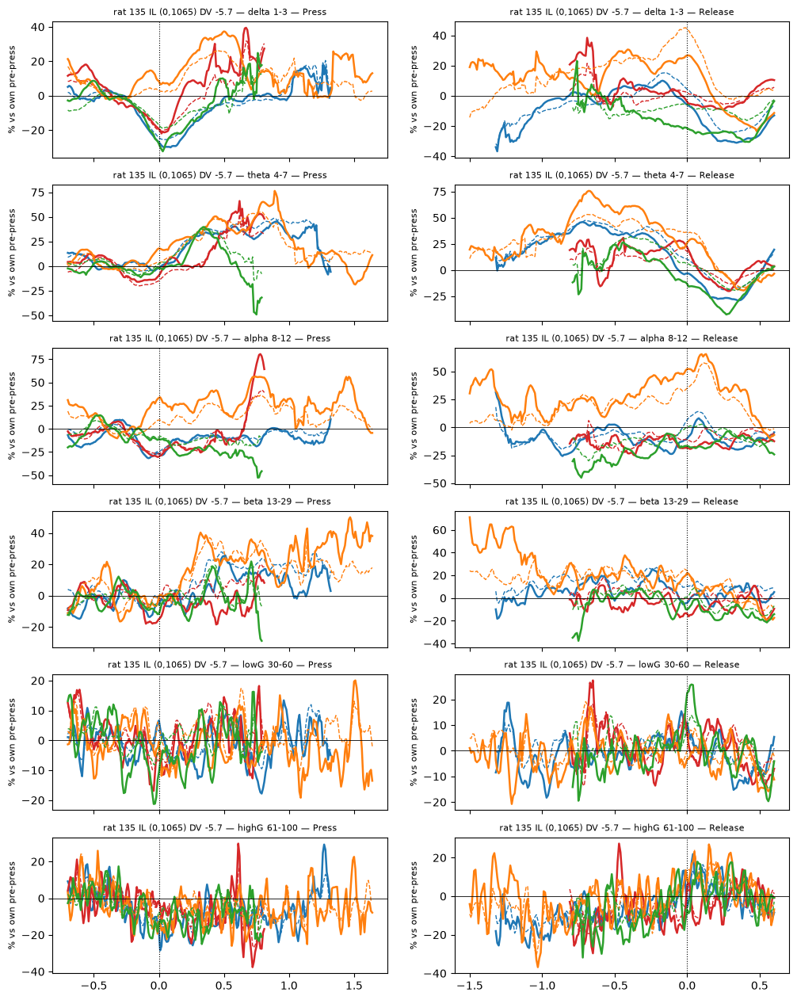

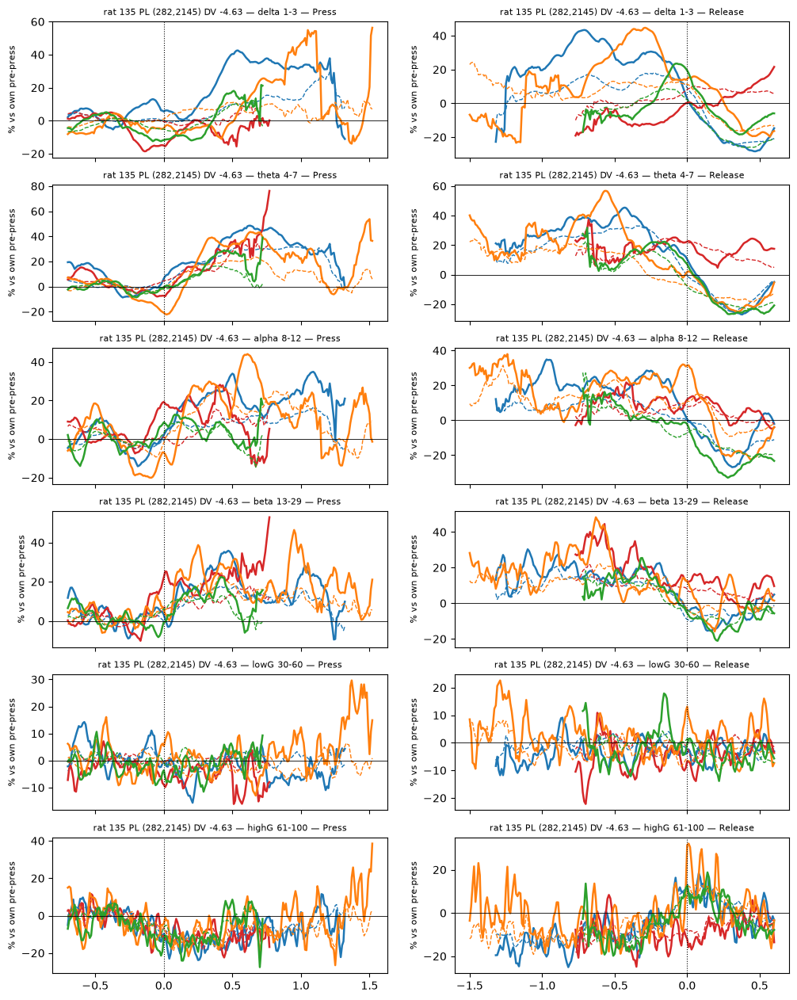

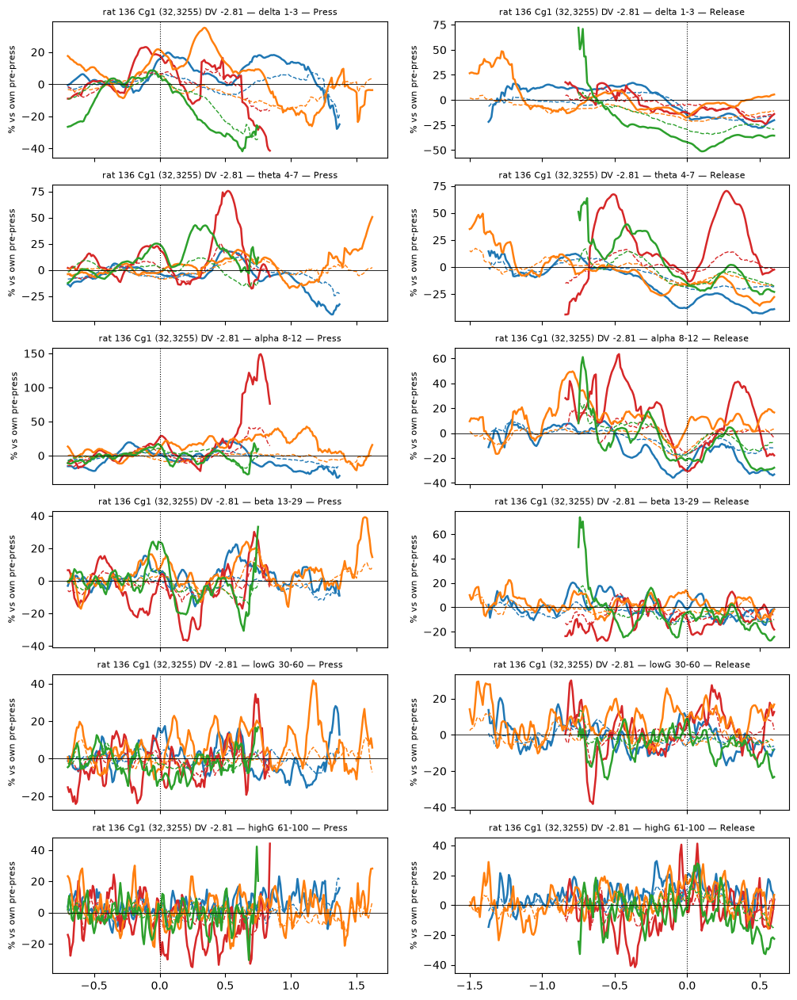

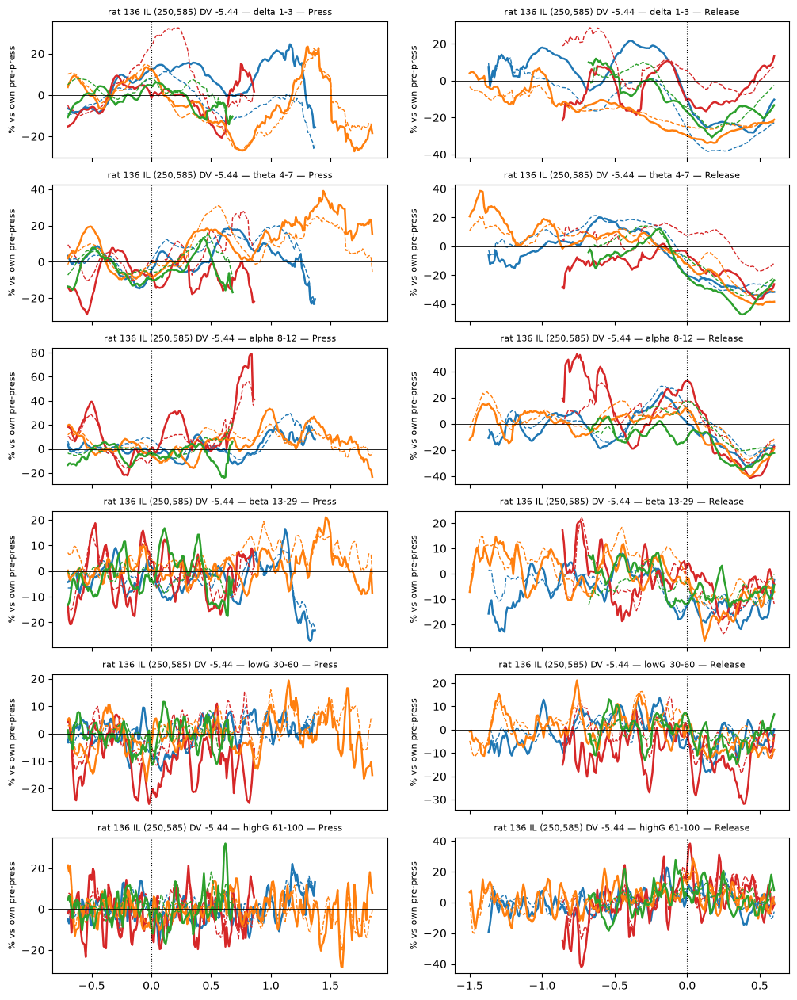

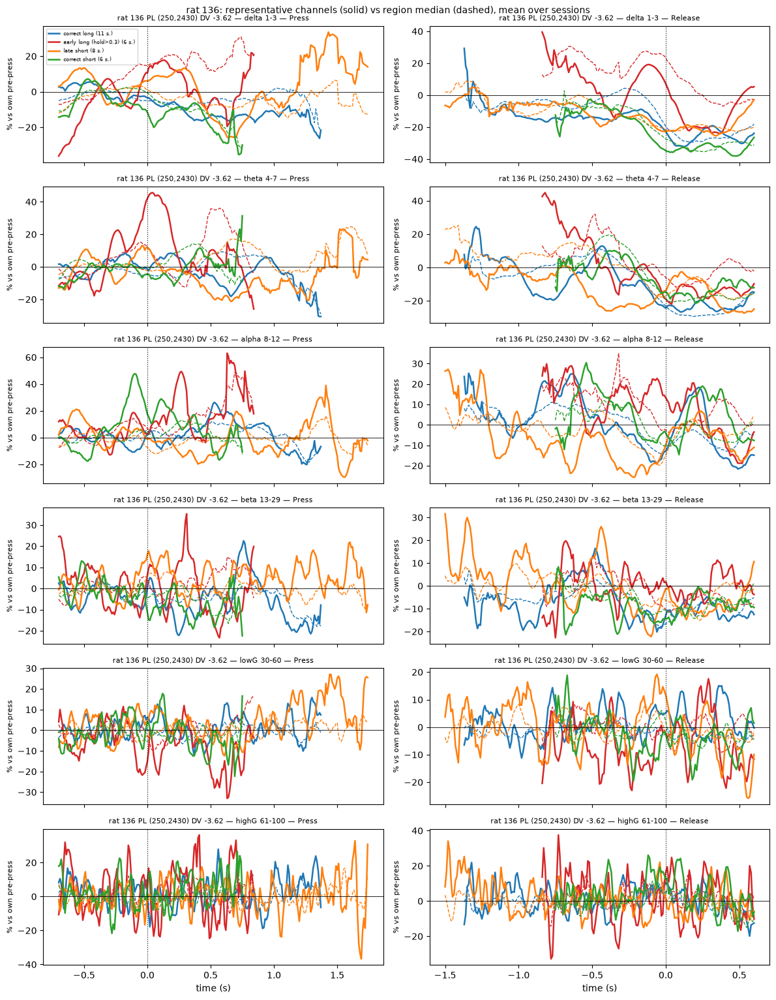

In [78]:
N_PER, MIN_BORDER, MIN_SEP = 1, 200, 300
POS = []
for s, r in BP.items():
    cl = lfm.main_conditions(r["trials"])["correct long"].values
    if cl.sum() < MIN_CL:
        continue
    c = CH_REG[CH_REG.session == s]
    POS.append(c.assign(rat=rat_of(s)))
POS = pd.concat(POS)
POS["xi"], POS["yi"] = POS.x.round().astype(int), POS.y.round().astype(int)
POS["shank"] = POS.xi // 250
cand = POS.groupby(["rat", "region", "xi", "yi", "shank"], as_index=False).agg(n_sess=("session", "nunique"), dv=("dv_mm", "mean"))
SEL = []
for (rat, reg_full), d in cand[cand.region.isin(REGIONS.values())].groupby(["rat", "region"]):
    other = POS[(POS.rat == rat) & (POS.region != reg_full)][["shank", "yi"]].drop_duplicates()
    d = d.copy()
    d["dist_border"] = [np.abs(other.loc[other.shank == sh, "yi"] - yy).min() if (other.shank == sh).any() else np.inf
                        for sh, yy in zip(d.shank, d.yi)]
    d2 = d[(d.dist_border >= MIN_BORDER) & (d.n_sess >= 0.8 * d.n_sess.max())]
    d = d2 if len(d2) else d[d.dist_border >= MIN_BORDER].nlargest(5, "n_sess")   # fallback: most-recorded positions away from borders
    if d.empty:
        continue
    d = d.iloc[np.argsort(np.abs(d.dv.values - d.dv.median()))]
    picked = []
    for _, row in d.iterrows():
        if all(np.hypot(row.xi - p.xi, row.yi - p.yi) >= MIN_SEP for p in picked):
            picked.append(row)
        if len(picked) == N_PER:
            break
    for p in picked:
        SEL.append({"rat": rat, "region": [k for k, v in REGIONS.items() if v == reg_full][0], "x": p.xi, "y": p.yi,
                    "shank": p.shank, "dv_mm": round(p.dv, 2), "n_sessions": p.n_sess, "dist_border_um": p.dist_border})
SEL = pd.DataFrame(SEL)
SEL.to_csv(os.path.join(BP_DIR, "_representative_channels.csv"), index=False)
print("SELECTED channels (rule fixed before looking at results):\n", SEL.to_string(index=False))

def ch_index(r, x, y):
    k = np.where((np.round(r["meta"]["x"]).astype(int) == x) & (np.round(r["meta"]["y"]).astype(int) == y))[0]
    return int(k[0]) if len(k) else None

# numbers: M1 for each selected channel vs the region median, same sessions
rows = []
for _, ch in SEL.iterrows():
   for b in BANDS:
        v_ch, v_reg = [], []
        for s, r in BP.items():
            if rat_of(s) != ch.rat:
                continue
            cl = lfm.main_conditions(r["trials"])["correct long"].values; k = ch_index(r, ch.x, ch.y)
            if cl.sum() < MIN_CL or k is None:
                continue
            L = r["logpow"][b]
            for meas, w in (("hold − pre", "pre"), ("hold − post", "post")):
                d = L["hold"][cl] - L[w][cl]
                v_ch.append((meas, float(np.nanmean(d[:, k]))))
                if RM[s][ch.region].sum() >= MIN_CH:
                    v_reg.append((meas, float(np.median(np.nanmean(d[:, RM[s][ch.region]], axis=0)))))
        for meas in ("hold − pre", "hold − post"):
            a = np.array([v for mm, v in v_ch if mm == meas]); g = np.array([v for mm, v in v_reg if mm == meas])
            m1, p1, n1 = lfm.sign_flip_p(a); m2, p2, n2 = lfm.sign_flip_p(g)
            rows.append({"rat": ch.rat, "region": ch.region, "channel (x,y)": f"({ch.x},{ch.y})", "band": b, "measure": meas,
                         "single channel %": round(100 * (10 ** m1 - 1), 1), "p ch": round(p1, 4), "n ch": n1,
                         "region median %": round(100 * (10 ** m2 - 1), 1), "p region": round(p2, 4), "n region": n2})
R13b = pd.DataFrame(rows); R13b.to_csv(os.path.join(BP_DIR, "_representative_channels_M1.csv"), index=False)
print("\nM1 (correct long), single channel vs region median — mean % across sessions [raw sign-flip p] (n sessions):")
print(R13b.to_string(index=False))

# figure: time courses of the selected channels (Press + Release), theta and beta, 4 conditions; dashed = region median
# a time point is drawn only if >= 5 trials are still holding in a session and >= half of the sessions (min 3) have data
CONDF = {"correct long": "tab:blue", "early long (hold>0.3)": "tab:red", "late short": "tab:orange", "correct short": "tab:green"}
for _, ch_row in SEL.iterrows():
       rat, sel_r = ch_row.rat, SEL.loc[[_]]
       fig, axes = plt.subplots(len(BANDS), 2, figsize=(12, 2.6 * len(BANDS)), squeeze=False, sharex="col")
       for i, (_, ch) in enumerate(sel_r.iterrows()):
           for j, b in enumerate(BANDS):
            for col, al in enumerate(["Press", "Release"]):
                ax = axes[2 * i + j, col]
                t = BP[next(iter(BP))]["times"][al]
                for c, colr in CONDF.items():
                    cur_ch, cur_rg = [], []
                    for s, r in BP.items():
                        if rat_of(s) != rat:
                            continue
                        k = ch_index(r, ch.x, ch.y); mk = lfm.main_conditions(r["trials"])[c]
                        if k is None or mk.sum() < MIN_TR:
                            continue
                        ok = r["counts"][al][c] >= 5                                  # >= 5 trials still holding
                        cur_ch.append(np.where(ok, r["curves"][al][b][c][k], np.nan))
                        if RM[s][ch.region].sum() >= MIN_CH:
                            with lfm.warnings_off():
                                cur_rg.append(np.where(ok, np.nanmedian(r["curves"][al][b][c][RM[s][ch.region]], axis=0), np.nan))
                    if len(cur_ch) < 3:
                        continue
                    with lfm.warnings_off():
                        A = np.array(cur_ch); good = np.isfinite(A).sum(0) >= max(3, 0.5 * len(A))
                        ax.plot(t, np.where(good, 100 * (10 ** np.nanmean(A, 0) - 1), np.nan), color=colr, lw=1.8,
                                label=f"{c} ({len(cur_ch)} s.)")
                        if cur_rg:
                            G = np.array(cur_rg); good = np.isfinite(G).sum(0) >= max(3, 0.5 * len(G))
                            ax.plot(t, np.where(good, 100 * (10 ** np.nanmean(G, 0) - 1), np.nan), color=colr, lw=1, ls="--")
                ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", ls=":", lw=0.8)
                ax.set_title(f"rat {rat} {ch.region} ({ch.x},{ch.y}) DV {ch.dv_mm} — {b} — {al}", fontsize=8)
                ax.set_ylabel("% vs own pre-press", fontsize=8)
axes[0, 0].legend(fontsize=6)
for a in axes[-1]:
        a.set_xlabel("time (s)")
fig.suptitle(f"rat {rat}: representative channels (solid) vs region median (dashed), mean over sessions", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(BP_DIR, f"_representative_channels_rat_{rat}.png"), dpi=130, bbox_inches="tight")
plt.show()

## 1.14 region DIFFERENCES: IL − PL, Cg1 − PL, IL − Cg1 (paired within session) 


In [81]:
# Uses only the session values of 1.12 (saved csv), no band_power files needed.
VAL12 = pd.read_csv(os.path.join(BP_DIR, "_session_values_1_12_regions.csv"))
PAIRS = [("IL", "PL"), ("Cg1", "PL"), ("IL", "Cg1")]
rows13 = []
for meas, d in VAL12.groupby("measure", sort=False):
    W = d.pivot_table(index=["session", "band"], columns="region", values="value_log10")
    for a, z in PAIRS:
        if a not in W or z not in W:
            continue
        diff = (W[a] - W[z]).dropna()                      # only sessions with BOTH regions (>= MIN_CH each)
        vals = [(s, b, v) for (s, b), v in diff.items()]
        rows13 += sf_rows(vals, meas, f"{a} − {z}")
S13 = pd.DataFrame(rows13).rename(columns={"condition": "pair"})
S13.to_csv(os.path.join(BP_DIR, "_stats_1_13_region_differences.csv"), index=False)

S13["cell"] = S13.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})"
                        if x["n_sessions"] >= 2 else "—", axis=1)
pd.set_option("display.width", 250)
for meas, d in S13.groupby("measure", sort=False):
    print(f"\n===== {meas}: region A − region B, same session — mean % [raw p] (n sessions) =====")
    tab = d.pivot_table(index="band", columns=["pair", "rat"], values="cell", aggfunc="first").reindex(BANDS)
    order = [(f"{a} − {z}", r) for a, z in PAIRS for r in ["all", "134", "135", "136"] if (f"{a} − {z}", r) in tab.columns]
    print(tab[order].to_string())


===== Q1 pre_release − pre (EL): region A − region B, same session — mean % [raw p] (n sessions) =====
pair                    IL − PL                                                                     Cg1 − PL                                                                     IL − Cg1                                                          
rat                         all                134                 135                136                all                134                135                136                 all                134                 135                136
band                                                                                                                                                                                                                                               
delta 1-3     -6.4 [0.216] (35)   +6.1 [0.873] (4)  -10.4 [0.022] (23)   -0.4 [0.961] (8)  -0.6 [0.876] (32)  -13.2 [0.742] (3)  +5.7 [0.097] (23)  -16.1 [0.032] (6

## 1.15 per-channel values + REGION vs DEPTH (border test, within-region depth slope) ──

In [73]:
# ── 1.15 per-channel values + REGION vs DEPTH (border test, within-region depth slope) ──
# needs 1.0, 1.3 (BP), 1.12 (REGIONS, CH_REG, MIN_CH, MIN_CL, sf_rows, BANDS); bad channels from XB are left out
assert "dv_mm" in CH_REG.columns, "channel_regions_all.csv has no dv_mm -> rerun P1 in the session-info notebook"
BORDER_UM, MIN_SIDE = 300, 5
rows = []
for s, r in BP.items():
    T = r["trials"]
    cl = lfm.main_conditions(T)["correct long"].values
    if cl.sum() < MIN_CL:
        continue
    c = CH_REG[CH_REG["session"] == s]
    pos = {(int(round(a)), int(round(b))): (g, d) for a, b, g, d in zip(c["x"], c["y"], c["region"], c["dv_mm"])}
    x, y = np.asarray(r["meta"]["x"]), np.asarray(r["meta"]["y"])
    reg_dv = [pos.get((int(round(a)), int(round(b))), ("NOT IN TABLE", np.nan)) for a, b in zip(x, y)]
    bad = np.isin(r["meta"]["channel_ids"], XB.loc[XB.session == s, "channel_id"].tolist())   # unreliable channels
    for b in BANDS:
        L = r["logpow"][b]
        d_pre = np.nanmean(L["hold"][cl] - L["pre"][cl], axis=0)
        d_post = np.nanmean(L["hold"][cl] - L["post"][cl], axis=0)
        rows.append(pd.DataFrame({"session": s, "rat": rat_of(s), "band": b, "channel": r["meta"]["channel_ids"],
                                  "x": x, "y": y, "shank": (x // 250).astype(int),
                                  "region": [g for g, _ in reg_dv], "dv_mm": [d for _, d in reg_dv],
                                  "hold-pre": d_pre, "hold-post": d_post})[~bad])
CHV = pd.concat(rows, ignore_index=True)
CHV.to_csv(os.path.join(BP_DIR, "_channel_values_M1_regions.csv"), index=False)

# (a) border test: IL just below vs PL just above the IL/PL border (same shank), and far from it
IL_, PL_ = REGIONS["IL"], REGIONS["PL"]
bt = {}
for (s, b), d in CHV.groupby(["session", "band"]):
    near_il, near_pl, far_il, far_pl = [], [], [], []
    for sh, e in d.groupby("shank"):
        il, pl = e[e.region == IL_], e[e.region == PL_]
        if len(il) == 0 or len(pl) == 0:
            continue
        border = (il["y"].max() + pl["y"].min()) / 2                     # probe y of the border on this shank
        near_il.append(il[il.y >= border - BORDER_UM]); near_pl.append(pl[pl.y <= border + BORDER_UM])
        far_il.append(il[il.y < border - BORDER_UM]);   far_pl.append(pl[pl.y > border + BORDER_UM])
    for lab, A, Z in (("near border (±300 µm)", near_il, near_pl), ("far from border (>300 µm)", far_il, far_pl)):
        A = pd.concat(A) if A else pd.DataFrame(); Z = pd.concat(Z) if Z else pd.DataFrame()
        if len(A) >= MIN_SIDE and len(Z) >= MIN_SIDE:
            for meas in ("hold-pre", "hold-post"):
                bt.setdefault((f"IL − PL {meas}, {lab}"), []).append((s, b, float(A[meas].median() - Z[meas].median())))
rows15 = []
for meas, v in bt.items():
    rows15 += sf_rows(v, meas, "border test")
# (b) slope within a region: change per 1 mm more DORSAL (dv_mm up), per session -> sign-flip
for reg_name, reg_full in REGIONS.items():
    for meas in ("hold-pre", "hold-post"):
        v = []
        for (s, b), d in CHV[CHV.region == reg_full].groupby(["session", "band"]):
            d = d.dropna(subset=["dv_mm", meas])
            if len(d) >= MIN_CH and d["dv_mm"].std() > 0.02:
                v.append((s, b, float(np.polyfit(d["dv_mm"], d[meas], 1)[0])))
        rows15 += sf_rows(v, f"slope within {reg_name}: {meas} per 1 mm dorsal", "depth slope")
S15 = pd.DataFrame(rows15)
S15.to_csv(os.path.join(BP_DIR, "_stats_1_15_border_depth.csv"), index=False)
S15["cell"] = S15.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})" if x["n_sessions"] >= 2 else "—", axis=1)
pd.set_option("display.width", 250)
for meas, d in S15[S15.n_sessions > 0].groupby("measure", sort=False):
    print(f"\n===== {meas} — mean % [raw p] (n sessions) =====")
    tab = d.pivot_table(index="band", columns="rat", values="cell", aggfunc="first").reindex(BANDS)
    print(tab[[c for c in ["all", "134", "135", "136"] if c in tab.columns]].to_string())


===== IL − PL hold-pre, near border (±300 µm) — mean % [raw p] (n sessions) =====
rat                         all                134                 135                136
band                                                                                     
delta 1-3     +2.2 [0.567] (29)  +12.7 [0.379] (5)   -5.8 [0.257] (15)  +10.7 [0.070] (9)
theta 4-7     -2.7 [0.434] (29)   +5.8 [0.686] (5)   -6.1 [0.288] (15)   -1.4 [0.249] (9)
alpha 8-12    -5.6 [0.049] (29)   +8.8 [0.379] (5)  -12.7 [0.002] (15)   -0.6 [0.735] (9)
beta 13-29    -0.3 [0.844] (29)   +0.2 [1.000] (5)   +1.1 [0.593] (15)   -2.8 [0.008] (9)
lowG 30-60    -2.1 [0.058] (29)   -3.2 [0.126] (5)   -2.5 [0.168] (15)   -0.6 [0.695] (9)
highG 61-100  +0.3 [0.744] (29)   +4.2 [0.192] (5)   -1.3 [0.446] (15)   +1.0 [0.398] (9)

===== IL − PL hold-post, near border (±300 µm) — mean % [raw p] (n sessions) =====
rat                         all                134                135               136
band                     

3052 contacts found
300/3052 contacts
600/3052 contacts
900/3052 contacts
1200/3052 contacts
1500/3052 contacts
1800/3052 contacts
2100/3052 contacts
2400/3052 contacts
2700/3052 contacts
3000/3052 contacts
rat 134: 845 contacts | median 2 sessions, 49 trials per contact | P<0.05 hold vs before: 62 % | hold vs after: 67 %
rat 135: 1197 contacts | median 5 sessions, 104 trials per contact | P<0.05 hold vs before: 65 % | hold vs after: 87 %
rat 136: 1010 contacts | median 3 sessions, 60 trials per contact | P<0.05 hold vs before: 39 % | hold vs after: 77 %


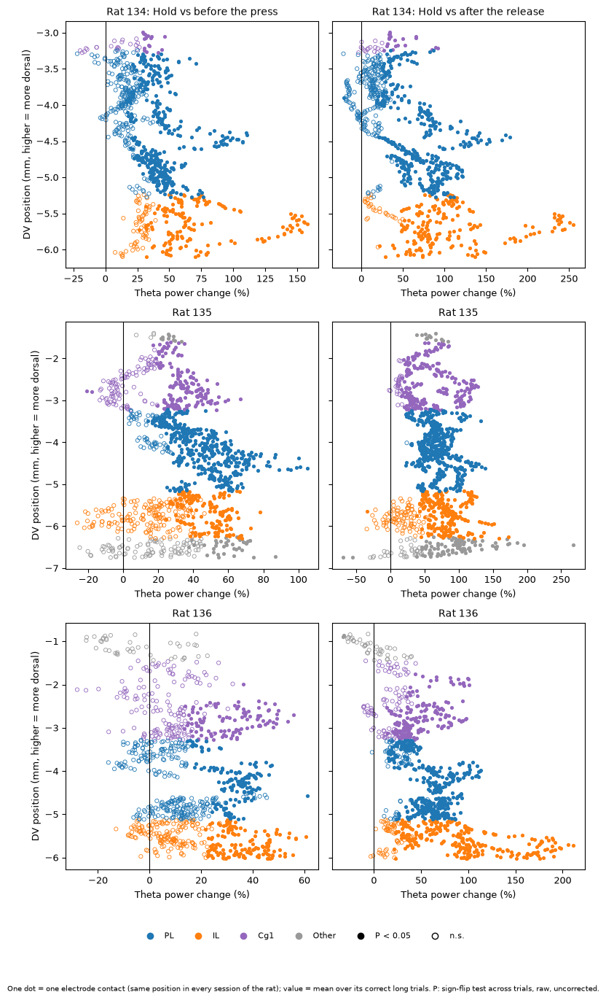

saved on C:\Users\ar687\Desktop


In [59]:
# ── Option B2: one dot = one electrode contact (same x,y within a rat), trial-level sign-flip, theta 4-7 ──
# all contacts of each rat; trials pooled over the sessions in which the contact was recorded. Needs 1.0, 1.3 (+1.3b), 1.4 (MIN_CL).
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
BAND, MIN_TR = "theta 4-7", 20
RATS_B = ["134", "135", "136"]
CH_REG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
assert "dv_mm" in CH_REG.columns, "channel_regions_all.csv has no dv_mm"

acc = {}                                              # (rat, x, y) -> trial values and session list
for s, r in BP.items():
    rat = rat_of(s)
    if rat not in RATS_B:
        continue
    T = r["trials"]; cl = lfm.main_conditions(T)["correct long"].values
    if cl.sum() < MIN_CL:
        continue
    c = CH_REG[CH_REG["session"] == s]
    pos = {(int(round(a)), int(round(b))): (g, d) for a, b, g, d in zip(c["x"], c["y"], c["region"], c["dv_mm"])}
    x, y = np.asarray(r["meta"]["x"]), np.asarray(r["meta"]["y"])
    xi, yi = np.round(x).astype(int), np.round(y).astype(int)
    bad = np.isin(r["meta"]["channel_ids"], XB.loc[XB.session == s, "channel_id"].tolist())
    L = r["logpow"][BAND]
    D_pre, D_post = L["hold"][cl] - L["pre"][cl], L["hold"][cl] - L["post"][cl]     # (trials, contacts), log10
    for j in np.where(~bad)[0]:
        g, d = pos.get((int(xi[j]), int(yi[j])), ("NOT IN TABLE", np.nan))
        a = acc.setdefault((rat, int(xi[j]), int(yi[j])), {"pre": [], "post": [], "sess": set(), "reg": [], "dv": []})
        a["pre"].append(D_pre[:, j]); a["post"].append(D_post[:, j]); a["sess"].add(s); a["reg"].append(g); a["dv"].append(d)
print(len(acc), "contacts found")

res = []
for n_done, ((rat, x, y), a) in enumerate(acc.items(), 1):
    vp = np.concatenate(a["pre"]);  vp = vp[np.isfinite(vp)]
    vq = np.concatenate(a["post"]); vq = vq[np.isfinite(vq)]
    if len(vp) < MIN_TR:
        continue
    out = {"rat": rat, "x": x, "y": y, "n_trials": len(vp), "n_sessions": len(a["sess"]),
           "region": pd.Series(a["reg"]).mode().iat[0], "dv_mm": float(np.nanmean(a["dv"]))}
    mp, pp, _ = lfm.sign_flip_p(vp, n_perm=2000)
    out["pct_pre"], out["p_pre"] = 100 * (10 ** mp - 1), pp
    if len(vq) >= MIN_TR:
        mq, pq, _ = lfm.sign_flip_p(vq, n_perm=2000)
        out["pct_post"], out["p_post"] = 100 * (10 ** mq - 1), pq
    else:
        out["pct_post"], out["p_post"] = np.nan, np.nan
    res.append(out)
    if n_done % 300 == 0:
        print(f"{n_done}/{len(acc)} contacts", flush=True)
R = pd.DataFrame(res)
R.to_csv(os.path.join(BP_DIR, "_contact_values_theta_trials.csv"), index=False)

for rat, er in R.groupby("rat"):                      # share filled (chance would be about 5 %)
    print(f"rat {rat}: {len(er)} contacts | median {er.n_sessions.median():.0f} sessions, {er.n_trials.median():.0f} trials per contact | "
          f"P<0.05 hold vs before: {(er.p_pre < 0.05).mean() * 100:.0f} % | hold vs after: {(er.p_post < 0.05).mean() * 100:.0f} %")

REGCOL = {"Prelimbic area": "tab:blue", "Infralimbic area": "tab:orange", "Cingulate area 1": "tab:purple"}
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(len(RATS_B), 2, figsize=(8, 4.3 * len(RATS_B)), sharey="row", squeeze=False)
for i, rat in enumerate(RATS_B):
    er = R[R.rat == rat]
    for j, (k, ttl) in enumerate((("pre", "Hold vs before the press"), ("post", "Hold vs after the release"))):
        ax = axes[i, j]
        for g, eg in er.groupby("region"):
            col = REGCOL.get(g, "0.6"); sig = eg[f"p_{k}"] < 0.05
            ax.scatter(eg.loc[~sig, f"pct_{k}"], eg.loc[~sig, "dv_mm"], s=14, facecolors="none", edgecolors=col, linewidths=0.6)
            ax.scatter(eg.loc[sig, f"pct_{k}"], eg.loc[sig, "dv_mm"], s=14, color=col, linewidths=0)
        ax.axvline(0, color="k", lw=0.8)
        ax.set_title(f"Rat {rat}: {ttl}" if i == 0 else f"Rat {rat}", fontsize=10)
        ax.set_xlabel("Theta power change (%)")
        if j == 0:
            ax.set_ylabel("DV position (mm, higher = more dorsal)")
leg = [Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in (("PL", "tab:blue"), ("IL", "tab:orange"), ("Cg1", "tab:purple"), ("Other", "0.6"))]
leg += [Line2D([], [], marker="o", ls="", color="k", label="P < 0.05"), Line2D([], [], marker="o", ls="", mfc="none", mec="k", label="n.s.")]
fig.legend(handles=leg, loc="lower center", ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.text(0.5, -0.05, "One dot = one electrode contact (same position in every session of the rat); value = mean over its correct long trials. "
         "P: sign-flip test across trials, raw, uncorrected.", ha="center", va="top", fontsize=7)
fig.tight_layout(rect=(0, 0.03, 1, 1))
desk = os.path.join(os.path.expanduser("~"), "Desktop")
if not os.path.isdir(desk): desk = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop")
fig.savefig(os.path.join(desk, "theta_contacts_depth_trials.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(desk, "theta_contacts_depth_trials_white.png"), dpi=600, facecolor="white", bbox_inches="tight")
plt.show(); print("saved on", desk)

In [60]:
print(R[["rat", "x", "y", "region", "n_sessions", "n_trials", "pct_pre", "pct_post"]]
      .sort_values("pct_pre", ascending=False).head(15).round(1).to_string(index=False))
print(R[["pct_pre", "pct_post"]].describe().round(1))

rat   x   y           region  n_sessions  n_trials  pct_pre  pct_post
134 282 465 Infralimbic area           1        28    157.8     237.5
134 282 480 Infralimbic area           1        28    155.7     251.0
134 282 495 Infralimbic area           1        28    155.0     240.4
134 282 570 Infralimbic area           1        28    153.5     241.8
134 282 345 Infralimbic area           1        28    153.3     213.5
134 282 375 Infralimbic area           1        28    151.8     242.1
134 282 525 Infralimbic area           1        28    151.1     236.5
134 282 450 Infralimbic area           1        28    149.8     255.1
134 282 510 Infralimbic area           1        28    149.3     236.0
134 282 585 Infralimbic area           1        28    148.4     237.8
134 282 555 Infralimbic area           1        28    147.1     232.4
134 282 540 Infralimbic area           1        28    146.1     239.3
134 282 405 Infralimbic area           1        28    146.0     232.5
134 282 360 Infralim

## 1.16: is the bigger theta drop after the release in IL tied to reward?

In [82]:
# only correct trials are rewarded (checked: early 0/3,376, late 0/1,609 rewarded)
CONDS16 = ["correct long", "correct short", "early long (hold>0.3)", "early short", "late short", "late long"]
q2 = {}                                                                    # (cond, region) -> {(s, b): value}
for s, r in BP.items():
    C = lfm.main_conditions(r["trials"])
    for cond in CONDS16:
        mk = C[cond].values
        if mk.sum() < MIN_TR:
            continue
        for reg, m in RM[s].items():
            if m.sum() < MIN_CH:
                continue
            for b in BANDS:
                L = r["logpow"][b]
                q2.setdefault((cond, reg), {})[(s, b)] = med(L["post"][mk] - L["pre_release"][mk], m)
def pair_diff(cond, a, z):
    A, Z = q2.get((cond, a), {}), q2.get((cond, z), {})
    return {k: A[k] - Z[k] for k in A if k in Z}
rows16 = []
for cond in CONDS16:                                                       # region difference per condition
    for a, z in PAIRS:
        D = pair_diff(cond, a, z)
        rows16 += sf_rows([(s, b, v) for (s, b), v in D.items()], f"{a} − {z}: post − pre_release", cond)
for rew, nrew in (("correct long", "early long (hold>0.3)"), ("correct short", "late short")):   # rewarded vs not
    for a, z in PAIRS:
        R_, N_ = pair_diff(rew, a, z), pair_diff(nrew, a, z)
        v = [(s, b, R_[(s, b)] - N_[(s, b)]) for (s, b) in R_ if (s, b) in N_]
        rows16 += sf_rows(v, f"({a} − {z}) rewarded − not: post − pre_release", f"{rew} vs {nrew}")
S16 = pd.DataFrame(rows16)
S16.to_csv(os.path.join(BP_DIR, "_stats_1_16_reward_regions.csv"), index=False)
S16["cell"] = S16.apply(lambda x: f"{x['mean %']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})" if x["n_sessions"] >= 2 else "—", axis=1)
for b in ["theta 4-7", "delta 1-3", "beta 13-29"]:
    d = S16[(S16.band == b) & (S16.n_sessions > 0)]
    print(f"\n===== {b}: region difference in the post-release change — mean % [raw p] (n sessions) =====")
    tab = d.pivot_table(index=["measure", "condition"], columns="rat", values="cell", aggfunc="first", sort=False)
    print(tab[[c for c in ["all", "134", "135", "136"] if c in tab.columns]].to_string())


===== theta 4-7: region difference in the post-release change — mean % [raw p] (n sessions) =====
rat                                                                                                 all                134                 135                 136
measure                                       condition                                                                                                           
IL − PL: post − pre_release                   correct long                           -13.7 [0.001] (42)  -22.8 [0.032] (7)  -13.9 [0.040] (17)   -9.8 [0.076] (18)
                                              correct short                          -15.5 [0.000] (41)  -34.0 [0.008] (8)  -12.6 [0.040] (19)   -6.9 [0.154] (14)
                                              early long (hold>0.3)                   -2.9 [0.416] (35)   +9.7 [0.377] (4)   -2.8 [0.569] (23)    -8.9 [0.100] (8)
                                              early short                             

## 1.17 figure: theta / beta hold effect per electrode vs brain depth (DV), coloured by region, per rat ──

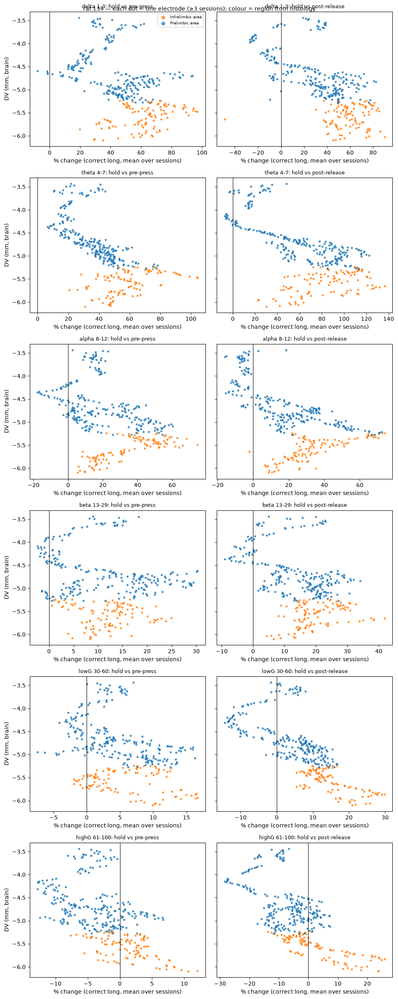

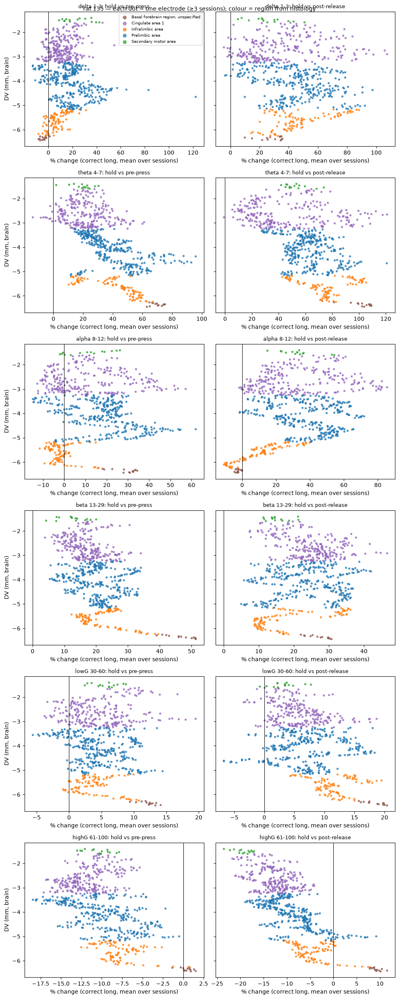

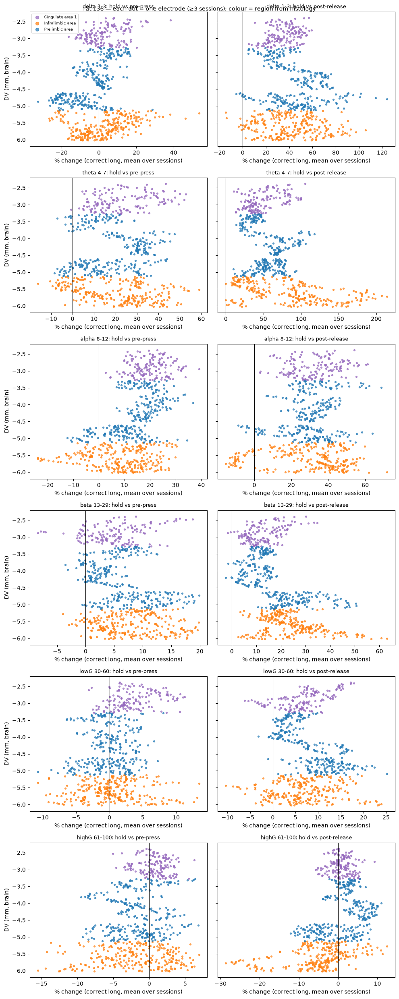

In [75]:
RCOL = {"Prelimbic area": "tab:blue", "Infralimbic area": "tab:orange", "Cingulate area 1": "tab:purple",
        "Secondary motor area": "tab:green", "Basal forebrain region, unspecified": "tab:brown", "Not found": "black"}
FIG_BANDS = list(lfm.MAIN_BANDS)          # all 6 bands: delta, theta, alpha, beta, low gamma, high gamma
E = (CHV[CHV.band.isin(FIG_BANDS)]
     .groupby(["rat", "band", "x", "y", "region"], as_index=False)
     .agg(dv_mm=("dv_mm", "mean"), hold_pre=("hold-pre", "mean"), hold_post=("hold-post", "mean"), n=("session", "nunique")))
E = E[E["n"] >= 3]
for rat, er in E.groupby("rat"):
    fig, axes = plt.subplots(len(FIG_BANDS), 2, figsize=(10, 4.2 * len(FIG_BANDS)), sharey=True, squeeze=False)
    for i, b in enumerate(FIG_BANDS):
        eb = er[er.band == b]
        for j, (col, lab) in enumerate((("hold_pre", "hold vs pre-press"), ("hold_post", "hold vs post-release"))):
            ax = axes[i, j]
            for g, eg in eb.groupby("region"):
                ax.scatter(100 * (10 ** eg[col] - 1), eg["dv_mm"], s=8, color=RCOL.get(g, "grey"), label=g, alpha=0.7)
            ax.axvline(0, color="k", lw=0.8)
            ax.set_title(f"{b}: {lab}", fontsize=9); ax.set_xlabel("% change (correct long, mean over sessions)")
            if j == 0:
                ax.set_ylabel("DV (mm, brain)")
    axes[0, 0].legend(fontsize=7, markerscale=2)
    fig.suptitle(f"rat {rat} — each dot = one electrode (≥3 sessions); colour = region from histology", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(BP_DIR, f"_depth_regions_rat_{rat}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [92]:
import gc
for v in ["BP", "RM"]:
    if v in globals(): del globals()[v]; print("deleted", v)
gc.collect()

2716

20260610_r0000135_wt_2313: done in 6.9 min


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


20260529_r0000136_wt_1318: done in 5.7 min


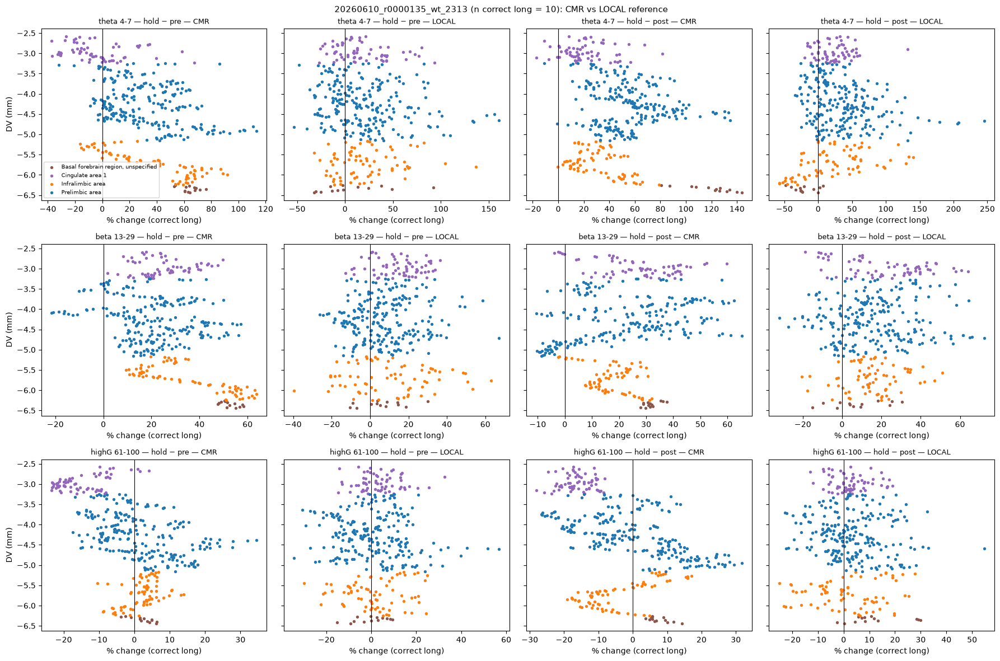

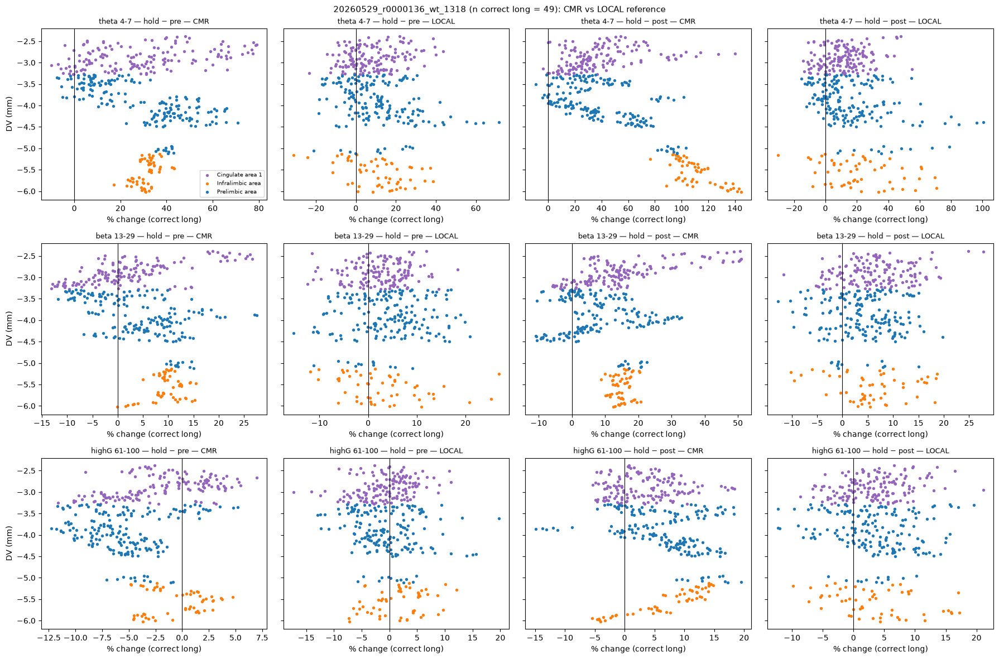

                                                               % ch > 0       median %       slope % per mm dorsal       
ref                                                                 CMR LOCAL      CMR LOCAL                   CMR  LOCAL
session                   band         measure     region                                                                
20260529_r0000136_wt_1318 beta 13-29   hold − post Cingulate       91.0  83.0     13.2   6.4                  37.2    4.1
                                                   Infralimbic    100.0  83.0     15.0   5.4                   0.7   -2.8
                                                   Prelimbic       75.0  72.0      5.8   3.8                  -2.0   -0.8
                                       hold − pre  Cingulate       59.0  67.0      0.7   3.1                  26.4    2.1
                                                   Infralimbic     98.0  63.0      9.4   1.4                   3.4   -9.0
                        

In [93]:
LR_DIR = os.path.join(PROJECT, "data", "analysis_main", "band_power_localref_pilot")
LR_SESS = ["20260610_r0000135_wt_2313", "20260529_r0000136_wt_1318"]
for s in LR_SESS:
    out = os.path.join(LR_DIR, s + ".pkl")
    if os.path.exists(out):
        continue
    t0 = time.time()
    rec = si.load(find_rec(s))
    bad = XB.loc[XB["session"] == s, "channel_id"].tolist()
    if bad:
        rec = rec.remove_channels(bad)
    rec_loc = spre.common_reference(rec, reference="local", operator="median", local_radius=(30, 200))
    lfm.process_session(rec_loc, session_trials(s), out, mem_bytes=2e9, verbose=False)
    print(f"{s}: done in {(time.time() - t0) / 60:.1f} min")

# compare CMR (band_power_v1) vs LOCAL per channel: M1 hold − pre and hold − post, correct long, vs brain DV
import pickle
RCOL = {"Prelimbic area": "tab:blue", "Infralimbic area": "tab:orange", "Cingulate area 1": "tab:purple",
        "Secondary motor area": "tab:green", "Basal forebrain region, unspecified": "tab:brown", "Not found": "black"}
CMP_BANDS = ["theta 4-7", "beta 13-29", "highG 61-100"]
summ = []
for s in LR_SESS:
    res = {}
    for ref, folder in (("CMR", BP_DIR), ("LOCAL", LR_DIR)):
        with open(os.path.join(folder, s + ".pkl"), "rb") as fh:
            res[ref] = pickle.load(fh)
    c = CH_REG[CH_REG.session == s]
    pos = {(int(round(a)), int(round(b))): (g, d) for a, b, g, d in zip(c.x, c.y, c.region, c.dv_mm)}
    fig, axes = plt.subplots(len(CMP_BANDS), 4, figsize=(18, 4 * len(CMP_BANDS)), sharey=True, squeeze=False)
    for i, b in enumerate(CMP_BANDS):
        for j, (ref, meas, w) in enumerate([("CMR", "hold − pre", "pre"), ("LOCAL", "hold − pre", "pre"),
                                            ("CMR", "hold − post", "post"), ("LOCAL", "hold − post", "post")]):
            r = res[ref]; cl = lfm.main_conditions(r["trials"])["correct long"].values
            keep = ~np.isin(r["meta"]["channel_ids"], XB.loc[XB.session == s, "channel_id"].tolist())
            e = 100 * (10 ** np.nanmean(r["logpow"][b]["hold"][cl] - r["logpow"][b][w][cl], axis=0) - 1)
            reg_dv = [pos.get((int(round(a)), int(round(bb))), ("?", np.nan)) for a, bb in zip(r["meta"]["x"], r["meta"]["y"])]
            reg = np.array([g for g, _ in reg_dv], dtype=object); dv = np.array([d for _, d in reg_dv], float)
            ax = axes[i, j]
            for g in np.unique(reg[keep]):
                m = keep & (reg == g)
                ax.scatter(e[m], dv[m], s=8, color=RCOL.get(g, "grey"), label=g)
            ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{b} — {meas} — {ref}", fontsize=9)
            ax.set_xlabel("% change (correct long)")
            for g in ["Prelimbic area", "Infralimbic area", "Cingulate area 1"]:
                m = keep & (reg == g)
                if m.sum() >= 10:
                    slope = np.polyfit(dv[m], np.log10(1 + e[m] / 100), 1)[0]
                    summ.append({"session": s, "band": b, "measure": meas, "ref": ref, "region": g.split()[0],
                                 "median %": round(float(np.median(e[m])), 1), "% ch > 0": round(100 * float(np.mean(e[m] > 0))),
                                 "slope % per mm dorsal": round(100 * (10 ** slope - 1), 1), "n_ch": int(m.sum())})
        axes[i, 0].set_ylabel("DV (mm)")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"{s} (n correct long = {int(cl.sum())}): CMR vs LOCAL reference", fontsize=11)
    fig.tight_layout(); fig.savefig(os.path.join(LR_DIR, f"_cmr_vs_local_{s}.png"), dpi=130, bbox_inches="tight"); plt.show()
SUMM = pd.DataFrame(summ)
pd.set_option("display.width", 250)
print(SUMM.pivot_table(index=["session", "band", "measure", "region"], columns="ref",
                       values=["median %", "% ch > 0", "slope % per mm dorsal"]).round(1).to_string())

## 1.19 CMR vs LOCAL reference — ALL sessions (band_power_v2 vs band_power_v2_localref) ──
 needs 1.0 only (lfm, PROJECT, TABLES, rat_of, XB, SESSIONS_V2). Files are loaded one at a time (no BP needed).
 Per session, channel value = mean over correct-long trials of log10(window) − log10(baseline window).
 Region value = median over the region's channels; slope = linear fit of channel % change vs DV (per mm dorsal).

CMR loaded
LOCAL loaded

===== hold − pre (correct long) — ALL RATS, sessions = unit, raw p =====
        band  region  n     CMR % [p]   LOCAL % [p]  LOCAL/CMR %ch up CMR→LOCAL slope %/mm CMR [p] slope %/mm LOCAL [p]
   delta 1-3      PL 29 +15.4 [0.002] +14.4 [0.000]       0.94          78 → 71       -7.6 [0.052]        -10.1 [0.000]
   delta 1-3      IL 30 +12.1 [0.059] +14.9 [0.000]       1.21          76 → 69      +21.0 [0.025]        +15.9 [0.093]
   delta 1-3 IL − PL 29  -1.6 [0.755]  +1.8 [0.323]      -1.07                                                         
   theta 4-7      PL 29 +30.3 [0.000] +15.2 [0.000]       0.54          91 → 73      -11.4 [0.006]         -6.1 [0.028]
   theta 4-7      IL 30 +34.1 [0.000] +18.4 [0.000]       0.58         100 → 74       -4.8 [0.522]        +18.3 [0.002]
   theta 4-7 IL − PL 29  +3.5 [0.418]  +3.2 [0.098]       0.90                                                         
  alpha 8-12      PL 29 +17.3 [0.000]  +9.9 [0.000]       0.59

NameError: name 'FIG_DIR' is not defined

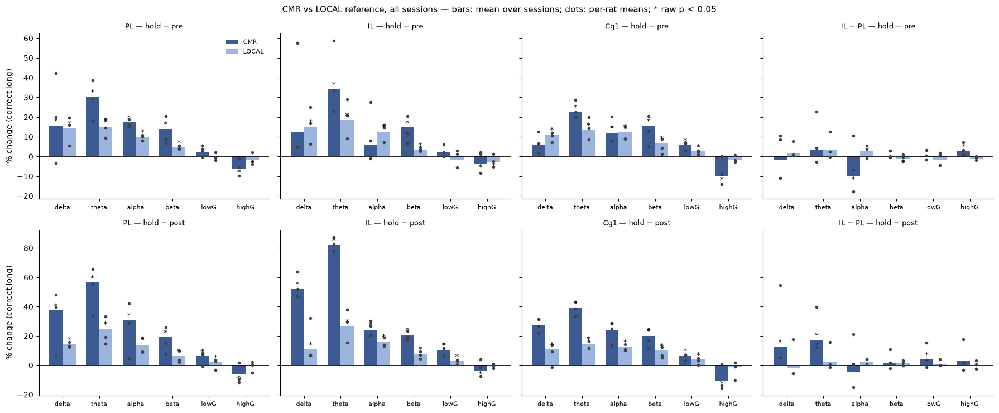

In [ ]:
import pickle
DIRS = {"CMR":   os.path.join(PROJECT, "data", "analysis_main", "band_power_v2"),
        "LOCAL": os.path.join(PROJECT, "data", "analysis_main", "band_power_v2_localref")}
REGIONS = {"PL": "Prelimbic area", "IL": "Infralimbic area", "Cg1": "Cingulate area 1"}
MIN_CH, MIN_CL, MIN_SPAN_MM = 10, 10, 0.2
BANDS = list(lfm.MAIN_BANDS)
MEAS = {"hold − pre": ("hold", "pre"), "hold − post": ("hold", "post")}
CH_REG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
pct = lambda v: 100 * (10 ** np.asarray(v, float) - 1)

def regions_of(s, meta):
    """region name and DV (mm) of each channel in the file; later-detected bad channels -> 'BAD CHANNEL'"""
    c = CH_REG[CH_REG["session"] == s]
    xy = list(zip(c["x"].round().astype(int), c["y"].round().astype(int)))
    reg, dv = dict(zip(xy, c["region"])), dict(zip(xy, c["dv_mm"]))
    k = [(int(round(x)), int(round(y))) for x, y in zip(meta["x"], meta["y"])]
    R = np.array([reg.get(q, "NOT IN TABLE") for q in k], dtype=object)
    D = np.array([dv.get(q, np.nan) for q in k], float)
    R[np.isin(meta["channel_ids"], XB.loc[XB.session == s, "channel_id"].tolist())] = "BAD CHANNEL"
    return R, D

rows = []
for ref, d in DIRS.items():
    for s in SESSIONS_V2:
        with open(os.path.join(d, s + ".pkl"), "rb") as f:
            r = pickle.load(f)
        cl = lfm.main_conditions(r["trials"])["correct long"].values
        if cl.sum() < MIN_CL:
            del r; continue
        R, D = regions_of(s, r["meta"])
        for b in BANDS:
            L = r["logpow"][b]
            for meas, (w1, w0) in MEAS.items():
                with lfm.warnings_off():
                    ch = np.nanmean(L[w1][cl] - L[w0][cl], axis=0)             # per channel (log10)
                vals = {}
                for reg, name in REGIONS.items():
                    m = (R == name) & np.isfinite(ch)
                    if m.sum() < MIN_CH:
                        continue
                    ok = m & np.isfinite(D)
                    slope = (np.polyfit(D[ok], pct(ch[ok]), 1)[0]
                             if ok.sum() >= MIN_CH and np.ptp(D[ok]) >= MIN_SPAN_MM else np.nan)
                    vals[reg] = float(np.median(ch[m]))
                    rows.append(dict(ref=ref, session=s, rat=str(rat_of(s)), band=b, measure=meas, region=reg,
                                     n_ch=int(m.sum()), med_log=vals[reg], pct_ch_up=100 * float((ch[m] > 0).mean()),
                                     slope_pct_mm=slope))
                if "IL" in vals and "PL" in vals:
                    rows.append(dict(ref=ref, session=s, rat=str(rat_of(s)), band=b, measure=meas, region="IL − PL",
                                     n_ch=np.nan, med_log=vals["IL"] - vals["PL"], pct_ch_up=np.nan, slope_pct_mm=np.nan))
        del r
    print(ref, "loaded")
VLOC = pd.DataFrame(rows)
VLOC.to_csv(os.path.join(DIRS["CMR"], "_session_values_1_19_cmr_vs_local.csv"), index=False)

# ── stats: sign-flip across sessions, per reference; LOCAL/CMR = how much of the CMR effect is left locally ──
RATS = ["all"] + sorted(VLOC.rat.unique())
out = []
for (meas, b, reg), g in VLOC.groupby(["measure", "band", "region"], sort=False):
    for rat in RATS:
        gg = g if rat == "all" else g[g.rat == rat]
        row = dict(measure=meas, band=b, region=reg, rat=rat)
        for ref in DIRS:
            h = gg[gg.ref == ref]
            m, p, n = lfm.sign_flip_p(h["med_log"].values)
            ms, ps, _ = lfm.sign_flip_p(h["slope_pct_mm"].values)
            row.update({f"{ref} %": float(pct(m)), f"{ref} p": p, f"{ref} n": n, f"{ref} %ch up": h["pct_ch_up"].median(),
                        f"{ref} slope": ms, f"{ref} p slope": ps, f"_{ref}_m": m})
        row["LOCAL/CMR"] = row["_LOCAL_m"] / row["_CMR_m"] if abs(row["_CMR_m"]) > 1e-4 else np.nan
        out.append(row)
S19 = pd.DataFrame(out).drop(columns=["_CMR_m", "_LOCAL_m"])
S19.to_csv(os.path.join(DIRS["CMR"], "_stats_1_19_cmr_vs_local.csv"), index=False)

pd.set_option("display.width", 250)
f_pc = lambda x, ref: f"{x[ref + ' %']:+.1f} [{x[ref + ' p']:.3f}]" if x[ref + " n"] >= 2 else "—"
f_sl = lambda x, ref: f"{x[ref + ' slope']:+.1f} [{x[ref + ' p slope']:.3f}]" if np.isfinite(x[ref + " slope"]) else ""
for meas in MEAS:
    d = S19[(S19.measure == meas) & (S19.rat == "all")].copy()
    tab = pd.DataFrame({"band": d.band, "region": d.region, "n": d["CMR n"],
                        "CMR % [p]": d.apply(f_pc, ref="CMR", axis=1), "LOCAL % [p]": d.apply(f_pc, ref="LOCAL", axis=1),
                        "LOCAL/CMR": d["LOCAL/CMR"].round(2),
                        "%ch up CMR→LOCAL": d.apply(lambda x: f"{x['CMR %ch up']:.0f} → {x['LOCAL %ch up']:.0f}"
                                                    if np.isfinite(x["CMR %ch up"]) else "", axis=1),
                        "slope %/mm CMR [p]": d.apply(f_sl, ref="CMR", axis=1),
                        "slope %/mm LOCAL [p]": d.apply(f_sl, ref="LOCAL", axis=1)})
    print(f"\n===== {meas} (correct long) — ALL RATS, sessions = unit, raw p =====")
    print(tab.to_string(index=False))

print("\n===== per rat: mean % CMR → LOCAL [raw p LOCAL] =====")
S19["cell"] = S19.apply(lambda x: f"{x['CMR %']:+.0f} → {x['LOCAL %']:+.0f} [{x['LOCAL p']:.3f}]"
                        if x["LOCAL n"] >= 2 else "—", axis=1)
for meas in MEAS:
    print(f"\n--- {meas} ---")
    print(S19[S19.measure == meas].pivot_table(index=["band", "region"], columns="rat", values="cell",
                                               aggfunc="first", sort=False)[RATS].to_string())

# ── figure: mean % per band, CMR (dark) vs LOCAL (light), per region; dots = per-rat means ──
REG_ORDER = ["PL", "IL", "Cg1", "IL − PL"]
fig, axes = plt.subplots(len(MEAS), len(REG_ORDER), figsize=(18, 7.5), sharey="row")
xb = np.arange(len(BANDS))
for i, meas in enumerate(MEAS):
    for j, reg in enumerate(REG_ORDER):
        ax = axes[i, j]
        d = S19[(S19.measure == meas) & (S19.region == reg)]
        for k, (ref, col, dx) in enumerate((("CMR", "#3b5b92", -0.18), ("LOCAL", "#9bb5de", 0.18))):
            a = d[d.rat == "all"].set_index("band").reindex(BANDS)
            ax.bar(xb + dx, a[f"{ref} %"], width=0.36, color=col, label=ref if (i, j) == (0, 0) else None)
            for _, rr in d[d.rat != "all"].iterrows():
                ax.plot(BANDS.index(rr.band) + dx, rr[f"{ref} %"], "o", ms=3, color="0.25", zorder=3)
            for bi, b in enumerate(BANDS):
                if a.loc[b, f"{ref} p"] < 0.05:
                    ax.text(bi + dx, a.loc[b, f"{ref} %"], "*", ha="center",
                            va="bottom" if a.loc[b, f"{ref} %"] >= 0 else "top", fontsize=10)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_xticks(xb); ax.set_xticklabels([b.split()[0] for b in BANDS], fontsize=8)
        ax.set_title(f"{reg} — {meas}", fontsize=9)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axes[i, 0].set_ylabel("% change (correct long)")
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle("CMR vs LOCAL reference, all sessions — bars: mean over sessions; dots: per-rat means; * raw p < 0.05",
             fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(DIRS["CMR"], "1_19_cmr_vs_local.png"), dpi=140, bbox_inches="tight")
plt.show()

# 2. band_power_v2 (overnight): tone windows, spectra for specparam, bursts (Karvat 2020 offline rule)
Same as v1 (all v1 outputs are kept) plus, from the Press-aligned epochs:
- **logpow "pre_tone" / "post_tone"**: tone −0.3..0 and 0..+0.3 s (NaN for trials without a tone, e.g. early)
- **spectra**: Hann periodogram 1–100 Hz (1 Hz bins), mean over trials per condition and channel, windows
  pre (−0.8..−0.2), hold (0.25..0.85, only trials still holding), pre_tone (tone −0.6..tone, only if tone came before release)
- **bursts** theta 4–7 and beta 13–29: power > 98th percentile (per channel × frequency, over all trials, press −1.5..+3.0 s),
  local maximum across frequency, ≥ 70 ms. Saved as a table of events (trial, channel, start, end, peak, frequency).
- Bad channels from tables/extra_bad_channels.csv are removed (since 2026-10-20 incl. AP326 + AP362 in rat 135, AP63 + AP90 in rat 134).
- WT-manipulation sessions are skipped (59 sessions).

**2.2** CMR reference → folder band_power_v2 (v1 stays untouched).

**2.3** same, LOCAL reference (each channel minus the median of channels 30–200 µm away, same shank) → folder band_power_v2_localref.
Purpose of 2.3: test whether effects (e.g. the depth gradient of theta) are generated locally or spread from elsewhere.

In [83]:
# ── add per-rat unreliable channels to extra_bad_channels.csv (all sessions of that rat) ──
RAT_BAD = {"135": ["imec0.ap#AP326", "imec0.ap#AP362"], "134": ["imec0.ap#AP63", "imec0.ap#AP90"]}
REASON = "unreliable channel of this rat (bad in some sessions in preprocessing; extreme M1 values in 2026-06 sessions)"
xb_path = os.path.join(TABLES, "extra_bad_channels.csv")
XB_old = pd.read_csv(xb_path)
new = []
for s in SESSIONS:
    rat = rat_of(s)
    if rat not in RAT_BAD:
        continue
    ids = set(si.load(find_rec(s)).get_channel_ids())          # channels still present after preprocessing
    for ch in RAT_BAD[rat]:
        if ch in ids and not ((XB_old.session == s) & (XB_old.channel_id == ch)).any():
            new.append({"session": s, "channel_id": ch, "reason": REASON})
print("rows added:", len(new)); print(pd.DataFrame(new).groupby("channel_id").size().to_dict() if new else "")
XB = pd.concat([XB_old, pd.DataFrame(new)], ignore_index=True)
XB.to_csv(xb_path, index=False)
print("extra_bad_channels.csv now has", len(XB), "rows; load_cmr uses the new list from now on")

rows added: 0

extra_bad_channels.csv now has 51 rows; load_cmr uses the new list from now on


In [84]:
# ── 2.0 settings + trial table with tone time ──
TEST_SESSION = "20260529_r0000136_wt_1318"
BP2_DIR = os.path.join(PROJECT, "data", "analysis_main", "band_power_v2")
os.makedirs(BP2_DIR, exist_ok=True)
TONE_COL = "tone_neural_s"                        # tone time on the neural clock (check the name below)
print("tone column present:", TONE_COL in AT.columns, "| columns with 'tone':", [c for c in AT.columns if "tone" in c])

def session_trials_v2(session):
    t = AT[AT["session"] == session]
    d = session_trials(session)
    d["tone_s"] = t[TONE_COL].values
    return d

AT_all = pd.read_csv(os.path.join(TABLES, "all_trials.csv"))
WTM = set(AT_all.loc[AT_all["wt_manip_session"].astype(bool), "session"])
SESSIONS_V2 = [s for s in SESSIONS if s not in WTM]
print(len(SESSIONS_V2), "sessions for v2")
d = session_trials_v2(TEST_SESSION)
print(pd.crosstab(d["outcome"], d["tone_s"].notna(), margins=True))      # early trials should have no tone

tone column present: True | columns with 'tone': ['tone_delay_s', 'tone_neural_s']
59 sessions for v2
tone_s   False  True  All
outcome                  
correct      0    97   97
early       19     1   20
late         0    25   25
All         19   123  142


In [86]:
d = session_trials_v2(TEST_SESSION)
e = d[(d.outcome == "early") & d.tone_s.notna()]
print(e.assign(hold=e.release_s - e.press_s, tone_delay=e.tone_s - e.press_s,
               release_minus_tone=e.release_s - e.tone_s).to_string())

    trial outcome  type  long_prob   press_s  release_s    tone_s  hold  tone_delay  release_minus_tone
43     51   early  long        0.5  624.1339   625.1539  625.1839  1.02        1.05               -0.03


In [87]:
cl = lfm.main_conditions(r2["trials"])["correct long"].values
th = r2["logpow"]["theta 4-7"]
pct = lambda a, b: round(100 * (10 ** np.nanmedian(np.nanmean(a[cl] - b[cl], axis=0)) - 1), 1)
print("theta correct long vs pre (%): hold", pct(th["hold"], th["pre"]),
      "| pre_tone", pct(th["pre_tone"], th["pre"]), "| post_tone", pct(th["post_tone"], th["pre"]))
# same from the v1-style time course (independent code path): mean over 0.75-1.05 s
t = r2["times"]["Press"]; m = (t >= 0.75) & (t <= 1.05)
cv = r2["curves"]["Press"]["theta 4-7"]["correct long"]
print("curve 0.75-1.05 s (%):", round(100 * (10 ** np.nanmedian(np.nanmean(cv[:, m], axis=1)) - 1), 1),
      "| curve 0.20-0.85 s (%):", round(100 * (10 ** np.nanmedian(np.nanmean(cv[:, (t >= 0.2) & (t <= 0.85)], axis=1)) - 1), 1))

theta correct long vs pre (%): hold 30.7 | pre_tone 2.4 | post_tone 5.0
curve 0.75-1.05 s (%): 4.5 | curve 0.20-0.85 s (%): 24.2


In [ ]:
# ── 2.2 ALL SESSIONS
log2 = []
for k, s in enumerate(SESSIONS_V2, 1):
    out = os.path.join(BP2_DIR, s + ".pkl")
    if os.path.exists(out):
        continue
    t0 = time.time()
    try:
        rec, bad = load_cmr(s)
        lfm.process_session(rec, session_trials_v2(s), out, mem_bytes=2e9, verbose=False, v2=True)
        log2.append({"session": s, "status": "ok", "minutes": round((time.time() - t0) / 60, 1)})
    except Exception as e:
        log2.append({"session": s, "status": f"ERROR: {e!r}", "minutes": round((time.time() - t0) / 60, 1)})
    print(f"{k}/{len(SESSIONS_V2)} {s}: {log2[-1]['status']} ({log2[-1]['minutes']} min)", flush=True)
    pd.DataFrame(log2).to_csv(os.path.join(BP2_DIR, "_run_log.csv"), index=False)
print("all done:", len(glob.glob(os.path.join(BP2_DIR, "*.pkl"))), "session files")

1/59 20260510_r0000135_wt_1625: ok (1.9 min)
2/59 20260510_r0000136_wt_1926: ok (4.0 min)
3/59 20260511_r0000136_wt_0909: ok (0.8 min)
4/59 20260511_r0000136_wt_0930: ok (2.1 min)
5/59 20260511_r0000136_wt_1832: ok (2.3 min)
6/59 20260512_r0000136_wt_1054: ok (0.3 min)
7/59 20260513_r0000136_wt_1729: ok (1.0 min)
8/59 20260514_r0000136_wt_1317: ok (0.9 min)
9/59 20260515_r0000135_wt_1953: ok (5.8 min)
10/59 20260515_r0000135_wt_1957: ok (1.9 min)
11/59 20260515_r0000136_wt_1817: ok (3.2 min)
12/59 20260517_r0000135_wt_1846: ok (1.0 min)
13/59 20260517_r0000136_wt_1557: ok (4.6 min)
14/59 20260519_r0000136_wt_2031: ok (3.6 min)
15/59 20260520_r0000135_wt_1357: ok (3.2 min)
16/59 20260520_r0000136_wt_1443: ok (3.2 min)
17/59 20260521_r0000135_wt_1309: ok (4.7 min)
18/59 20260522_r0000135_wt_1716: ok (6.6 min)
19/59 20260522_r0000136_wt_1750: ok (4.9 min)
20/59 20260523_r0000135_wt_1320: ok (2.7 min)
21/59 20260523_r0000136_wt_1320: ok (3.5 min)
22/59 20260524_r0000135_wt_1944: ok (7.1 mi

In [95]:
# ── 2.3 ALL SESSIONS with LOCAL reference (same v2 outputs; for the "is it local?" question) ──
# local median reference: each channel minus the median of channels 30–200 µm away (same shank)
BPL_DIR = os.path.join(PROJECT, "data", "analysis_main", "band_power_v2_localref")
os.makedirs(BPL_DIR, exist_ok=True)
log3 = []
for k, s in enumerate(SESSIONS_V2, 1):
    out = os.path.join(BPL_DIR, s + ".pkl")
    if os.path.exists(out):
        continue
    t0 = time.time()
    try:
        rec = si.load(find_rec(s))
        bad = XB.loc[XB["session"] == s, "channel_id"].tolist()
        if bad:
            rec = rec.remove_channels([c for c in bad if c in rec.get_channel_ids()])
        rec = spre.common_reference(rec, reference="local", operator="median", local_radius=(30, 200))
        lfm.process_session(rec, session_trials_v2(s), out, mem_bytes=2e9, verbose=False, v2=True)
        log3.append({"session": s, "status": "ok", "minutes": round((time.time() - t0) / 60, 1)})
    except Exception as e:
        log3.append({"session": s, "status": f"ERROR: {e!r}", "minutes": round((time.time() - t0) / 60, 1)})
    print(f"[local] {k}/{len(SESSIONS_V2)} {s}: {log3[-1]['status']} ({log3[-1]['minutes']} min)", flush=True)
    pd.DataFrame(log3).to_csv(os.path.join(BPL_DIR, "_run_log.csv"), index=False)
print("local-ref all done:", len(glob.glob(os.path.join(BPL_DIR, "*.pkl"))), "session files")

[local] 1/59 20260510_r0000135_wt_1625: ok (2.9 min)
[local] 2/59 20260510_r0000136_wt_1926: ok (6.3 min)
[local] 3/59 20260511_r0000136_wt_0909: ok (1.3 min)
[local] 4/59 20260511_r0000136_wt_0930: ok (3.3 min)
[local] 5/59 20260511_r0000136_wt_1832: ok (3.6 min)
[local] 6/59 20260512_r0000136_wt_1054: ok (0.5 min)
[local] 7/59 20260513_r0000136_wt_1729: ok (1.6 min)
[local] 8/59 20260514_r0000136_wt_1317: ok (1.4 min)
[local] 9/59 20260515_r0000135_wt_1953: ok (9.1 min)
[local] 10/59 20260515_r0000135_wt_1957: ok (2.9 min)
[local] 11/59 20260515_r0000136_wt_1817: ok (5.1 min)
[local] 12/59 20260517_r0000135_wt_1846: ok (1.6 min)
[local] 13/59 20260517_r0000136_wt_1557: ok (8.1 min)


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[local] 14/59 20260519_r0000136_wt_2031: ok (5.6 min)
[local] 15/59 20260520_r0000135_wt_1357: ok (4.8 min)


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[local] 16/59 20260520_r0000136_wt_1443: ok (4.9 min)
[local] 17/59 20260521_r0000135_wt_1309: ok (7.1 min)
[local] 18/59 20260522_r0000135_wt_1716: ok (10.0 min)


...

[local] 50/59 20260620_r0000134_wt_1512: ok (1.2 min)


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[local] 51/59 20260620_r0000134_wt_1554: ok (7.8 min)
[local] 52/59 20260620_r0000135_wt_1627: ok (6.4 min)


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[local] 53/59 20260621_r0000134_wt_1533: ok (6.0 min)
[local] 54/59 20260621_r0000135_wt_1618: ok (6.4 min)
[local] 55/59 20260622_r0000134_wt_1513: ok (6.0 min)
[local] 56/59 20260622_r0000135_wt_1426: ok (4.6 min)
[local] 57/59 20260623_r0000135_wt_1111: ok (5.2 min)
[local] 58/59 20260624_r0000135_wt_1257: ok (5.4 min)
[local] 59/59 20260625_r0000135_wt_1846: ok (5.1 min)
local-ref all done: 59 session files


20260510_r0000135_wt_1625: rms_ratio 6.29 | r_shanks 0.99 | line50 0.4 | art 0.1195
20260510_r0000136_wt_1926: rms_ratio 3.09 | r_shanks 0.90 | line50 0.2 | art 0.0000
20260511_r0000136_wt_0909: rms_ratio 3.04 | r_shanks 0.88 | line50 0.2 | art 0.0000
20260511_r0000136_wt_0930: rms_ratio 3.04 | r_shanks 0.87 | line50 0.2 | art 0.0000
20260511_r0000136_wt_1832: rms_ratio 2.96 | r_shanks 0.88 | line50 0.2 | art 0.0000
20260512_r0000136_wt_1054: rms_ratio 3.53 | r_shanks 0.90 | line50 0.2 | art 0.0000
20260513_r0000136_wt_1729: rms_ratio 3.12 | r_shanks 0.90 | line50 0.2 | art 0.0000
20260514_r0000136_wt_1317: rms_ratio 3.11 | r_shanks 0.89 | line50 0.2 | art 0.0000
20260515_r0000135_wt_1953: rms_ratio 9.14 | r_shanks 0.99 | line50 0.3 | art 0.2330
20260515_r0000135_wt_1957: rms_ratio 10.16 | r_shanks 0.99 | line50 0.3 | art 0.3108
20260515_r0000136_wt_1817: rms_ratio 3.16 | r_shanks 0.90 | line50 0.2 | art 0.0000
20260517_r0000135_wt_1846: rms_ratio nan | r_shanks 0.98 | line50 nan | art

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


20260517_r0000136_wt_1557: rms_ratio 1.55 | r_shanks nan | line50 0.2 | art 0.0000
20260519_r0000136_wt_2031: rms_ratio 1.41 | r_shanks 0.66 | line50 0.2 | art 0.0000
20260520_r0000135_wt_1357: rms_ratio 2.96 | r_shanks 0.91 | line50 0.3 | art 0.0000
20260520_r0000136_wt_1443: rms_ratio 1.40 | r_shanks 0.66 | line50 0.2 | art 0.0000
20260521_r0000135_wt_1309: rms_ratio 2.99 | r_shanks 0.92 | line50 0.3 | art 0.0147
20260522_r0000135_wt_1716: rms_ratio 2.89 | r_shanks 0.91 | line50 0.3 | art 0.0000
20260522_r0000136_wt_1750: rms_ratio 1.41 | r_shanks 0.65 | line50 0.2 | art 0.0000
20260523_r0000135_wt_1320: rms_ratio 2.76 | r_shanks 0.88 | line50 0.2 | art 0.0051
20260523_r0000136_wt_1320: rms_ratio 1.37 | r_shanks 0.63 | line50 0.2 | art 0.0000
20260524_r0000135_wt_1944: rms_ratio 3.14 | r_shanks 0.91 | line50 0.4 | art 0.0154
20260524_r0000136_wt_1836: rms_ratio 1.38 | r_shanks 0.65 | line50 0.2 | art 0.0000
20260525_r0000135_wt_1426: rms_ratio 2.80 | r_shanks 0.89 | line50 0.4 | art 

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


20260609_r0000134_wt_1622: rms_ratio 2.47 | r_shanks nan | line50 0.2 | art 0.0000
20260609_r0000135_wt_1644: rms_ratio 6.89 | r_shanks 0.97 | line50 0.5 | art 0.1263
20260610_r0000134_wt_1923: rms_ratio 2.58 | r_shanks 0.77 | line50 0.2 | art 0.0000
20260610_r0000135_wt_2313: rms_ratio 3.16 | r_shanks 0.89 | line50 0.6 | art 0.0143
20260611_r0000134_wt_1309: rms_ratio 2.30 | r_shanks 0.76 | line50 0.2 | art 0.0000
20260611_r0000135_wt_1415: rms_ratio 3.09 | r_shanks 0.87 | line50 0.5 | art 0.0000
20260612_r0000134_wt_1447: rms_ratio 2.58 | r_shanks 0.77 | line50 0.2 | art 0.0000
20260612_r0000135_wt_1444: rms_ratio 3.84 | r_shanks 0.92 | line50 0.8 | art 0.0561
20260615_r0000134_wt_1825: rms_ratio 2.39 | r_shanks 0.77 | line50 0.2 | art 0.0000
20260615_r0000135_wt_1902: rms_ratio 3.07 | r_shanks 0.84 | line50 0.5 | art 0.0168
20260616_r0000134_wt_1653: rms_ratio 2.37 | r_shanks 0.74 | line50 0.2 | art 0.0000
20260616_r0000135_wt_1742: rms_ratio 4.71 | r_shanks 0.91 | line50 0.5 | art 

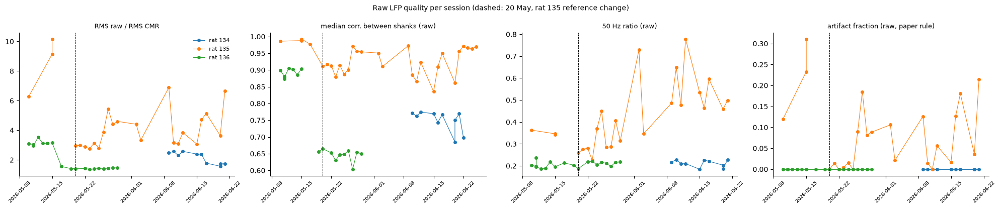

In [103]:
# ── 2.5b RAW LFP quality per session: is the original reference usable? (needed before using RAW in 2.6) ──
# needs 1.0 (find_rec, load_cmr, XB, rat_of, SESSIONS_V2) and REP (1.13b representative channels)
# per session, 20 random 10-s pieces, on the representative channels (+ all channels for the shank correlation):
#   rms_ratio  = RMS raw / RMS CMR        (>> 1: big shared signal in raw)
#   r_shanks   = median correlation between channels on DIFFERENT shanks, raw  (~1: one shared signal dominates)
#   line50     = power 49–51 Hz / 45–48 + 52–55 Hz, raw
#   art_frac   = fraction of samples with |raw| > 1000 µV, ±500 samples (the paper's artifact rule)
from scipy.signal import welch
import scipy.ndimage as ndi
REP = pd.read_csv(os.path.join(BP_DIR, "_representative_channels.csv"))
rng = np.random.default_rng(0); qrows = []
for s in SESSIONS_V2:
    raw = si.load(find_rec(s)); bad = XB.loc[XB["session"] == s, "channel_id"].tolist()
    raw = raw.remove_channels([c for c in bad if c in raw.get_channel_ids()])
    cmr = load_cmr(s)[0]
    fs, n = raw.get_sampling_frequency(), raw.get_num_samples()
    ids = np.array(raw.get_channel_ids()); loc = raw.get_channel_locations(); sh = (loc[:, 0] // 250).astype(int)
    rep = REP[REP["rat"].astype(str) == str(rat_of(s))]
    rid = [ids[k[0]] for _, rr in rep.iterrows()
           if len(k := np.flatnonzero((np.round(loc[:, 0]) == round(rr["x"])) & (np.round(loc[:, 1]) == round(rr["y"]))))]
    sub = ids[::8]                                                          # every 8th channel for the shank correlation
    starts = rng.integers(int(60 * fs), n - int(70 * fs), 20)
    rr_, rc_, rs_, ln_, ar_ = [], [], [], [], []
    for a in starts:
        xr = raw.get_traces(start_frame=a, end_frame=a + int(10 * fs), channel_ids=list(sub), return_in_uV=True).astype(float)
        C = np.corrcoef(xr.T); s_sub = sh[np.isin(ids, sub)]
        rs_.append(np.nanmedian(C[s_sub[:, None] != s_sub[None, :]]))
        if rid:
            r1 = raw.get_traces(start_frame=a, end_frame=a + int(10 * fs), channel_ids=rid, return_in_uV=True).astype(float)
            c1 = cmr.get_traces(start_frame=a, end_frame=a + int(10 * fs), channel_ids=[c for c in rid if c in cmr.get_channel_ids()],
                                return_in_uV=True).astype(float)
            rr_.append(r1.std(0).mean()); rc_.append(c1.std(0).mean())
            f, P = welch(r1, fs=fs, nperseg=int(2 * fs), axis=0)
            on = (f >= 49) & (f <= 51); off = ((f >= 45) & (f <= 48)) | ((f >= 52) & (f <= 55))
            ln_.append(np.median(P[on].mean(0) / P[off].mean(0)))
            big = ndi.binary_dilation(np.abs(r1) > 1000, structure=np.ones((1001, 1), bool))
            ar_.append(big.mean())
    qrows.append(dict(session=s, rat=str(rat_of(s)), date=pd.to_datetime(s[:8]), rms_ratio=np.mean(rr_) / np.mean(rc_) if rr_ else np.nan,
                      r_shanks=np.median(rs_), line50=np.median(ln_) if ln_ else np.nan, art_frac=np.mean(ar_) if ar_ else np.nan))
    print(f"{s}: rms_ratio {qrows[-1]['rms_ratio']:.2f} | r_shanks {qrows[-1]['r_shanks']:.2f} | "
          f"line50 {qrows[-1]['line50']:.1f} | art {qrows[-1]['art_frac']:.4f}", flush=True)
RAWQ = pd.DataFrame(qrows); RAWQ.to_csv(os.path.join(TABLES, "raw_lfp_quality.csv"), index=False)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, col, lab in zip(axes, ["rms_ratio", "r_shanks", "line50", "art_frac"],
                        ["RMS raw / RMS CMR", "median corr. between shanks (raw)", "50 Hz ratio (raw)", "artifact fraction (raw, paper rule)"]):
    for rat, d in RAWQ.groupby("rat"):
        ax.plot(d["date"], d[col], "o-", ms=4, lw=0.8, label=f"rat {rat}")
    ax.axvline(pd.Timestamp("2026-05-20"), color="k", ls="--", lw=0.7)
    ax.set_title(lab, fontsize=9); ax.tick_params(labelsize=7, axis="x", rotation=45)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("Raw LFP quality per session (dashed: 20 May, rat 135 reference change)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(TABLES, "raw_lfp_quality.png"), dpi=130, bbox_inches="tight"); plt.show()

In [15]:
# ── 2.6 BURSTS exactly as Karvat, Alyahyay & Diester 2021 PNAS (public code: github.com/Optophys/Spontaneous,
#        Karvat_et_al_2021_script_1.m "Burst analysis" + gross_artifact_removal_GH.m) + NeuroDSP dual threshold ──
# 1 Morlet power, 7 cycles, 1-Hz steps, band ±1 Hz, WHOLE session   2 |LFP| > 1000 µV -> NaN ±500 samples
# 3 /90th percentile per frequency; <1 -> 0, NaN -> 0                 4 2-D regional maxima (imregionalmax); edge rows dropped
# 5 extent = samples around the peak where power at the peak frequency stays > 90th pct   6 burst-on vector -> occupancy
# References now: CMR, LOCAL (as 2.3). RAW later (own folder, only clean sessions from raw_lfp_quality.csv).
# Kept different: 1000 Hz (paper 976.6 Hz); one representative channel per region (1.13b; if missing in a session ->
# nearest channel of the same region); theta 4-7 added (paper 'low' 3-10).
# NeuroDSP: detect_bursts_dual_threshold (Feingold et al. 2015), dual_thresh (1, 2) x median amplitude, >= 3 cycles.
# Output per session: per-trial occupancy and burst counts in 50-ms bins around press, tone and release (.npz + trials csv).
# needs 1.0 (find_rec, load_cmr, XB, AT, session_trials_v2, rat_of, BP_DIR, PROJECT, TABLES) and 1.19 (regions_of, REGIONS)
import scipy.signal as ss, scipy.ndimage as ndi, time
from skimage.morphology import local_maxima
try:
    from neurodsp.burst import detect_bursts_dual_threshold
    HAS_NDSP = True
except ImportError:
    HAS_NDSP = False; print("neurodsp not installed (%pip install neurodsp) -> NeuroDSP part skipped")

RUN_ALL = True                                   # False = test on TEST_26 only; True = all sessions (skips done ones)
TEST_26 = "20260529_r0000136_wt_1318"
REFS_26 = ("CMR", "LOCAL")                        # later: ("RAW",) with K_DIR = ..._raw
K_BANDS = {"beta 15-30": (15, 30), "theta 4-7": (4, 7)}
K_PCT, K_ART_UV, K_ART_PAD, K_CYC = 90, 1000.0, 500, 7
NDSP_THR, NDSP_MINCYC, BIN = (1, 2), 3, 0.05
ALIGN = {"press": ("press_s", -1.5, 2.0), "tone": ("tone_s", -1.0, 0.5), "release": ("release_s", -1.5, 0.5)}
K_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021"); os.makedirs(K_DIR, exist_ok=True)
REP = pd.read_csv(os.path.join(BP_DIR, "_representative_channels.csv"))
RAWQ = pd.read_csv(os.path.join(TABLES, "raw_lfp_quality.csv"))
RAW_OK = set(RAWQ.loc[(RAWQ["r_shanks"] < 0.80) | (RAWQ["r_shanks"].isna() & (RAWQ["rms_ratio"] < 2.7)), "session"])
TM_COLS = [c for c in AT.columns if "mismatch" in c.lower()]
print("timing-mismatch column in all_trials.csv:", TM_COLS if TM_COLS else "NONE")
if "RAW" in REFS_26: print(f"RAW computed only in {len(RAW_OK)} clean sessions:", sorted(RAW_OK))

def load_ref(s, ref):
    if ref == "CMR":
        return load_cmr(s)[0]
    rec = si.load(find_rec(s)); bad = XB.loc[XB["session"] == s, "channel_id"].tolist()
    rec = rec.remove_channels([c for c in bad if c in rec.get_channel_ids()])
    if ref == "RAW":                                                        # as Karvat et al. 2021: no re-reference
        return rec
    return spre.common_reference(rec, reference="local", operator="median", local_radius=(30, 200))   # LOCAL, as 2.3

def read_full(rec, ids, chunk_s=60):
    """whole session for a few channels, read in chunks (LOCAL would otherwise load all channels at once)"""
    fs, n = rec.get_sampling_frequency(), rec.get_num_samples(); step = int(chunk_s * fs)
    return np.concatenate([rec.get_traces(start_frame=a, end_frame=min(n, a + step), channel_ids=ids, return_in_uV=True)
                           for a in range(0, n, step)], axis=0).astype(np.float64)

def karvat_bursts(x, fs, band, art):
    """burst-on (bool) and burst peak events (bool), per sample — steps 1-6 of the Karvat et al. 2021 code"""
    foi = np.arange(max(1, band[0] - 1), band[1] + 2)                    # band ±1 Hz, 1-Hz steps
    P = np.empty((len(foi), len(x)), np.float32)
    for i, f in enumerate(foi):
        P[i] = np.abs(ss.fftconvolve(x, lfm.morlet(f, K_CYC, fs), mode="same")) ** 2
    P[:, art] = np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        M = P / np.nanpercentile(P, K_PCT, axis=1, keepdims=True)
    del P
    M[~(M >= 1)] = 0                                                      # < 90th pct and NaN -> 0
    pk = local_maxima(M, connectivity=2, allow_borders=True) & (M > 0)   # = MATLAB imregionalmax (8-connectivity)
    pk[[0, -1], :] = False                                                # ±1 Hz rows only used for peak detection
    on, ev = np.zeros(len(x), bool), np.zeros(len(x), bool)
    for i in range(1, len(foi) - 1):
        js = np.flatnonzero(pk[i])
        if not len(js): continue
        row = M[i] > 0
        run = np.cumsum(np.diff(np.concatenate([[0], row.astype(np.int8)])) == 1)
        on |= np.isin(run, np.unique(run[js])) & row                      # extent at the peak frequency
        ev[js] = True
    return on, ev

def binned(on, ev, fs, times, a, z):
    """(trials, bins): occupancy (fraction) and number of burst events, around event times (s)"""
    nb, w = int(round((z - a) / BIN)), int(round(BIN * fs))
    occ = np.full((len(times), nb), np.nan, np.float32); cnt = occ.copy()
    cs, es = np.concatenate([[0], np.cumsum(on)]), np.concatenate([[0], np.cumsum(ev)])
    for k, t0 in enumerate(times):
        if not np.isfinite(t0): continue
        st = int(round((t0 + a) * fs)) + np.arange(nb) * w
        if st[0] < 0 or st[-1] + w > len(on): continue
        occ[k], cnt[k] = (cs[st + w] - cs[st]) / w, es[st + w] - es[st]
    return occ, cnt

for s in (SESSIONS_V2 if RUN_ALL else [TEST_26]):
    out = os.path.join(K_DIR, s + ".npz")
    if os.path.exists(out) and RUN_ALL: continue
    t0 = time.time()
    try:
        T = session_trials_v2(s)
        if TM_COLS: T["timing_mismatch"] = AT.loc[AT["session"] == s, TM_COLS[0]].values
        rep = REP[REP["rat"].astype(str) == str(rat_of(s))]
        res = {}
        for ref in REFS_26:
            if ref == "RAW" and s not in RAW_OK:                            # raw dominated by shared signal -> skip
                continue
            rec = load_ref(s, ref); fs = rec.get_sampling_frequency()
            ids = np.array(rec.get_channel_ids()); loc = rec.get_channel_locations()
            pick = {}
            R_, _ = regions_of(s, {"x": loc[:, 0], "y": loc[:, 1], "channel_ids": list(ids)})
            for _, rr in rep.iterrows():
                dist = np.hypot(loc[:, 0] - rr["x"], loc[:, 1] - rr["y"])
                dist[R_ != REGIONS[rr["region"]]] = np.inf                    # only channels in the same region
                if np.isfinite(dist.min()):
                    k = int(np.argmin(dist)); pick[rr["region"]] = ids[k]
                    if dist[k] > 0:
                        print(f"  {s} {ref}: {rr['region']} representative channel missing -> nearest {rr['region']} channel, {dist[k]:.0f} µm away")
                else:
                    print(f"  {s} {ref}: no {rr['region']} channel in this session")
            if not pick: continue
            X = read_full(rec, list(pick.values()))
            for j, (reg, cid) in enumerate(pick.items()):
                x = X[:, j]
                art = ndi.binary_dilation(np.abs(x) > K_ART_UV, structure=np.ones(2 * K_ART_PAD + 1, bool))
                res[f"{ref}|{reg}|channel"] = np.array([str(cid)]); res[f"{ref}|{reg}|artifact_frac"] = np.array([art.mean()])
                for band, fr in K_BANDS.items():
                    meths = {"karvat2021": karvat_bursts(x, fs, fr, art)}
                    if HAS_NDSP:
                        o2 = detect_bursts_dual_threshold(x, fs, NDSP_THR, f_range=fr, min_n_cycles=NDSP_MINCYC) & ~art
                        meths["neurodsp"] = (o2, np.diff(np.concatenate([[0], o2.astype(np.int8)])) == 1)
                    for meth, (o, e) in meths.items():
                        key = f"{ref}|{meth}|{band}|{reg}"
                        res[key + "|session_occ"] = np.array([o[~art].mean()])
                        for al, (col, a, z) in ALIGN.items():
                            res[f"{key}|{al}|occ"], res[f"{key}|{al}|cnt"] = binned(o, e, fs, T[col].values.astype(float), a, z)
            del X
        np.savez_compressed(out, **res); T.to_csv(out.replace(".npz", "_trials.csv"), index=False)
        print(f"{s}: ok ({(time.time() - t0) / 60:.1f} min)", flush=True)
    except Exception as e:
        print(f"{s}: ERROR {e!r}", flush=True)

if not RUN_ALL:                                                           # sanity check of the test session
    Z = np.load(os.path.join(K_DIR, TEST_26 + ".npz"))
    print("\nwhole-session occupancy (fraction of time in a burst) — test session:")
    for k in sorted(k for k in Z.files if k.endswith("session_occ")):
        print(f"  {k.replace('|session_occ', ''):45s} {Z[k][0]:.3f}")
    print("\nartifact fraction:", {k.replace('|artifact_frac', ''): round(float(Z[k][0]), 4) for k in Z.files if k.endswith("artifact_frac")})
    print("channels used:", {k.replace('|channel', ''): str(Z[k][0]) for k in Z.files if k.endswith("|channel")})

timing-mismatch column in all_trials.csv: ['timing_mismatch']


NameError: name 'SESSIONS_V2' is not defined

In [16]:
# ── 2.8 PAPER burst method (Karvat 2021, as 2.6) on MANY channels: every 4th channel of PL/IL/Cg1, LOCAL reference ──
# needs 1.0, 1.19 (regions_of, REGIONS) and the definitions of 2.6 (karvat_bursts, binned, load_ref, K_BANDS, K_ART_UV,
# K_ART_PAD, TM_COLS). Saves per channel and trial the burst occupancy in 50-ms bins around press, tone and release.
RUN_ALL_8 = True                                  # False = test on TEST_8; True = all sessions (skips done ones)
TEST_8 = "20260529_r0000136_wt_1318"
STEP_CH, REF_8 = 4, "CMR"
ALIGN8 = {"press": ("press_s", -0.6, 1.2), "tone": ("tone_s", -0.6, 0.3), "release": ("release_s", -0.6, 0.0)}
K8_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021_channels"); os.makedirs(K8_DIR, exist_ok=True)

def read_full32(rec, ids, chunk_s=60):
    """whole session for many channels, float32, read in chunks"""
    fs, n = rec.get_sampling_frequency(), rec.get_num_samples(); step = int(chunk_s * fs)
    out = np.empty((n, len(ids)), np.float32)
    for a in range(0, n, step):
        b = min(n, a + step); out[a:b] = rec.get_traces(start_frame=a, end_frame=b, channel_ids=ids, return_in_uV=True)
    return out

log8 = []
for s in (SESSIONS_V2 if RUN_ALL_8 else [TEST_8]):
    out = os.path.join(K8_DIR, s + ".npz")
    if os.path.exists(out) and RUN_ALL_8: continue
    t0 = time.time()
    try:
        T = session_trials_v2(s)
        if TM_COLS: T["timing_mismatch"] = AT.loc[AT["session"] == s, TM_COLS[0]].values
        rec = load_ref(s, REF_8); fs = rec.get_sampling_frequency()
        ids = np.array(rec.get_channel_ids()); loc = rec.get_channel_locations()
        R_, D_ = regions_of(s, {"x": loc[:, 0], "y": loc[:, 1], "channel_ids": list(ids)})
        sel = []
        for name in REGIONS.values():                                   # every 4th channel along each column, per region
            k = np.where(R_ == name)[0]
            k = k[np.lexsort((loc[k, 1], loc[k, 0]))]
            sel += list(k[::STEP_CH])
        sel = np.array(sorted(sel))
        X = read_full32(rec, list(ids[sel]))
        res = {"channel_ids": ids[sel].astype(str), "x": loc[sel, 0], "y": loc[sel, 1],
               "region": R_[sel].astype(str), "dv_mm": D_[sel]}
        for band, fr in K_BANDS.items():
            occ = {al: [] for al in ALIGN8}; sess = []
            for j in range(len(sel)):
                x = X[:, j].astype(np.float64)
                art = ndi.binary_dilation(np.abs(x) > K_ART_UV, structure=np.ones(2 * K_ART_PAD + 1, bool))
                on, ev = karvat_bursts(x, fs, fr, art)
                sess.append(on[~art].mean())
                for al, (col, a, z) in ALIGN8.items():
                    occ[al].append(binned(on, ev, fs, T[col].values.astype(float), a, z)[0])
            for al in ALIGN8:
                res[f"{band}|{al}|occ"] = np.stack(occ[al]).astype(np.float32)     # (channels, trials, bins)
            res[f"{band}|session_occ"] = np.array(sess, np.float32)
        del X
        np.savez_compressed(out, **res); T.to_csv(out.replace(".npz", "_trials.csv"), index=False)
        log8.append(dict(session=s, status="ok", n_ch=len(sel), minutes=round((time.time() - t0) / 60, 1)))
        if not RUN_ALL_8:
            print("channels per region:", pd.Series(res["region"]).value_counts().to_dict())
            print("session occupancy (median over channels):", {b: round(float(np.median(res[f'{b}|session_occ'])), 3) for b in K_BANDS})
    except Exception as e:
        log8.append(dict(session=s, status=f"ERROR: {e!r}", n_ch=np.nan, minutes=round((time.time() - t0) / 60, 1)))
    print(f"[2.8] {s}: {log8[-1]['status']} ({log8[-1]['n_ch']} ch, {log8[-1]['minutes']} min)", flush=True)
    pd.DataFrame(log8).to_csv(os.path.join(K8_DIR, "_run_log.csv"), index=False)

NameError: name 'SESSIONS_V2' is not defined

LOCAL | 59 session files
values: occupancy %-points (T2c success %-points, T2d rho); + = more in correct / higher success / slower; raw p, sign-flip

===== [LOCAL] T1 pre-tone short: correct − late =====
rat                                                                                  all                    134                     135                     136
band       group                                                                                                                                               
beta 15-30 mPFC pooled  +0.47 [p 0.198] (17/26) | LOO max p 0.331 (without 20260517_013)  +0.26 [p 0.753] (2/3)  +0.21 [p 0.670] (8/13)  +0.88 [p 0.176] (7/10)
           PL           +1.07 [p 0.027] (16/24) | LOO max p 0.063 (without 20260517_013)  -0.25 [p 0.753] (1/3)  +0.85 [p 0.179] (7/11)  +1.71 [p 0.065] (8/10)
           IL           +0.19 [p 0.780] (15/26) | LOO max p 0.998 (without 20260517_013)  +1.39 [p 0.753] (2/3)  -0.53 [p 0.580] (7/13)  +0.77 [p 0.379] (6/

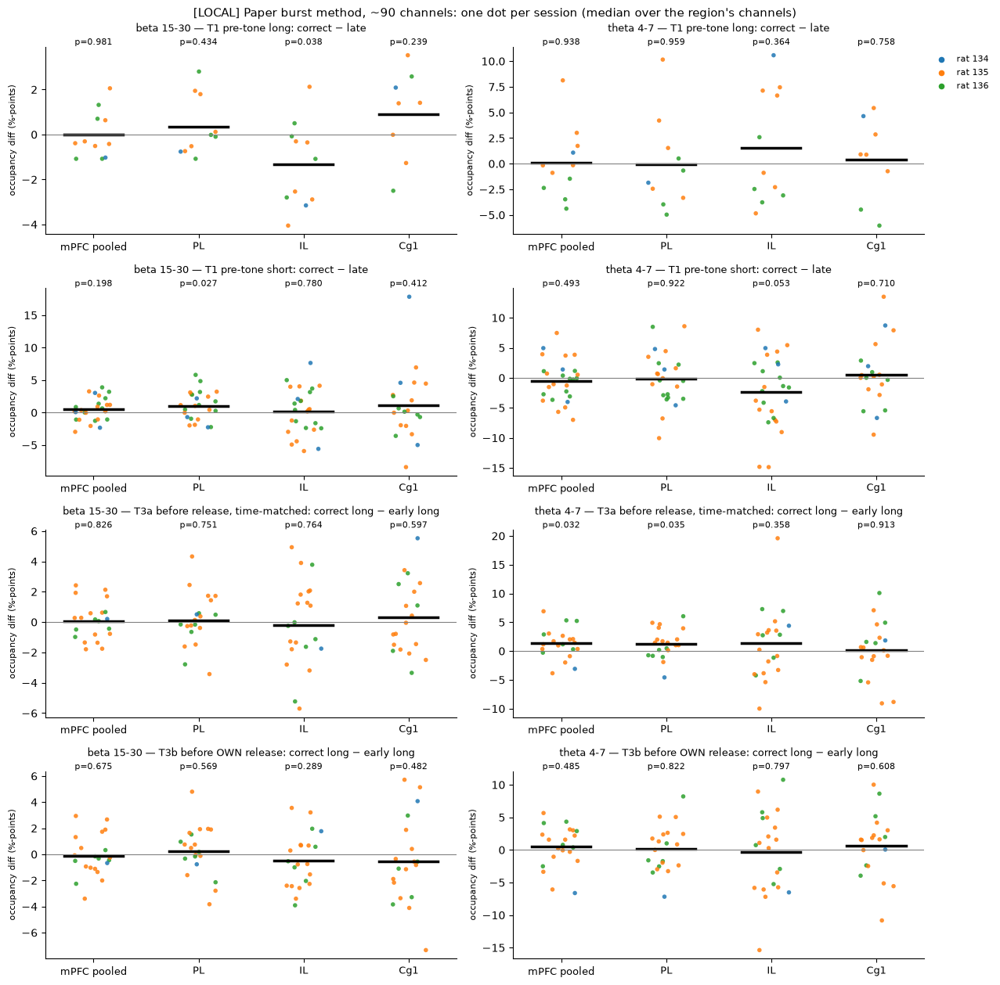

In [118]:
# ── 2.10 PAPER-STYLE BURST TESTS (Karvat 2021 burst method, ~90 channels/session from 2.8) — pooled mPFC + PL/IL/Cg1 ──
# needs 1.0 (lfm, rat_of, PROJECT). Run once with REF10 = "LOCAL", later with REF10 = "CMR" (when 2.8 CMR is done).
# T1  correct − late, pre-tone occupancy (long: tone −0.6..0 s; short: tone −0.3..0 s); only trials with RT >= 0.12 s
#     (paper: response window starts 120 ms after the stimulus -> the window is followed by >= 120 ms without release)
# T2  paper Fig. S6: trial occupancy (median over the region's channels) in the same window -> bins quiet 0 / low <=25 % /
#     medium <=50 % / high >50 % -> success rate per bin per session as % change from the session mean (PCM) -> one-way
#     ANOVA across bins (sessions as samples) + Tukey; RT per bin (correct, RT >= 0.12 s, timing_mismatch excluded) ->
#     one-way ANOVA across trials + Tukey (as the paper). + our checks: high − low (median split) success, Spearman occ-RT.
# T3  early vs correct BEFORE THE RELEASE: 500 ms ending 100 ms before release (release −0.6..−0.1 s; the 2.8 bins start
#     at −0.6 s, so the paper's 600 ms / 120 ms gap is approximated by 500 ms / 100 ms); early long with hold >= 0.6 s
#     (T3a) vs correct long at the SAME time after the press (time-matched) and (T3b) vs correct long before its OWN release.
# Values: occupancy %-points; per session = median over the region's channels; session = unit; sign-flip, raw p.
# + = more bursts in the FIRST condition (correct). Also per rat, leave-one-session-out (largest p without one session).
import glob, warnings
from scipy.stats import f_oneway, tukey_hsd, spearmanr
REF10 = "LOCAL"
K10_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021_channels" + ("" if REF10 == "LOCAL" else "_cmr"))
BIN, A0_10, MIN_C, MIN_E, MIN_RT = 0.05, -0.6, 10, 5, 0.12
BANDS10 = ("beta 15-30", "theta 4-7")
RN = {"Prelimbic area": "PL", "Infralimbic area": "IL", "Cingulate area 1": "Cg1"}
GROUPS = {"mPFC pooled": ("PL", "IL", "Cg1"), "PL": ("PL",), "IL": ("IL",), "Cg1": ("Cg1",)}
PRE10 = {"long": (-0.6, 0.0), "short": (-0.3, 0.0)}
OBINS = ["quiet", "low", "medium", "high"]
RAT_COL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}

def w10(O, a, z):
    i0, i1 = int(round((a - A0_10) / BIN)), int(round((z - A0_10) / BIN))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(O[:, :, max(i0, 0):i1], axis=2)            # (channels, trials)

def obin(o):
    return np.select([o <= 0, o <= 0.25, o <= 0.5], [0, 1, 2], default=3)

srows, trows = [], []
files = sorted(glob.glob(os.path.join(K10_DIR, "*.npz"))); print(REF10, "|", len(files), "session files")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for f in files:
        s = os.path.basename(f)[:-4]; Z = np.load(f, allow_pickle=True); T = pd.read_csv(f[:-4] + "_trials.csv")
        T["hold_s"] = T["release_s"] - T["press_s"]; T["rt_s"] = T["release_s"] - T["tone_s"]
        C = {k: v.values for k, v in lfm.main_conditions(T).items()}
        tm = T["timing_mismatch"].fillna(False).astype(bool).values if "timing_mismatch" in T else np.zeros(len(T), bool)
        rt, hold, rat = T["rt_s"].values, T["hold_s"].values, str(rat_of(s))
        reg = np.array([RN.get(r, "") for r in Z["region"]])
        rt_ok = ~(rt < MIN_RT)                                         # NaN (early) passes; RT < 0.12 s removed
        for band in BANDS10:
            P, To, Rl = Z[f"{band}|press|occ"], Z[f"{band}|tone|occ"], Z[f"{band}|release|occ"]
            for gname, regs in GROUPS.items():
                m = np.isin(reg, regs)
                if m.sum() < 3: continue
                base = dict(ref=REF10, session=s, rat=rat, band=band, group=gname, n_ch=int(m.sum()))
                for typ, (a, z) in PRE10.items():                                           # T1 + T2
                    O = w10(To[m], a, z)                                                    # (ch, trials)
                    cc = np.where(C[f"correct {typ}"] & rt_ok)[0]; lt = np.where(C[f"late {typ}"])[0]
                    if len(cc) >= MIN_E and len(lt) >= MIN_E:
                        srows.append({**base, "test": f"T1 pre-tone {typ}: correct − late",
                                      "value": 100 * np.nanmedian(np.nanmean(O[:, cc], 1) - np.nanmean(O[:, lt], 1))})
                    tri = np.concatenate([cc, lt])
                    if len(tri) >= 2 * MIN_E:
                        o = np.nanmedian(O[:, tri], axis=0)
                        trows.append(pd.DataFrame(dict(ref=REF10, session=s, rat=rat, band=band, group=gname, typ=typ, occ=o,
                                                       correct=np.isin(tri, cc), rt=rt[tri], tm=tm[tri])))
                cl = np.where(C["correct long"])[0]; el = np.where(C["early long (hold>0.3)"] & (hold >= 0.6))[0]   # T3
                if len(cl) >= MIN_C and len(el) >= MIN_E:
                    E_ = np.nanmean(w10(Rl[m][:, el], -0.6, -0.1), 1)
                    Cm = np.nanmean(np.stack([np.nanmean(w10(P[m][:, cl], h - 0.6, h - 0.1), 1) for h in hold[el]]), 0)
                    Co = np.nanmean(w10(Rl[m][:, cl], -0.6, -0.1), 1)
                    srows.append({**base, "test": "T3a before release, time-matched: correct long − early long", "value": 100 * np.nanmedian(Cm - E_)})
                    srows.append({**base, "test": "T3b before OWN release: correct long − early long", "value": 100 * np.nanmedian(Co - E_)})
V10 = pd.DataFrame(srows); TR10 = pd.concat(trows, ignore_index=True)
V10.to_csv(os.path.join(K10_DIR, f"_session_values_2_10_{REF10}.csv"), index=False)
TR10.to_csv(os.path.join(K10_DIR, f"_trials_2_10_{REF10}.csv"), index=False)

# ── our checks for T2 (session = unit): high − low success (median split), Spearman occupancy vs RT ──
for (band, gname, s, typ), g in TR10.groupby(["band", "group", "session", "typ"]):
    base = dict(ref=REF10, session=s, rat=g["rat"].iat[0], band=band, group=gname, n_ch=np.nan)
    hi = g["occ"] > g["occ"].median()
    if hi.sum() >= MIN_E and (~hi).sum() >= MIN_E:
        V10.loc[len(V10)] = {**base, "test": f"T2c success, high − low occupancy ({typ})", "value": 100 * (g.loc[hi, "correct"].mean() - g.loc[~hi, "correct"].mean())}
    gc = g[g["correct"] & ~g["tm"]]
    if len(gc) >= 10 and gc["occ"].nunique() > 2:
        V10.loc[len(V10)] = {**base, "test": f"T2d Spearman occupancy vs RT, correct ({typ})", "value": spearmanr(gc["occ"], gc["rt"]).correlation}

# ── sign-flip per test, all rats + per rat, + leave-one-session-out ──
out = []
for (test, band, gname), g in V10.groupby(["test", "band", "group"], sort=False):
    for rat in ["all"] + sorted(V10["rat"].unique()):
        gg = g if rat == "all" else g[g["rat"] == rat]
        mn, p, n = lfm.sign_flip_p(gg["value"].values)
        loo_p, loo_s = np.nan, ""
        if rat == "all" and n >= 4:
            lp = [(lfm.sign_flip_p(gg["value"].drop(i).values, n_perm=2000)[1], gg.loc[i, "session"]) for i in gg.index]
            loo_p, loo_s = max(lp)
        out.append(dict(ref=REF10, test=test, band=band, group=gname, rat=rat, n=n, mean=mn, p=p, n_pos=int((gg["value"] > 0).sum()),
                        loo_max_p=loo_p, loo_session=loo_s))
S10 = pd.DataFrame(out); S10.to_csv(os.path.join(K10_DIR, f"_stats_2_10_{REF10}.csv"), index=False)
S10["cell"] = S10.apply(lambda x: (f"{x['mean']:+.2f} [p {x['p']:.3f}] ({x['n_pos']}/{x['n']})" if x["n"] >= 2 else "—")
                        + (f" | LOO max p {x['loo_max_p']:.3f} (without {x['loo_session'][:8]}_{x['loo_session'][13:16]})"
                           if x["rat"] == "all" and np.isfinite(x["loo_max_p"]) else ""), axis=1)
pd.set_option("display.width", 280); pd.set_option("display.max_colwidth", 90)
print("values: occupancy %-points (T2c success %-points, T2d rho); + = more in correct / higher success / slower; raw p, sign-flip")
for test in S10["test"].unique():
    d = S10[S10["test"] == test]
    tab = d.pivot_table(index=["band", "group"], columns="rat", values="cell", aggfunc="first", sort=False)
    print(f"\n===== [{REF10}] {test} =====")
    print(tab[["all"] + [c for c in ["134", "135", "136"] if c in tab.columns]].reindex(
        [(b, g) for b in BANDS10 for g in GROUPS if (b, g) in tab.index]).to_string())

# ── T2 paper statistics: PCM per bin + one-way ANOVA + Tukey (success: sessions; RT: trials) ──
TR10["obin"] = obin(TR10["occ"].values)
print(f"\n===== [{REF10}] T2 paper Fig. S6: success rate per occupancy bin as % change from session mean (PCM) =====")
arows = []
for (band, gname, typ), g in TR10.groupby(["band", "group", "typ"], sort=False):
    ps = g.groupby(["session", "obin"])["correct"].agg(["mean", "size"]).reset_index()
    ps = ps[ps["size"] >= 3]
    sm = g.groupby("session")["correct"].mean()
    ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
    grp = [ps.loc[ps["obin"] == b, "pcm"].dropna().values for b in range(4)]
    grp_ok = [x for x in grp if len(x) >= 3]
    F, pA = f_oneway(*grp_ok) if len(grp_ok) >= 2 else (np.nan, np.nan)
    tk = ""
    if len(grp_ok) >= 2 and pA < 0.05:
        lab = [OBINS[b] for b in range(4) if len(grp[b]) >= 3]; res = tukey_hsd(*grp_ok)
        tk = "; ".join(f"{lab[i]}-{lab[j]} p={res.pvalue[i, j]:.3f}" for i in range(len(lab)) for j in range(i + 1, len(lab)) if res.pvalue[i, j] < 0.05)
    gr = g[g["correct"] & ~g["tm"]]                                       # RT, trials as samples (as the paper)
    rg = [gr.loc[gr["obin"] == b, "rt"].values * 1000 for b in range(4)]
    rg_ok = [x for x in rg if len(x) >= 10]
    Fr, pR = f_oneway(*rg_ok) if len(rg_ok) >= 2 else (np.nan, np.nan)
    tkr = ""
    if len(rg_ok) >= 2 and pR < 0.05:
        lab = [OBINS[b] for b in range(4) if len(rg[b]) >= 10]; res = tukey_hsd(*rg_ok)
        tkr = "; ".join(f"{lab[i]}-{lab[j]} p={res.pvalue[i, j]:.3f}" for i in range(len(lab)) for j in range(i + 1, len(lab)) if res.pvalue[i, j] < 0.05)
    arows.append(dict(band=band, group=gname, typ=typ,
                      **{f"PCM {OBINS[b]} (n)": (f"{np.mean(grp[b]):+.1f} ({len(grp[b])})" if len(grp[b]) else "—") for b in range(4)},
                      ANOVA_success=f"F={F:.2f} p={pA:.3f}" if np.isfinite(F) else "—", Tukey_success=tk,
                      **{f"RT {OBINS[b]} ms (n)": (f"{np.mean(rg[b]):.0f} ({len(rg[b])})" if len(rg[b]) else "—") for b in range(4)},
                      ANOVA_RT=f"F={Fr:.2f} p={pR:.3f}" if np.isfinite(Fr) else "—", Tukey_RT=tkr))
A10 = pd.DataFrame(arows); A10.to_csv(os.path.join(K10_DIR, f"_anova_2_10_{REF10}.csv"), index=False)
print(A10.to_string(index=False))

# ── figure: one dot per session (colour = rat) for the main tests; black bar = mean ──
TF = [t for t in ["T1 pre-tone long: correct − late", "T1 pre-tone short: correct − late",
                  "T3a before release, time-matched: correct long − early long", "T3b before OWN release: correct long − early long"]
      if t in V10["test"].unique()]
fig, axes = plt.subplots(len(TF), 2, figsize=(13, 3.2 * len(TF)), squeeze=False)
for i, test in enumerate(TF):
    for j, band in enumerate(BANDS10):
        ax = axes[i, j]; d = V10[(V10["test"] == test) & (V10["band"] == band)]
        for k, gname in enumerate(GROUPS):
            dd = d[d["group"] == gname]
            xj = k + np.random.default_rng(k).uniform(-0.18, 0.18, len(dd))
            ax.scatter(xj, dd["value"], s=16, c=[RAT_COL.get(r, "k") for r in dd["rat"]], alpha=0.85, lw=0)
            if len(dd): ax.plot([k - 0.28, k + 0.28], [dd["value"].mean()] * 2, color="k", lw=2.5)
            st = S10[(S10["test"] == test) & (S10["band"] == band) & (S10["group"] == gname) & (S10["rat"] == "all")]
            if len(st): ax.text(k, 1.0, f"p={st['p'].iat[0]:.3f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(list(GROUPS), fontsize=9)
        ax.set_title(f"{band} — {test}", fontsize=9, pad=14); ax.set_ylabel("occupancy diff (%-points)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for r, c in RAT_COL.items(): axes[0, 1].scatter([], [], c=c, s=20, label=f"rat {r}")
axes[0, 1].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle(f"[{REF10}] Paper burst method, ~90 channels: one dot per session (median over the region's channels)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(K10_DIR, f"2_10_sessions_{REF10}.png"), dpi=140, bbox_inches="tight"); plt.show()

59 session files
one channel per region (paper-style); values: occupancy %-points (T2c success %-points, T2d rho); LOO = largest p without one session

===== T1 pre-tone short: correct − late =====
ref                                                LOCAL                                                                                                       CMR                                                                        
rat                                                  all                     134                     135                     136                               all                     134                     135                     136
band       group                                                                                                                                                                                                                          
beta 15-30 mPFC pooled  -0.56 [p 0.686] (15/26) LOO 0.99   -3.33 [p 0.491] (1/3)  -0.83 [p 0.719]

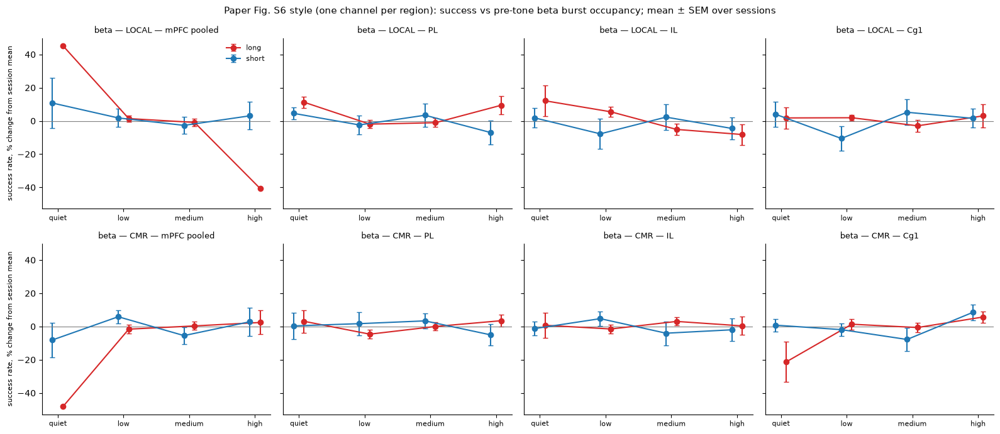

In [119]:
# ── 2.11 PAPER-EXACT BURST TESTS on the 2.6 files: ONE channel per region (as the paper), exact windows, CMR and LOCAL ──
# needs 1.0 (lfm, rat_of, PROJECT). Karvat 2021 burst method only (no NeuroDSP). Same tests as 2.10:
# T1  correct − late, pre-tone occupancy (long tone −0.6..0 s = paper's 600 ms; short tone −0.3..0 s); RT >= 0.12 s
# T2  paper Fig. S6 with the paper's ONE-channel trial occupancy -> bins quiet 0 / low <=25 % / medium <=50 % / high >50 %
#     -> success per bin as PCM -> one-way ANOVA + Tukey (sessions); RT per bin (correct, RT >= 0.12, no timing_mismatch)
#     -> one-way ANOVA + Tukey (trials) ; + our checks T2c high − low success, T2d Spearman occupancy vs RT
# T3  early vs correct before the release: 600 ms ending 150 ms before the release (release −0.75..−0.15 s; 50-ms bins,
#     so the paper's ">= 120 ms gap" becomes 150 ms); early long with hold >= 0.75 s; T3a correct at the same time after
#     the press (time-matched), T3b correct before its own release (same window).
# "mPFC pooled" = mean of the available region channels (PL, IL, Cg1) per trial. Session = unit, sign-flip, raw p,
# per rat, leave-one-session-out. + = more bursts in correct / higher success / slower RT.
import glob, warnings
from scipy.stats import f_oneway, tukey_hsd, spearmanr
K_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021")
BIN, MIN_C, MIN_E, MIN_RT = 0.05, 10, 5, 0.12
A0 = {"press": -1.5, "tone": -1.0, "release": -1.5}
REFS11, BANDS11, REGS11 = ("LOCAL", "CMR"), ("beta 15-30", "theta 4-7"), ("PL", "IL", "Cg1")
GROUPS11 = ["mPFC pooled", "PL", "IL", "Cg1"]
PRE11 = {"long": (-0.6, 0.0), "short": (-0.3, 0.0)}
W_REL = (-0.75, -0.15)
OBINS = ["quiet", "low", "medium", "high"]
RAT_COL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}

def win1(O, al, a, z):
    """O (trials, bins) -> mean over the 50-ms bins in [a, z) -> (trials,)"""
    i0, i1 = int(round((a - A0[al]) / BIN)), int(round((z - A0[al]) / BIN))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(O[:, max(i0, 0):i1], axis=1)

def obin(o):
    return np.select([o <= 0, o <= 0.25, o <= 0.5], [0, 1, 2], default=3)

srows, trows = [], []
files = sorted(glob.glob(os.path.join(K_DIR, "*.npz"))); print(len(files), "session files")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for f in files:
        s = os.path.basename(f)[:-4]; Z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
        T["hold_s"] = T["release_s"] - T["press_s"]; T["rt_s"] = T["release_s"] - T["tone_s"]
        C = {k: v.values for k, v in lfm.main_conditions(T).items()}
        tm = T["timing_mismatch"].fillna(False).astype(bool).values if "timing_mismatch" in T else np.zeros(len(T), bool)
        rt, hold, rat = T["rt_s"].values, T["hold_s"].values, str(rat_of(s)); rt_ok = ~(rt < MIN_RT)
        cl = np.where(C["correct long"])[0]; el = np.where(C["early long (hold>0.3)"] & (hold >= -W_REL[0]))[0]
        for ref in REFS11:
            for band in BANDS11:
                pre, rel_e, rel_c, tmatch = {}, {}, {}, {}                     # per region: trial vectors
                for reg in REGS11:
                    key = f"{ref}|karvat2021|{band}|{reg}"
                    if key + "|tone|occ" not in Z.files: continue
                    Op, Ot, Orl = Z[key + "|press|occ"], Z[key + "|tone|occ"], Z[key + "|release|occ"]
                    pre[reg] = {typ: win1(Ot, "tone", a, z) for typ, (a, z) in PRE11.items()}
                    rel_e[reg] = win1(Orl, "release", *W_REL)
                    tmatch[reg] = np.stack([win1(Op, "press", h + W_REL[0], h + W_REL[1]) for h in hold[el]]) if len(el) else None
                if not pre: continue
                groups = {g: [g] for g in REGS11 if g in pre}; groups["mPFC pooled"] = list(pre)
                for gname, regs in groups.items():
                    base = dict(ref=ref, session=s, rat=rat, band=band, group=gname)
                    for typ in PRE11:                                                     # T1 + T2
                        o = np.nanmean(np.stack([pre[r][typ] for r in regs]), 0)
                        cc = np.where(C[f"correct {typ}"] & rt_ok)[0]; lt = np.where(C[f"late {typ}"])[0]
                        if len(cc) >= MIN_E and len(lt) >= MIN_E:
                            srows.append({**base, "test": f"T1 pre-tone {typ}: correct − late", "value": 100 * (np.nanmean(o[cc]) - np.nanmean(o[lt]))})
                        tri = np.concatenate([cc, lt])
                        if len(tri) >= 2 * MIN_E:
                            trows.append(pd.DataFrame(dict(ref=ref, session=s, rat=rat, band=band, group=gname, typ=typ, occ=o[tri],
                                                           correct=np.isin(tri, cc), rt=rt[tri], tm=tm[tri])))
                    if len(cl) >= MIN_C and len(el) >= MIN_E:                              # T3
                        E_ = np.nanmean(np.stack([rel_e[r][el] for r in regs]))
                        Cm = np.nanmean(np.stack([tmatch[r][:, cl] for r in regs]))
                        Co = np.nanmean(np.stack([rel_e[r][cl] for r in regs]))
                        srows.append({**base, "test": "T3a before release (−0.75..−0.15 s), time-matched: correct long − early long", "value": 100 * (Cm - E_)})
                        srows.append({**base, "test": "T3b before OWN release (−0.75..−0.15 s): correct long − early long", "value": 100 * (Co - E_)})
V11 = pd.DataFrame(srows); TR11 = pd.concat(trows, ignore_index=True)
for (ref, band, gname, s, typ), g in TR11.groupby(["ref", "band", "group", "session", "typ"]):                # T2c, T2d
    base = dict(ref=ref, session=s, rat=g["rat"].iat[0], band=band, group=gname)
    hi = g["occ"] > g["occ"].median()
    if hi.sum() >= MIN_E and (~hi).sum() >= MIN_E:
        V11.loc[len(V11)] = {**base, "test": f"T2c success, high − low occupancy ({typ})", "value": 100 * (g.loc[hi, "correct"].mean() - g.loc[~hi, "correct"].mean())}
    gc = g[g["correct"] & ~g["tm"]]
    if len(gc) >= 10 and gc["occ"].nunique() > 2:
        V11.loc[len(V11)] = {**base, "test": f"T2d Spearman occupancy vs RT, correct ({typ})", "value": spearmanr(gc["occ"], gc["rt"]).correlation}
V11.to_csv(os.path.join(K_DIR, "_session_values_2_11.csv"), index=False); TR11.to_csv(os.path.join(K_DIR, "_trials_2_11.csv"), index=False)

out = []
for (test, ref, band, gname), g in V11.groupby(["test", "ref", "band", "group"], sort=False):
    for rat in ["all"] + sorted(V11["rat"].unique()):
        gg = g if rat == "all" else g[g["rat"] == rat]
        mn, p, n = lfm.sign_flip_p(gg["value"].values)
        loo_p, loo_s = np.nan, ""
        if rat == "all" and n >= 4:
            loo_p, loo_s = max((lfm.sign_flip_p(gg["value"].drop(i).values, n_perm=2000)[1], gg.loc[i, "session"]) for i in gg.index)
        out.append(dict(test=test, ref=ref, band=band, group=gname, rat=rat, n=n, mean=mn, p=p, n_pos=int((gg["value"] > 0).sum()),
                        loo_max_p=loo_p, loo_session=loo_s))
S11 = pd.DataFrame(out); S11.to_csv(os.path.join(K_DIR, "_stats_2_11.csv"), index=False)
S11["cell"] = S11.apply(lambda x: (f"{x['mean']:+.2f} [p {x['p']:.3f}] ({x['n_pos']}/{x['n']})" if x["n"] >= 2 else "—")
                        + (f" LOO {x['loo_max_p']:.2f}" if x["rat"] == "all" and np.isfinite(x["loo_max_p"]) else ""), axis=1)
pd.set_option("display.width", 300); pd.set_option("display.max_colwidth", 60)
print("one channel per region (paper-style); values: occupancy %-points (T2c success %-points, T2d rho); LOO = largest p without one session")
for test in S11["test"].unique():
    d = S11[S11["test"] == test]
    tab = d.pivot_table(index=["band", "group"], columns=["ref", "rat"], values="cell", aggfunc="first", sort=False)
    cols = [(r, k) for r in REFS11 for k in ["all", "134", "135", "136"] if (r, k) in tab.columns]
    print(f"\n===== {test} =====")
    print(tab[cols].reindex([(b, g) for b in BANDS11 for g in GROUPS11 if (b, g) in tab.index]).to_string())

TR11["obin"] = obin(TR11["occ"].values)
print("\n===== T2 paper Fig. S6 (one channel): success per occupancy bin as PCM + one-way ANOVA + Tukey; RT per bin + ANOVA + Tukey =====")
arows = []
for (ref, band, gname, typ), g in TR11.groupby(["ref", "band", "group", "typ"], sort=False):
    ps = g.groupby(["session", "obin"])["correct"].agg(["mean", "size"]).reset_index(); ps = ps[ps["size"] >= 3]
    sm = g.groupby("session")["correct"].mean(); ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
    grp = [ps.loc[ps["obin"] == b, "pcm"].dropna().values for b in range(4)]; ok = [x for x in grp if len(x) >= 3]
    F, pA = f_oneway(*ok) if len(ok) >= 2 else (np.nan, np.nan); tk = ""
    if len(ok) >= 2 and pA < 0.05:
        lab = [OBINS[b] for b in range(4) if len(grp[b]) >= 3]; res = tukey_hsd(*ok)
        tk = "; ".join(f"{lab[i]}-{lab[j]} p={res.pvalue[i, j]:.3f}" for i in range(len(lab)) for j in range(i + 1, len(lab)) if res.pvalue[i, j] < 0.05)
    gr = g[g["correct"] & ~g["tm"]]; rg = [gr.loc[gr["obin"] == b, "rt"].values * 1000 for b in range(4)]; rok = [x for x in rg if len(x) >= 10]
    Fr, pR = f_oneway(*rok) if len(rok) >= 2 else (np.nan, np.nan); tkr = ""
    if len(rok) >= 2 and pR < 0.05:
        lab = [OBINS[b] for b in range(4) if len(rg[b]) >= 10]; res = tukey_hsd(*rok)
        tkr = "; ".join(f"{lab[i]}-{lab[j]} p={res.pvalue[i, j]:.3f}" for i in range(len(lab)) for j in range(i + 1, len(lab)) if res.pvalue[i, j] < 0.05)
    arows.append(dict(ref=ref, band=band, group=gname, typ=typ,
                      **{f"PCM {OBINS[b]}": (f"{np.mean(grp[b]):+.1f} ({len(grp[b])})" if len(grp[b]) else "—") for b in range(4)},
                      ANOVA_success=f"F={F:.2f} p={pA:.3f}" if np.isfinite(F) else "—", Tukey_success=tk,
                      **{f"RT {OBINS[b]}": (f"{np.mean(rg[b]):.0f} ({len(rg[b])})" if len(rg[b]) else "—") for b in range(4)},
                      ANOVA_RT=f"F={Fr:.2f} p={pR:.3f}" if np.isfinite(Fr) else "—", Tukey_RT=tkr))
A11 = pd.DataFrame(arows); A11.to_csv(os.path.join(K_DIR, "_anova_2_11.csv"), index=False)
print(A11.to_string(index=False))

# ── figure: paper Fig. S6 style — success PCM per bin (mean ± SEM over sessions), beta, LOCAL and CMR, pooled + regions ──
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, squeeze=False)
for i, ref in enumerate(REFS11):
    for j, gname in enumerate(GROUPS11):
        ax = axes[i, j]; g = TR11[(TR11.ref == ref) & (TR11.band == "beta 15-30") & (TR11.group == gname)]
        for typ, col in (("long", "#d62728"), ("short", "#1f77b4")):
            gg = g[g.typ == typ]
            if not len(gg): continue
            ps = gg.groupby(["session", "obin"])["correct"].agg(["mean", "size"]).reset_index(); ps = ps[ps["size"] >= 3]
            sm = gg.groupby("session")["correct"].mean(); ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
            st = ps.groupby("obin")["pcm"].agg(["mean", "sem", "size"]).reindex(range(4))
            ax.errorbar(np.arange(4) + (0.08 if typ == "long" else -0.08), st["mean"], yerr=st["sem"], marker="o", color=col, capsize=3, label=typ)
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels(OBINS, fontsize=8)
        ax.set_title(f"beta — {ref} — {gname}", fontsize=9)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        if j == 0: ax.set_ylabel("success rate, % change from session mean", fontsize=8)
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle("Paper Fig. S6 style (one channel per region): success vs pre-tone beta burst occupancy; mean ± SEM over sessions", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(K_DIR, "2_11_S6_beta.png"), dpi=140, bbox_inches="tight"); plt.show()

[LOCAL] % of channels per session with late > correct (paper direction): median [IQR] over sessions; n sessions
                        pct_ch_paper  sessions median_value
band       typ   region                                    
beta 15-30 long  Cg1     47% [41–53]         8        +1.40
                 IL      56% [50–73]        11        -1.08
                 PL      51% [46–55]        10        -0.06
           short Cg1     50% [42–55]        20        +0.23
                 IL      50% [35–64]        26        +0.42
                 PL      46% [42–53]        24        +1.10
theta 4-7  long  Cg1     45% [43–51]         8        +0.90
                 IL      50% [35–54]        11        -0.89
                 PL      53% [45–58]        10        -1.26
           short Cg1     49% [37–56]        20        +0.12
                 IL      60% [42–72]        26        -1.92
                 PL      51% [46–57]        24        -0.25


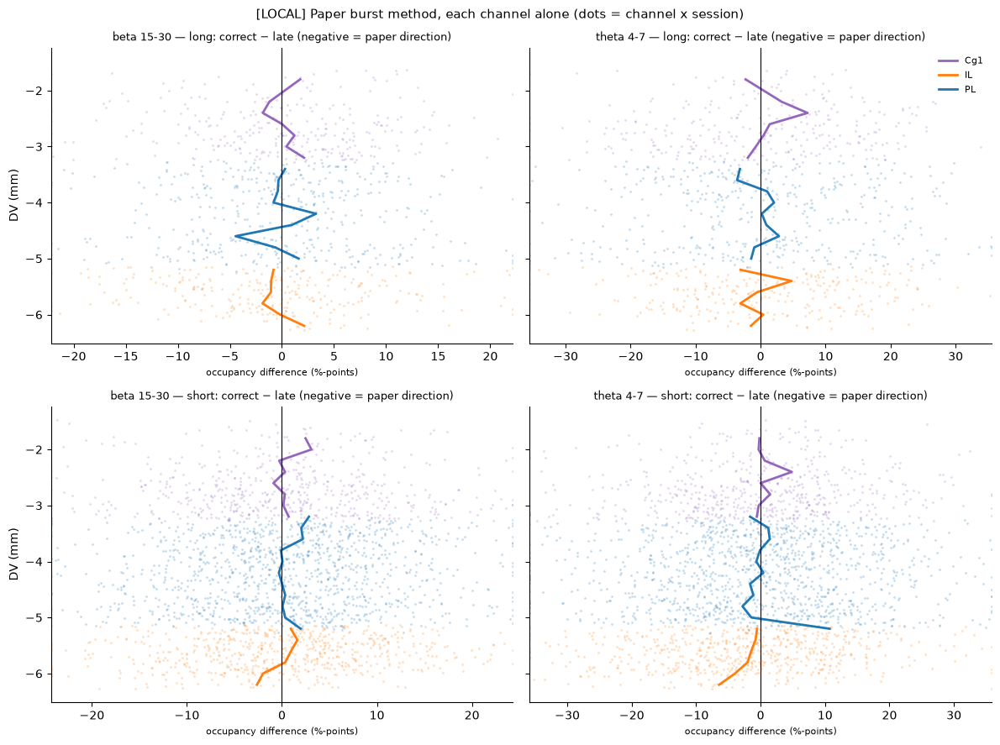

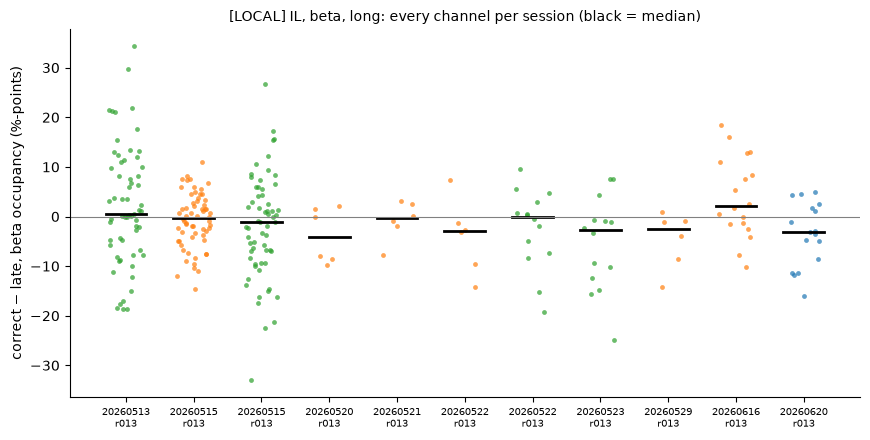

In [120]:
# ── 2.12 EACH CHANNEL ALONE: T1 correct − late before the tone (paper's main test), 2.8 data (~90 channels/session) ──
# needs 1.0 (lfm, rat_of, PROJECT). Same rules as 2.10/2.11 T1: long tone −0.6..0 s, short tone −0.3..0 s, correct RT >= 0.12 s,
# >= 5 correct and >= 5 late trials. Value per channel = occupancy(correct) − occupancy(late), %-points (negative = paper direction).
import glob, warnings
REF12 = "LOCAL"                                          # later "CMR"
K12_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021_channels" + ("" if REF12 == "LOCAL" else "_cmr"))
RN = {"Prelimbic area": "PL", "Infralimbic area": "IL", "Cingulate area 1": "Cg1"}
REG_COL = {"PL": "#1f77b4", "IL": "#ff7f0e", "Cg1": "#9467bd"}
PRE12 = {"long": (-0.6, 0.0), "short": (-0.3, 0.0)}
def w12(O, a, z):                                        # O (channels, trials, bins from −0.6 s, 50 ms)
    i0, i1 = int(round((a + 0.6) / 0.05)), int(round((z + 0.6) / 0.05))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(O[:, :, max(i0, 0):i1], axis=2)
rows = []
for f in sorted(glob.glob(os.path.join(K12_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; Z = np.load(f, allow_pickle=True); T = pd.read_csv(f[:-4] + "_trials.csv")
    T["hold_s"] = T["release_s"] - T["press_s"]; rt = (T["release_s"] - T["tone_s"]).values
    C = {k: v.values for k, v in lfm.main_conditions(T).items()}
    reg = np.array([RN.get(r, "") for r in Z["region"]]); dv = Z["dv_mm"]
    for band in ("beta 15-30", "theta 4-7"):
        To = Z[f"{band}|tone|occ"]
        for typ, (a, z) in PRE12.items():
            cc = np.where(C[f"correct {typ}"] & ~(rt < 0.12))[0]; lt = np.where(C[f"late {typ}"])[0]
            if len(cc) < 5 or len(lt) < 5: continue
            O = w12(To, a, z)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                v = 100 * (np.nanmean(O[:, cc], 1) - np.nanmean(O[:, lt], 1))
            rows.append(pd.DataFrame(dict(session=s, rat=str(rat_of(s)), band=band, typ=typ, region=reg, dv_mm=dv,
                                          ch=Z["channel_ids"], value=v)))
CH12 = pd.concat(rows, ignore_index=True); CH12 = CH12[CH12["region"] != ""]
CH12.to_csv(os.path.join(K12_DIR, f"_channel_values_2_12_{REF12}.csv"), index=False)

# per region: share of a session's channels in the paper direction (late > correct), median over sessions
SS = (CH12.groupby(["band", "typ", "region", "session", "rat"])["value"]
          .agg(frac_paper=lambda v: 100 * np.mean(v < 0), med="median", n_ch="size").reset_index())
print(f"[{REF12}] % of channels per session with late > correct (paper direction): median [IQR] over sessions; n sessions")
print(SS.groupby(["band", "typ", "region"]).agg(
    pct_ch_paper=("frac_paper", lambda v: f"{np.median(v):.0f}% [{np.percentile(v, 25):.0f}–{np.percentile(v, 75):.0f}]"),
    sessions=("session", "nunique"), median_value=("med", lambda v: f"{np.median(v):+.2f}")).to_string())

# figure 1: every channel x session vs depth (DV); lines = median per region per 0.2 mm
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True, squeeze=False)
for i, typ in enumerate(("long", "short")):
    for j, band in enumerate(("beta 15-30", "theta 4-7")):
        ax = axes[i, j]; d = CH12[(CH12.typ == typ) & (CH12.band == band)]
        lim = np.nanpercentile(np.abs(d["value"]), 98) if len(d) else 1
        for r, g in d.groupby("region"):
            ax.scatter(g["value"].clip(-lim, lim), g["dv_mm"], s=4, alpha=0.25, color=REG_COL[r], lw=0)
            b = (g["dv_mm"] / 0.2).round() * 0.2; m = g.groupby(b)["value"].median()[g.groupby(b).size() >= 15]
            ax.plot(m.values, m.index, color=REG_COL[r], lw=2, label=r)
        ax.axvline(0, color="k", lw=0.8); ax.set_xlim(-lim, lim)
        ax.set_title(f"{band} — {typ}: correct − late (negative = paper direction)", fontsize=9)
        ax.set_xlabel("occupancy difference (%-points)", fontsize=8)
        if j == 0: ax.set_ylabel("DV (mm)")
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 1].legend(fontsize=8, frameon=False)
fig.suptitle(f"[{REF12}] Paper burst method, each channel alone (dots = channel x session)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(K12_DIR, f"2_12_channels_depth_{REF12}.png"), dpi=140, bbox_inches="tight"); plt.show()

# figure 2: IL, beta, long — each session's channels separately (is the IL effect carried by many channels or a few?)
d = CH12[(CH12.band == "beta 15-30") & (CH12.typ == "long") & (CH12.region == "IL")]
ses = sorted(d["session"].unique())
fig, ax = plt.subplots(figsize=(max(6, 0.8 * len(ses)), 4.5))
for k, s in enumerate(ses):
    g = d[d.session == s]
    ax.scatter(k + np.random.default_rng(k).uniform(-0.25, 0.25, len(g)), g["value"], s=12, alpha=0.7,
               color={"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}[g["rat"].iat[0]], lw=0)
    ax.plot([k - 0.3, k + 0.3], [g["value"].median()] * 2, color="k", lw=2)
ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(len(ses))); ax.set_xticklabels([f"{x[:8]}\nr{x[13:16]}" for x in ses], fontsize=7)
ax.set_ylabel("correct − late, beta occupancy (%-points)"); ax.set_title(f"[{REF12}] IL, beta, long: every channel per session (black = median)", fontsize=10)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(K12_DIR, f"2_12_IL_beta_long_{REF12}.png"), dpi=140, bbox_inches="tight"); plt.show()

In [7]:
# ── 3.0 data part: settings + trial tables from the saved 2.6 files (no recomputation) ──
import glob, warnings
K_DIR   = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021")    # input (2.6, do not rerun)
OUT3    = os.path.join(PROJECT, "data", "analysis_main", "bursts_main")
os.makedirs(OUT3, exist_ok=True)
BAND3   = "beta 15-30"
REFS3   = ("CMR", "LOCAL")
REGS3   = ("PL", "IL", "Cg1")
GROUPS3 = ("mPFC pooled",) + REGS3
PRE3    = {"long": (-0.6, 0.0), "short": (-0.3, 0.0)}
W_REL3  = (-0.75, -0.15)
BIN3    = 0.05
A0_3    = {"press": -1.5, "tone": -1.0, "release": -1.5}
MIN_RT3, MIN_TR3 = 0.12, 5

def win3(O, al, a, z):
    i0, i1 = int(round((a - A0_3[al]) / BIN3)), int(round((z - A0_3[al]) / BIN3))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(O[:, max(i0, 0):i1], axis=1)

def add_pooled(d):
    d["mPFC pooled"] = np.nanmean(np.stack(list(d.values())), axis=0)
    return d

rows, erows, drop = [], [], []
files = sorted(glob.glob(os.path.join(K_DIR, "*.npz")))
print(len(files), "session files in", K_DIR)
for f in files:
    s = os.path.basename(f)[:-4]; Z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
    T["hold_s"] = T["release_s"] - T["press_s"]; T["rt_s"] = T["release_s"] - T["tone_s"]
    C = {k: v.values for k, v in lfm.main_conditions(T).items()}
    tm = T["timing_mismatch"].fillna(False).astype(bool).values
    rt, hold, rat = T["rt_s"].values, T["hold_s"].values, str(rat_of(s))
    cl = np.where(C["correct long"] & (rt >= MIN_RT3) & ~tm)[0]
    el = np.where(C["early long (hold>0.3)"] & (hold >= -W_REL3[0]) & ~tm)[0]
    for ref in REFS3:
        key = {reg: f"{ref}|karvat2021|{BAND3}|{reg}" for reg in REGS3 if f"{ref}|karvat2021|{BAND3}|{reg}|tone|occ" in Z.files}
        if not key: continue
        for typ, (a, z) in PRE3.items():                                                     # late test
            idx = np.where((C[f"correct {typ}"] & (rt >= MIN_RT3) | C[f"late {typ}"]) & ~tm)[0]
            if not len(idx): continue
            o = add_pooled({reg: win3(Z[k + "|tone|occ"], "tone", a, z)[idx] for reg, k in key.items()})
            for g in GROUPS3:
                if g in o:
                    rows.append(pd.DataFrame(dict(session=s, rat=rat, ref=ref, group=g, typ=typ, trial=idx,
                                                  cond=np.where(T["outcome"].values[idx] == "correct", "correct", "late"),
                                                  rt=rt[idx], occ=o[g], n_regions=len(key) if g == "mPFC pooled" else 1)))
        if len(el) and len(cl):                                                              # early test (long)
            e_  = add_pooled({reg: win3(Z[k + "|release|occ"], "release", *W_REL3)[el] for reg, k in key.items()})
            own = add_pooled({reg: win3(Z[k + "|release|occ"], "release", *W_REL3)[cl] for reg, k in key.items()})
            tmx = add_pooled({reg: np.nanmean(np.stack([win3(Z[k + "|press|occ"], "press", h + W_REL3[0], h + W_REL3[1])[cl]
                                                        for h in hold[el]]), axis=0) for reg, k in key.items()})
            for g in GROUPS3:
                if g not in e_: continue
                for cond, tri, v in (("early long", el, e_[g]), ("correct long, time-matched", cl, tmx[g]),
                                     ("correct long, own release", cl, own[g])):
                    erows.append(pd.DataFrame(dict(session=s, rat=rat, ref=ref, group=g, typ="long", trial=tri, cond=cond,
                                                   hold=hold[tri], occ=v)))
TR3 = pd.concat(rows, ignore_index=True);  TR3.to_csv(os.path.join(OUT3, "_trials_3_0_late.csv"), index=False)
TE3 = pd.concat(erows, ignore_index=True); TE3.to_csv(os.path.join(OUT3, "_trials_3_0_early.csv"), index=False)

def usable(df, a, b):
    n = df.groupby(["ref", "typ", "session", "rat"])["cond"].agg(**{"n_" + a: lambda x: (x == a).sum(),
                                                                    "n_" + b: lambda x: (x == b).sum()}).reset_index()
    n["usable"] = (n["n_" + a] >= MIN_TR3) & (n["n_" + b] >= MIN_TR3)
    return n
nL = usable(TR3[TR3.group == "mPFC pooled"], "correct", "late")
nE = usable(TE3[(TE3.group == "mPFC pooled") & (TE3.cond != "correct long, own release")], "correct long, time-matched", "early long")
print("TR3:", len(TR3), "rows | TE3:", len(TE3), "rows | usable late sessions (long, CMR):",
      int(nL[(nL.ref == "CMR") & (nL.typ == "long")].usable.sum()))

59 session files in O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\analysis_main\bursts_karvat2021
TR3: 15834 rows | TE3: 11278 rows | usable late sessions (long, CMR): 11


In [24]:
print([n for n in ["TR3", "TE3", "nL", "nE"] if n not in globals()])

[]


In [129]:
# ── 3.0a CHECKS that 3.0 reads the 2.6 files correctly (run after 3.0; reads files only, computes nothing new) ──
# needs 1.0 (TABLES, BP_DIR), 3.0 (K_DIR, OUT3, BAND3, REFS3, REGS3, PRE3, win3, MIN_RT3, lfm, rat_of).
import glob
REG_FULL = {"PL": "Prelimbic area", "IL": "Infralimbic area", "Cg1": "Cingulate area 1"}
CHR = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
REPC = pd.read_csv(os.path.join(BP_DIR, "_representative_channels.csv"))
has_id = "channel_id" in CHR.columns
chk, ch = [], []
for f in sorted(glob.glob(os.path.join(K_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; Z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
    T["hold_s"] = T["release_s"] - T["press_s"]; T["rt_s"] = T["release_s"] - T["tone_s"]
    C = {k: v.values for k, v in lfm.main_conditions(T).items()}
    for ref in REFS3:
        for reg in REGS3:
            k = f"{ref}|karvat2021|{BAND3}|{reg}"
            if k + "|tone|occ" not in Z.files: continue
            Op, Ot, Orl = Z[k + "|press|occ"], Z[k + "|tone|occ"], Z[k + "|release|occ"]
            # (A) same moment read from the PRESS epoch and from the TONE epoch must give the same occupancy
            #     correct long: tone at press + 1.05 s -> tone −0.6..0 s == press +0.45..+1.05 s (both 12 bins of 50 ms)
            cl = np.where(C["correct long"])[0]
            a_t = win3(Ot, "tone", -0.6, 0.0)[cl]; a_p = win3(Op, "press", 0.45, 1.05)[cl]
            ok = np.isfinite(a_t) & np.isfinite(a_p)
            art = float(np.ravel(Z[f"{ref}|{reg}|artifact_frac"])[0]) if f"{ref}|{reg}|artifact_frac" in Z.files else np.nan
            chk.append(dict(session=s, rat=str(rat_of(s)), ref=ref, region=reg,
                            rows_match=(len(Op) == len(T)) and (len(Ot) == len(T)) and (len(Orl) == len(T)),
                            n_bins=f"{Op.shape[1]}/{Ot.shape[1]}/{Orl.shape[1]}",
                            occ_min=np.nanmin(Ot), occ_max=np.nanmax(Ot),
                            tone_delay_long=np.nanmedian((T["tone_s"] - T["press_s"]).values[cl]) if len(cl) else np.nan,
                            press_vs_tone_maxdiff=np.nanmax(np.abs(a_t[ok] - a_p[ok])) if ok.any() else np.nan,
                            nan_bins_tone=float(np.mean(np.isnan(Ot[cl]))) if len(cl) else np.nan,
                            artifact_frac=art))
            # (B) is the stored channel really in that region? (needs channel_id in channel_regions_all.csv)
            if has_id and f"{ref}|{reg}|channel" in Z.files:
                cid = str(Z[f"{ref}|{reg}|channel"][0]); c = CHR[(CHR["session"] == s) & (CHR["channel_id"].astype(str) == cid)]
                rp = REPC[(REPC["rat"].astype(str) == str(rat_of(s))) & (REPC["region"] == reg)]
                ch.append(dict(session=s, rat=str(rat_of(s)), ref=ref, region=reg, channel=cid,
                               region_in_table=c["region"].iat[0] if len(c) else "NOT FOUND",
                               dist_from_rep_um=float(np.hypot(c["x"].iat[0] - rp["x"].iat[0], c["y"].iat[0] - rp["y"].iat[0]))
                               if len(c) and len(rp) else np.nan))
CK = pd.DataFrame(chk); CK.to_csv(os.path.join(OUT3, "_checks_3_0a.csv"), index=False)
pd.set_option("display.width", 250)
print("(1) trial rows in every array == rows in _trials.csv:", bool(CK["rows_match"].all()),
      "| bins press/tone/release:", CK["n_bins"].unique(), "(expected 70/30/40)")
print("(2) occupancy inside 0..1:", bool((CK["occ_min"] >= 0).all() and (CK["occ_max"] <= 1).all()),
      f"| min {CK['occ_min'].min():.3f}, max {CK['occ_max'].max():.3f}")
print("(3) tone − press in correct long (should be 1.05 s):", np.round(CK["tone_delay_long"].dropna().unique(), 4))
print("(4) same moment from press epoch vs tone epoch, largest difference (should be ~0):",
      f"median {CK['press_vs_tone_maxdiff'].median():.4f}, worst {CK['press_vs_tone_maxdiff'].max():.4f}",
      "->", CK.loc[CK["press_vs_tone_maxdiff"].idxmax(), ["session", "ref", "region"]].tolist() if CK["press_vs_tone_maxdiff"].notna().any() else "")
print("(5) NaN bins in the tone epoch of correct long (artifacts / edges):", f"median {CK['nan_bins_tone'].median():.3f}, worst {CK['nan_bins_tone'].max():.3f}")
print("(6) artifact fraction per channel (|LFP| > 1000 µV, ±500 samples):")
print(CK.groupby(["ref", "rat"])["artifact_frac"].describe()[["mean", "50%", "max"]].round(4).to_string())
if ch:
    CH = pd.DataFrame(ch)
    CH["region_ok"] = CH.apply(lambda x: x["region_in_table"] in (REG_FULL[x["region"]], x["region"]), axis=1)
    print("(7) stored channel lies in the named region:", f"{CH['region_ok'].mean() * 100:.1f}% of session x ref x region")
    if not CH["region_ok"].all(): print(CH[~CH["region_ok"]].head(20).to_string(index=False))
    print("    distance from the representative position (µm): ",
          CH.groupby(["rat", "region"])["dist_from_rep_um"].agg(["median", "max"]).round(0).to_string())
    print("    same channel for CMR and LOCAL:",
          bool((CH.pivot_table(index=["session", "region"], columns="ref", values="channel", aggfunc="first").nunique(axis=1) == 1).all()))
else:
    print("(7) skipped: channel_regions_all.csv has no channel_id column")
# (8) reproduce 2.11 T1 (old cell, same files): 2.11 kept timing_mismatch trials, so recompute that way and compare
old = os.path.join(K_DIR, "_session_values_2_11.csv")
if os.path.exists(old):
    V = pd.read_csv(old); V = V[(V["band"] == BAND3) & V["test"].str.startswith("T1")]
    rows8 = []
    for f in sorted(glob.glob(os.path.join(K_DIR, "*.npz"))):
        s = os.path.basename(f)[:-4]; Z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
        T["hold_s"] = T["release_s"] - T["press_s"]; rt = (T["release_s"] - T["tone_s"]).values
        C = {k: v.values for k, v in lfm.main_conditions(T).items()}
        for ref in REFS3:
            for reg in REGS3:
                k = f"{ref}|karvat2021|{BAND3}|{reg}|tone|occ"
                if k not in Z.files: continue
                for typ, (a, z) in PRE3.items():
                    o = win3(Z[k], "tone", a, z); cc = C[f"correct {typ}"] & ~(rt < MIN_RT3); lt = C[f"late {typ}"]
                    if cc.sum() >= 5 and lt.sum() >= 5:
                        rows8.append(dict(session=s, ref=ref, group=reg, test=f"T1 pre-tone {typ}: correct − late",
                                          new=100 * (np.nanmean(o[cc]) - np.nanmean(o[lt]))))
    M = pd.DataFrame(rows8).merge(V, on=["session", "ref", "group", "test"], how="inner")
    print(f"(8) 2.11 reproduced (regions, with timing_mismatch as in 2.11): {len(M)} values compared, "
          f"largest difference {np.nanmax(np.abs(M['new'] - M['value'])):.6f} %-points (should be 0)")
else:
    print("(8) skipped: _session_values_2_11.csv not found")

(1) trial rows in every array == rows in _trials.csv: True | bins press/tone/release: <StringArray>
['70/30/40']
Length: 1, dtype: str (expected 70/30/40)
(2) occupancy inside 0..1: True | min 0.000, max 1.000
(3) tone − press in correct long (should be 1.05 s): [1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05 1.05]
(4) same moment from press epoch vs tone epoch, largest difference (should be ~0): median 0.0000, worst 0.0017 -> ['20260523_r0000135_wt_1320', 'CMR', 'PL']
(5) NaN bins in the tone epoch of correct long (artifacts / edges): median 0.000, worst 0.000
(6) artifact fraction per channel (|LFP| > 1000 µV, ±500 samples):
             mean  50%     max
ref   rat                     
CMR   134  0.0000  0.0  0.0000
      135  0.0001  0.0  0.0028
      136  0.0000  0.0  0.0000
LOCAL 134  0.0000  0.0  0.0000
      135  0.0000  0.0  0.0010
      136  0.0000  0.0  0.0000
(7) stored channel lies in the named region: 100.0% of session x ref x region
    distance from the repr

In [4]:
def load_ref(s, ref):
    if ref == "CMR":
        return load_cmr(s)[0]
    rec = si.load(find_rec(s)); bad = XB.loc[XB["session"] == s, "channel_id"].tolist()
    rec = rec.remove_channels([c for c in bad if c in rec.get_channel_ids()])
    if ref == "RAW":
        return rec
    return spre.common_reference(rec, reference="local", operator="median", local_radius=(30, 200))   # LOCAL, as 2.3

def read_full(rec, ids, chunk_s=60):
    """whole session for a few channels, read in chunks (LOCAL would otherwise load all channels at once)"""
    fs, n = rec.get_sampling_frequency(), rec.get_num_samples(); step = int(chunk_s * fs)
    return np.concatenate([rec.get_traces(start_frame=a, end_frame=min(n, a + step), channel_ids=ids, return_in_uV=True)
                           for a in range(0, n, step)], axis=0).astype(np.float64)

In [8]:
# ── TRIAL FUNNEL for one session (needs only 1.0 and 3.0: K_DIR, MIN_RT3, lfm). Same rules as 3.0. ──
import os, numpy as np, pandas as pd
S = "20260620_r0000134_wt_1554"                       # the one usable session of rat 134 (change to look at another session)
T = pd.read_csv(os.path.join(K_DIR, S + "_trials.csv"))
T["hold_s"] = T["release_s"] - T["press_s"]; T["rt_s"] = T["release_s"] - T["tone_s"]
C = {k: v.values for k, v in lfm.main_conditions(T).items()}
tm = T["timing_mismatch"].fillna(False).astype(bool).values; rt = T["rt_s"].values
print(f"{S}: {len(T)} kept trials in the file (after the 1.x trial rules)")
print("outcomes of all kept trials:", T["outcome"].value_counts().to_dict())
rows = []
for nm, key in (("correct long", "correct long"), ("late long", "late long")):
    c = C[key]
    r = dict(group=nm, in_0_5_blocks=int(c.sum()), minus_timing_mismatch=int((c & tm).sum()))
    if nm == "correct long":
        r["minus_RT_below_0.12s"] = int((c & ~tm & (rt < MIN_RT3)).sum()); r["final"] = int((c & ~tm & (rt >= MIN_RT3)).sum())
    else:
        r["minus_RT_below_0.12s"] = 0; r["final"] = int((c & ~tm).sum())
    rows.append(r)
print("\n", pd.DataFrame(rows).to_string(index=False))
print("\n(in_0_5_blocks = trials of this type in long_prob 0.5 blocks; the correct RT rule does not apply to late trials)")

20260620_r0000134_wt_1554: 195 kept trials in the file (after the 1.x trial rules)
outcomes of all kept trials: {'correct': 113, 'late': 68, 'early': 14}

        group  in_0_5_blocks  minus_timing_mismatch  minus_RT_below_0.12s  final
correct long             26                      0                     0     26
   late long             23                      0                     0     23

(in_0_5_blocks = trials of this type in long_prob 0.5 blocks; the correct RT rule does not apply to late trials)


In [9]:
# ── check: do any correct / late / early trials have is_touch = True? (raw trials.csv, all sessions) ──
import os, glob, pandas as pd, numpy as np
PROC_T = os.path.join(PROJECT, "data", "2_processed") if "PROJECT" in globals() else r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed"   # <- adjust if your trials.csv live elsewhere
rows = []
for f in sorted(glob.glob(os.path.join(PROC_T, "*", "share", "trials.csv"))):
    s = os.path.basename(os.path.dirname(os.path.dirname(f)))
    b = pd.read_csv(f)
    t = b["is_touch"].astype(bool)
    rows.append(dict(session=s, n=len(b), touch=int(t.sum()),
                     touch_and_correct=int((t & (b["correct"] == 1)).sum()),
                     touch_and_late=int((t & (b["late"] == 1)).sum()),
                     touch_and_early=int((t & (b["early"] == 1)).sum()),
                     hold_min_correct=(b.loc[b["correct"] == 1, "release"] - b.loc[b["correct"] == 1, "press"]).min()))
C = pd.DataFrame(rows)
print(C[["n", "touch", "touch_and_correct", "touch_and_late", "touch_and_early"]].sum())
print("\nsessions with touch AND correct:")
print(C[C.touch_and_correct > 0].to_string(index=False) if (C.touch_and_correct > 0).any() else "none")
print("\nshortest hold of any correct trial (s):", round(C["hold_min_correct"].min(), 3))


n                    10194
touch                  662
touch_and_correct        0
touch_and_late           0
touch_and_early        662
dtype: int64

sessions with touch AND correct:
none

shortest hold of any correct trial (s): 0.32


In [13]:
# ── 3.0b OUTLIER SESSIONS? (before any test; rule fixed here, not after seeing results) ──
# needs 3.0 (TR3, TE3, nL, nE, K_DIR, OUT3, REFS3, REGS3, GROUPS3). Per usable session, per group (pooled, PL, IL, Cg1):
#   level = mean occupancy (all trials of the test), diff = correct − error (%-points)
# Flag = robust z > 3, robust z = |x − median| / (1.4826 × MAD) across sessions, per ref × test × group.
# Also shown: trial numbers, artifact fraction (2.6 key "{ref}|{reg}|artifact_frac", mean over regions), sync_ok.
# RULE: flagged sessions stay in the main test; the test is repeated without them as a check (like LOO).
import glob
def rz(x):
    x = np.asarray(x, float); med = np.nanmedian(x); mad = 1.4826 * np.nanmedian(np.abs(x - med))
    return np.abs(x - med) / mad if mad > 0 else np.zeros_like(x)

art = []
for f in sorted(glob.glob(os.path.join(K_DIR, "*.npz"))):
    Z = np.load(f); s = os.path.basename(f)[:-4]
    for ref in REFS3:
        v = [float(np.ravel(Z[f"{ref}|{reg}|artifact_frac"])[0]) for reg in REGS3 if f"{ref}|{reg}|artifact_frac" in Z.files]
        art.append(dict(session=s, ref=ref, artifact_pct=100 * np.mean(v) if v else np.nan))
ART = pd.DataFrame(art)

TESTS3 = [("late long",  TR3, nL, "long",  "correct", "late"),
          ("late short", TR3, nL, "short", "correct", "late"),
          ("early long (time-matched)", TE3, nE, "long", "correct long, time-matched", "early long"),
          ("early long (own release)",  TE3, nE, "long", "correct long, own release", "early long")]
rows = []
for ref in REFS3:
  for grp in GROUPS3:
    for name, df, nn, typ, a, b in TESTS3:
        ok = nn[nn.usable & (nn.ref == ref) & (nn.typ == typ)]["session"]
        d = df[(df.ref == ref) & (df.group == grp) & (df.typ == typ) & df.session.isin(ok) & df.cond.isin([a, b])]
        m = d.groupby(["session", "rat", "cond"])["occ"].agg(["mean", "size"]).unstack("cond")
        m = m.dropna()                                       # a region missing in a session -> drop that session here
        if m.empty: continue
        t = pd.DataFrame({"session": m.index.get_level_values(0), "rat": m.index.get_level_values(1),
                          "level": 100 * d.groupby(["session", "rat"])["occ"].mean().reindex(m.index).values,
                          "diff": 100 * (m[("mean", a)] - m[("mean", b)]).values,
                          "n_correct": m[("size", a)].values, "n_error": m[("size", b)].values})
        t["z_level"], t["z_diff"] = rz(t["level"]), rz(t["diff"])
        rows.append(t.assign(ref=ref, group=grp, test=name))
OUTL = pd.concat(rows, ignore_index=True).merge(ART, on=["session", "ref"], how="left")
aud = os.path.join(TABLES, "session_audit.csv")
if os.path.exists(aud):
    A = pd.read_csv(aud); cols = [c for c in ("sync_ok", "coverage_frac") if c in A.columns]
    if cols: OUTL = OUTL.merge(A[["session"] + cols].drop_duplicates("session"), on="session", how="left")
OUTL["flag"] = (OUTL["z_level"] > 3) | (OUTL["z_diff"] > 3)
OUTL.to_csv(os.path.join(OUT3, "_outliers_3_0b.csv"), index=False)

pd.set_option("display.width", 250)
print("flagged sessions (robust z > 3 in level or difference):")
show = [c for c in ["ref", "group", "test", "session", "rat", "level", "diff", "z_level", "z_diff", "n_correct", "n_error",
                    "artifact_pct", "sync_ok", "coverage_frac"] if c in OUTL.columns]
print(OUTL[OUTL.flag][show].round(2).to_string(index=False) if OUTL.flag.any() else "none")
print("\nartifact % per session (mean over regions): median", round(ART.artifact_pct.median(), 3),
      "| max", round(ART.artifact_pct.max(), 3), "->", ART.loc[ART.artifact_pct.idxmax(), ["session", "ref"]].tolist()
      if ART.artifact_pct.notna().any() else "")
print("\nnumber of flagged sessions per test:")
print(OUTL.groupby(["test", "ref", "group"], sort=False)["flag"].agg(["sum", "size"]).rename(columns={"sum": "flagged", "size": "sessions"})
      .unstack("group").to_string())

# figure: rows = group, columns = test; one dot = one session (CMR left, LOCAL right); red ring = flagged
fig, axes = plt.subplots(len(GROUPS3), len(TESTS3), figsize=(4 * len(TESTS3), 3.2 * len(GROUPS3)), squeeze=False, sharey="row")
for r_, grp in enumerate(GROUPS3):
    for j, (name, *_ ) in enumerate(TESTS3):
        ax = axes[r_, j]
        for i, ref in enumerate(REFS3):
            d = OUTL[(OUTL.test == name) & (OUTL.ref == ref) & (OUTL.group == grp)]
            x = i + np.random.default_rng(0).uniform(-0.12, 0.12, len(d))
            ax.scatter(x, d["diff"], c=[RAT_COL3[r] for r in d["rat"]], s=18, alpha=0.8)
            ax.scatter(x[d.flag.values], d["diff"].values[d.flag.values], s=80, facecolors="none", edgecolors="r", lw=1.5)
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(len(REFS3))); ax.set_xticklabels(REFS3)
        ax.set_title(f"{grp} — {name}", fontsize=8)
        if j == 0: ax.set_ylabel("correct − error (%-points)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.suptitle("3.0b per-session differences per region (red ring = robust z > 3)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, "3_0b_outliers.png"), dpi=140, bbox_inches="tight"); plt.show()

NameError: name 'TR3' is not defined

Q1: value = correct − error, burst occupancy %-points; + = more bursts in CORRECT; paper direction = NEGATIVE

===== late long =====
ref                                                       CMR                                            LOCAL
group                                                                                                         
mPFC pooled  +3.31  sf p=0.007  t p=0.017  (10/11)  ◀ FINDING             -2.10  sf p=0.249  t p=0.229  (3/11)
PL                       +1.65  sf p=0.656  t p=0.651  (4/10)             +1.95  sf p=0.387  t p=0.393  (7/10)
IL                       +2.91  sf p=0.193  t p=0.161  (6/11)  -6.68  sf p=0.016  t p=0.012  (2/11)  ◀ FINDING
Cg1            +7.52  sf p=0.023  t p=0.015  (7/8)  ◀ FINDING              +3.18  sf p=0.320  t p=0.296  (4/8)
ref                                                                 CMR                                                       LOCAL
group                                                                

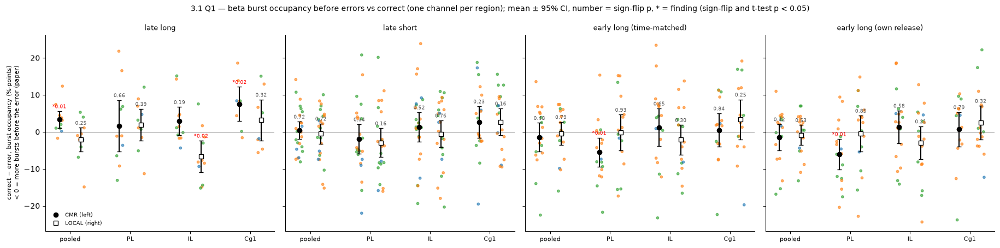

In [131]:
# ── 3.1 Q1 TESTS: fewer/more beta bursts before an ERROR than before a correct trial? (pooled mPFC + PL, IL, Cg1) ──
# needs 3.0 (TR3, TE3, nL, nE, REFS3, GROUPS3, REGS3, OUT3, RAT_COL3), 3.0a (CH: channel distances), 3.0b (OUTL: flags),
#       1.0 (lfm.sign_flip_p).
# Per usable session: value = mean occupancy correct − mean occupancy error (%-points). + = more bursts in CORRECT;
#   the paper's direction (more bursts before a miss/late) = NEGATIVE.
# Tests across sessions (session = unit):
#   sign-flip (lfm.sign_flip_p, 10000 flips) = main; paired t-test = the paper-style test (a repeated-measures ANOVA with
#   two conditions is the same test, F = t²). Finding = both p < 0.05, same direction.
# Checks: leave-one-session-out (largest p), without 3.0b-flagged sessions, without far channels (> 300 µm from the fixed
#   position; pooled is rebuilt from the remaining regions), per rat (mean, sessions > 0).
from scipy.stats import ttest_1samp
FAR_UM = 300
FAR = set(zip(CH.loc[CH.dist_from_rep_um > FAR_UM, "session"], CH.loc[CH.dist_from_rep_um > FAR_UM, "region"]))
TESTS31 = [("late long",  TR3, nL, "long",  "correct", "late"),
           ("late short", TR3, nL, "short", "correct", "late"),
           ("early long (time-matched)", TE3, nE, "long", "correct long, time-matched", "early long"),
           ("early long (own release)",  TE3, nE, "long", "correct long, own release", "early long")]

def session_values(df, nn, ref, grp, typ, a, b, drop_far=False):
    """one value per usable session: 100 × (mean occ in a − mean occ in b)"""
    ok = nn[nn.usable & (nn.ref == ref) & (nn.typ == typ)]["session"]
    d = df[(df.ref == ref) & (df.typ == typ) & df.session.isin(ok) & df.cond.isin([a, b])]
    if drop_far:
        reg = d[d.group.isin(REGS3)]
        reg = reg[~pd.Series(list(zip(reg.session, reg.group)), index=reg.index).isin(FAR)]
        d = (reg.groupby(["session", "rat", "trial", "cond"], as_index=False)["occ"].mean().assign(group="mPFC pooled")
             if grp == "mPFC pooled" else reg[reg.group == grp])
    else:
        d = d[d.group == grp]
    m = d.groupby(["session", "rat", "cond"])["occ"].mean().unstack("cond").dropna()
    if m.empty or a not in m or b not in m: return pd.DataFrame(columns=["session", "rat", "value"])
    return pd.DataFrame({"session": m.index.get_level_values(0), "rat": m.index.get_level_values(1),
                         "value": 100 * (m[a] - m[b]).values})

def stats(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    mn, p_sf, n = lfm.sign_flip_p(v)
    p_t = ttest_1samp(v, 0).pvalue if n >= 3 else np.nan
    return mn, p_sf, p_t, n, int((v > 0).sum())

rows, vals = [], []
for name, df, nn, typ, a, b in TESTS31:
    for grp in GROUPS3:
        for ref in REFS3:
            V = session_values(df, nn, ref, grp, typ, a, b)
            if len(V) < 2: continue
            vals.append(V.assign(test=name, group=grp, ref=ref))
            mn, p_sf, p_t, n, npos = stats(V["value"])
            loo = max(lfm.sign_flip_p(V["value"].drop(i).values, n_perm=2000)[1] for i in V.index) if n >= 4 else np.nan
            fl = set(OUTL[(OUTL.flag) & (OUTL.ref == ref) & (OUTL.group == grp) & (OUTL.test == name)]["session"])
            p_nofl = lfm.sign_flip_p(V.loc[~V.session.isin(fl), "value"].values)[1] if fl else p_sf
            Vf = session_values(df, nn, ref, grp, typ, a, b, drop_far=True)
            mn_f, p_far, _, n_far, _ = stats(Vf["value"]) if len(Vf) >= 2 else (np.nan, np.nan, np.nan, 0, 0)
            per_rat = {f"rat {r}": (f"{g.value.mean():+.1f} ({(g.value > 0).sum()}/{len(g)})") for r, g in V.groupby("rat")}
            rows.append(dict(test=name, group=grp, ref=ref, n=n, mean=mn, p_signflip=p_sf, p_ttest=p_t, n_pos=npos,
                             finding=(p_sf < 0.05) and (p_t < 0.05), loo_max_p=loo, n_flagged=len(fl), p_without_flagged=p_nofl,
                             n_without_far=n_far, mean_without_far=mn_f, p_without_far=p_far, **per_rat))
S31 = pd.DataFrame(rows); V31 = pd.concat(vals, ignore_index=True)
S31.to_csv(os.path.join(OUT3, "_stats_3_1.csv"), index=False); V31.to_csv(os.path.join(OUT3, "_session_values_3_1.csv"), index=False)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 40)
S31["main"] = S31.apply(lambda x: f"{x['mean']:+.2f}  sf p={x.p_signflip:.3f}  t p={x.p_ttest:.3f}  ({x.n_pos}/{x.n})"
                        + ("  ◀ FINDING" if x.finding else ""), axis=1)
S31["checks"] = S31.apply(lambda x: f"LOO {x.loo_max_p:.2f} | no-flag p={x.p_without_flagged:.3f} ({x.n_flagged} out)"
                          f" | no-far p={x.p_without_far:.3f} (n={x.n_without_far})", axis=1)
print("Q1: value = correct − error, burst occupancy %-points; + = more bursts in CORRECT; paper direction = NEGATIVE")
for name in S31.test.unique():
    d = S31[S31.test == name]
    print(f"\n===== {name} =====")
    print(d.pivot_table(index="group", columns="ref", values="main", aggfunc="first").reindex(GROUPS3).to_string())
    print(d.pivot_table(index="group", columns="ref", values="checks", aggfunc="first").reindex(GROUPS3).to_string())
    rc = [c for c in S31.columns if c.startswith("rat ")]
    print(d.set_index(["group", "ref"])[rc].reindex([(g, r) for g in GROUPS3 for r in REFS3]).dropna(how="all").to_string())

# figure: one panel per test; x = group, CMR and LOCAL side by side; dots = sessions (rat colour), bar = mean ± 95% CI
fig, axes = plt.subplots(1, len(TESTS31), figsize=(4.6 * len(TESTS31), 4.6), squeeze=False, sharey=True)
for j, (name, *_ ) in enumerate(TESTS31):
    ax = axes[0, j]
    for gi, grp in enumerate(GROUPS3):
        for ri, ref in enumerate(REFS3):
            x0 = gi + (ri - 0.5) * 0.36
            V = V31[(V31.test == name) & (V31.group == grp) & (V31.ref == ref)]
            if not len(V): continue
            jit = np.random.default_rng(gi * 10 + ri).uniform(-0.06, 0.06, len(V))
            ax.scatter(x0 + jit, V.value, c=[RAT_COL3[r] for r in V.rat], s=10, alpha=0.6, zorder=2)
            m, se = V.value.mean(), V.value.std(ddof=1) / np.sqrt(len(V))
            ax.errorbar(x0, m, yerr=1.96 * se, fmt="s" if ref == "LOCAL" else "o", color="k", mfc="w" if ref == "LOCAL" else "k",
                        ms=6, capsize=3, zorder=3)
            st = S31[(S31.test == name) & (S31.group == grp) & (S31.ref == ref)].iloc[0]
            ax.text(x0, m + 1.96 * se + 0.8, ("*" if st.finding else "") + f"{st.p_signflip:.2f}",
                    ha="center", fontsize=6.5, color="r" if st.finding else "0.3")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(range(len(GROUPS3))); ax.set_xticklabels([g.replace("mPFC pooled", "pooled") for g in GROUPS3], fontsize=8)
    ax.set_title(name, fontsize=9)
    if j == 0: ax.set_ylabel("correct − error, burst occupancy (%-points)\n< 0 = more bursts before the error (paper)", fontsize=8)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 0].plot([], [], "o", color="k", label="CMR (left)"); axes[0, 0].plot([], [], "s", color="k", mfc="w", label="LOCAL (right)")
axes[0, 0].legend(fontsize=7, frameon=False, loc="lower left")
fig.suptitle("3.1 Q1 — beta burst occupancy before errors vs correct (one channel per region); mean ± 95% CI, "
             "number = sign-flip p, * = finding (sign-flip and t-test p < 0.05)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, "3_1_Q1.png"), dpi=140, bbox_inches="tight"); plt.show()

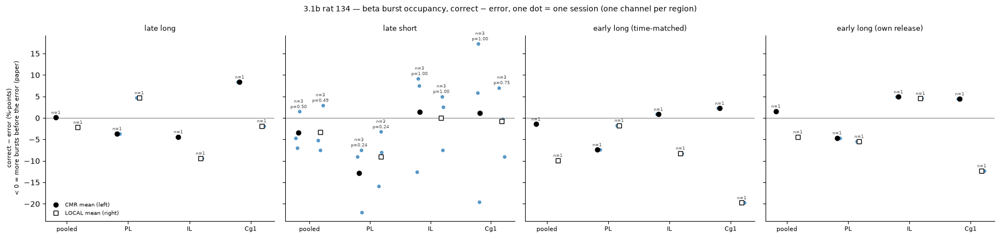

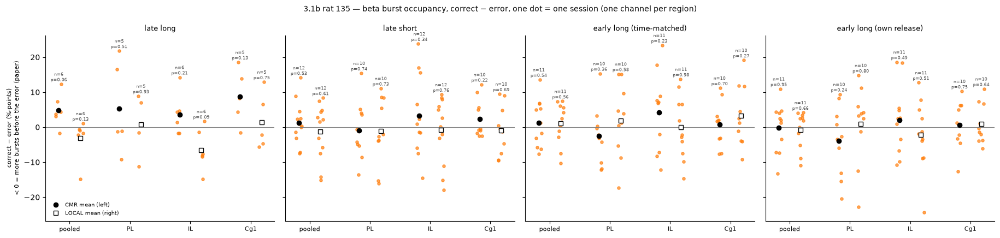

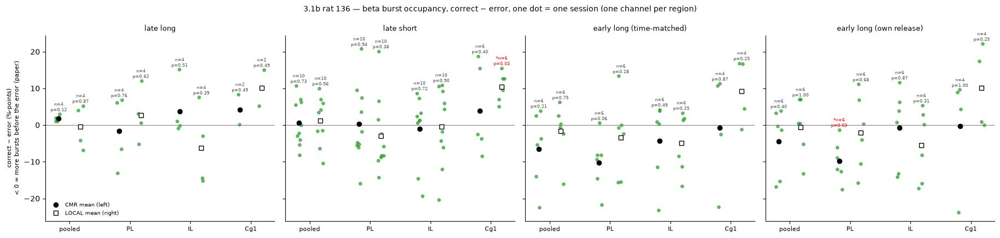

per rat: mean correct − error (%-points), (sessions > 0 / n), sign-flip p; < 0 = paper direction

===== late long =====
ref                 CMR                                             LOCAL                                       
rat                 134                135                136         134                135                 136
group                                                                                                           
mPFC pooled  +0.1 (1/1)  +4.9 (5/6) p=0.06  +1.7 (4/4) p=0.12  -2.2 (0/1)  -3.2 (1/6) p=0.13   -0.4 (2/4) p=0.87
PL           -3.6 (0/1)  +5.4 (2/5) p=0.51  -1.7 (2/4) p=0.76  +4.7 (1/1)  +0.8 (3/5) p=0.93   +2.7 (3/4) p=0.62
IL           -4.4 (0/1)  +3.5 (4/6) p=0.21  +3.8 (2/4) p=0.51  -9.4 (0/1)  -6.5 (1/6) p=0.09   -6.3 (1/4) p=0.39
Cg1          +8.4 (1/1)  +8.7 (4/5) p=0.13  +4.2 (2/2) p=0.49  -1.8 (0/1)  +1.4 (2/5) p=0.75  +10.1 (2/2) p=0.49

===== late short =====
ref                         CMR                                  

In [135]:
# ── 3.1b Q1 PER RAT: the same session values as 3.1, one figure per rat (descriptive + per-rat sign-flip) ──
# needs 3.1 (V31, TESTS31), 3.0 (GROUPS3, REFS3, RAT_COL3, OUT3), 1.0 (lfm.sign_flip_p). Nothing recomputed.
# With n sessions the smallest possible sign-flip p is 2 / 2^n (n = 3 -> 0.25, n = 5 -> 0.0625, n = 6 -> 0.03),
# so a rat with few sessions cannot reach p < 0.05: read the dots and their direction, not only the p.
rows = []
for rat in sorted(V31.rat.unique()):
    fig, axes = plt.subplots(1, len(TESTS31), figsize=(4.6 * len(TESTS31), 4.4), squeeze=False, sharey=True)
    for j, (name, *_ ) in enumerate(TESTS31):
        ax = axes[0, j]
        for gi, grp in enumerate(GROUPS3):
            for ri, ref in enumerate(REFS3):
                x0 = gi + (ri - 0.5) * 0.36
                V = V31[(V31.test == name) & (V31.group == grp) & (V31.ref == ref) & (V31.rat == rat)]
                if not len(V): continue
                jit = np.random.default_rng(gi * 10 + ri).uniform(-0.05, 0.05, len(V))
                ax.scatter(x0 + jit, V.value, color=RAT_COL3[rat], s=14, alpha=0.7, zorder=2)
                mn, p, n = lfm.sign_flip_p(V.value.values)
                p_t = ttest_1samp(V.value.values, 0).pvalue if n >= 3 else np.nan
                sig = (n >= 3) and (p < 0.05) and (p_t < 0.05)
                ax.plot(x0, mn, "s" if ref == "LOCAL" else "o", color="k", mfc="w" if ref == "LOCAL" else "k", ms=6, zorder=3)
                ax.text(x0, np.nanmax(V.value) + 0.8, ("*" if sig else "") + f"n={n}" + (f"\np={p:.2f}" if n >= 2 else ""),
                        ha="center", fontsize=6, color="r" if sig else "0.3")
                rows.append(dict(rat=rat, test=name, group=grp, ref=ref, n=n, mean=mn, p=p, n_pos=int((V.value > 0).sum())))
        ax.axhline(0, color="0.5", lw=0.8)
        ax.set_xticks(range(len(GROUPS3))); ax.set_xticklabels([g.replace("mPFC pooled", "pooled") for g in GROUPS3], fontsize=8)
        ax.set_title(name, fontsize=9)
        if j == 0: ax.set_ylabel("correct − error (%-points)\n< 0 = more bursts before the error (paper)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axes[0, 0].plot([], [], "o", color="k", label="CMR mean (left)"); axes[0, 0].plot([], [], "s", color="k", mfc="w", label="LOCAL mean (right)")
    axes[0, 0].legend(fontsize=7, frameon=False, loc="lower left")
    fig.suptitle(f"3.1b rat {rat} — beta burst occupancy, correct − error, one dot = one session (one channel per region)", fontsize=10)
    fig.tight_layout(); fig.savefig(os.path.join(OUT3, f"3_1b_Q1_rat_{rat}.png"), dpi=140, bbox_inches="tight"); plt.show()

R31 = pd.DataFrame(rows); R31.to_csv(os.path.join(OUT3, "_stats_3_1b_per_rat.csv"), index=False)
R31["cell"] = R31.apply(lambda x: f"{x['mean']:+.1f} ({x.n_pos}/{x.n})" + (f" p={x.p:.2f}" if x.n >= 2 else ""), axis=1)
pd.set_option("display.width", 300)
print("per rat: mean correct − error (%-points), (sessions > 0 / n), sign-flip p; < 0 = paper direction")
for name in R31.test.unique():
    print(f"\n===== {name} =====")
    print(R31[R31.test == name].pivot_table(index="group", columns=["ref", "rat"], values="cell", aggfunc="first")
          .reindex(GROUPS3).to_string())

In [6]:
print([n for n in ["TR3","nL","D3","K_DIR","MIN_TR3","MIN_RT3","win3","rat_of","lfm"] if n not in globals()])

['D3']


In [139]:
# ── 3.1c Q1 with RAT taken into account (sessions are nested in rats) ──
# needs 3.1 (V31, S31), 3.0 (GROUPS3, REFS3, OUT3). Nothing recomputed; uses the 3.1 session values.
# (a) mixed model  value ~ 1 + (1 | rat)  (statsmodels MixedLM, REML): the intercept = effect across sessions while each
#     rat has its own offset (Aarts et al. 2014 Nat Neurosci). With 3 rats the rat variance is only roughly estimated.
# (b) hierarchical bootstrap (Saravanan et al. 2020 NBDT): resample rats with replacement, then sessions within each
#     resampled rat, mean of all -> 10000 means; p = 2 × smaller tail share around 0.
import warnings
import statsmodels.formula.api as smf

def mixed_p(d):
    if d.rat.nunique() < 2: return np.nan, np.nan, np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            r = smf.mixedlm("value ~ 1", d, groups=d["rat"]).fit(reml=True)
            return float(r.params["Intercept"]), float(r.pvalues["Intercept"]), float(r.cov_re.iloc[0, 0])
        except Exception:
            return np.nan, np.nan, np.nan

def hier_boot_p(d, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    by_rat = [g.values for _, g in d.groupby("rat")["value"]]
    if len(by_rat) < 2: return np.nan
    means = np.empty(n_boot)
    for i in range(n_boot):
        pick = rng.integers(0, len(by_rat), len(by_rat))
        means[i] = np.mean(np.concatenate([rng.choice(by_rat[k], len(by_rat[k])) for k in pick]))
    return min(1.0, 2 * min((means <= 0).mean(), (means >= 0).mean()))

rows = []
for (name, grp, ref), d in V31.groupby(["test", "group", "ref"], sort=False):
    d = d.dropna(subset=["value"])
    est, p_mm, var_rat = mixed_p(d)
    rows.append(dict(test=name, group=grp, ref=ref, n=len(d), rats=d.rat.nunique(), mixed_est=est, p_mixed=p_mm,
                     rat_var=var_rat, p_hboot=hier_boot_p(d)))
M31 = pd.DataFrame(rows).merge(S31[["test", "group", "ref", "mean", "p_signflip", "p_ttest", "finding"]], on=["test", "group", "ref"])
M31.to_csv(os.path.join(OUT3, "_stats_3_1c_rat_nested.csv"), index=False)

M31["cell"] = M31.apply(lambda x: f"{x['mean']:+.2f} sf={x.p_signflip:.3f} | mixed {x.mixed_est:+.2f} p={x.p_mixed:.3f}"
                        f" | hboot p={x.p_hboot:.3f}" + ("  ◀ 3.1 finding" if x.finding else ""), axis=1)
pd.set_option("display.width", 300)
print("Q1 with rat as a level: 3.1 mean + sign-flip p | mixed model (rat random intercept) | hierarchical bootstrap p")
for name in M31.test.unique():
    print(f"\n===== {name} =====")
    print(M31[M31.test == name].pivot_table(index="group", columns="ref", values="cell", aggfunc="first").reindex(GROUPS3).to_string())
print("\nthe 3.1 findings only:")
print(M31[M31.finding][["test", "group", "ref", "n", "rats", "mean", "p_signflip", "mixed_est", "p_mixed", "rat_var", "p_hboot"]]
      .round(4).to_string(index=False))

Q1 with rat as a level: 3.1 mean + sign-flip p | mixed model (rat random intercept) | hierarchical bootstrap p

===== late long =====
ref                                                                          CMR                                                                LOCAL
group                                                                                                                                                
mPFC pooled  +3.31 sf=0.007 | mixed +3.07 p=0.044 | hboot p=0.000  ◀ 3.1 finding                 -2.10 sf=0.249 | mixed -2.09 p=0.299 | hboot p=0.238
PL                          +1.65 sf=0.656 | mixed +1.65 p=0.661 | hboot p=0.815                 +1.95 sf=0.387 | mixed +1.95 p=0.355 | hboot p=0.314
IL                          +2.91 sf=0.193 | mixed +2.89 p=0.102 | hboot p=0.233  -6.68 sf=0.016 | mixed -6.68 p=0.002 | hboot p=0.007  ◀ 3.1 finding
Cg1            +7.52 sf=0.023 | mixed +7.52 p=nan | hboot p=0.000  ◀ 3.1 finding                 +3.18 sf=0.320 | mi

Q2: PCM = success rate per bin, % change from the session mean (n sessions); paper: PCM falls from quiet to high
    rho = Spearman(occupancy, success) per session; < 0 = paper direction; finding = ANOVA p < 0.05 and sign-flip p < 0.05

===== long trials =====
  ref       group PCM quiet    PCM low PCM medium  PCM high          ANOVA                                                       Tukey                           rho_cell      flag
  CMR mPFC pooled -43.5 (1)  -4.7 (11)  +2.0 (11)  +8.4 (3) F=0.45 p=0.645                                                             +0.084 p=0.061 (2/11 neg) LOO 0.13          
  CMR          PL +11.3 (3)  -0.9 (10)  -3.6 (10)  +6.9 (6) F=0.81 p=0.499                                                             -0.010 p=0.896 (6/10 neg) LOO 0.99          
  CMR          IL  +1.5 (8)  +0.1 (10)  +5.6 (11)  -4.2 (7) F=0.23 p=0.878                                                             +0.056 p=0.395 (6/11 neg) LOO 0.77          
  CMR         Cg1 -

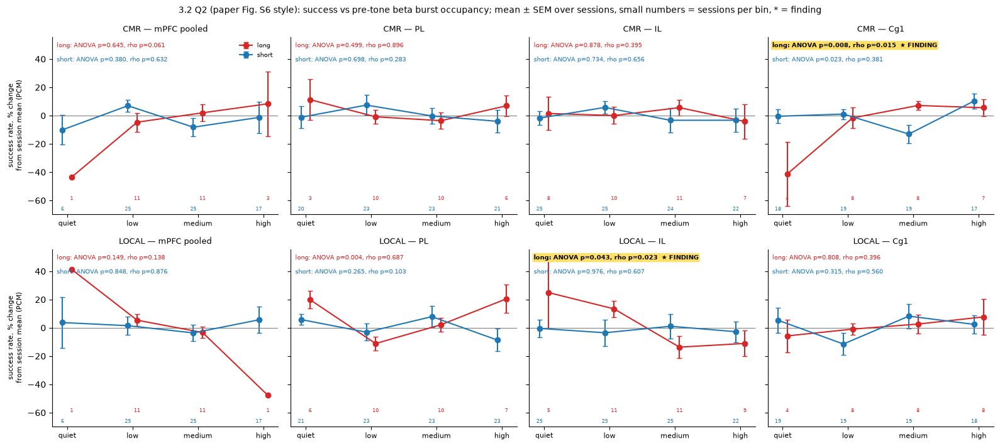

In [141]:
# ── 3.2 Q2 (paper Fig. S6): is the SUCCESS RATE lower when there are more pre-tone beta bursts? (pooled + PL, IL, Cg1) ──
# needs 3.0 (TR3, nL, REFS3, GROUPS3, OUT3, RAT_COL3), 1.0 (lfm.sign_flip_p).
# Trials: correct + late of the usable sessions (3.0), pre-tone window (long −0.6..0 s, short −0.3..0 s); success = correct.
# (a) PAPER: occupancy bins quiet = 0, low <= 25 %, medium <= 50 %, high > 50 % of the window (paper: 0 / 1–150 / 151–300 /
#     > 300 samples of 600 ms). Per session and bin (>= 3 trials): success rate as PCM = % change from the session's mean
#     success rate. One-way ANOVA across bins (sessions = observations) + Tukey HSD.
# (b) OURS (direction + session = unit): per session Spearman rho between trial occupancy and success (0/1);
#     sign-flip across sessions + leave-one-session-out. rho < 0 = more bursts -> less success (paper direction).
# Finding = ANOVA p < 0.05 AND sign-flip p < 0.05.
from scipy.stats import f_oneway, tukey_hsd, spearmanr
OBINS = ["quiet", "low", "medium", "high"]
MIN_BIN = 3
def obin(o):
    return np.select([o <= 0, o <= 0.25, o <= 0.5], [0, 1, 2], default=3)

T32 = TR3.merge(nL[nL.usable][["ref", "typ", "session"]], on=["ref", "typ", "session"])      # usable sessions only
T32 = T32.assign(obin=obin(T32["occ"].values), success=T32["cond"].eq("correct").astype(float))

prows, rrows, arows = [], [], []
for (ref, grp, typ), g in T32.groupby(["ref", "group", "typ"], sort=False):
    sm = g.groupby("session")["success"].mean()
    ps = g.groupby(["session", "rat", "obin"])["success"].agg(["mean", "size"]).reset_index()
    ps = ps[ps["size"] >= MIN_BIN]
    ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
    prows.append(ps.assign(ref=ref, group=grp, typ=typ))
    grp_pcm = [ps.loc[ps.obin == b, "pcm"].dropna().values for b in range(4)]
    ok = [b for b in range(4) if len(grp_pcm[b]) >= 3]
    F, pA, tk = np.nan, np.nan, ""
    if len(ok) >= 2:
        F, pA = f_oneway(*[grp_pcm[b] for b in ok])
        if pA < 0.05:
            res = tukey_hsd(*[grp_pcm[b] for b in ok])
            tk = "; ".join(f"{OBINS[ok[i]]}-{OBINS[ok[j]]} p={res.pvalue[i, j]:.3f}"
                           for i in range(len(ok)) for j in range(i + 1, len(ok)) if res.pvalue[i, j] < 0.05)
    rho = []
    for (s, rat), gs in g.groupby(["session", "rat"]):
        if gs["occ"].nunique() > 2:
            rho.append(dict(session=s, rat=rat, rho=spearmanr(gs["occ"], gs["success"]).correlation))
    R = pd.DataFrame(rho).dropna(); rrows.append(R.assign(ref=ref, group=grp, typ=typ))
    mn, p, n = lfm.sign_flip_p(R["rho"].values)
    loo = max(lfm.sign_flip_p(R["rho"].drop(i).values, n_perm=2000)[1] for i in R.index) if n >= 4 else np.nan
    arows.append(dict(ref=ref, group=grp, typ=typ,
                      **{f"PCM {OBINS[b]}": (f"{np.mean(grp_pcm[b]):+.1f} ({len(grp_pcm[b])})" if len(grp_pcm[b]) else "—") for b in range(4)},
                      ANOVA=f"F={F:.2f} p={pA:.3f}" if np.isfinite(F) else "—", Tukey=tk, p_anova=pA,
                      rho_mean=mn, p_rho=p, rho_cell=f"{mn:+.3f} p={p:.3f} ({int((R.rho < 0).sum())}/{n} neg) LOO {loo:.2f}",
                      finding=bool(np.isfinite(pA) and pA < 0.05 and p < 0.05),
                      **{f"rat {r}": f"{x.rho.mean():+.3f} ({(x.rho < 0).sum()}/{len(x)} neg)" for r, x in R.groupby("rat")}))
P32 = pd.concat(prows, ignore_index=True); R32 = pd.concat(rrows, ignore_index=True); A32 = pd.DataFrame(arows)
P32.to_csv(os.path.join(OUT3, "_pcm_bins_3_2.csv"), index=False); R32.to_csv(os.path.join(OUT3, "_rho_sessions_3_2.csv"), index=False)
A32.to_csv(os.path.join(OUT3, "_stats_3_2.csv"), index=False)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 40)
print("Q2: PCM = success rate per bin, % change from the session mean (n sessions); paper: PCM falls from quiet to high")
print("    rho = Spearman(occupancy, success) per session; < 0 = paper direction; finding = ANOVA p < 0.05 and sign-flip p < 0.05")
for typ in ("long", "short"):
    d = A32[A32.typ == typ].copy(); d["group"] = pd.Categorical(d["group"], GROUPS3); d = d.sort_values(["ref", "group"])
    d["flag"] = np.where(d.finding, "◀ FINDING", "")
    print(f"\n===== {typ} trials =====")
    print(d[["ref", "group"] + [f"PCM {b}" for b in OBINS] + ["ANOVA", "Tukey", "rho_cell", "flag"]].to_string(index=False))
    rc = [c for c in d.columns if c.startswith("rat ")]
    print(d[["ref", "group"] + rc].to_string(index=False))

# figure: paper Fig. S6 style — PCM per bin, mean ± SEM over sessions; rows = reference, columns = group; long and short
fig, axes = plt.subplots(len(REFS3), len(GROUPS3), figsize=(4 * len(GROUPS3), 3.6 * len(REFS3)), squeeze=False, sharey=True)
for i, ref in enumerate(REFS3):
    for j, grp in enumerate(GROUPS3):
        ax = axes[i, j]
        for typ, col, dx in (("long", "#d62728", 0.07), ("short", "#1f77b4", -0.07)):
            ps = P32[(P32.ref == ref) & (P32.group == grp) & (P32.typ == typ)]
            st = ps.groupby("obin")["pcm"].agg(["mean", "sem", "size"]).reindex(range(4))
            ax.errorbar(np.arange(4) + dx, st["mean"], yerr=st["sem"], marker="o", color=col, capsize=3, label=typ)
            a = A32[(A32.ref == ref) & (A32.group == grp) & (A32.typ == typ)].iloc[0]
            ax.text(0.02, 0.97 if typ == "long" else 0.89,
                    f"{typ}: ANOVA p={a.p_anova:.3f}, rho p={a.p_rho:.3f}" + ("  ★ FINDING" if a.finding else ""),
                    transform=ax.transAxes, fontsize=7, va="top",
                    color="k" if a.finding else col, fontweight="bold" if a.finding else "normal",
                    bbox=dict(boxstyle="round,pad=0.2", fc="#ffe066", ec="none") if a.finding else None)
            if a.finding:
                ax.set_title(f"{ref} — {grp}   ★ {typ}", fontsize=9, fontweight="bold")
            for b in range(4):
                if np.isfinite(st["size"].iat[b]):
                    ax.text(b + dx, 0.08 if typ == "long" else 0.02, f"{int(st['size'].iat[b])}", fontsize=6, color=col,
                            ha="center", transform=ax.get_xaxis_transform())
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels(OBINS, fontsize=8)
        ax.set_title(f"{ref} — {grp}", fontsize=9)
        if j == 0: ax.set_ylabel("success rate, % change\nfrom session mean (PCM)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper right")
fig.suptitle("3.2 Q2 (paper Fig. S6 style): success vs pre-tone beta burst occupancy; mean ± SEM over sessions, "
             "small numbers = sessions per bin, * = finding", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, "3_2_Q2_success_by_bin.png"), dpi=140, bbox_inches="tight"); plt.show()

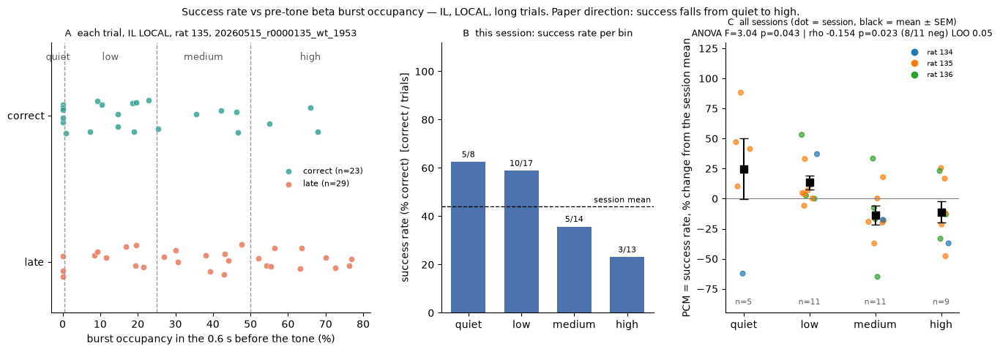

         sum  size  rate
b                       
quiet    5.0     8  62.0
low     10.0    17  59.0
medium   5.0    14  36.0
high     3.0    13  23.0


In [34]:
# ── SUCCESS RATE vs BURST OCCUPANCY: one session (A, B) and all sessions (C) ──
# needs 3.0 (TR3, OUT3) and the saved file of 3.2 (_pcm_bins_3_2.csv, _stats_3_2.csv in bursts_main) -> 3.2 does not need to be rerun.
# Bins as in 3.2 / paper: quiet = 0, low <= 25 %, medium <= 50 %, high > 50 % of the 0.6 s window.
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
SES_S, REF_S, REG_S, TYP_S = "20260515_r0000135_wt_1953", "LOCAL", "IL", "long"      # change here
OB = ["quiet", "low", "medium", "high"]
def obin(o): return np.select([o <= 0, o <= 0.25, o <= 0.5], [0, 1, 2], default=3)
RAT_COL3 = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
d = TR3[(TR3.session == SES_S) & (TR3.ref == REF_S) & (TR3.group == REG_S) & (TR3.typ == TYP_S)].copy()
d["succ"] = (d.cond == "correct").astype(float); d["b"] = obin(d.occ.values)
P = pd.read_csv(os.path.join(OUT3, "_pcm_bins_3_2.csv"), dtype={"rat": str})
P = P[(P.ref == REF_S) & (P.group == REG_S) & (P.typ == TYP_S)]
A = pd.read_csv(os.path.join(OUT3, "_stats_3_2.csv")); A = A[(A.ref == REF_S) & (A.group == REG_S) & (A.typ == TYP_S)].iloc[0]
C_OK, C_LATE, C_BIN = "#2a9d8f", "#e76f51", "#4c72b0"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1, 1.1], wspace=0.28))
# A: every trial of this session
rng = np.random.default_rng(0)
for v, c, lab in ((1, C_OK, "correct"), (0, C_LATE, "late")):
    s = d[d.succ == v]; ax[0].scatter(100 * s.occ, v + rng.uniform(-.12, .12, len(s)), c=c, s=36, alpha=.8, label=f"{lab} (n={len(s)})", ec="w", lw=.5)
for e in (0, 25, 50): ax[0].axvline(e + (0.5 if e == 0 else 0), color="0.6", ls="--", lw=1)
xm = max(60, 100 * d.occ.max() + 5)
for x0, x1, nm in ((-3, .5, "quiet"), (.5, 25, "low"), (25, 50, "medium"), (50, xm, "high")):
    ax[0].text((x0 + x1) / 2, 1.38, nm, ha="center", fontsize=9, color="0.35")
ax[0].set_xlim(-3, xm); ax[0].set_ylim(-.35, 1.5); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["late", "correct"])
ax[0].set_xlabel("burst occupancy in the 0.6 s before the tone (%)"); ax[0].legend(frameon=False, fontsize=8, loc="center right")
ax[0].set_title(f"A  each trial, {REG_S} {REF_S}, rat {d.rat.iat[0]}, {SES_S}", fontsize=9)
# B: success rate per bin in this session
g = d.groupby("b")["succ"].agg(["sum", "size"]).reindex(range(4)).fillna(0)
rate = 100 * g["sum"] / g["size"].replace(0, np.nan)
ax[1].bar(range(4), rate, color=[C_BIN if n >= 3 else "0.85" for n in g["size"]], width=.65)
for i in range(4):
    ax[1].text(i, (0 if np.isnan(rate[i]) else rate[i]) + 2, f"{int(g['sum'][i])}/{int(g['size'][i])}" + ("" if g["size"][i] >= 3 else "\n(<3, not used)"), ha="center", fontsize=8)
ax[1].axhline(100 * d.succ.mean(), color="k", ls="--", lw=1); ax[1].text(3.45, 100 * d.succ.mean() + 1.5, "session mean", ha="right", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(OB); ax[1].set_ylim(0, 112); ax[1].set_ylabel("success rate (% correct)  [correct / trials]")
ax[1].set_title("B  this session: success rate per bin", fontsize=9)
# C: all sessions, PCM
for b in range(4):
    p = P[P.obin == b]
    ax[2].scatter(b + rng.uniform(-.13, .13, len(p)), p.pcm, c=[RAT_COL3.get(r, "k") for r in p.rat], s=24, alpha=.7, zorder=2)
    if len(p): ax[2].errorbar(b, p.pcm.mean(), yerr=p.pcm.std(ddof=1) / np.sqrt(len(p)) if len(p) > 1 else 0, fmt="s", color="k", ms=7, capsize=4, zorder=3)
    ax[2].text(b, ax[2].get_ylim()[0] if False else -88, f"n={len(p)}", ha="center", fontsize=8, color="0.4")
ax[2].axhline(0, color="0.5", lw=.8); ax[2].set_xticks(range(4)); ax[2].set_xticklabels(OB); ax[2].set_ylim(-95, 130)
ax[2].set_ylabel("PCM = success rate, % change from the session mean")
ax[2].set_title(f"C  all sessions (dot = session, black = mean ± SEM)\nANOVA {A.ANOVA} | rho {A.rho_cell}", fontsize=8.5)
for r, c in RAT_COL3.items(): ax[2].plot([], [], "o", color=c, label=f"rat {r}")
ax[2].legend(frameon=False, fontsize=7, loc="upper right")
for a in ax:
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
fig.suptitle(f"Success rate vs pre-tone beta burst occupancy — {REG_S}, {REF_S}, {TYP_S} trials. Paper direction: success falls from quiet to high.", fontsize=10)
plt.show()
print(g.assign(rate=rate.round(0)).rename(index=dict(enumerate(OB))).to_string())

In [19]:
# ── TF map: white marks = ONLY the bursts detected by the cell-2.6 rule (dot = peak, line = extent at the peak frequency) ──
# needs 1.0 (lfm.morlet, rat_of) and skimage (as 2.6).
import numpy as np, matplotlib.pyplot as plt, scipy.signal as ss
from skimage.morphology import local_maxima

def tf_prepare(lfp, fs, beta=(15, 30), disp=(5, 40), morlet=None):
    """whole-session part (slow, done ONCE per session): wavelet power, 90th percentiles, the 2.6 burst rule"""
    morlet = morlet or lfm.morlet
    foi = np.arange(min(disp[0], beta[0] - 1), max(disp[1], beta[1] + 1) + 1)
    P = np.empty((len(foi), len(lfp)), np.float32)
    for i, f in enumerate(foi): P[i] = np.abs(ss.fftconvolve(lfp, morlet(f, 7, fs), mode="same")) ** 2
    thr = np.percentile(P, 90, axis=1, keepdims=True)                   # 90th percentile per frequency (whole session)
    rows = np.where((foi >= beta[0] - 1) & (foi <= beta[1] + 1))[0]     # band ±1 Hz, as 2.6
    M = P[rows] / thr[rows]; M[~(M >= 1)] = 0
    pk = local_maxima(M, connectivity=2, allow_borders=True) & (M > 0); pk[[0, -1], :] = False
    on_code = np.zeros(len(lfp), bool); segs = []                       # segs: (frequency, start sample, end sample, peak samples)
    for i in range(1, len(rows) - 1):
        js = np.flatnonzero(pk[i])
        if not len(js): continue
        row = M[i] > 0; run = np.cumsum(np.diff(np.concatenate([[0], row.astype(np.int8)])) == 1)
        on_code |= np.isin(run, np.unique(run[js])) & row
        for rid in np.unique(run[js]):
            idx = np.flatnonzero((run == rid) & row)
            segs.append((foi[rows[i]], idx[0], idx[-1], js[run[js] == rid]))
    return dict(foi=foi, P=P, thr=thr, on=on_code, segs=segs, fs=fs, beta=beta)

def show_map(lfp=None, fs=None, t0=0.0, win=(0, 4), beta=(15, 30), disp=(5, 40), morlet=None, span=None, mark=None, title=None,
             figsize=(11, 7), quiet=False, S=None):
    """S = result of tf_prepare (reuse it for many windows of the same session); otherwise computed from lfp"""
    S = S or tf_prepare(lfp, fs, beta, disp, morlet)
    foi, P, thr, on_code, segs, fs, beta = S["foi"], S["P"], S["thr"], S["on"], S["segs"], S["fs"], S["beta"]
    t = t0 + np.arange(P.shape[1]) / fs
    m = (t >= t0 + win[0]) & (t < t0 + win[1])
    fig, ax = plt.subplots(2, 1, figsize=figsize, sharex=True, gridspec_kw=dict(height_ratios=[4, .6]))
    Rel = 10 * np.log10(P[:, m] / thr)
    im = ax[0].pcolormesh(t[m], foi, Rel, shading="auto", cmap="magma", vmin=-10, vmax=6)
    for f in beta: ax[0].axhline(f, color="c", ls="--", lw=.8)
    for fr, a0, a1, pks in segs:                                        # the detected bursts, nothing else
        if t[a1] < t[m][0] or t[a0] > t[m][-1]: continue
        ax[0].hlines(fr, t[a0], t[a1], colors="w", lw=2)
        pp = pks[(t[pks] >= t[m][0]) & (t[pks] <= t[m][-1])]
        ax[0].plot(t[pp], np.full(len(pp), fr), "o", color="w", mec="k", ms=4)
    ax[0].set_ylabel(f"frequency (Hz)\ndashed = beta {beta[0]}-{beta[1]}")
    plt.colorbar(im, ax=ax, label="dB relative to the 90th percentile of each frequency", pad=.01)
    ax[1].fill_between(t[m], 0, on_code[m], step="mid", color="k"); ax[1].set_yticks([])
    ax[1].set_ylabel("burst on\n(cell 2.6 rule)", rotation=0, ha="right", va="center", fontsize=8); ax[1].set_xlabel("time (s)")
    for a_ in ax:
        if span:
            for xv in span: a_.axvline(xv, color="lime", lw=1.2, ls="--")          # window of the test
        if mark is not None: a_.axvline(mark, color="r", lw=1)
    if title: ax[0].set_title(title, fontsize=9)
    occ = float(on_code[(t >= t0 + span[0]) & (t < t0 + span[1])].mean()) if span else float(on_code[m].mean())
    if not quiet: print(f"burst-on share of {'the lime-dashed window' if span else 'this window'}: {occ:.0%}")
    plt.show(); return occ

# ── BLIND viewer: random late/correct trials of one representative channel, labels A, B, C ... without the condition ──
# needs 3.0 (TR3, K_DIR, PRE3), 2.6 functions (load_ref, read_full), 1.0 (rat_of)
def blind_run(REF="LOCAL", REG="IL", typ="long", n_each=4, seed=None, session=None):
    rng = np.random.default_rng(seed)
    d = TR3[(TR3.ref == REF) & (TR3.group == REG) & (TR3.typ == typ)]
    cnt = d.groupby(["session", "cond"]).size().unstack(fill_value=0)
    good = cnt[(cnt.get("late", 0) >= n_each) & (cnt.get("correct", 0) >= n_each)].index
    s = session if session else (rng.choice(list(good)) if len(good) else cnt.get("late", cnt.iloc[:, 0]).idxmax())
    Z = np.load(os.path.join(K_DIR, s + ".npz")); cid = str(Z[f"{REF}|{REG}|channel"][0])
    T = pd.read_csv(os.path.join(K_DIR, s + "_trials.csv"))
    pick = [(c, int(i)) for c in ("late", "correct")
            for i in rng.choice(d[(d.session == s) & (d.cond == c)].trial.values, min(n_each, int(cnt.loc[s, c])), replace=False)]
    order = rng.permutation(len(pick)); pick = [pick[k] for k in order]
    rec = load_ref(s, REF); fs = rec.get_sampling_frequency()
    X = read_full(rec, [c for c in rec.get_channel_ids() if str(c) == cid])
    try: loc = rec.get_channel_locations()[[str(c) for c in rec.get_channel_ids()].index(cid)]; xy = f"x={loc[0]:.0f}, y={loc[1]:.0f} µm"
    except Exception: xy = "position not available"
    print(f"rat {rat_of(s)} | session {s} | region {REG} | reference {REF} | channel {cid} ({xy}) | "
          f"{len(pick)} {typ} trials ({n_each} late + {n_each} correct, shuffled, condition hidden)")
    S = tf_prepare(X[:, 0], fs)                                          # slow part: once per session
    a, z = PRE3[typ]; KEY = []
    for k, (c, ix) in enumerate(pick):
        lab = "ABCDEFGHIJKLMNOP"[k]; tn = float(T["tone_s"].iat[ix])
        occ = show_map(S=S, t0=0, win=(tn - 2.0, tn + 1.0), span=(tn + a, tn + z), mark=tn, quiet=True, figsize=(10, 4.5),
                       title=f"trial {lab} — {REG}, {REF} — red = tone, lime dashes = window before the tone")
        KEY.append(dict(trial=lab, cond=c, idx=ix, burst_share=occ))
    print("Condition hidden. Write your guess, then run reveal(KEY, GUESS).")
    return KEY, s

def reveal(KEY, GUESS=None):
    R = pd.DataFrame(KEY)
    if GUESS: R["your_guess"] = R.trial.map(GUESS); print("correct guesses:", int((R.your_guess == R.cond).sum()), "of", len(R))
    R["burst_share"] = (100 * R["burst_share"]).round(0).astype(int).astype(str) + "%"
    print(R.to_string(index=False))

In [22]:
rat_of = lambda s: s.split("_")[1][-3:]

In [26]:
d = TR3[(TR3.session == "20260515_r0000135_wt_1953") & (TR3.ref == "LOCAL") & (TR3.group == "IL") & (TR3.typ == "long")]
print(d.groupby("cond")["occ"].agg(trials="size", mean_pct=lambda x: 100 * x.mean(), median_pct=lambda x: 100 * x.median()).round(1))

         trials   mean_pct  median_pct
cond                                  
correct      23  22.700001   18.500000
late         29  37.599998   39.200001


rat 135 | session 20260515_r0000135_wt_1953 | region IL | reference LOCAL | channel imec0.ap#AP238


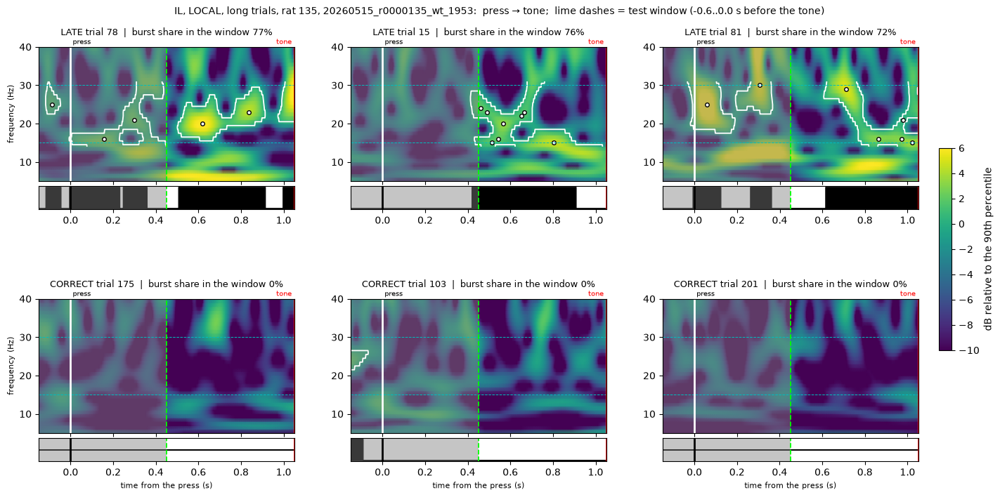

  LATE     trial 78: plot 77%  |  3.0 table 77%
  LATE     trial 15: plot 76%  |  3.0 table 76%
  LATE     trial 81: plot 72%  |  3.0 table 72%
  CORRECT  trial 175: plot 0%  |  3.0 table 0%
  CORRECT  trial 103: plot 0%  |  3.0 table 0%
  CORRECT  trial 201: plot 0%  |  3.0 table 0%


In [31]:
# ── ONE-FIGURE VIEWER: press → tone for several trials, burst blobs outlined, test window marked ──
# needs 1.0 (lfm.morlet, rat_of), skimage + scipy, TR3/K_DIR/PRE3 (3.0), the loader cell (load_ref, read_full).
# This cell REPLACES tf_prepare of the earlier viewer cell (same name, adds the fields M, pk, rows) and adds show_grid / show_trials_grid.
import numpy as np, matplotlib.pyplot as plt, scipy.signal as ss, scipy.ndimage as ndi
from skimage.morphology import local_maxima

def tf_prepare(lfp, fs, beta=(15, 30), disp=(5, 40), morlet=None):
    """whole-session part (slow, ONCE per session): wavelet power, 90th percentiles, the cell-2.6 burst rule"""
    morlet = morlet or lfm.morlet
    foi = np.arange(min(disp[0], beta[0] - 1), max(disp[1], beta[1] + 1) + 1)
    P = np.empty((len(foi), len(lfp)), np.float32)
    for i, f in enumerate(foi): P[i] = np.abs(ss.fftconvolve(lfp, morlet(f, 7, fs), mode="same")) ** 2
    thr = np.percentile(P, 90, axis=1, keepdims=True)                   # 90th percentile per frequency (whole session)
    rows = np.where((foi >= beta[0] - 1) & (foi <= beta[1] + 1))[0]     # band ±1 Hz, as 2.6
    M = P[rows] / thr[rows]; M[~(M >= 1)] = 0
    pk = local_maxima(M, connectivity=2, allow_borders=True) & (M > 0); pk[[0, -1], :] = False
    on_code = np.zeros(len(lfp), bool); segs = []
    for i in range(1, len(rows) - 1):
        js = np.flatnonzero(pk[i])
        if not len(js): continue
        row = M[i] > 0; run = np.cumsum(np.diff(np.concatenate([[0], row.astype(np.int8)])) == 1)
        on_code |= np.isin(run, np.unique(run[js])) & row
        for rid in np.unique(run[js]):
            idx = np.flatnonzero((run == rid) & row)
            segs.append((foi[rows[i]], idx[0], idx[-1], js[run[js] == rid]))
    return dict(foi=foi, P=P, thr=thr, on=on_code, segs=segs, fs=fs, beta=beta, M=M, pk=pk, rows=rows)

def show_grid(S, T, items, a, z, ncol=3, lead=0.15, step=2, title=""):
    """items = [(label, trial index), ...]; each panel = from `lead` s before the press to the tone; x axis = s from the press.
    White line = press, red line = tone, lime dashes = test window (a..z s from the tone), outside the window is dimmed.
    White outline = region above the 90th percentile that is connected to a detected burst peak (dot); black row = burst-on."""
    foi, P, thr, M, pk, rows, on, fs, beta = S["foi"], S["P"], S["thr"], S["M"], S["pk"], S["rows"], S["on"], S["fs"], S["beta"]
    nrow = int(np.ceil(len(items) / ncol)); fig = plt.figure(figsize=(4.7 * ncol + 0.8, 3.6 * nrow))
    outer = fig.add_gridspec(nrow, ncol, wspace=0.22, hspace=0.55, left=0.06, right=0.9, top=0.9, bottom=0.08); out = []
    for k, (lab, ix) in enumerate(items):
        r, c = divmod(k, ncol); gs = outer[r, c].subgridspec(2, 1, height_ratios=[4, .7], hspace=.06)
        ax0 = fig.add_subplot(gs[0]); ax1 = fig.add_subplot(gs[1], sharex=ax0)
        press, tone = float(T["press_s"].iat[ix]), float(T["tone_s"].iat[ix])
        i0, i1 = int(round((press - lead) * fs)), int(round(tone * fs)); xr = (np.arange(i0, i1) / fs - press)
        im = ax0.pcolormesh(xr[::step], foi, 10 * np.log10(P[:, i0:i1:step] / thr), shading="gouraud", cmap="viridis", vmin=-10, vmax=6)
        j0, j1 = max(int(round((press - 0.5) * fs)), 0), min(int(round((tone + 0.5) * fs)), M.shape[1])     # margin so cut blobs keep their peak
        lab_, _ = ndi.label(M[:, j0:j1] > 0, structure=np.ones((3, 3)))                                    # 8-connected regions above threshold
        keep = np.unique(lab_[pk[:, j0:j1]]); keep = keep[keep > 0]
        blob = np.isin(lab_, keep)[:, i0 - j0:i1 - j0]
        if blob.any(): ax0.contour(xr[::step], foi[rows], blob[:, ::step].astype(float), levels=[0.5], colors="w", linewidths=1.3)
        ri, ci = np.nonzero(pk[:, i0:i1]); ax0.plot(xr[ci], foi[rows][ri], "o", color="w", mec="k", ms=4)
        for f in beta: ax0.axhline(f, color="c", ls="--", lw=.7)
        ax1.fill_between(xr, 0, on[i0:i1], step="mid", color="k"); ax1.set_yticks([])
        w0, w1 = tone + a - press, tone + z - press                                                      # test window, s from the press
        for ax in (ax0, ax1):
            ax.axvspan(xr[0], w0, color="0.5", alpha=0.45, lw=0); ax.axvline(w0, color="lime", ls="--", lw=1.3)
            ax.axvline(0, color="w" if ax is ax0 else "k", lw=2); ax.axvline(tone - press, color="r", lw=2)
        ax0.set_xlim(xr[0], tone - press); ax0.tick_params(labelbottom=False)
        ax0.text(0.01, 1.01, "press", color="k", fontsize=7, transform=ax0.get_xaxis_transform(), ha="left", va="bottom")
        ax0.text(0.99, 1.01, "tone", color="r", fontsize=7, transform=ax0.transAxes, ha="right", va="bottom")
        occ = float(on[int(round((tone + a) * fs)):int(round((tone + z) * fs))].mean()); out.append((lab, ix, occ))
        ax0.set_title(f"{lab} trial {ix}  |  burst share in the window {100 * occ:.0f}%", fontsize=9, pad=12)
        if c == 0: ax0.set_ylabel("frequency (Hz)", fontsize=8)
        if r == nrow - 1 or k + ncol >= len(items): ax1.set_xlabel("time from the press (s)", fontsize=8)
    cax = fig.add_axes([0.92, 0.3, 0.012, 0.4]); fig.colorbar(im, cax=cax, label="dB relative to the 90th percentile")
    fig.suptitle(title, fontsize=10); plt.show(); return out

def show_trials_grid(session, late_tr, corr_tr, REF="LOCAL", REG="IL", typ="long", ncol=3):
    dd = TR3[(TR3.session == session) & (TR3.ref == REF) & (TR3.group == REG) & (TR3.typ == typ)].set_index("trial")
    Z = np.load(os.path.join(K_DIR, session + ".npz")); cid = str(Z[f"{REF}|{REG}|channel"][0])
    T = pd.read_csv(os.path.join(K_DIR, session + "_trials.csv"))
    rec = load_ref(session, REF); fs = rec.get_sampling_frequency()
    X = read_full(rec, [c for c in rec.get_channel_ids() if str(c) == cid])
    S = tf_prepare(X[:, 0], fs); a, z = PRE3[typ]
    print(f"rat {rat_of(session)} | session {session} | region {REG} | reference {REF} | channel {cid}")
    items = [("LATE", i) for i in late_tr] + [("CORRECT", i) for i in corr_tr]
    out = show_grid(S, T, items, a, z, ncol=ncol,
                    title=f"{REG}, {REF}, {typ} trials, rat {rat_of(session)}, {session}:  press → tone;  lime dashes = test window ({a}..{z} s before the tone)")
    for lab, ix, occ in out: print(f"  {lab:8s} trial {ix}: plot {100 * occ:.0f}%  |  3.0 table {100 * dd.loc[ix].occ:.0f}%")

# 3 late trials with the most bursts and 3 correct trials with the fewest (late, corr, SES, REF, REG, TYP from the earlier cell):
show_trials_grid(SES, list(late.trial.values[:3]), list(corr.trial.values[:3]), REF, REG, TYP)

In [35]:
print(nL[(nL.ref=="LOCAL")&(nL.typ=="long")&(nL.rat=="134")][["session","n_correct","n_late","usable"]].to_string())

                       session  n_correct  n_late  usable
146  20260609_r0000134_wt_1622         20       0   False
148  20260610_r0000134_wt_1923         24       2   False
150  20260611_r0000134_wt_1309          5       0   False
152  20260612_r0000134_wt_1447          4       0   False
154  20260615_r0000134_wt_1825          1       0   False
156  20260616_r0000134_wt_1653          0       1   False
158  20260617_r0000134_wt_1914         17       2   False
160  20260620_r0000134_wt_1512          3       0   False
161  20260620_r0000134_wt_1554         26      23    True
163  20260621_r0000134_wt_1533          5       3   False
165  20260622_r0000134_wt_1513         26       1   False


IL LOCAL long: correct − late burst occupancy (%-points; < 0 = more bursts before late), 11 usable sessions
  before the press (-1.0..0 s)                            mean  -0.35   sign-flip p = 0.900   sessions < 0: 6 of 11
  early hold (0..0.4 s)                                   mean  -6.30   sign-flip p = 0.183   sessions < 0: 8 of 11
  TEST WINDOW (0.45..1.05 s = -0.6..0 before the tone)    mean  -6.68   sign-flip p = 0.016   sessions < 0: 9 of 11
  (the test window should reproduce the 3.1 value for this cell, about −6.7 for IL LOCAL long)


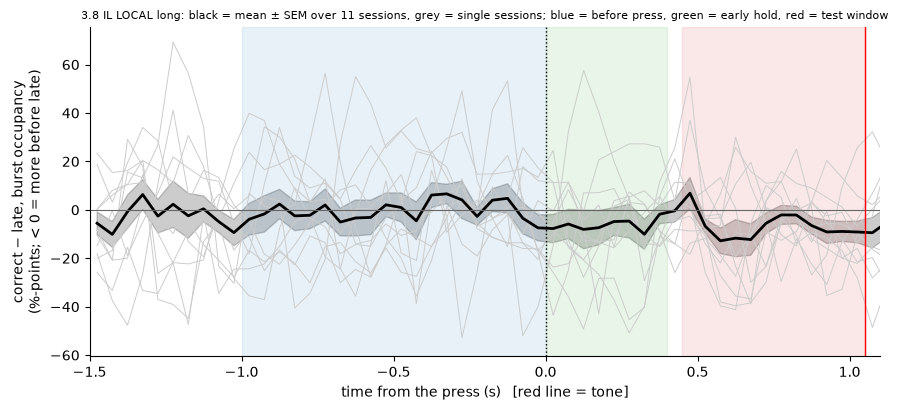

In [30]:
# ── 3.8 CHECK: is the late − correct difference specific to the 0.6 s before the tone? (press-aligned, saved 2.6 data) ──
# needs 3.0 (TR3, nL, K_DIR, A0_3, BIN3, BAND3), 1.0 (lfm.sign_flip_p). Nothing is recomputed.
# Long trials: the tone is always 1.05 s after the press, so the test window (-0.6..0 before the tone) = 0.45..1.05 s after the press.
# Per usable session and 50-ms bin: 100 × (mean occupancy of correct trials − of late trials)  (< 0 = more bursts before late).
# Windows compared (sign-flip across sessions, session = unit): before the press, early hold, and the test window.
# CAUTION: before the press the previous trial may still be ending (release/reward) -> this period is behaviourally different.
import warnings
REF38, REG38, TYP38 = "LOCAL", "IL", "long"
ok = set(nL[nL.usable & (nL.ref == REF38) & (nL.typ == TYP38)]["session"])
d = TR3[(TR3.ref == REF38) & (TR3.group == REG38) & (TR3.typ == TYP38) & TR3.session.isin(ok)]
nb = 70; t = A0_3["press"] + (np.arange(nb) + 0.5) * BIN3                       # bin centres, s from the press
vals = {}
for s, g in d.groupby("session"):
    Z = np.load(os.path.join(K_DIR, s + ".npz")); O = Z[f"{REF38}|karvat2021|{BAND3}|{REG38}|press|occ"]
    ic, il = g[g.cond == "correct"].trial.values, g[g.cond == "late"].trial.values
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        vals[s] = 100 * (np.nanmean(O[ic], axis=0) - np.nanmean(O[il], axis=0))
V = pd.DataFrame(vals).T                                                         # sessions × bins
WIN38 = {"before the press (-1.0..0 s)": (-1.0, 0.0), "early hold (0..0.4 s)": (0.0, 0.4),
         "TEST WINDOW (0.45..1.05 s = -0.6..0 before the tone)": (0.45, 1.05)}
print(f"{REG38} {REF38} {TYP38}: correct − late burst occupancy (%-points; < 0 = more bursts before late), {len(V)} usable sessions")
for lab, (a, b) in WIN38.items():
    v = V.loc[:, (t >= a) & (t < b)].mean(axis=1)
    mn, p, n = lfm.sign_flip_p(v.values)
    print(f"  {lab:55s} mean {mn:+6.2f}   sign-flip p = {p:.3f}   sessions < 0: {(v < 0).sum()} of {n}")
print("  (the test window should reproduce the 3.1 value for this cell, about −6.7 for IL LOCAL long)")

fig, ax = plt.subplots(figsize=(9, 4.2))
for s, r in V.iterrows(): ax.plot(t, r.values, color="0.8", lw=0.7)
m, se = V.mean(axis=0), V.std(axis=0, ddof=1) / np.sqrt(len(V))
ax.plot(t, m, "k", lw=2); ax.fill_between(t, m - se, m + se, color="k", alpha=0.2)
for (a, b), c in zip(WIN38.values(), ("tab:blue", "tab:green", "tab:red")): ax.axvspan(a, b, color=c, alpha=0.1)
ax.axhline(0, color="0.4", lw=0.8); ax.axvline(0, color="k", ls=":", lw=1); ax.axvline(1.05, color="r", lw=1)
ax.set_xlim(-1.5, 1.1); ax.set_xlabel("time from the press (s)   [red line = tone]")
ax.set_ylabel("correct − late, burst occupancy\n(%-points; < 0 = more before late)")
ax.set_title(f"3.8 {REG38} {REF38} {TYP38}: black = mean ± SEM over {len(V)} sessions, grey = single sessions; "
             "blue = before press, green = early hold, red = test window", fontsize=8)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, f"3_8_timecourse_{REG38}_{REF38}_{TYP38}.png"), dpi=140, bbox_inches="tight"); plt.show()

In [1]:
S = "20260620_r0000134_wt_1554"
print(D3[(D3.session == S)][["typ", "correct_all", "late_all", "minus_tm", "minus_rt"]].to_string(index=False))
print(nL[(nL.session == S) & (nL.ref == "LOCAL")][["typ", "n_correct", "n_late", "usable"]].to_string(index=False))

NameError: name 'D3' is not defined

3.6 same tests, two burst definitions.  Q1 = correct − late (%-points; < 0 = paper direction); rho < 0 = paper direction
columns: K = Karvat 2021 (3.1/3.2), N = NeuroDSP (>= 3 cycles). 'F' = Q1 sign-flip p < 0.05 AND t p < 0.05 AND ANOVA p < 0.05 AND rho p < 0.05

===== long trials =====
  ref       group  n occ_K_N quiet_K_N         Q1_K         Q1_N          rho_K          rho_N ANOVA_N F
  CMR mPFC pooled 11 29 → 7%   1 → 58% +3.3 p=0.007 +1.8 p=0.135 +0.084 p=0.061 +0.082 p=0.315 p=0.606  
  CMR          PL 10 29 → 6%   6 → 81% +1.7 p=0.656 +1.6 p=0.379 -0.010 p=0.896 +0.003 p=0.982 p=0.828  
  CMR          IL 11 28 → 6%  12 → 82% +2.9 p=0.193 +0.2 p=0.908 +0.056 p=0.395 +0.008 p=0.916 p=0.284  
  CMR         Cg1  8 30 → 6%   7 → 78% +7.5 p=0.023 +4.6 p=0.016 +0.179 p=0.015 +0.145 p=0.049 p=0.518  
LOCAL mPFC pooled 11 27 → 5%   3 → 63% -2.1 p=0.249 -1.4 p=0.366 -0.074 p=0.138 -0.031 p=0.537 p=0.311  
LOCAL          PL 10 27 → 5%  11 → 84% +2.0 p=0.387 -0.7 p=0.363 +0.020 p=0.687 +

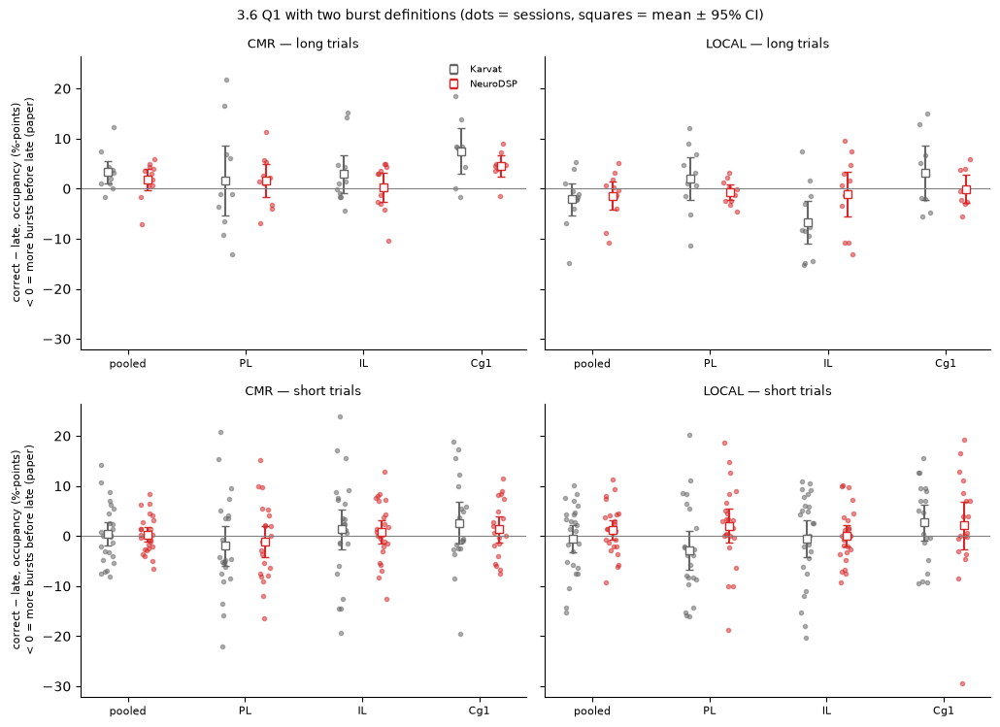

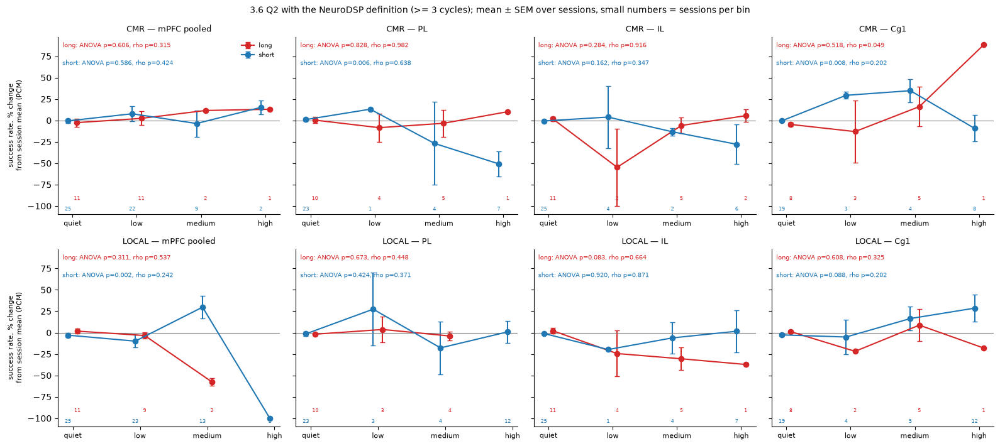

In [152]:
# ── 3.6 ROBUSTNESS: the same Q1 + Q2 with the NeuroDSP burst definition (saved by 2.6; no recomputation) ──
# needs 3.0 (win3, add_pooled, PRE3, REFS3, REGS3, GROUPS3, BAND3, MIN_RT3, MIN_TR3, OUT3, RAT_COL3), 3.1 (V31, S31),
#       3.2 (obin, MIN_BIN, OBINS, T32, A32), 1.0 (lfm.main_conditions, lfm.sign_flip_p, rat_of, PROJECT).
# NeuroDSP (Feingold 2015 dual threshold): band-passed 15-30 Hz amplitude, thresholds 1 and 2 x median amplitude, a burst needs
#   >= 3 cycles (settings of 2.6). Unlike the Karvat 2021 rule it asks for a REAL OSCILLATION of several cycles, so short
#   broadband events should not count. Same trials, windows, usable sessions and tests as 3.1 (late errors) and 3.2.
# Compares per reference × group × trial type: occupancy, Q1 (correct − late), Q2 (rho, ANOVA) for Karvat vs NeuroDSP.
import glob, warnings
from scipy.stats import f_oneway, spearmanr, ttest_1samp
METH36  = "neurodsp"
K36_DIR = os.path.join(PROJECT, "data", "analysis_main", "bursts_karvat2021")            # 2.6 files (do not rerun)

rows = []
for f in sorted(glob.glob(os.path.join(K36_DIR, "*.npz"))):
    s = os.path.basename(f)[:-4]; Z = np.load(f); T = pd.read_csv(f[:-4] + "_trials.csv")
    T["hold_s"] = T["release_s"] - T["press_s"]; rt = (T["release_s"] - T["tone_s"]).values
    C = {k: v.values for k, v in lfm.main_conditions(T).items()}
    tm = T["timing_mismatch"].fillna(False).astype(bool).values
    for ref in REFS3:
        key = {reg: f"{ref}|{METH36}|{BAND3}|{reg}" for reg in REGS3 if f"{ref}|{METH36}|{BAND3}|{reg}|tone|occ" in Z.files}
        if not key: continue
        for typ, (a, z) in PRE3.items():
            idx = np.where((C[f"correct {typ}"] & (rt >= MIN_RT3) | C[f"late {typ}"]) & ~tm)[0]
            if not len(idx): continue
            o = add_pooled({reg: win3(Z[k + "|tone|occ"], "tone", a, z)[idx] for reg, k in key.items()})
            for g in GROUPS3:
                if g in o:
                    rows.append(pd.DataFrame(dict(session=s, rat=str(rat_of(s)), ref=ref, group=g, typ=typ, trial=idx,
                                                  cond=np.where(T["outcome"].values[idx] == "correct", "correct", "late"), occ=o[g])))
if not rows: raise SystemExit(f"no '{METH36}' keys found in {K36_DIR}")
T36 = pd.concat(rows, ignore_index=True)
cnt = T36[T36.group == "mPFC pooled"].groupby(["ref", "typ", "session", "cond"]).size().unstack("cond", fill_value=0)
ok36 = cnt[(cnt.get("correct", 0) >= MIN_TR3) & (cnt.get("late", 0) >= MIN_TR3)].reset_index()[["ref", "typ", "session"]]
T36 = T36.merge(ok36, on=["ref", "typ", "session"])                                      # usable sessions only
T36 = T36.assign(obin=obin(T36["occ"].values), success=T36["cond"].eq("correct").astype(float))
T36.to_csv(os.path.join(OUT3, "_trials_3_6_neurodsp.csv"), index=False)

res, V36, P36 = [], [], []
for (ref, grp, typ), g in T36.groupby(["ref", "group", "typ"], sort=False):
    m = g.groupby(["session", "rat", "cond"])["occ"].mean().unstack("cond").dropna()
    if len(m) < 2: continue
    v = 100 * (m["correct"] - m["late"])
    mn, p_sf, n = lfm.sign_flip_p(v.values); p_t = ttest_1samp(v.values, 0).pvalue if n >= 3 else np.nan
    V36.append(pd.DataFrame(dict(session=v.index.get_level_values(0), rat=v.index.get_level_values(1), value=v.values,
                                 ref=ref, group=grp, typ=typ)))
    sm = g.groupby("session")["success"].mean()
    ps = g.groupby(["session", "rat", "obin"])["success"].agg(["mean", "size"]).reset_index(); ps = ps[ps["size"] >= MIN_BIN]
    ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
    P36.append(ps.assign(ref=ref, group=grp, typ=typ))
    bins_ = [ps.loc[ps.obin == b, "pcm"].dropna().values for b in range(4)]; bins_ = [x for x in bins_ if len(x) >= 3]
    pA = f_oneway(*bins_).pvalue if len(bins_) >= 2 else np.nan
    rho = [spearmanr(gs["occ"], gs["success"]).correlation for _, gs in g.groupby("session") if gs["occ"].nunique() > 2]
    mr, pr, nr = lfm.sign_flip_p(np.array([r for r in rho if np.isfinite(r)], float))
    res.append(dict(ref=ref, group=grp, typ=typ, n=n, occ_pct=100 * g["occ"].mean(), quiet_pct=100 * (g["occ"] == 0).mean(),
                    q1=mn, q1_p_sf=p_sf, q1_p_t=p_t, rho=mr, rho_p=pr, rho_neg=int((np.array(rho) < 0).sum()), p_anova=pA,
                    finding=bool(np.isfinite(pA) and pA < 0.05 and pr < 0.05 and p_sf < 0.05 and p_t < 0.05)))
S36 = pd.DataFrame(res); V36 = pd.concat(V36, ignore_index=True); P36 = pd.concat(P36, ignore_index=True)
S36.to_csv(os.path.join(OUT3, "_stats_3_6_neurodsp.csv"), index=False); P36.to_csv(os.path.join(OUT3, "_pcm_bins_3_6_neurodsp.csv"), index=False)

# Karvat numbers from 3.0-3.2 for the side-by-side
K_occ = T32.groupby(["ref", "group", "typ"])["occ"].agg(occ_pct=lambda x: 100 * x.mean(), quiet_pct=lambda x: 100 * (x == 0).mean())
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 40)
print("3.6 same tests, two burst definitions.  Q1 = correct − late (%-points; < 0 = paper direction); rho < 0 = paper direction")
print("columns: K = Karvat 2021 (3.1/3.2), N = NeuroDSP (>= 3 cycles). 'F' = Q1 sign-flip p < 0.05 AND t p < 0.05 AND ANOVA p < 0.05 AND rho p < 0.05")
for typ in PRE3:
    out = []
    for ref in REFS3:
        for grp in GROUPS3:
            n_ = S36[(S36.ref == ref) & (S36.group == grp) & (S36.typ == typ)]
            k1 = S31[(S31.test == f"late {typ}") & (S31.ref == ref) & (S31.group == grp)]
            k2 = A32[(A32.ref == ref) & (A32.group == grp) & (A32.typ == typ)]
            if n_.empty or k1.empty or k2.empty: continue
            n_, k1, k2 = n_.iloc[0], k1.iloc[0], k2.iloc[0]; ko = K_occ.loc[(ref, grp, typ)]
            out.append(dict(ref=ref, group=grp, n=n_.n,
                            occ_K_N=f"{ko.occ_pct:.0f} → {n_.occ_pct:.0f}%", quiet_K_N=f"{ko.quiet_pct:.0f} → {n_.quiet_pct:.0f}%",
                            Q1_K=f"{k1['mean']:+.1f} p={k1.p_signflip:.3f}", Q1_N=f"{n_.q1:+.1f} p={n_.q1_p_sf:.3f}",
                            rho_K=f"{k2.rho_mean:+.3f} p={k2.p_rho:.3f}", rho_N=f"{n_.rho:+.3f} p={n_.rho_p:.3f}",
                            ANOVA_N=f"p={n_.p_anova:.3f}", F=("◀ FINDING" if n_.finding else "")))
    print(f"\n===== {typ} trials =====\n" + pd.DataFrame(out).to_string(index=False))

# figure 1: Q1 per session, Karvat (grey) next to NeuroDSP (red); rows = trial type, columns = reference
fig, axes = plt.subplots(len(PRE3), len(REFS3), figsize=(5.2 * len(REFS3), 3.8 * len(PRE3)), squeeze=False, sharey=True)
for i, typ in enumerate(PRE3):
    for j, ref in enumerate(REFS3):
        ax = axes[i, j]
        for gi, grp in enumerate(GROUPS3):
            for k, (lab, V, col, dx) in enumerate((("Karvat", V31[V31.test == f"late {typ}"], "0.4", -0.17), ("NeuroDSP", V36[V36.typ == typ], "#d62728", 0.17))):
                d = V[(V.ref == ref) & (V.group == grp)]
                if not len(d): continue
                ax.scatter(gi + dx + np.random.default_rng(gi).uniform(-0.06, 0.06, len(d)), d.value, s=9, color=col, alpha=0.5)
                mm, se = d.value.mean(), d.value.std(ddof=1) / np.sqrt(len(d))
                ax.errorbar(gi + dx, mm, yerr=1.96 * se, fmt="s", color=col, mfc="w", capsize=3, ms=6, label=lab if gi == 0 else None)
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(len(GROUPS3))); ax.set_xticklabels([g.replace("mPFC pooled", "pooled") for g in GROUPS3], fontsize=8)
        ax.set_title(f"{ref} — {typ} trials", fontsize=9)
        if j == 0: ax.set_ylabel("correct − late, occupancy (%-points)\n< 0 = more bursts before late (paper)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("3.6 Q1 with two burst definitions (dots = sessions, squares = mean ± 95% CI)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, "3_6_Q1_neurodsp_vs_karvat.png"), dpi=140, bbox_inches="tight"); plt.show()

# figure 2: Q2 (paper Fig. S6 style) with the NeuroDSP definition; rows = reference, columns = group; yellow box = finding
fig, axes = plt.subplots(len(REFS3), len(GROUPS3), figsize=(4 * len(GROUPS3), 3.6 * len(REFS3)), squeeze=False, sharey=True)
for i, ref in enumerate(REFS3):
    for j, grp in enumerate(GROUPS3):
        ax = axes[i, j]
        for typ, col, dx in (("long", "#d62728", 0.07), ("short", "#1f77b4", -0.07)):
            st = P36[(P36.ref == ref) & (P36.group == grp) & (P36.typ == typ)].groupby("obin")["pcm"].agg(["mean", "sem", "size"]).reindex(range(4))
            ax.errorbar(np.arange(4) + dx, st["mean"], yerr=st["sem"], marker="o", color=col, capsize=3, label=typ)
            a = S36[(S36.ref == ref) & (S36.group == grp) & (S36.typ == typ)]
            if len(a):
                a = a.iloc[0]
                ax.text(0.02, 0.97 if typ == "long" else 0.87, f"{typ}: ANOVA p={a.p_anova:.3f}, rho p={a.rho_p:.3f}" + ("  ★ FINDING" if a.finding else ""),
                        transform=ax.transAxes, fontsize=7, color=col, va="top",
                        bbox=dict(fc="#ffe066", ec="none", pad=1.5) if a.finding else None)
            for b in range(4):
                if np.isfinite(st["size"].iat[b]):
                    ax.text(b + dx, 0.08 if typ == "long" else 0.02, f"{int(st['size'].iat[b])}", fontsize=6, color=col, ha="center", transform=ax.get_xaxis_transform())
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels(OBINS, fontsize=8); ax.set_title(f"{ref} — {grp}", fontsize=9)
        if j == 0: ax.set_ylabel("success rate, % change\nfrom session mean (PCM)", fontsize=8)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper right")
fig.suptitle("3.6 Q2 with the NeuroDSP definition (>= 3 cycles); mean ± SEM over sessions, small numbers = sessions per bin", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT3, "3_6_Q2_neurodsp.png"), dpi=140, bbox_inches="tight"); plt.show()

NeuroDSP burst-on share of this window: 0%; minimum burst length = 200 ms


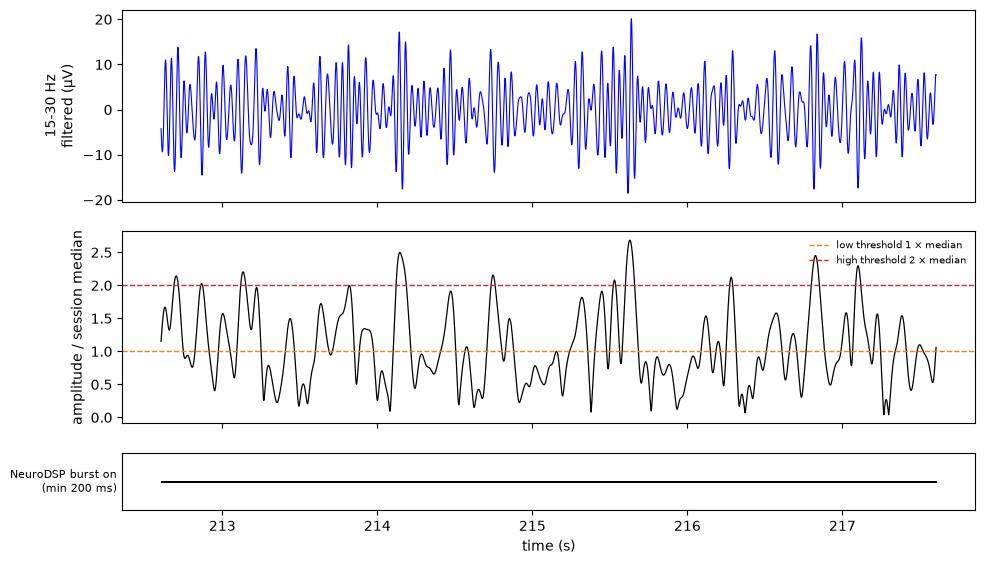

In [155]:
# ── NeuroDSP view (exact amplitude from neurodsp itself): filtered trace, normalised amplitude, thresholds, burst-on row ──
import numpy as np, matplotlib.pyplot as plt, scipy.signal as ss
from neurodsp.burst import detect_bursts_dual_threshold
from neurodsp.timefrequency import amp_by_time

def show_dsp(lfp, fs, win, band=(15, 30), thr=(1, 2), min_cyc=3, t0=0.0):
    x = np.asarray(lfp, float)
    on = detect_bursts_dual_threshold(x, fs, thr, f_range=band, min_n_cycles=min_cyc)     # as in 2.6 (whole session)
    amp = amp_by_time(x, fs, band, remove_edges=False); amp = amp / np.median(amp)        # as inside the function: x median
    sos = ss.butter(3, band, btype="bandpass", fs=fs, output="sos"); f = ss.sosfiltfilt(sos, x)   # filtered trace for drawing only
    a, z = int((win[0] - t0) * fs), int((win[1] - t0) * fs); t = t0 + np.arange(a, z) / fs
    min_ms = int(np.ceil(min_cyc * fs / band[0])) / fs * 1000
    fig, ax = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 2, .6]))
    ax[0].plot(t, f[a:z], "b", lw=.8); ax[0].set_ylabel(f"{band[0]}-{band[1]} Hz\nfiltered (µV)")
    ax[1].plot(t, amp[a:z], "k", lw=.9)
    ax[1].axhline(thr[0], color="tab:orange", ls="--", lw=1, label=f"low threshold {thr[0]} × median")
    ax[1].axhline(thr[1], color="tab:red", ls="--", lw=1, label=f"high threshold {thr[1]} × median")
    ax[1].set_ylabel("amplitude / session median"); ax[1].legend(fontsize=7, frameon=False, loc="upper right")
    ax[2].fill_between(t, 0, on[a:z], step="mid", color="k"); ax[2].set_yticks([]); ax[2].set_xlabel("time (s)")
    ax[2].set_ylabel(f"NeuroDSP burst on\n(min {min_ms:.0f} ms)", rotation=0, ha="right", va="center", fontsize=8)
    print(f"NeuroDSP burst-on share of this window: {on[a:z].mean():.0%}; minimum burst length = {min_ms:.0f} ms")
    plt.show()

show_dsp(X[:, 0], fs, win=(tone - 4, tone + 1))

In [156]:
amp = amp_by_time(X[:, 0], fs, (15, 30), remove_edges=False); amp = amp / np.median(amp)
a, z = int((tone - 4) * fs), int((tone + 1) * fs)
over = amp >= 1.0
starts = np.flatnonzero(np.diff(np.concatenate([[0], over.astype(np.int8)])) == 1)
ends   = np.flatnonzero(np.diff(np.concatenate([over.astype(np.int8), [0]])) == -1)
print("stretches above 1x median that also reach 2x, in the plotted window (start s, length ms, peak):")
for s0, e0 in zip(starts, ends):
    if s0 >= a and e0 < z and amp[s0:e0 + 1].max() >= 2.0:
        print(f"  {s0 / fs:8.2f} s   {(e0 - s0 + 1) / fs * 1000:5.0f} ms   peak {amp[s0:e0 + 1].max():.2f}")
print("needed for a NeuroDSP burst: >= 200 ms")

stretches above 1x median that also reach 2x, in the plotted window (start s, length ms, peak):
    212.82 s      91 ms   peak 2.03
    213.09 s     157 ms   peak 2.20
    214.10 s     115 ms   peak 2.50
    214.71 s      97 ms   peak 2.16
    215.50 s      64 ms   peak 2.08
    215.58 s     104 ms   peak 2.68
    216.25 s      65 ms   peak 2.12
    216.77 s     119 ms   peak 2.45
    217.07 s     109 ms   peak 2.30
needed for a NeuroDSP burst: >= 200 ms


In [11]:
need = ["os", "np", "pd", "plt", "lfm", "rat_of", "PROJECT", "find_rec", "load_cmr", "XB", "si", "spre", "session_trials_v2"]
print("missing:", [n for n in need if n not in globals()])

missing: ['rat_of', 'session_trials_v2']


In [4]:
rat_of = lambda s: s.split("_")[1][-3:]                                  # "r0000136" -> "136"

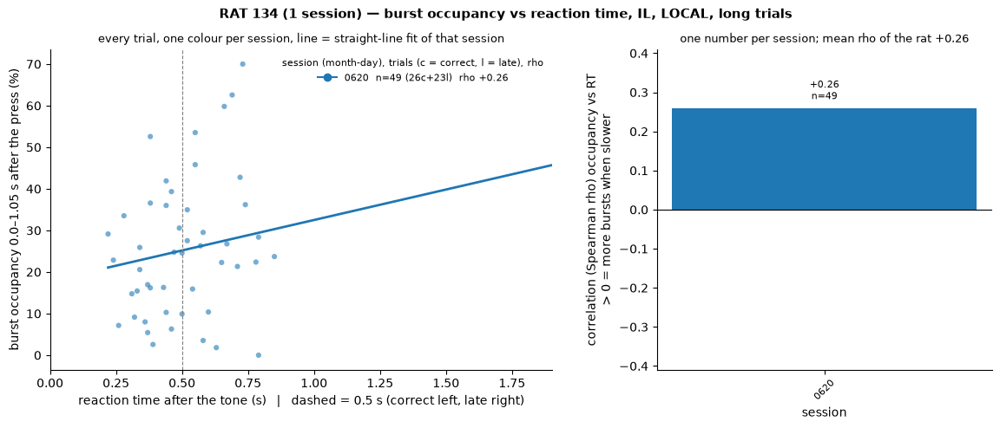

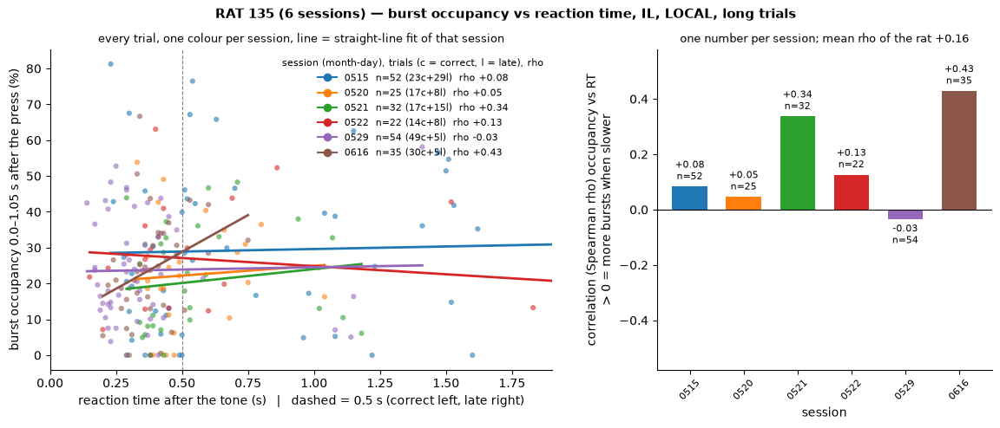

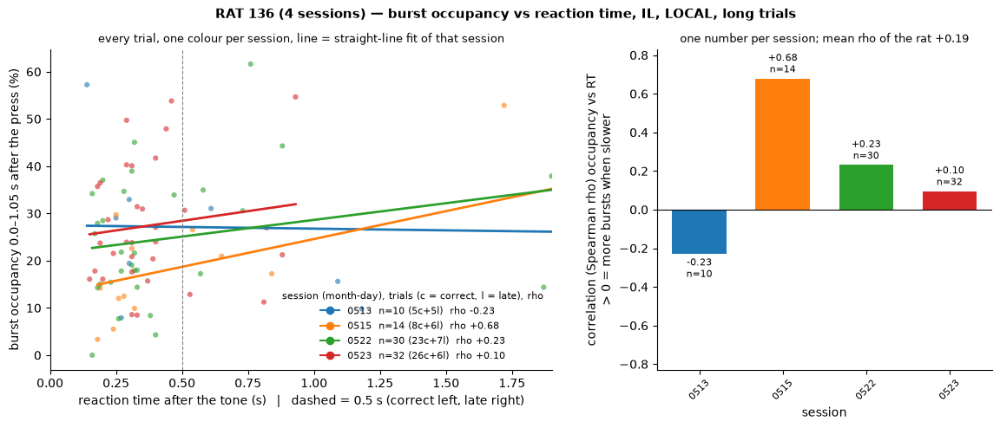

In [52]:
# ── ONE FIGURE PER ANIMAL: all trials of each session (RT x, occupancy y) + ONE correlation number per session ──
# add AFTER the occupancy-vs-RT cell (cell_rt4): uses D (trials), TAB (rho per session), REF_R, REG_R, WIN_R.
# rho = Spearman correlation of occupancy with RT inside one session (descriptive, no p-value); > 0 = more bursts when slower.
import numpy as np, matplotlib.pyplot as plt
XMAX_R = max(float(np.percentile(D.rt, 97)) * 1.08, 0.6)
for r in sorted(D.rat.unique()):
    ts = TAB[TAB.rat == r].sort_values("session"); cols = plt.cm.tab10(np.arange(len(ts)) % 10)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1], wspace=0.25))
    for (i, t), c in zip(ts.reset_index(drop=True).iterrows(), cols):
        g = D[D.session == t.session]
        ax[0].scatter(g.rt, g.occ, s=20, alpha=.6, color=c, ec="none")
        if len(g) >= 5 and g.rt.nunique() > 1:                                       # straight-line fit of this session (drawing aid)
            b = np.polyfit(g.rt, g.occ, 1); xx = np.array([g.rt.min(), min(g.rt.max(), XMAX_R)]); ax[0].plot(xx, np.polyval(b, xx), color=c, lw=2)
        ax[0].plot([], [], "o-", color=c, label=f"{t.session[4:8]}  n={len(g)} ({t.n_correct}c+{t.n_late}l)  rho {t.rho:+.2f}")
    ax[0].axvline(0.5, color="0.5", ls="--", lw=.8); ax[0].set_xlim(0, XMAX_R)
    ax[0].set_xlabel("reaction time after the tone (s)   |   dashed = 0.5 s (correct left, late right)")
    ax[0].set_ylabel(f"burst occupancy {WIN_R[0]}–{WIN_R[1]} s after the press (%)")
    ax[0].legend(frameon=False, fontsize=8, title="session (month-day), trials (c = correct, l = late), rho", title_fontsize=8, loc="best")
    ax[0].set_title("every trial, one colour per session, line = straight-line fit of that session", fontsize=9)
    ax[1].bar(range(len(ts)), ts.rho, color=cols, width=.65)
    for i, (rho, n) in enumerate(zip(ts.rho, ts.n_correct + ts.n_late)):
        ax[1].text(i, rho + (0.015 if rho >= 0 else -0.015), f"{rho:+.2f}\nn={n}", ha="center", va="bottom" if rho >= 0 else "top", fontsize=8)
    ax[1].axhline(0, color="k", lw=.8); ax[1].set_xticks(range(len(ts))); ax[1].set_xticklabels([s[4:8] for s in ts.session], rotation=45, fontsize=8)
    lim = max(0.3, float(np.nanmax(np.abs(ts.rho))) + 0.15); ax[1].set_ylim(-lim, lim)
    ax[1].set_ylabel("correlation (Spearman rho) occupancy vs RT\n> 0 = more bursts when slower"); ax[1].set_xlabel("session")
    ax[1].set_title(f"one number per session; mean rho of the rat {ts.rho.mean():+.2f}", fontsize=9)
    for a in ax:
        for sp in ("top", "right"): a.spines[sp].set_visible(False)
    fig.suptitle(f"RAT {r} ({len(ts)} session{'s' if len(ts) > 1 else ''}) — burst occupancy vs reaction time, {REG_R}, {REF_R}, long trials", fontsize=11, weight="bold")
    plt.show()

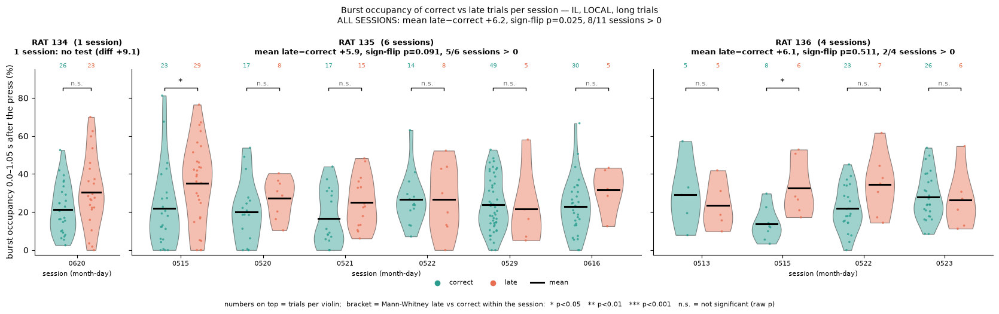

IL LOCAL long, window 0.0–1.05 s after the press.  diff = mean occupancy late − correct (%-points); > 0 = more bursts before late
rat                   session  n_correct  n_late  diff_late_minus_correct  p_mannwhitney
134 20260620_r0000134_wt_1554         26      23                   9.1446         0.0796
135 20260515_r0000135_wt_1953         23      29                  12.9888         0.0303
135 20260520_r0000135_wt_1357         17       8                   7.2864         0.2100
135 20260521_r0000135_wt_1309         17      15                   8.2939         0.0615
135 20260522_r0000135_wt_1716         14       8                   0.2160         0.9734
135 20260529_r0000135_wt_1411         49       5                  -2.3320         0.4556
135 20260616_r0000135_wt_1742         30       5                   8.8000         0.1791
136 20260513_r0000136_wt_1729          5       5                  -5.9238         0.6905
136 20260515_r0000136_wt_1817          8       6                  19.

In [56]:
# ── VIOLIN: burst occupancy of correct vs late trials, every session (add AFTER the occupancy-vs-RT cell; uses D, REF_R, REG_R, WIN_R) ──
# One panel per rat; per session two violins (correct = green, late = orange) of the trial occupancy; dots = trials, black bar = mean.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
# STATISTICS (added): per session, Mann-Whitney U (late vs correct trials, two-sided; trials of one session are treated as independent,
# so this is exploratory); session value = mean occupancy LATE − CORRECT (%-points; > 0 = more bursts before late = the paper's direction).
# Across sessions: sign-flip test on the session values (session = unit, as in 3.1; needs lfm), for each rat and for all sessions. Raw p, no FDR.
ST = []
for s_, g_ in D.groupby("session"):
    a_, b_ = g_[g_.cond == "correct"].occ.values, g_[g_.cond == "late"].occ.values
    if len(a_) >= 3 and len(b_) >= 3:
        ST.append(dict(rat=g_.rat.iat[0], session=s_, n_correct=len(a_), n_late=len(b_), diff_late_minus_correct=b_.mean() - a_.mean(),
                       p_mannwhitney=mannwhitneyu(b_, a_, alternative="two-sided").pvalue))
ST = pd.DataFrame(ST).sort_values(["rat", "session"]).reset_index(drop=True)
def _acc(v):
    v = np.asarray(v, float)
    if len(v) < 3: return f"{len(v)} session: no test (diff {v[0]:+.1f})" if len(v) == 1 else f"{len(v)} sessions: no test"
    mn, p, n = lfm.sign_flip_p(v); return f"mean late−correct {mn:+.1f}, sign-flip p={p:.3f}, {int((v > 0).sum())}/{n} sessions > 0"
ACC = {r: _acc(g.diff_late_minus_correct.values) for r, g in ST.groupby("rat")}; ACC_ALL = _acc(ST.diff_late_minus_correct.values)
def _star(p): return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "n.s."
RATS_V = sorted(D.rat.unique()); fig, axs = plt.subplots(1, len(RATS_V), figsize=(5.6 * len(RATS_V), 4.8), squeeze=False, sharey=True,
                                                           gridspec_kw=dict(width_ratios=[max(1, D[D.rat == r].session.nunique()) for r in RATS_V]))
YMAX, YR = float(D.occ.max()), float(D.occ.max() - D.occ.min())
COL = {"correct": "#2a9d8f", "late": "#e76f51"}; rng = np.random.default_rng(0)
for ci, r in enumerate(RATS_V):
    ax = axs[0, ci]; ss = sorted(D[D.rat == r].session.unique())
    for si, s in enumerate(ss):
        g = D[D.session == s]
        for c, dx in (("correct", -0.2), ("late", 0.2)):
            v = g[g.cond == c].occ.values
            if len(v) < 2: continue
            vp = ax.violinplot(v, positions=[si + dx], widths=0.36, showextrema=False)
            for b in vp["bodies"]: b.set_facecolor(COL[c]); b.set_edgecolor("k"); b.set_alpha(.45); b.set_linewidth(.8)
            ax.scatter(si + dx + rng.uniform(-.05, .05, len(v)), v, s=7, color=COL[c], alpha=.8, zorder=3, ec="none")
            ax.plot([si + dx - .13, si + dx + .13], [v.mean()] * 2, "k", lw=2.2, zorder=4)
        _t = ST[ST.session == s]
        if len(_t):                                                                  # bracket + star between the correct and the late violin
            yb = YMAX + 0.05 * YR; ax.plot([si - .2, si - .2, si + .2, si + .2], [yb - .015 * YR, yb, yb, yb - .015 * YR], "k", lw=1)
            ax.text(si, yb + .005 * YR, _star(_t.p_mannwhitney.iat[0]), ha="center", va="bottom", fontsize=11 if _t.p_mannwhitney.iat[0] < .05 else 8,
                    color="k" if _t.p_mannwhitney.iat[0] < .05 else "0.4")
        ax.text(si - .2, 1.01, f"{int((g.cond == 'correct').sum())}", color=COL["correct"], ha="center", fontsize=7, transform=ax.get_xaxis_transform())
        ax.text(si + .2, 1.01, f"{int((g.cond == 'late').sum())}", color=COL["late"], ha="center", fontsize=7, transform=ax.get_xaxis_transform())
    ax.set_xticks(range(len(ss))); ax.set_xticklabels([s[4:8] for s in ss], fontsize=8, rotation=0); ax.set_xlim(-.6, len(ss) - .4); ax.set_ylim(D.occ.min() - .03 * YR, YMAX + .17 * YR)
    ax.set_title(f"RAT {r}  ({len(ss)} session{'s' if len(ss) > 1 else ''})\n{ACC.get(r, '')}", fontsize=9.5, weight="bold", pad=18)
    if ci == 0: ax.set_ylabel(f"burst occupancy {WIN_R[0]}–{WIN_R[1]} s after the press (%)")
    ax.set_xlabel("session (month-day)", fontsize=8)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0, 0].scatter([], [], c=COL["correct"], label="correct"); axs[0, 0].scatter([], [], c=COL["late"], label="late"); axs[0, 0].plot([], [], "k", lw=2.2, label="mean")
fig.legend(*axs[0, 0].get_legend_handles_labels(), frameon=False, fontsize=8, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.text(0.5, -0.07, "numbers on top = trials per violin;  bracket = Mann-Whitney late vs correct within the session:  * p<0.05   ** p<0.01   *** p<0.001   n.s. = not significant (raw p)", ha="center", fontsize=8)
fig.suptitle(f"Burst occupancy of correct vs late trials per session — {REG_R}, {REF_R}, long trials\nALL SESSIONS: {ACC_ALL}", fontsize=10); fig.tight_layout(); plt.show()

# across sessions
print(f"{REG_R} {REF_R} long, window {WIN_R[0]}–{WIN_R[1]} s after the press.  diff = mean occupancy late − correct (%-points); > 0 = more bursts before late")
print(ST.round(4).to_string(index=False))
print("\nacross sessions (sign-flip on the session differences; session = unit):")
for lab, v in [("all sessions", ST.diff_late_minus_correct.values)] + [(f"rat {r}", g.diff_late_minus_correct.values) for r, g in ST.groupby("rat")]:
    if len(v) >= 3:
        mn, p, n = lfm.sign_flip_p(v); print(f"  {lab:13s} mean {mn:+.2f}   p = {p:.3f}   sessions with diff > 0: {int((v > 0).sum())} of {n}")
    else:
        print(f"  {lab:13s} {len(v)} session(s): too few for a test; values {np.round(v, 2)}")

In [46]:
# ── session filters, from all sessions to the plot (add at the END of the occupancy-vs-RT cell, or run after it) ──
# needs the cell above (D, REF_R, REG_R, NQ) and 3.0 (nL, K_DIR). Prints the funnel and one line per session with the reason.
import glob
MINT = 3 * NQ                                                       # same rule as in the plot loop
allf = [os.path.basename(f)[:-4] for f in sorted(glob.glob(os.path.join(K_DIR, "*.npz")))]
tab = nL[(nL.ref == REF_R) & (nL.typ == "long")][["session", "rat", "n_correct", "n_late", "usable"]].copy()
ntr = D.groupby("session").size()
tab["n_trials_used"] = tab.session.map(ntr).fillna(0).astype(int)
def why(r):
    if r.n_correct < MIN_TR3 or r.n_late < MIN_TR3: return f"out: needs >= {MIN_TR3} correct and >= {MIN_TR3} late (has {r.n_correct} + {r.n_late})"
    if r.n_trials_used == 0: return "out: no occupancy for this region/reference in the saved file"
    if r.n_trials_used < MINT: return f"out of the plot: {r.n_trials_used} trials < {MINT} (needs {NQ} groups of 3)"
    return "in the plot"
tab["status"] = tab.apply(why, axis=1)
print(f"{REG_R} {REF_R} long — session filters")
print(f"  1) session files (2.6):                          {len(allf)}")
print(f"  2) sessions with correct/late long trials left:  {len(tab)}   (after 0.5 blocks, timing_mismatch, RT >= {MIN_RT3} s)")
print(f"  3) with >= {MIN_TR3} correct and >= {MIN_TR3} late (usable):        {int(tab.usable.sum())}")
print(f"  4) with occupancy for {REG_R}:                      {int((tab.usable & (tab.n_trials_used > 0)).sum())}")
print(f"  5) drawn in the plot (>= {MINT} trials):             {int((tab.status == 'in the plot').sum())}")
print("\n  per rat (usable -> drawn):", {r: f"{int(g.usable.sum())} -> {int((g.status == 'in the plot').sum())}" for r, g in tab.groupby('rat')})
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 100)
print("\n", tab.sort_values(["rat", "session"]).to_string(index=False))

IL LOCAL long — session filters
  1) session files (2.6):                          59
  2) sessions with correct/late long trials left:  59   (after 0.5 blocks, timing_mismatch, RT >= 0.12 s)
  3) with >= 5 correct and >= 5 late (usable):        11
  4) with occupancy for IL:                      11
  5) drawn in the plot (>= 12 trials):             10

  per rat (usable -> drawn): {'134': '1 -> 1', '135': '6 -> 6', '136': '4 -> 3'}

                   session rat  n_correct  n_late  usable  n_trials_used                                                status
20260609_r0000134_wt_1622 134         20       0   False              0    out: needs >= 5 correct and >= 5 late (has 20 + 0)
20260610_r0000134_wt_1923 134         24       2   False              0    out: needs >= 5 correct and >= 5 late (has 24 + 2)
20260611_r0000134_wt_1309 134          5       0   False              0     out: needs >= 5 correct and >= 5 late (has 5 + 0)
20260612_r0000134_wt_1447 134          4       0   False 

In [14]:
# ── NEW TRIAL FILTER (v3) — everything is built from the SESSION FILES (share/trials.csv + session_info.json); all_trials.csv is NOT used ──
# needs 1.0 (os, np, pd, PROJECT, TABLES). Reads <PROJECT>/data/2_processed/<session>/share/trials.csv and session_info.json for the
# sessions of tables/usable_sessions.csv (same sessions and same label definitions as the all_trials.csv cell of the sessions-info notebook).
# Press time: press_ttl_np_s (TTL) where it exists; where there is NO TTL, press_np_s (MA press mapped to the neural clock) is used instead.
#   Tone and release = press time + MA interval (tone - press, release - press), the same formula for both. Column press_source = TTL / MA / none.
# Steps in this order (each step works on what the previous steps left):
#   R1 no press time at all (no TTL and no press_np_s) | R2 touch | R4 outcome "other" | R3 early with hold > 1.05 s (strictly greater) |
#   WT-manipulation sessions | timing_mismatch.   NOT used any more: 0.5-block rule, correct RT >= 0.12 s,
#   >= 5 correct and >= 5 late per session, early-long hold filter.   Trial types (short/long) from the WT criterion as before.
HOLD_MAX_R3  = 1.05        # early trials with hold > this are excluded (compared after rounding to 1 ms)
USE_MA_PRESS = True        # True = trials without TTL get press_np_s (MA press on the neural clock); False = they are excluded as before
REMOVE_TM    = True        # False = keep the timing_mismatch trials (they are only counted in the funnel)
OUT_F = os.path.join(TABLES, "filter_v2"); os.makedirs(OUT_F, exist_ok=True)

PROC_F = os.path.join(PROJECT, "data", "2_processed")
def build_trials(proc=PROC_F, use_ma=USE_MA_PRESS):
    """One table with ALL trials of all usable sessions, read from the session files (no all_trials.csv)."""
    import json
    usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
    tabs = []
    for _, u in usable.iterrows():
        s = u["session"]
        b = pd.read_csv(os.path.join(proc, s, "share", "trials.csv"))
        sync = json.load(open(os.path.join(proc, s, "share", "session_info.json")))["sync"]
        t0, t1 = sync["pulse_span_behav_s"]
        t = pd.DataFrame({"session": s, "rat": u["rat"], "trial": np.arange(len(b))})
        t["outcome"] = np.select([b["is_touch"].astype(bool), b["correct"] == 1, b["early"] == 1, b["late"] == 1],
                                 ["touch", "correct", "early", "late"], "other")
        t["wt"] = b["wt"].round(2)
        t["type"] = np.select([t["wt"] == 0.3, t["wt"] == 1.0], ["short", "long"], "other_wt")
        t["long_prob"] = b["long_prob"].round(2)
        t["full_hold"] = b["full_hold"]
        t["hold_s"] = b["release"] - b["press"]
        has_tone = b["tone"] > 0
        t["tone_delay_s"] = np.where(has_tone, b["tone"] - b["press"], np.nan)
        t["rt_s"] = np.where(has_tone, b["release"] - b["tone"], np.nan)
        t["press_ttl_np_s"], t["press_np_s"] = b["press_ttl_np_s"], b["press_np_s"]
        t["press_from_ttl"] = b["press_ttl_np_s"].notna()
        p = b["press_ttl_np_s"].where(b["press_ttl_np_s"].notna(), b["press_np_s"]) if use_ma else b["press_ttl_np_s"]
        t["press_source"] = np.where(t["press_from_ttl"], "TTL", np.where(p.notna(), "MA", "none"))
        t["press_neural_s"]   = p
        t["tone_neural_s"]    = np.where(has_tone, p + (b["tone"] - b["press"]), np.nan)
        t["release_neural_s"] = p + (b["release"] - b["press"])
        t["inside_sync_span"] = b["press"].between(t0, t1)
        wts = set(t["wt"].dropna().unique())
        t["wt_manip_session"] = len(wts - {0.3, 1.0}) > 0
        tabs.append(t)
    A = pd.concat(tabs, ignore_index=True)
    edge_zone = (A["hold_s"] >= A["wt"]) & (A["hold_s"] < A["tone_delay_s"] - 1e-9)           # same flag as in all_trials.csv
    A["timing_mismatch"] = edge_zone | ((A["outcome"] == "correct") & (A["rt_s"] > 0.5))
    return A

def new_trial_filter(A, hold_max=HOLD_MAX_R3, remove_tm=REMOVE_TM):
    """A = all_trials table. Returns (kept trials, funnel table, table of excluded trials, per-session counts)."""
    A = A.copy()
    hold = (A["release_neural_s"] - A["press_neural_s"]).where(lambda x: x.notna(), A["hold_s"]).round(3)
    A["hold"] = hold
    nopress = A["press_neural_s"].isna() | (A["outcome"].isin(["correct", "early", "late"]) & A["release_neural_s"].isna())
    steps = [("R1", "no press time at all (no TTL and no press_np_s)" if USE_MA_PRESS else "press without TTL",
              nopress if USE_MA_PRESS else ~A["press_from_ttl"].astype(bool)),
             ("R2", "touch (hold < 0.1 s, not a real press)", A["outcome"].eq("touch")),
             ("R4", 'outcome "other"',                        A["outcome"].eq("other")),
             ("R3", f"early with hold > {hold_max} s",        A["outcome"].eq("early") & (hold > hold_max)),
             ("WT", "WT-manipulation session (rat 134)",      A["wt_manip_session"].astype(bool))]
    if remove_tm:
        steps.append(("TM", "timing_mismatch", A["timing_mismatch"].astype(bool)))
    alive = np.ones(len(A), bool); rows, exc = [], []
    per_ses = A.groupby("session").size().rename("start").to_frame()
    def row(name, rule, removed, only):
        rows.append(dict(step=name, rule=rule, removed=removed, only_this_rule=only, trials_left=int(alive.sum()),
                         sessions_left=A.loc[alive, "session"].nunique(),
                         **{f"rat {r}": int((alive & (A["rat"].astype(str) == r)).sum()) for r in ("134", "135", "136")},
                         **{f"sessions rat {r}": A.loc[alive & (A["rat"].astype(str) == r), "session"].nunique() for r in ("134", "135", "136")}))
    row("start", "all trials in the session files", 0, 0)
    for name, rule, m in steps:
        m = m.values; hit = alive & m
        exc.append(A.loc[hit, ["session", "rat", "trial", "outcome", "type", "long_prob", "hold", "timing_mismatch"]].assign(step=name, rule=rule))
        per_ses[f"removed {name}"] = pd.Series(hit, index=A.index).groupby(A["session"]).sum()
        alive = alive & ~m
        row(name, rule, int(hit.sum()), int(m.sum()))
        per_ses[f"left after {name}"] = pd.Series(alive, index=A.index).groupby(A["session"]).sum()
    K = A[alive].copy()
    return K, pd.DataFrame(rows), pd.concat(exc, ignore_index=True), per_ses.fillna(0).astype(int)

AT_F = build_trials()
print("press source (all trials):", AT_F["press_source"].value_counts().to_dict())
KF, FUN, EXCL, PS = new_trial_filter(AT_F)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

print(f"session files: {len(AT_F)} trials, {AT_F.session.nunique()} sessions")
print("\n===== FUNNEL (sequential: each row removes only what the earlier rows left) =====")
print(FUN.to_string(index=False))
print("  removed = trials taken out at this step | only_this_rule = trials the rule would flag if it were applied alone")

print("\n===== WHAT EACH STEP EXCLUDED =====")
for name, g in EXCL.groupby("step", sort=False):
    ses = g.groupby("session").size().sort_values(ascending=False)
    print(f"\n[{name}] {g['rule'].iloc[0]}: {len(g)} trials in {len(ses)} sessions;  by rat: {g.groupby('rat').size().to_dict()}")
    print("   outcomes:", g["outcome"].value_counts().to_dict(), "| types:", g["type"].value_counts().to_dict())
    lost = [s for s in ses.index if PS.loc[s, f"left after {name}"] == 0 and PS.loc[s, f"removed {name}"] > 0]
    if lost: print("   sessions with NO trial left after this step:", ", ".join(lost))
    if name in ("R3", "R4") or len(g) <= 40:
        print(g[["session", "trial", "outcome", "type", "long_prob", "hold"]].to_string(index=False))
    else:
        print("   trials per session (top 15 of", len(ses), "):", ", ".join(f"{s} ({n})" for s, n in ses.head(15).items()))
    if name == "R3":
        eq = AT_F[AT_F.outcome.eq("early") & ((AT_F.release_neural_s - AT_F.press_neural_s).round(3) == HOLD_MAX_R3)]
        print(f"   early trials with hold EXACTLY {HOLD_MAX_R3} s (kept now, excluded by the old rule '>='): {len(eq)}")
        if len(eq): print(eq[["session", "trial", "type", "long_prob"]].to_string(index=False))

print("\n===== KEPT TRIALS (after all steps) =====")
print(f"{len(KF)} trials, {KF.session.nunique()} sessions;  per rat trials: {KF.groupby('rat').size().to_dict()}, sessions: {KF.groupby('rat').session.nunique().to_dict()}")
print("press source of the kept trials:", KF["press_source"].value_counts().to_dict(), "| per rat:", KF.groupby(["rat", "press_source"]).size().unstack(fill_value=0).to_dict("index"))
ma = KF[KF.press_source == "MA"]
if len(ma):
    print(f"  {len(ma)} kept trials use the MA press (jitter ~12 ms vs TTL); outcomes: {ma.outcome.value_counts().to_dict()}; sessions with most:",
          ", ".join(f"{s} ({n})" for s, n in ma.groupby("session").size().sort_values(ascending=False).head(10).items()))
print("outcome x type:"); print(pd.crosstab(KF["outcome"], KF["type"], margins=True).to_string())
print("by long_prob block:", KF["long_prob"].round(2).value_counts().sort_index().to_dict(), "(all blocks are used now)")
print("\ncorrect/late/early per rat and type:")
print(KF[KF.type.isin(["short", "long"])].groupby(["rat", "type", "outcome"]).size().unstack("outcome", fill_value=0).to_string())

# compare with the old table all_trials.csv (only if it exists; the burst files of 2.6 were made from its keep = True, without WT sessions)
OLD = os.path.join(TABLES, "all_trials.csv")
if os.path.exists(OLD):
    AO = pd.read_csv(OLD)
    old = AO[AO["keep"].astype(bool) & ~AO["wt_manip_session"].astype(bool)]
    ko, kn = set(zip(old.session, old.trial)), set(zip(KF.session, KF.trial))
    print(f"\ncheck vs old table: old kept (no WT sessions) {len(ko)} | new kept {len(kn)} | in new but not in old {len(kn - ko)} | in old but not in new {len(ko - kn)}"
          f"\n  in old but not in new = timing_mismatch trials (removed here); in new but not in old = trials that now use the MA press: they have NO burst data in the 2.6/2.8 files yet")
    if len(kn - ko):
        new_only = KF[[(a, b) in (kn - ko) for a, b in zip(KF.session, KF.trial)]]
        print(f"  -> {len(new_only)} trials in {new_only.session.nunique()} sessions need 2.6 (and 2.8) to be rerun for these sessions; sessions:",
              ", ".join(f"{s} ({n})" for s, n in new_only.groupby('session').size().sort_values(ascending=False).head(12).items()))

# table for a rerun of 2.6 / 2.8: same columns as all_trials.csv. keep = passes R1, R2, R4, R3 (like the old keep); keep_v2 = passes all steps (also WT sessions, timing_mismatch)
OUTT = AT_F.copy(); k1 = set(zip(KF.session, KF.trial))
tmp, _, _, _ = new_trial_filter(AT_F, remove_tm=False)
k0 = set(zip(tmp.session, tmp.trial))
OUTT["keep"] = [(a, b) in k0 for a, b in zip(OUTT.session, OUTT.trial)]
OUTT["keep_v2"] = [(a, b) in k1 for a, b in zip(OUTT.session, OUTT.trial)]
OUTT.to_csv(os.path.join(OUT_F, "all_trials_v2.csv"), index=False)
FUN.to_csv(os.path.join(OUT_F, "funnel.csv"), index=False); EXCL.to_csv(os.path.join(OUT_F, "excluded_trials.csv"), index=False)
PS.to_csv(os.path.join(OUT_F, "per_session.csv")); KF.to_csv(os.path.join(OUT_F, "kept_trials.csv"), index=False)
print("\nsaved in", OUT_F, ": all_trials_v2.csv (all trials, keep / keep_v2), funnel.csv, excluded_trials.csv (every excluded trial with its step), per_session.csv, kept_trials.csv")

press source (all trials): {'TTL': 8894, 'MA': 923, 'none': 377}
session files: 10194 trials, 63 sessions

===== FUNNEL (sequential: each row removes only what the earlier rows left) =====
 step                                            rule  removed  only_this_rule  trials_left  sessions_left  rat 134  rat 135  rat 136  sessions rat 134  sessions rat 135  sessions rat 136
start                 all trials in the session files        0               0        10194             63     1967     5339     2888                14                29                20
   R1 no press time at all (no TTL and no press_np_s)      377             377         9817             63     1936     5101     2780                14                29                20
   R2          touch (hold < 0.1 s, not a real press)      639             662         9178             63     1840     4810     2528                14                29                20
   R4                                 outcome "other"      

In [15]:
# ── table: rule | session | trials excluded | their outcomes (needs cell A: EXCL, OUT_F) ──
ORDER = {"R1": 0, "R2": 1, "R4": 2, "R3": 3, "WT": 4, "TM": 5}
g = EXCL.groupby(["step", "rule", "session"])
SES_TAB = g.size().rename("trials").to_frame()
SES_TAB["outcomes"] = g["outcome"].agg(lambda x: ", ".join(f"{k} {v}" for k, v in x.value_counts().items()))
SES_TAB = SES_TAB.reset_index()
SES_TAB["rat"] = SES_TAB["session"].str.extract(r"_r0000(\d+)_")[0]
SES_TAB = SES_TAB.sort_values(["step", "trials"], key=lambda c: c.map(ORDER) if c.name == "step" else -c).reset_index(drop=True)
SES_TAB[["step", "rule", "rat", "session", "trials", "outcomes"]].to_csv(os.path.join(OUT_F, "excluded_per_rule_and_session.csv"), index=False)
pd.set_option("display.max_rows", 500, "display.width", 250, "display.max_colwidth", 80)
print(SES_TAB[["step", "rat", "session", "trials", "outcomes"]].to_string(index=False))
print("\ntotal per rule:"); print(SES_TAB.groupby("step", sort=False)["trials"].agg(["sum", "size"]).rename(columns={"sum": "trials", "size": "sessions"}).sort_index(key=lambda i: i.map(ORDER)).to_string())

step rat                   session  trials                                         outcomes
  R1 135 20260517_r0000135_wt_1846     217 late 103, correct 84, early 22, touch 4, other 4
  R1 136 20260514_r0000136_wt_1317      67            correct 43, early 14, late 6, touch 4
  R1 134 20260611_r0000134_wt_1309      28             correct 23, late 2, touch 2, early 1
  R1 136 20260511_r0000136_wt_1832      24              correct 9, late 7, touch 4, early 4
  R1 135 20260510_r0000135_wt_1625      18                      early 9, touch 7, correct 2
  R1 136 20260519_r0000136_wt_2031       8                       early 3, correct 3, late 2
  R1 136 20260511_r0000136_wt_0909       7                                correct 6, late 1
  R1 136 20260517_r0000136_wt_1557       2                                correct 1, late 1
  R1 135 20260515_r0000135_wt_1957       1                                        correct 1
  R1 135 20260527_r0000135_wt_1217       1                                      

In [16]:
# ── check R2: are ALL removed touch trials is_touch = 1, hold < 0.1 s and labelled early in trials.csv? (needs cell A: AT_F, EXCL, PROC_F) ──
rows = []
for s in AT_F.session.unique():
    b = pd.read_csv(os.path.join(PROC_F, s, "share", "trials.csv"))
    rows.append(pd.DataFrame({"session": s, "trial": np.arange(len(b)), "is_touch": b["is_touch"].astype(bool),
                              "early": b["early"] == 1, "correct": b["correct"] == 1, "late": b["late"] == 1,
                              "hold": b["release"] - b["press"]}))
RAW = pd.concat(rows, ignore_index=True)
r2 = EXCL[EXCL.step == "R2"][["session", "trial"]].merge(RAW, on=["session", "trial"], how="left")
print(f"{len(r2)} trials removed by R2")
print(f"  is_touch = 1:            {int(r2.is_touch.sum())}")
print(f"  hold < 0.1 s:            {int((r2.hold < 0.1).sum())}   (hold range {r2.hold.min():.3f} to {r2.hold.max():.3f} s)")
print(f"  labelled early in file:  {int(r2.early.sum())}   | correct: {int(r2.correct.sum())} | late: {int(r2.late.sum())}")
odd = r2[~(r2.is_touch & (r2.hold < 0.1) & r2.early)]
print(f"  removed trials that are NOT (is_touch and hold < 0.1 and early): {len(odd)}")
if len(odd): print(odd.to_string(index=False))
print("\nopposite direction, ALL trials of all sessions:")
print("  is_touch = 1 but hold >= 0.1 s:       ", int((RAW.is_touch & (RAW.hold >= 0.1)).sum()))
print("  hold < 0.1 s but is_touch = 0:        ", int((~RAW.is_touch & (RAW.hold < 0.1)).sum()))
print("  is_touch = 1 and correct or late:     ", int((RAW.is_touch & (RAW.correct | RAW.late)).sum()))
print("  early = 1 and hold < 0.1 s, no touch: ", int((RAW.early & ~RAW.is_touch & (RAW.hold < 0.1)).sum()))
print("  touches (is_touch = 1) in the file:   ", int(RAW.is_touch.sum()), "| removed by R2:", len(r2), "| removed earlier by R1 (no press time):",
      int(EXCL[(EXCL.step == "R1") & (EXCL.outcome == "touch")].shape[0]))

639 trials removed by R2
  is_touch = 1:            639
  hold < 0.1 s:            639   (hold range 0.030 to 0.100 s)
  labelled early in file:  639   | correct: 0 | late: 0
  removed trials that are NOT (is_touch and hold < 0.1 and early): 0

opposite direction, ALL trials of all sessions:
  is_touch = 1 but hold >= 0.1 s:        0
  hold < 0.1 s but is_touch = 0:         0
  is_touch = 1 and correct or late:      0
  early = 1 and hold < 0.1 s, no touch:  0
  touches (is_touch = 1) in the file:    662 | removed by R2: 639 | removed earlier by R1 (no press time): 23


In [25]:
# ── NEW TRIAL FILTER (v3) — everything is built from the SESSION FILES (share/trials.csv + session_info.json); all_trials.csv is NOT used ──
# needs 1.0 (os, np, pd, PROJECT, TABLES). Reads <PROJECT>/data/2_processed/<session>/share/trials.csv and session_info.json for the
# sessions of tables/usable_sessions.csv (same sessions and same label definitions as the all_trials.csv cell of the sessions-info notebook).
# Press time: press_ttl_np_s (TTL) where it exists; where there is NO TTL, press_np_s (MA press mapped to the neural clock) is used instead.
#   Tone and release = press time + MA interval (tone - press, release - press), the same formula for both. Column press_source = TTL / MA / none.
# Steps in this order (each step works on what the previous steps left):
#   R1 no press time at all (no TTL and no press_np_s) | R2 touch | R4 outcome "other" | R3 early with hold > 1.05 s (strictly greater) |
#   WT-manipulation sessions | timing_mismatch.   NOT used any more: 0.5-block rule, correct RT >= 0.12 s,
#   >= 5 correct and >= 5 late per session, early-long hold filter.   Trial types (short/long) from the WT criterion as before.
HOLD_MAX_R3  = 1.05        # early trials with hold > this are excluded (compared after rounding to 1 ms)
USE_MA_PRESS = True        # True = trials without TTL get press_np_s (MA press on the neural clock); False = they are excluded as before
REMOVE_TM    = True        # False = keep the timing_mismatch trials (they are only counted in the funnel)
OUT_F = os.path.join(TABLES, "filter_v2"); os.makedirs(OUT_F, exist_ok=True)

PROC_F = os.path.join(PROJECT, "data", "2_processed")
def build_trials(proc=PROC_F, use_ma=USE_MA_PRESS):
    """One table with ALL trials of all usable sessions, read from the session files (no all_trials.csv)."""
    import json
    usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
    tabs = []
    for _, u in usable.iterrows():
        s = u["session"]
        b = pd.read_csv(os.path.join(proc, s, "share", "trials.csv"))
        sync = json.load(open(os.path.join(proc, s, "share", "session_info.json")))["sync"]
        t0, t1 = sync["pulse_span_behav_s"]
        t = pd.DataFrame({"session": s, "rat": u["rat"], "trial": np.arange(len(b))})
        t["outcome"] = np.select([b["is_touch"].astype(bool), b["correct"] == 1, b["early"] == 1, b["late"] == 1],
                                 ["touch", "correct", "early", "late"], "other")
        t["wt"] = b["wt"].round(2)
        t["type"] = np.select([t["wt"] == 0.3, t["wt"] == 1.0], ["short", "long"], "other_wt")
        t["long_prob"] = b["long_prob"].round(2)
        t["full_hold"] = b["full_hold"]
        t["prev_outcome"] = t["outcome"].shift(1)                                   # previous trial of the session (any outcome, kept or not)
        t["latency_to_press_s"] = b["press"] - b["trial_end"].shift(1)              # previous trial end -> this press
        t["hold_s"] = b["release"] - b["press"]
        has_tone = b["tone"] > 0
        t["tone_delay_s"] = np.where(has_tone, b["tone"] - b["press"], np.nan)
        t["rt_s"] = np.where(has_tone, b["release"] - b["tone"], np.nan)
        t["press_ttl_np_s"], t["press_np_s"] = b["press_ttl_np_s"], b["press_np_s"]
        t["press_from_ttl"] = b["press_ttl_np_s"].notna()
        p = b["press_ttl_np_s"].where(b["press_ttl_np_s"].notna(), b["press_np_s"]) if use_ma else b["press_ttl_np_s"]
        t["press_source"] = np.where(t["press_from_ttl"], "TTL", np.where(p.notna(), "MA", "none"))
        t["press_neural_s"]   = p
        t["tone_neural_s"]    = np.where(has_tone, p + (b["tone"] - b["press"]), np.nan)
        t["release_neural_s"] = p + (b["release"] - b["press"])
        t["inside_sync_span"] = b["press"].between(t0, t1)
        wts = set(t["wt"].dropna().unique())
        t["wt_manip_session"] = len(wts - {0.3, 1.0}) > 0
        tabs.append(t)
    A = pd.concat(tabs, ignore_index=True)
    edge_zone = (A["hold_s"] >= A["wt"]) & (A["hold_s"] < A["tone_delay_s"] - 1e-9)           # same flag as in all_trials.csv
    A["timing_mismatch"] = edge_zone | ((A["outcome"] == "correct") & (A["rt_s"] > 0.5))
    return A

def new_trial_filter(A, hold_max=HOLD_MAX_R3, remove_tm=REMOVE_TM):
    """A = all_trials table. Returns (kept trials, funnel table, table of excluded trials, per-session counts)."""
    A = A.copy()
    hold = (A["release_neural_s"] - A["press_neural_s"]).where(lambda x: x.notna(), A["hold_s"]).round(3)
    A["hold"] = hold
    nopress = A["press_neural_s"].isna() | (A["outcome"].isin(["correct", "early", "late"]) & A["release_neural_s"].isna())
    steps = [("R1", "no press time at all (no TTL and no press_np_s)" if USE_MA_PRESS else "press without TTL",
              nopress if USE_MA_PRESS else ~A["press_from_ttl"].astype(bool)),
             ("R2", "touch (hold < 0.1 s, not a real press)", A["outcome"].eq("touch")),
             ("R4", 'outcome "other"',                        A["outcome"].eq("other")),
             ("R3", f"early with hold > {hold_max} s",        A["outcome"].eq("early") & (hold > hold_max)),
             ("WT", "WT-manipulation session (rat 134)",      A["wt_manip_session"].astype(bool))]
    if remove_tm:
        steps.append(("TM", "timing_mismatch", A["timing_mismatch"].astype(bool)))
    alive = np.ones(len(A), bool); rows, exc = [], []
    per_ses = A.groupby("session").size().rename("start").to_frame()
    def row(name, rule, removed, only):
        rows.append(dict(step=name, rule=rule, removed=removed, only_this_rule=only, trials_left=int(alive.sum()),
                         sessions_left=A.loc[alive, "session"].nunique(),
                         **{f"rat {r}": int((alive & (A["rat"].astype(str) == r)).sum()) for r in ("134", "135", "136")},
                         **{f"sessions rat {r}": A.loc[alive & (A["rat"].astype(str) == r), "session"].nunique() for r in ("134", "135", "136")}))
    row("start", "all trials in the session files", 0, 0)
    for name, rule, m in steps:
        m = m.values; hit = alive & m
        exc.append(A.loc[hit, ["session", "rat", "trial", "outcome", "type", "long_prob", "hold", "timing_mismatch"]].assign(step=name, rule=rule))
        per_ses[f"removed {name}"] = pd.Series(hit, index=A.index).groupby(A["session"]).sum()
        alive = alive & ~m
        row(name, rule, int(hit.sum()), int(m.sum()))
        per_ses[f"left after {name}"] = pd.Series(alive, index=A.index).groupby(A["session"]).sum()
    K = A[alive].copy()
    return K, pd.DataFrame(rows), pd.concat(exc, ignore_index=True), per_ses.fillna(0).astype(int)

AT_F = build_trials()
print("press source (all trials):", AT_F["press_source"].value_counts().to_dict())
KF, FUN, EXCL, PS = new_trial_filter(AT_F)
pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

print(f"session files: {len(AT_F)} trials, {AT_F.session.nunique()} sessions")
print("\n===== FUNNEL (sequential: each row removes only what the earlier rows left) =====")
print(FUN.to_string(index=False))
print("  removed = trials taken out at this step | only_this_rule = trials the rule would flag if it were applied alone")

print("\n===== WHAT EACH STEP EXCLUDED =====")
for name, g in EXCL.groupby("step", sort=False):
    ses = g.groupby("session").size().sort_values(ascending=False)
    print(f"\n[{name}] {g['rule'].iloc[0]}: {len(g)} trials in {len(ses)} sessions;  by rat: {g.groupby('rat').size().to_dict()}")
    print("   outcomes:", g["outcome"].value_counts().to_dict(), "| types:", g["type"].value_counts().to_dict())
    lost = [s for s in ses.index if PS.loc[s, f"left after {name}"] == 0 and PS.loc[s, f"removed {name}"] > 0]
    if lost: print("   sessions with NO trial left after this step:", ", ".join(lost))
    if name in ("R3", "R4") or len(g) <= 40:
        print(g[["session", "trial", "outcome", "type", "long_prob", "hold"]].to_string(index=False))
    else:
        print("   trials per session (top 15 of", len(ses), "):", ", ".join(f"{s} ({n})" for s, n in ses.head(15).items()))
    if name == "R3":
        eq = AT_F[AT_F.outcome.eq("early") & ((AT_F.release_neural_s - AT_F.press_neural_s).round(3) == HOLD_MAX_R3)]
        print(f"   early trials with hold EXACTLY {HOLD_MAX_R3} s (kept now, excluded by the old rule '>='): {len(eq)}")
        if len(eq): print(eq[["session", "trial", "type", "long_prob"]].to_string(index=False))

print("\n===== KEPT TRIALS (after all steps) =====")
print(f"{len(KF)} trials, {KF.session.nunique()} sessions;  per rat trials: {KF.groupby('rat').size().to_dict()}, sessions: {KF.groupby('rat').session.nunique().to_dict()}")
print("press source of the kept trials:", KF["press_source"].value_counts().to_dict(), "| per rat:", KF.groupby(["rat", "press_source"]).size().unstack(fill_value=0).to_dict("index"))
ma = KF[KF.press_source == "MA"]
if len(ma):
    print(f"  {len(ma)} kept trials use the MA press (jitter ~12 ms vs TTL); outcomes: {ma.outcome.value_counts().to_dict()}; sessions with most:",
          ", ".join(f"{s} ({n})" for s, n in ma.groupby("session").size().sort_values(ascending=False).head(10).items()))
print("outcome x type:"); print(pd.crosstab(KF["outcome"], KF["type"], margins=True).to_string())
print("by long_prob block:", KF["long_prob"].round(2).value_counts().sort_index().to_dict(), "(all blocks are used now)")
print("\ncorrect/late/early per rat and type:")
print(KF[KF.type.isin(["short", "long"])].groupby(["rat", "type", "outcome"]).size().unstack("outcome", fill_value=0).to_string())

# compare with the old table all_trials.csv (only if it exists; the burst files of 2.6 were made from its keep = True, without WT sessions)
OLD = os.path.join(TABLES, "all_trials.csv")
if os.path.exists(OLD):
    AO = pd.read_csv(OLD)
    old = AO[AO["keep"].astype(bool) & ~AO["wt_manip_session"].astype(bool)]
    ko, kn = set(zip(old.session, old.trial)), set(zip(KF.session, KF.trial))
    print(f"\ncheck vs old table: old kept (no WT sessions) {len(ko)} | new kept {len(kn)} | in new but not in old {len(kn - ko)} | in old but not in new {len(ko - kn)}"
          f"\n  in old but not in new = timing_mismatch trials (removed here); in new but not in old = trials that now use the MA press: they have NO burst data in the 2.6/2.8 files yet")
    if len(kn - ko):
        new_only = KF[[(a, b) in (kn - ko) for a, b in zip(KF.session, KF.trial)]]
        print(f"  -> {len(new_only)} trials in {new_only.session.nunique()} sessions need 2.6 (and 2.8) to be rerun for these sessions; sessions:",
              ", ".join(f"{s} ({n})" for s, n in new_only.groupby('session').size().sort_values(ascending=False).head(12).items()))

# table for a rerun of 2.6 / 2.8: same columns as all_trials.csv. keep = passes R1, R2, R4, R3 (like the old keep); keep_v2 = passes all steps (also WT sessions, timing_mismatch)
OUTT = AT_F.copy(); k1 = set(zip(KF.session, KF.trial))
tmp, _, _, _ = new_trial_filter(AT_F, remove_tm=False)
k0 = set(zip(tmp.session, tmp.trial))
OUTT["keep"] = [(a, b) in k0 for a, b in zip(OUTT.session, OUTT.trial)]
OUTT["keep_v2"] = [(a, b) in k1 for a, b in zip(OUTT.session, OUTT.trial)]
OUTT.to_csv(os.path.join(OUT_F, "all_trials_v2.csv"), index=False)
FUN.to_csv(os.path.join(OUT_F, "funnel.csv"), index=False); EXCL.to_csv(os.path.join(OUT_F, "excluded_trials.csv"), index=False)
PS.to_csv(os.path.join(OUT_F, "per_session.csv")); KF.to_csv(os.path.join(OUT_F, "kept_trials.csv"), index=False)
print("\nsaved in", OUT_F, ": all_trials_v2.csv (all trials, keep / keep_v2), funnel.csv, excluded_trials.csv (every excluded trial with its step), per_session.csv, kept_trials.csv")

press source (all trials): {'TTL': 8894, 'MA': 923, 'none': 377}
session files: 10194 trials, 63 sessions

===== FUNNEL (sequential: each row removes only what the earlier rows left) =====
 step                                            rule  removed  only_this_rule  trials_left  sessions_left  rat 134  rat 135  rat 136  sessions rat 134  sessions rat 135  sessions rat 136
start                 all trials in the session files        0               0        10194             63     1967     5339     2888                14                29                20
   R1 no press time at all (no TTL and no press_np_s)      377             377         9817             63     1936     5101     2780                14                29                20
   R2          touch (hold < 0.1 s, not a real press)      639             662         9178             63     1840     4810     2528                14                29                20
   R4                                 outcome "other"      

counts (correct, early, late): {'134': {'short': (344, 33, 159), 'long': (654, 155, 164)}, '135': {'short': (892, 192, 419), 'long': (1265, 1737, 196)}, '136': {'short': (507, 104, 481), 'long': (824, 419, 130)}}


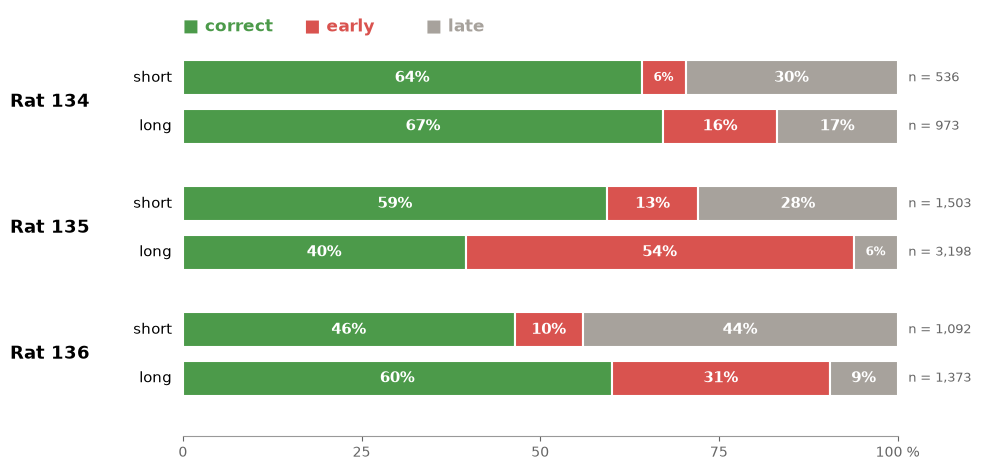

In [26]:
# ── Slide D (smart version): outcomes per rat — horizontal 100% bars, short and long ──
# needs cell A v3 (KF = kept trials of the new filter: 60 sessions, 8,675 trials). Counts are computed from KF, nothing typed in.
import numpy as np, matplotlib.pyplot as plt

OUT = ("correct", "early", "late")
K = KF[KF["type"].isin(["short", "long"])]
counts = {rat: {typ: tuple(int(((K["rat"].astype(str) == rat) & (K["type"] == typ) & (K["outcome"] == o)).sum()) for o in OUT)
                for typ in ("short", "long")} for rat in ("134", "135", "136")}
print("counts (correct, early, late):", counts)   # check: 134 short (344, 33, 159) long (654, 155, 164) | 135 short (892, 192, 419) long (1265, 1737, 196) | 136 short (507, 104, 481) long (824, 419, 130)
COL = {"correct": "#4c9a4a", "early": "#d9534f", "late": "#a7a29c"}

fig, ax = plt.subplots(figsize=(10, 4.8))
y, ylab, yrat = 0, [], []
for rat in counts:
    ys = []
    for typ in ("short", "long"):
        v = np.array(counts[rat][typ], float); n = v.sum(); p = 100 * v / n
        left = 0
        for k, o in enumerate(OUT):
            ax.barh(y, p[k], left=left, height=0.72, color=COL[o], edgecolor="white", lw=1.5)
            ax.text(left + p[k] / 2, y, f"{p[k]:.0f}%", ha="center", va="center", color="white",
                    fontsize=11 if p[k] >= 8 else 8.5, fontweight="bold")     # all numbers inside, smaller in thin parts
            left += p[k]
        ax.text(101.5, y, f"n = {int(n):,}", ha="left", va="center", fontsize=9.5, color="0.4")
        ylab.append((y, typ)); ys.append(y); y += 1
    yrat.append((np.mean(ys), rat)); y += 0.6                             # gap between rats
for yy, typ in ylab:
    ax.text(-1.5, yy, typ, ha="right", va="center", fontsize=11)
for yy, rat in yrat:
    ax.text(-13, yy, f"Rat {rat}", ha="right", va="center", fontsize=13, fontweight="bold")
x0 = 0                                                                    # legend as coloured words on top
for o in OUT:
    ax.text(x0, -1.05, "■ " + o, color=COL[o], fontsize=12, fontweight="bold", ha="left", va="center")
    x0 += 17
ax.set_xlim(0, 100); ax.set_ylim(y - 0.4, -1.4)
ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xticklabels(["0", "25", "50", "75", "100 %"], fontsize=10)
ax.set_yticks([]); ax.tick_params(axis="x", colors="0.4")
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color("0.6")
fig.tight_layout()
fig.savefig("outcomes_per_rat.png", dpi=600, transparent=True, bbox_inches="tight")
plt.show()

In [33]:
# ── Slide E (B1, post-error slowing): ONE mixed model per rat + ONE pooled model ──
# needs cell A v3 (KF with prev_outcome, rt_s, type, outcome, session). Uses statsmodels.
# Data: correct trials with RT (short + long), previous trial = correct / late / early.
# Model: rt_ms ~ after_late + after_early + long   (+ rat, pooled model only),  random intercept per session.
# NOTE: the formula uses the plain column 'rat' (not C(rat)), because a variable called C in the notebook breaks patsy's C().
#   after_late / after_early = extra RT (ms) vs after a correct trial, same type adjusted by the 'long' term; long = long minus short (ms).
import os, warnings, numpy as np, pandas as pd
import statsmodels.formula.api as smf
A = KF.copy(); A["rat"] = A["session"].str.extract(r"r0000(\d{3})")[0]
D = A[(A["outcome"] == "correct") & (A["rt_s"] > 0) & A["prev_outcome"].isin(["correct", "late", "early"]) & A["type"].isin(["short", "long"])].copy()
D["rt_ms"] = 1000 * D["rt_s"]
D["after_late"] = (D["prev_outcome"] == "late").astype(int); D["after_early"] = (D["prev_outcome"] == "early").astype(int)
D["long"] = (D["type"] == "long").astype(int)

rows = []
for grp in ("all", "134", "135", "136"):
    d = D if grp == "all" else D[D["rat"] == grp]
    f = "rt_ms ~ after_late + after_early + long" + (" + rat" if grp == "all" else "")
    try:
        for meth in ("lbfgs", "powell", "nm"):                                   # try other optimisers if the first does not converge
            with warnings.catch_warnings():
                warnings.simplefilter("ignore"); m = smf.mixedlm(f, d, groups="session").fit(reml=True, method=meth)
            if m.converged: break
        print(f"[{grp}] optimiser: {meth}, converged: {m.converged}")
        ci = m.conf_int()
        for term, lab in (("after_late", "after late vs after correct"), ("after_early", "after early vs after correct"), ("long", "long vs short trials")):
            rows.append(dict(group=grp, term=lab, trials=len(d), sessions=d["session"].nunique(), effect_ms=m.params[term],
                             ci_low=ci.loc[term, 0], ci_high=ci.loc[term, 1], p=m.pvalues[term]))
    except Exception as e:
        print(f"[{grp}] model failed: {e!r}")
R = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print(R.assign(effect_ms=R.effect_ms.round(1), ci_low=R.ci_low.round(1), ci_high=R.ci_high.round(1), p=R.p.round(4)).to_string(index=False))
R.to_csv(os.path.join(TABLES, "behaviour_B1_mixed_final.csv"), index=False)
print("\nread: effect_ms = change in RT of correct trials in ms (positive = slower). after late / after early are compared with after correct. "
      "'all' = all three rats in one model with rat as a fixed factor. Raw p, no correction.")

[all] optimiser: lbfgs, converged: True
[134] optimiser: lbfgs, converged: True
[135] optimiser: lbfgs, converged: True
[136] optimiser: lbfgs, converged: True
group                         term  trials  sessions  effect_ms  ci_low  ci_high      p
  all  after late vs after correct    4182        60       35.3    26.8     43.8 0.0000
  all after early vs after correct    4182        60        8.7     1.7     15.6 0.0149
  all         long vs short trials    4182        60      -39.2   -45.6    -32.9 0.0000
  134  after late vs after correct     940        11       47.4    32.0     62.7 0.0000
  134 after early vs after correct     940        11       29.0    12.5     45.4 0.0006
  134         long vs short trials     940        11      -15.2   -26.8     -3.6 0.0102
  135  after late vs after correct    2052        29       35.5    21.2     49.7 0.0000
  135 after early vs after correct    2052        29        5.4    -4.0     14.8 0.2603
  135         long vs short trials    2052      

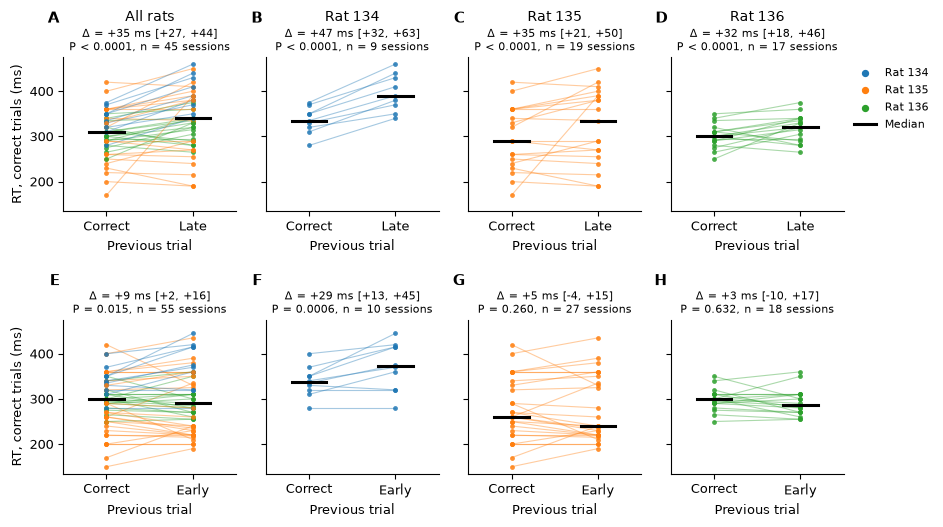

saved in C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tables\out_hq


In [36]:
# ── Paper figure: B1 post-error slowing (paired session plots), per rat and pooled ──
# needs cell A v3 (KF) and the final mixed-model cell (it saves behaviour_B1_mixed_final.csv, read below for the titles).
# One dot = one session (median RT of its correct trials), line = same session, black bar = median over sessions. Only sessions with >= MIN_N trials in both groups.
# Short and long trials are pooled (as in the model). The numbers in the titles are from the MIXED MODEL (all trials); the dots are descriptive.
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
MIN_N = 5
RAT_COL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
A = KF.copy(); A["rat"] = A["session"].str.extract(r"r0000(\d{3})")[0]
D = A[(A["outcome"] == "correct") & (A["rt_s"] > 0) & A["prev_outcome"].isin(["correct", "late", "early"]) & A["type"].isin(["short", "long"])].copy()
D["rt_ms"] = 1000 * D["rt_s"]
M = pd.read_csv(os.path.join(TABLES, "behaviour_B1_mixed_final.csv")); M["group"] = M["group"].astype(str)

def per_session(prev):
    rows = []
    for s, g in D.groupby("session"):
        ga, gb = g[g["prev_outcome"] == "correct"], g[g["prev_outcome"] == prev]
        if len(ga) >= MIN_N and len(gb) >= MIN_N:
            rows.append(dict(session=s, rat=g["rat"].iat[0], A=ga["rt_ms"].median(), B=gb["rt_ms"].median()))
    return pd.DataFrame(rows)

ROWS = [("late", "Correct", "Late", "after late vs after correct"), ("early", "Correct", "Early", "after early vs after correct")]
COLS = [("all", "All rats"), ("134", "Rat 134"), ("135", "Rat 135"), ("136", "Rat 136")]
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(len(ROWS), len(COLS), figsize=(9.5, 5.4), sharey=True)
for i, (prev, la, lb, term) in enumerate(ROWS):
    S = per_session(prev)
    for j, (g, glab) in enumerate(COLS):
        ax = axes[i, j]; d = S if g == "all" else S[S["rat"] == g]
        for _, r in d.iterrows():
            ax.plot([0, 1], [r.A, r.B], color=RAT_COL[r.rat], alpha=0.4, lw=0.8)
            ax.scatter([0, 1], [r.A, r.B], color=RAT_COL[r.rat], s=12, alpha=0.85, zorder=3, linewidths=0)
        if len(d):
            for x, col in ((0, "A"), (1, "B")): ax.plot([x - 0.2, x + 0.2], [d[col].median()] * 2, color="k", lw=2.2, zorder=4)
        m = M[(M["group"] == g) & (M["term"] == term)]
        if len(m):
            m = m.iloc[0]; ps = "P < 0.0001" if m.p < 1e-4 else f"P = {m.p:.4f}" if m.p < 0.001 else f"P = {m.p:.3f}"
            stat = f"\u0394 = {m.effect_ms:+.0f} ms [{m.ci_low:+.0f}, {m.ci_high:+.0f}]\n{ps}, n = {len(d)} sessions"
        else: stat = ""
        ax.set_title((glab if i == 0 else "") , fontsize=10, pad=26 if i == 0 else 6)
        ax.text(0.5, 1.02, stat, transform=ax.transAxes, ha="center", va="bottom", fontsize=8)
        ax.set_xticks([0, 1]); ax.set_xticklabels([la, lb]); ax.set_xlim(-0.5, 1.5)
        ax.set_xlabel("Previous trial")
        if j == 0: ax.set_ylabel("RT, correct trials (ms)")
        ax.text(-0.02, 1.2 if i == 0 else 1.2, "ABCDEFGH"[i * len(COLS) + j], transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="right")
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for rat, c in RAT_COL.items(): axes[0, -1].scatter([], [], color=c, s=18, label=f"Rat {rat}")
axes[0, -1].plot([], [], color="k", lw=2.2, label="Median")
axes[0, -1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
OUT = os.path.join(TABLES, "out_hq"); os.makedirs(OUT, exist_ok=True)
fig.savefig(os.path.join(OUT, "B1_post_error_slowing.png"), dpi=600, transparent=True, bbox_inches="tight")
fig.savefig(os.path.join(OUT, "B1_post_error_slowing_white.png"), dpi=600, facecolor="white", bbox_inches="tight")
fig.savefig(os.path.join(OUT, "B1_post_error_slowing.pdf"), bbox_inches="tight")
plt.show()
print("saved in", OUT)

In [38]:
# ── Pilot sessions: trial counts per condition with the NEW filter (KF from cell A v3) ──
# Same conditions as in the pilot: long_prob 0.5 blocks; early long only with hold > 0.3 s.
import pandas as pd
PILOTS = ["20260529_r0000136_wt_1318", "20260529_r0000135_wt_1411"]        # main pilot, second pilot
rows = []
for s in PILOTS:
    k = KF[KF["session"] == s]
    if k.empty: print(f"{s}: not in the kept trials (KF)"); continue
    for lab, d in (("all blocks", k), ("0.5 blocks only", k[k["long_prob"].round(2) == 0.5])):
        n = lambda t, o, extra=True: int(((d["type"] == t) & (d["outcome"] == o) & extra).sum())
        rows.append(dict(session=s, blocks=lab, trials=len(d), correct_long=n("long", "correct"), early_long=n("long", "early"),
                         early_long_hold_gt_0_3=n("long", "early", d["hold_s"] > 0.3), correct_short=n("short", "correct"),
                         early_short=n("short", "early"), late_long=n("long", "late"), late_short=n("short", "late"),
                         press_from_MA=int((~d["press_from_ttl"].astype(bool)).sum())))
P = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print(P.to_string(index=False))
P.to_csv(os.path.join(TABLES, "pilot_counts_new_filter.csv"), index=False)

                  session          blocks  trials  correct_long  early_long  early_long_hold_gt_0_3  correct_short  early_short  late_long  late_short  press_from_MA
20260529_r0000136_wt_1318      all blocks     141            49          17                      15             48            2          3          22              0
20260529_r0000136_wt_1318 0.5 blocks only     141            49          17                      15             48            2          3          22              0
20260529_r0000135_wt_1411      all blocks     255            51          77                      66             94            6          5          22              9
20260529_r0000135_wt_1411 0.5 blocks only     255            51          77                      66             94            6          5          22              9


In [43]:
# ── 1.3b Restrict the loaded session files (BP) to the NEW trial filter (KF from cell A v3) — run after 1.3, before 1.4 ──
# What it does: keeps, in every session file, only the trials that are also in KF (new filter: TTL or MA press, no timing_mismatch, no WT sessions...).
# What it can NOT do: add trials that were not in the old set (the trials that now use the MA press have no band power in the files).
# Only the per-trial window values (logpow) are filtered, so use it ONLY for cells 1.4 (M1/M2) and the M1 slide cell.
# The time-course arrays (curves/counts) cannot be filtered after the fact -> set to None so cells 1.5/1.7 fail loudly. Rerun 1.3 to get the old files back.
# Uses only: BP (1.3), KF (cell A v3). No lfp_main function is called.
import numpy as np, pandas as pd
BPN, rep = {}, []
for s, r in BP.items():
    T = r["trials"]; k = KF[KF["session"] == s]
    if k.empty:
        rep.append(dict(session=s, in_files=len(T), kept=0, new_only=0, note="session not in KF")); continue
    kk = k.set_index("trial")["press_neural_s"]
    m = T["trial"].isin(kk.index).values
    same = np.abs(T.loc[m, "press_s"].values - kk.reindex(T.loc[m, "trial"]).values) < 1e-3          # same trial = same press time
    if not same.all():
        idx = np.where(m)[0]; m[idx[~same]] = False
    r2 = dict(r); r2["trials"] = T[m].reset_index(drop=True)
    r2["logpow"] = {b: {w: (a[m] if hasattr(a, "shape") and a.ndim >= 1 and a.shape[0] == len(T) else a) for w, a in d.items()} for b, d in r["logpow"].items()}
    r2["curves"] = None; r2["counts"] = None
    BPN[s] = r2
    rep.append(dict(session=s, in_files=len(T), kept=int(m.sum()), removed=int((~m).sum()), new_only=len(k) - int(m.sum()), note=""))
REP = pd.DataFrame(rep)
print(f"{len(BPN)} sessions | trials in the files {REP.in_files.sum()} -> kept {REP.kept.sum()} (removed {REP.removed.sum()}) | "
      f"KF trials WITHOUT power in the files (MA-press trials etc.): {REP.new_only.sum()}")
print(REP[(REP.removed > 0) | (REP.new_only > 0) | (REP.note != "")].sort_values("new_only", ascending=False).head(15).to_string(index=False))
BP = BPN

59 sessions | trials in the files 8056 -> kept 7905 (removed 151) | KF trials WITHOUT power in the files (MA-press trials etc.): 607
                  session  in_files  kept  removed  new_only note
20260615_r0000134_wt_1825         9     9        0       210     
20260616_r0000134_wt_1653         2     2        0       112     
20260512_r0000136_wt_1054        12    12        0       105     
20260609_r0000134_wt_1622        71    60       11        35     
20260525_r0000135_wt_1426       164   163        1        19     
20260527_r0000135_wt_1217       194   191        3        19     
20260622_r0000135_wt_1426       113   112        1        14     
20260620_r0000134_wt_1554       195   194        1        11     
20260610_r0000134_wt_1923       155   153        2        10     
20260510_r0000135_wt_1625        69    61        8        10     
20260621_r0000135_wt_1618       155   153        2        10     
20260515_r0000135_wt_1957        69    60        9         9     
20260529_

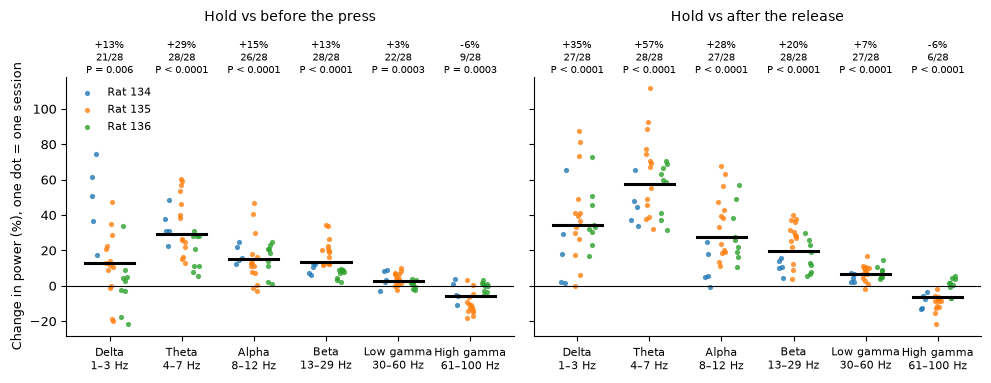

saved on C:\Users\ar687\Desktop
     measure         band  sessions  sessions_up  mean_pct      p
 M1 hold-pre    delta 1-3        28           21   12.8084 0.0059
 M1 hold-pre    theta 4-7        28           28   29.1438 0.0001
 M1 hold-pre   alpha 8-12        28           26   15.1026 0.0001
 M1 hold-pre   beta 13-29        28           28   13.4886 0.0001
 M1 hold-pre   lowG 30-60        28           22    3.0113 0.0003
 M1 hold-pre highG 61-100        28            9   -5.9651 0.0003
M1 hold-post    delta 1-3        28           27   34.5384 0.0001
M1 hold-post    theta 4-7        28           28   57.3435 0.0001
M1 hold-post   alpha 8-12        28           27   27.8578 0.0001
M1 hold-post   beta 13-29        28           28   19.8160 0.0001
M1 hold-post   lowG 30-60        28           27    6.9909 0.0001
M1 hold-post highG 61-100        28            6   -6.3628 0.0001


In [45]:
# ── Slide: which bands change while the rat holds the lever? (M1, correct long) — one dot = one session ──
# needs cell 1.4 (table S, BANDS via lfm.MAIN_BANDS) and 1.0/1.3 (lfm, rat_of). Calls only lfm.sign_flip_p and lfm.MAIN_BANDS (both as in 1.4).
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
BANDS_M1 = list(lfm.MAIN_BANDS)
LAB = {"delta 1-3": "Delta\n1–3 Hz", "theta 4-7": "Theta\n4–7 Hz", "alpha 8-12": "Alpha\n8–12 Hz",
       "beta 13-29": "Beta\n13–29 Hz", "lowG 30-60": "Low gamma\n30–60 Hz", "highG 61-100": "High gamma\n61–100 Hz"}
RCOL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
PAN = [("M1 hold-pre", "Hold vs before the press"), ("M1 hold-post", "Hold vs after the release")]
plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
rng = np.random.default_rng(0); out = []
for ax, (col, title) in zip(axes, PAN):
    for i, b in enumerate(BANDS_M1):
        d = S[(S.band == b)].dropna(subset=[col])
        for k, rat in enumerate(sorted(RCOL)):
            dr = d[d.rat == rat]
            ax.scatter(i + (k - 1) * 0.2 + rng.uniform(-0.05, 0.05, len(dr)), 100 * (10 ** dr[col] - 1), s=14, color=RCOL[rat], alpha=0.8, linewidths=0,
                       label=f"Rat {rat}" if (i == 0 and col == "M1 hold-pre") else None)
        m, p, n = lfm.sign_flip_p(d[col].values)
        ax.plot([i - 0.34, i + 0.34], [100 * (10 ** m - 1)] * 2, color="k", lw=2.2, zorder=4)
        ps = "P < 0.0001" if p < 1e-4 else f"P = {p:.3f}" if p >= 0.001 else f"P = {p:.4f}"
        ax.text(i, 1.0, f"{100 * (10 ** m - 1):+.0f}%\n{int((d[col] > 0).sum())}/{n}\n{ps}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5)
        out.append(dict(measure=col, band=b, sessions=n, sessions_up=int((d[col] > 0).sum()), mean_pct=100 * (10 ** m - 1), p=p))
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(BANDS_M1))); ax.set_xticklabels([LAB.get(b, b) for b in BANDS_M1], fontsize=8)
    ax.set_title(title, fontsize=10, pad=40); ax.set_xlim(-0.6, len(BANDS_M1) - 0.4)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylabel("Change in power (%), one dot = one session")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
pd.DataFrame(out).to_csv(os.path.join(TABLES, "M1_bands_slide_values.csv"), index=False)
desk = os.path.join(os.path.expanduser("~"), "Desktop")
if not os.path.isdir(desk): desk = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop")
os.makedirs(desk, exist_ok=True)
for ext, kw in ((".pdf", {}), ("_white.png", dict(dpi=600, facecolor="white")), ("_transparent.png", dict(dpi=600, transparent=True))):
    fig.savefig(os.path.join(desk, "M1_bands_hold" + ext), bbox_inches="tight", **kw)
plt.show(); print("saved on", desk)
print(pd.DataFrame(out).round(4).to_string(index=False))

NameError: name 'B5_DIR' is not defined